# Non-Autonomous Terms and VF-b Test
This notebook uses the best candidates from sindy_fhn.ipynb for fitting data. Models use the following options:
* optimizer — Either SSR or STLSQ with column normalization
* feature_library — degree 3 polynomials in u,v and the given non-autonomous function

In [1]:
import math
import numpy as np
import functools
from scipy.integrate import odeint
from scipy import fft
from itertools import combinations_with_replacement
import matplotlib.pyplot as plt
import pandas as pd
import importlib
import sindy
importlib.reload(sindy)

import pysindy as ps
from fhn_models import fhn, fhn_c, fhn_vf_4, fhn_vf_7, compare_exact_and_sindy_coeffs
import gen_library_fit
from gen_library_fit import GenLibraryFit

# Automatically reload modules without having to restart the kernel
# import importlib
# importlib.reload(gen_library_fit)
%load_ext autoreload
%autoreload 2

In [2]:
# The old, non-truncated autonomous term (can be a problem for large exponents).
# Params:
#   t (1d array): Time input vector
#   mag (float): The magnitude of the stimulus
def smooth_non_aut_old(t, mag=0.12):
    return 2. * mag / (1. + np.exp((25*np.sin(0.02*t))**2))

# A differentiable non-autonomous term truncated from the Taylor series of the above term.
# Params:
#   t (1d array): Time input vector
#   mag (float): The magnitude of the stimulus
def smooth_non_aut(t, mag=0.12):
    return 2. * mag / (2. + (200.*np.sin(0.02*t))**4)

# Logical step function non-autonomous term.
# Params:
#   t (1d array): Time input vector
#   period (float): The period of the stimulus
#   dur (float): The time duration of the stimulus
#   mag (float): The magnitude of the stimulus
def logical_non_aut(t, period=155.0, dur=5.0, mag=0.12):
    stimulus = mag * (np.mod(t, period) <= dur)
    return stimulus

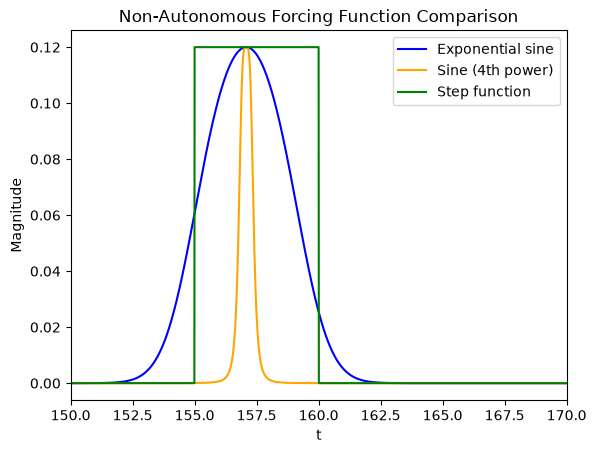

In [3]:
# Compare the forcing functions. Note that we can't actually use the exponential since it will encounter overflow for the peak tightness
# that we need; instead, take part of the Taylor series, then throw out the terms we don't need while still maintaing a representative shape.
t = np.arange(0,500,0.01)
plt.plot(t, smooth_non_aut_old(t), color = 'blue', label='Exponential sine')
plt.plot(t, smooth_non_aut(t), color='orange', label='Sine (4th power)')
plt.plot(t, logical_non_aut(t), color='green', label='Step function')
plt.xlim(150,170)
plt.xlabel('t')
plt.ylabel('Magnitude')
plt.title('Non-Autonomous Forcing Function Comparison')
plt.legend()

# 1.) VF-FHN
Now, let's try fitting the 4-parameter and 7-parameter VF-FHN models with some non-autonomous terms included.

In [4]:
# Time step and initial values; seems like 0-600 is minimum timeframe needed to identify dynamics
dt = 0.01
t_vf_7 = np.arange(0,4000,dt)
x_0_vf_7 = np.array([0,0])

In [5]:
fhn_vf_4_part = functools.partial(fhn_vf_4, alpha = 0.2, beta = 1.1, eps = 0.005, mu = 1.0)

t_vf_4 = np.arange(0,4000,dt)
x_0_vf_4 = np.array([0,0.11])

# (VF4 period sweep; uncomment to determine working periods for 4-parameter version of VF-FHN)

# Compare how different stimulus periods affect the FHN VF-a waveforms.
# Alternans case around period-185 stimulus and non-alternans case around period-225 stimulus.
# for i in range(0,20): # range(0,4)
#     cur_period = 220 + i # 170. + 5*i
#     non_aut_func = functools.partial(logical_non_aut, period=cur_period, dur=5.0, mag=0.12)
#     cur_states_fhn = odeint(fhn_vf_4_part, x_0_vf_4, t_vf_4, args=(non_aut_func,), hmax=0.1)

#     cur_df_states_fhn = pd.DataFrame(cur_states_fhn, columns=['u','v'])
#     cur_u_fhn = cur_df_states_fhn['u'].tolist()

#     plt.plot(t_vf_4, cur_u_fhn)
#     plt.title(f"VF-FHN with Stimulus Period {cur_period:.0f} Time Units")
#     plt.gcf().set_size_inches(10, 2.5) # Change plot size so we quickly see differences in waveforms
#     plt.show()

In [6]:
fhn_vf_7_part = functools.partial(fhn_vf_7, alpha = 0.2, beta = 1.1, gamma = 0.31, delta = 0.0, eps = 0.005, theta = -0.05, mu = 1.0)

# (VF7 period sweep; uncomment to determine working periods)

# # Compare how different stimulus periods affect the FHN VF-b waveforms.
# for i in range(0,20):
#     cur_period = 350. + i
#     non_aut_func = functools.partial(logical_non_aut, period=cur_period, dur=5.0, mag=0.12)
#     cur_states_fhn = odeint(fhn_vf_7_part, x_0_vf_7, t_vf_7, args=(non_aut_func,), hmax=0.1)

#     cur_df_states_fhn = pd.DataFrame(cur_states_fhn, columns=['u','v'])
#     cur_u_fhn = cur_df_states_fhn['u'].tolist()   

#     plt.plot(t_vf_7, cur_u_fhn)
#     plt.title(f"VF-FHN with Stimulus Period {cur_period:.0f} Time Units")
#     plt.gcf().set_size_inches(10, 2.5) # Change plot size so we quickly see differences in waveforms
#     plt.show()

Based on the plots above, T = 361 time units gives the best result, with the VF-b variant of FHN seeming very sensitive to the correct stimulus period. Any variation from this value results in alternans and/or the stimulus occurring in the middle of an AP. Here is a compilation of the optimal period for various sets of parameters:

* alpha = 0.2, beta = 1.1, gamma = 0.31, delta = 0.0, eps = 0.005, theta = -0.05, mu = 1.0 â€” T = 361
* alpha = 0.2, beta = 1.03, gamma = 0.31, delta = 0.0, eps = 0.003, theta = -0.05, mu = 1.1 â€” T = 765

In [7]:
# Generate the data using our non-autonomous term. Note that the period is very sensitive per the above experiment, so we must be careful in our selection of its value.
non_aut_func_vf_7 = functools.partial(logical_non_aut, period=361, dur=5.0, mag=0.12)

states_vf_7 = odeint(fhn_vf_7_part, x_0_vf_7, t_vf_7, args=(non_aut_func_vf_7,), hmax=0.1) # Test code --> lambda t: 0         Actual code --> non_aut_func_vf_7

In [8]:
# Run SINDy on VF-FHN w/ time-varying terms.
# Note: There are some extraneous terms hiding around precision = 6-10 that show up
# TODO How to remove these terms?
opt_vf_7 = ps.STLSQ(threshold=0.1, normalize_columns=True)
model_vf_7 = ps.SINDy(feature_library=ps.PolynomialLibrary(degree=3), optimizer=opt_vf_7)
model_vf_7.fit(states_vf_7, t=t_vf_7, feature_names=['u', 'v'])
model_vf_7.print(precision=5)

(u)' =  0.00535 1 +  0.61530 u + -0.01588 v + -0.51201 u^2 + -4.69326 u v + -0.81204 v^2 + -0.10885 u^3 +  3.80815 u^2 v +  4.49714 u v^2 +  3.31970 v^3
(v)' = -0.00145 1 +  0.00705 u + -0.00500 u^2


Actual equations for comparison (without auto-oscillatory term $\delta$):

\begin{align}
    \dot{u} &= - 0.2 u + 1.2 u^2 - u v - 1 u^3 \\
    \dot{v} &= -0.001455 + 0.00705u - 0.005u^2 \\
\end{align}

And with $\delta=1.0$:

\begin{align}
    \dot{u} &= - 0.2 u + 1.2 u^2 - u v - 1 u^3 \\
    \dot{v} &= -0.001455 + 0.00705u - 0.005u^2 - 0.005v \\
\end{align}

Based on the result above, it seems we can identify $\dot{v}$, but not $\dot{u}$, when a stimulus is applied and not accounted for by SINDy.  This is to be expected since the stimulus term is only added to the $\dot{u}$ equation.

Number of SINDy terms for u', v': (10, 3)
Number of exact terms for u', v': (4, 4)

SINDy coefficients:
(u)' =  0.00535 1 +  0.61530 u + -0.01588 v + -0.51201 u^2 + -4.69326 u v + -0.81204 v^2 + -0.10885 u^3 +  3.80815 u^2 v +  4.49714 u v^2 +  3.31970 v^3
(v)' = -0.00145 1 +  0.00705 u + -0.00500 u^2

Exact coefficients:
u' = -0.22 u + 0.42 u^2 + -1.0 uv + -0.2 u^3 + 0.0 v^3
v' = 0.0515 1 + 0.3193 u + -0.00309 v + -1.03 u^2 + 0.0 v^3


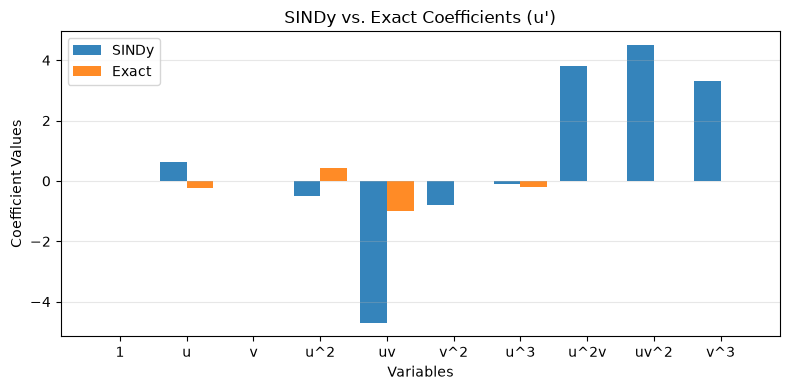

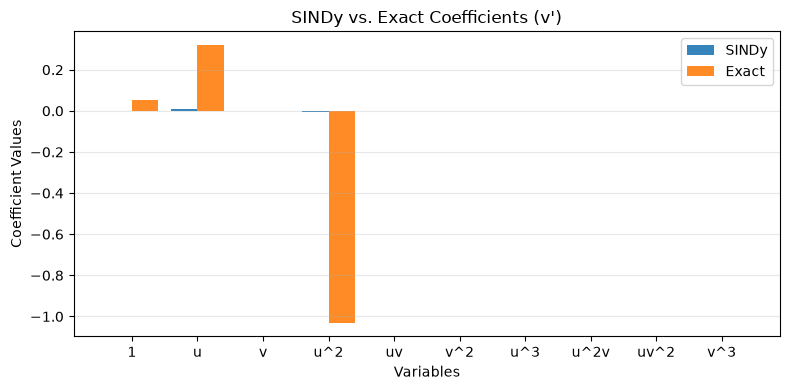

In [9]:
# Order of coefficients: 1, u, v, u^2, uv, v^2, u^3, u^2v, uv^2, v^3
variables = ['1', 'u', 'v', 'u^2', 'uv', 'v^2', 'u^3', 'u^2v', 'uv^2', 'v^3']
coef_sindy = model_vf_7.coefficients()
coef_exact = np.array([[0, -0.22, 0, 0.42, -1.0, 0, -0.2, 0, 0, 0],
                       [0.0515, 0.3193, -0.00309, -1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]])
x = np.arange(len(coef_sindy[0]))

# Compare number of terms in the SINDy model to the exact coefficients.
precision = 5
tol = 10**(-precision)
print(f'Number of SINDy terms for u\', v\': ({np.sum(np.abs(coef_sindy[0]) > tol)}, {np.sum(np.abs(coef_sindy[1]) > tol)})')
print(f'Number of exact terms for u\', v\': ({np.sum(np.abs(coef_exact[0]) > tol)}, {np.sum(np.abs(coef_exact[1]) > tol)})')

# Compare the SINDy and exact coefficients.
print('\nSINDy coefficients:')
model_vf_7.print(precision=precision)
print('\nExact coefficients:')
for i in range(len(coef_exact)):
    eqn = ''
    eqn += ('u\' = ' if i == 0 else 'v\' = ')
    for j in range(len(coef_exact[0])):
        if (np.abs(coef_exact[i][j]) > tol) and (j < len(coef_exact[0]) - 1):  # Print only nonzero coefficients.
            eqn += f'{coef_exact[i][j]} {variables[j]} + '
        elif (j == len(coef_exact[0]) - 1):  # Handle the last term separately.
            eqn += f'{coef_exact[i][j]} {variables[j]}'
    print(eqn)


# Use bar chart to compare the SINDy and exact coefficient values (for u').
width = 0.4
plt.figure(figsize=(8, 4))
plt.bar(x - width/2, coef_sindy[0], width=width, alpha=0.9, label='SINDy')
plt.bar(x + width/2, coef_exact[0], width=width, alpha=0.9, label='Exact')

plt.title('SINDy vs. Exact Coefficients (u\')')
plt.ylabel('Coefficient Values')
plt.xlabel('Variables')
plt.xticks(x, variables)
plt.legend()
plt.tight_layout()
plt.grid(axis='y', alpha=0.3)


# Use bar chart to compare the SINDy and exact coefficient values (for v').
width = 0.4
plt.figure(figsize=(8, 4))
plt.bar(x - width/2, coef_sindy[1], width=width, alpha=0.9, label='SINDy')
plt.bar(x + width/2, coef_exact[1], width=width, alpha=0.9, label='Exact')

plt.title('SINDy vs. Exact Coefficients (v\')')
plt.ylabel('Coefficient Values')
plt.xlabel('Variables')
plt.xticks(x, variables)
plt.legend()
plt.tight_layout()
plt.grid(axis='y', alpha=0.3)

Text(0.5, 1.0, 'Values of u vs. v')

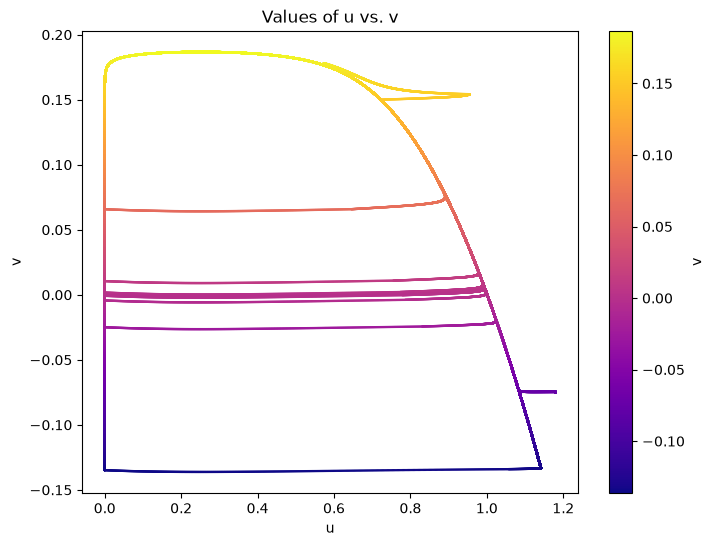

In [10]:
# Plot results - u vs. v
df_states_vf_7 = pd.DataFrame(states_vf_7, columns=['u','v'])

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df_states_vf_7['u'], 
    df_states_vf_7['v'], 
    c=df_states_vf_7['v'],  # Color shade controlled by v column
    s=0.5,  # Marker size
    cmap='plasma'
)

# Add colorbar for the v values
plt.colorbar(scatter, label='v')
plt.xlabel('u')
plt.ylabel('v')
plt.title('Values of u vs. v')

[0.0, 0.0011988115034597003, 0.002395261989364361, 0.003589390000766398, 0.004781233289104066, 0.0059708220035531775, 0.00715820131495333, 0.008343415251760687, 0.009526505707204936, 0.01070750320662103]
[0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09]


Text(0.5, 1.0, 'Voltage vs. Time (7-Parameter VF-FHN)')

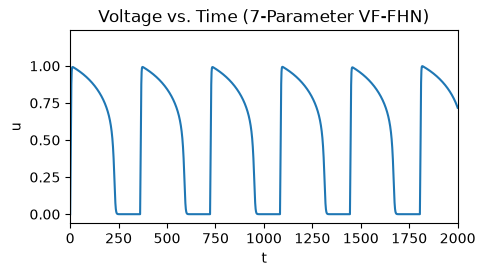

In [11]:
# Plot results - u vs. t
u_vf_7 = df_states_vf_7['u'].tolist()
print(u_vf_7[0:10])
print(t_vf_7[0:10])

plt.figure(figsize=(5, 2.5))
plt.plot(t_vf_7,u_vf_7)
plt.xlim(0, 2000)
plt.xlabel('t')
plt.ylabel('u')
plt.title('Voltage vs. Time (7-Parameter VF-FHN)')

# 2.) FHN
Now, fit standard FHN model with non-autonomous terms.

In [12]:
# Standard FHN parameters
t_fhn = np.arange(0,2000,dt)
x_0_fhn = np.array([-0.1,0])
states_fhn = odeint(fhn, x_0_fhn, t_fhn, args=(logical_non_aut,), hmax=0.1) # Test code --> lambda t: 0         Actual code --> logical_non_aut

In [13]:
# Run SINDy on FHN w/ time-varying terms.
# Note: There are some extraneous terms hiding around precision = 6-10 that show up, but they shouldn't affect the solution much.
# TODO How to remove these terms?
# TODO Why does using standard function library (e.g., removing feature_library argument) result in fewer extraneous terms here?
opt_fhn = ps.STLSQ(threshold=0.1, normalize_columns=True)
model_fhn = ps.SINDy(feature_library=ps.PolynomialLibrary(degree=3), optimizer=opt_fhn)
model_fhn.fit(states_fhn, t=t_fhn, feature_names=['u', 'v'])
model_fhn.print(precision=5)

(u)' =  0.03278 1 +  0.54452 u +  0.90827 v + -0.10527 u^2 + -7.72394 u v + -21.97520 v^2 + -0.48262 u^3 +  5.81199 u^2 v +  21.06886 u v^2 +  59.25986 v^3
(v)' =  0.00500 u + -0.01000 v


Actual equations for comparison (without auto-oscillatory term $\delta$):

\begin{align}
    \dot{u} &= - 0.1 u + 1.1 u^2 - 1 uv - 1 u^3 \\
    \dot{v} &= 0.005 u - 0.01v \\
\end{align}

And with $\delta=1.0$:

\begin{align}
    \dot{u} &= - 0.1 u + 1.1 u^2 - 1uv - 1 u^3 \\
    \dot{v} &= - 0.01 + 0.005 u - 0.01v \\
\end{align}

Even with the simpler FHN model, we get the same result as with VF-FHNâ€”the stimulus term must be taken into account in order for the $\dot{u}$ equation to be correctly identified.

Text(0.5, 1.0, 'Values of u vs. v')

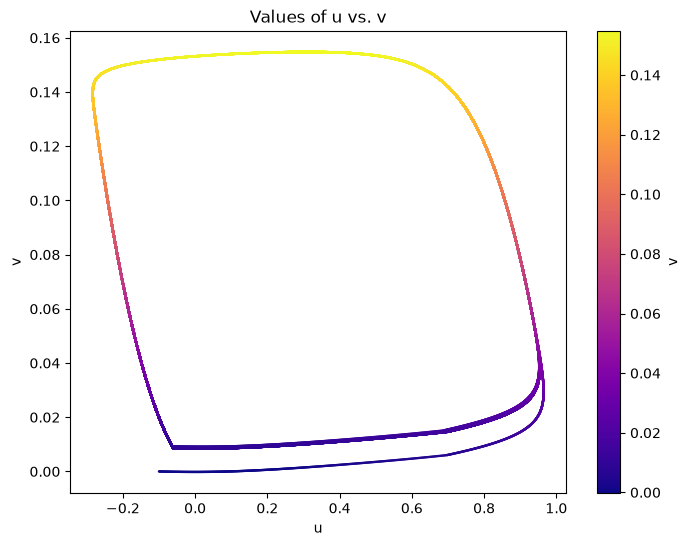

In [14]:
# Plot results - u vs. v
df_states_fhn = pd.DataFrame(states_fhn, columns=['u','v'])

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df_states_fhn['u'], 
    df_states_fhn['v'], 
    c=df_states_fhn['v'],  # Color shade controlled by v column
    s=0.5,  # Marker size
    cmap='plasma'
)

# Add colorbar for the v values
plt.colorbar(scatter, label='v')
plt.xlabel('u')
plt.ylabel('v')
plt.title('Values of u vs. v')

### Cardiac FHN vs. normal FHNâ€”Hyperpolarization Comparison

In [15]:
# Cardiac-corrected FHN ICs and time range
t_fhn_c = np.arange(0,4000,dt)
x_0_fhn_c = np.array([0,0.11])

# Generate the data using our non-autonomous term. Note that the period is very sensitive per the above experiment, so we must be careful in our selection of its value.
non_aut_func_fhn_c = functools.partial(logical_non_aut, period=361, dur=5.0, mag=0.12)
fhn_c_part = functools.partial(fhn_c, alpha = 0.1, beta = 0.5, gamma = 1, delta = 0.0, eps = 0.01)

states_fhn_c = odeint(fhn_c_part, x_0_fhn_c, t_fhn_c, args=(non_aut_func_fhn_c,), hmax=0.1) # Test code --> lambda t: 0         Actual code --> non_aut_func_vf_7
df_states_fhn_c = pd.DataFrame(states_fhn_c, columns=['u','v'])
u_fhn_c = df_states_fhn_c['u'].tolist()

[-0.1, -0.09858244215279185, -0.09716974212195227, -0.09576179817510627, -0.09435858377101972, -0.09296001232886043, -0.0915660029586269, -0.09017648356050686, -0.08879139688647436, -0.08741067750767668]
[0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09]


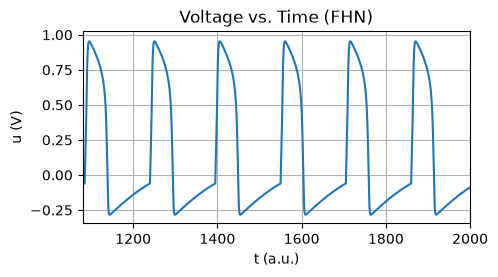

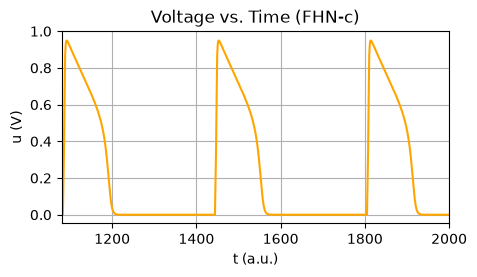

In [16]:
# Plot FHN u vs. t
u_fhn = df_states_fhn['u'].tolist()
print(u_fhn[0:10])
print(t_fhn[0:10])

plt.figure(figsize=(5, 2.5))    # , dpi=600
plt.plot(t_fhn,u_fhn)
plt.xlim(1080, 2000)
plt.xlabel('t (a.u.)')
plt.ylabel('u (V)')
plt.title('Voltage vs. Time (FHN)')
plt.grid()

# Plot FHN-c - u vs. t
plt.figure(figsize=(5, 2.5))    # , dpi=600
plt.plot(t_fhn_c,u_fhn_c, color='orange')
plt.xlim(1080, 2000)
plt.xlabel('t (a.u.)')
plt.ylabel('u (V)')
plt.title('Voltage vs. Time (FHN-c)')
plt.grid()
plt.show()

# Experimental Section
Includes subtraction of logical_non_aut before passing to SINDy, FFT of voltage response, etc.

[-0.1, -0.09858244215279185, -0.09716974212195227, -0.09576179817510627, -0.09435858377101972, -0.09296001232886043, -0.0915660029586269, -0.09017648356050686, -0.08879139688647436, -0.08741067750767668]
[0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09]


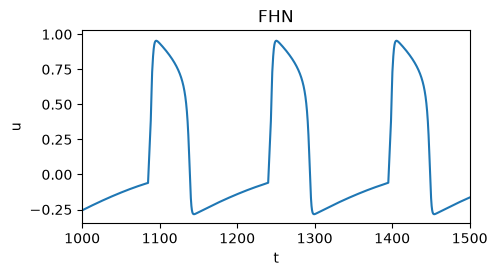

Text(0.5, 1.0, 'FHN (Non-Autonomous Term Subtracted)')

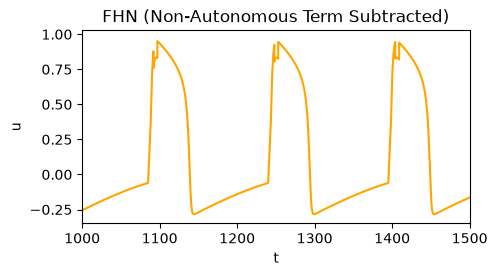

In [17]:
u_fhn = df_states_fhn['u'].tolist()
print(u_fhn[0:10])
print(t_fhn[0:10])

# Plot result - u vs. t
plt.figure(figsize=(5, 2.5))
plt.plot(t_fhn,u_fhn)
plt.xlim(1000, 1500)
plt.xlabel('t')
plt.ylabel('u')
plt.title('FHN')
plt.show()

# Now subtract the non-autonomous term to try to ID the original FHN dynamics. Because of the nonlinear effects, the spike at the peak will be slightly off, making this method not work particularly well.
plt.figure(figsize=(5, 2.5))
plt.plot(t_fhn,u_fhn - logical_non_aut(t_fhn, period=156, dur=5, mag=0.12), color='orange')
plt.xlim(1000, 1500)
plt.xlabel('t')
plt.ylabel('u')
plt.title('FHN (Non-Autonomous Term Subtracted)')

Text(0.5, 1.0, 'FFT of FHN u Values')

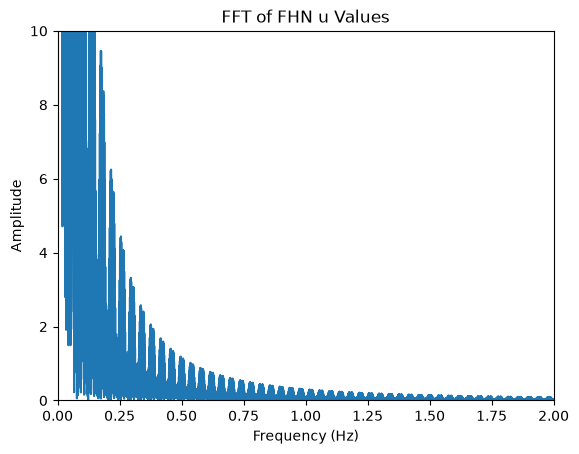

In [18]:
# Test analyzing time series in frequency space to see if we can tease out the non-autonomous signal.
# TODO Figure out what whether scipy.fft is being used incorrectly
w_fhn = fft.fft(u_fhn)
w_fhn = np.abs(w_fhn[0:len(w_fhn)//2]) # Take the first half of the FFT result, making sure to make all values real.
w = np.arange(0, 10, dt / 100.)
plt.plot(w, w_fhn)
plt.ylim(0, 10)
plt.xlim(0, 2)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.title('FFT of FHN u Values')

# 3.) Using GeneralizedLibrary to ID Non-Autonomous Terms
We can use pySINDy's `GeneralizedLibrary` class to combine multiple `CustomLibrary` instances while also restricting which functions can apply to which equations using the argument inputs_per_library. This is useful since we know that the time-dependent term will only appear in the $u$ (voltage) equation.

In [19]:
# TODO Calling w/ functools.partial() results in no .__code__ on pySINDy call, so have to define functions explicitly; would like to refactor in better way.
# Define battery of similar non-autonomous terms on which to test SINDy with the GeneralizedLibrary implementation above.
# Recall - 0.12 approximately optimal stimulus (for period 0.08 * 1.5 --> 0.12).
func_test = lambda t: (np.sin(0.01*t))**2
def func_log(t):
    return logical_non_aut(t, period=155.0, dur=5.0, mag=0.12)
def func_smooth(t):
    return smooth_non_aut(t, mag=0.12)
def func_smooth_old(t):
    return smooth_non_aut_old(t, mag=0.12)
funcs = [func_test, func_log, func_smooth, func_smooth_old]

### a.) FHN Test

----------Fitting with function: <lambda>----------
Number of SINDy terms for u', v': (5, 2)
Number of exact terms for u', v': (5, 2)
Mean Absolute Error of coefficients: 7.01406e-07

SINDy coefficients:
(u)' = -0.10000 u + -1.00000 v +  1.10000 u^2 + -1.00000 u^3 +  1.00000 f_td(t)
(v)' =  0.00500 u + -0.01000 v
(t)' =  1.00000 1

Exact coefficients:
u' = -0.10000 u + -1.00000 v + 1.10000 u^2 + -1.00000 u^3 + 1.00000 f_td
v' = 0.00500 u + -0.01000 v


Mean Absolute Error between reconstruction and true values: 1.16741e-07
Beat recall: 1.00000e+00 (6/6)
Beat F1: 1.00000e+00
Mean IBI (true/predicted): 3.14130e+02 / 3.14130e+02
IBI MAE: 0.00000e+00
APD90 MAE: 0.00000e+00
Activation time MAE: 0.00000e+00



----------Fitting with function: func_log----------
Number of SINDy terms for u', v': (9, 2)
Number of exact terms for u', v': (5, 2)
Mean Absolute Error of coefficients: 1.85417e-02

SINDy coefficients:
(u)' = -0.09943 u + -1.00091 v +  1.09886 u^2 +  0.04907 v^2 + -0.99949 u^3 + -0.2

c:\Dev\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\optimizers\stlsq.py:234: UserWarning: Sparsity parameter is too big (0.1) and eliminated all coefficients
  warnings.warn(


Number of SINDy terms for u', v': (8, 0)
Number of exact terms for u', v': (5, 2)
Mean Absolute Error of coefficients: 4.60162e+00

SINDy coefficients:
(u)' = -0.09999 u + -1.00030 v +  1.10078 u^2 + -0.18679 v^2 + -1.00469 u^3 +  82.61012 v^3 + -0.01124 u*v +  0.99983 f_td(t)
(v)' =  0.00000
(t)' =  1.00000 1

Exact coefficients:
u' = -0.10000 u + -1.00000 v + 1.10000 u^2 + -1.00000 u^3 + 1.00000 f_td
v' = 0.00500 u + -0.01000 v


Mean Absolute Error between reconstruction and true values: 8.67013e-03
Beat recall: 9.23077e-01 (12/13)
Beat F1: 9.60000e-01
Mean IBI (true/predicted): 1.54648e+02 / 1.57080e+02
IBI MAE: 2.65364e+00
APD90 MAE: 8.19455e+00
Activation time MAE: 1.30883e+01



----------Fitting with function: func_smooth_old----------
Number of SINDy terms for u', v': (7, 2)
Number of exact terms for u', v': (5, 2)
Mean Absolute Error of coefficients: 3.49325e-05

SINDy coefficients:
(u)' = -0.10000 u + -1.00000 v +  1.10000 u^2 +  0.00010 v^2 + -1.00000 u^3 + -0.00051 v^3 +  

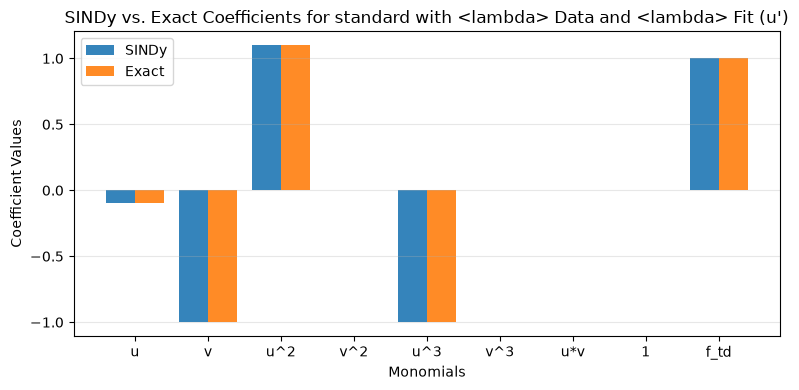

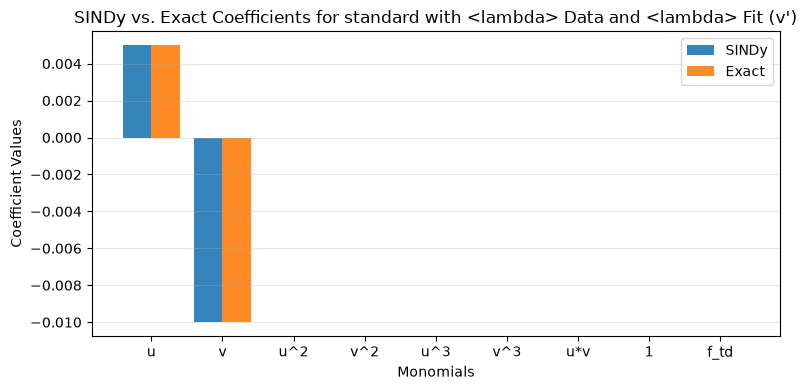

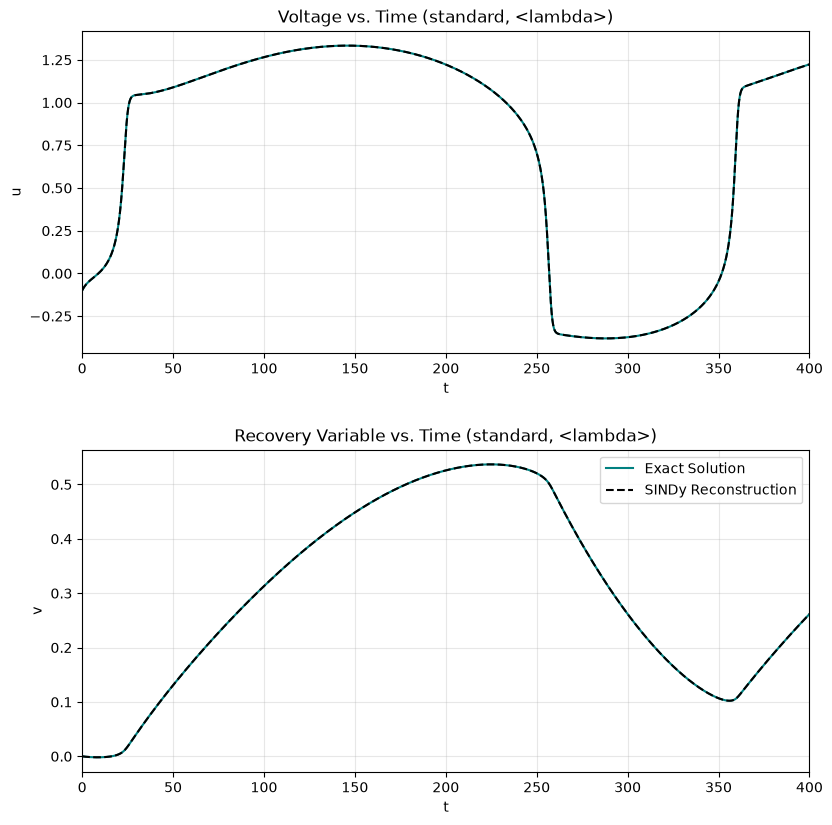

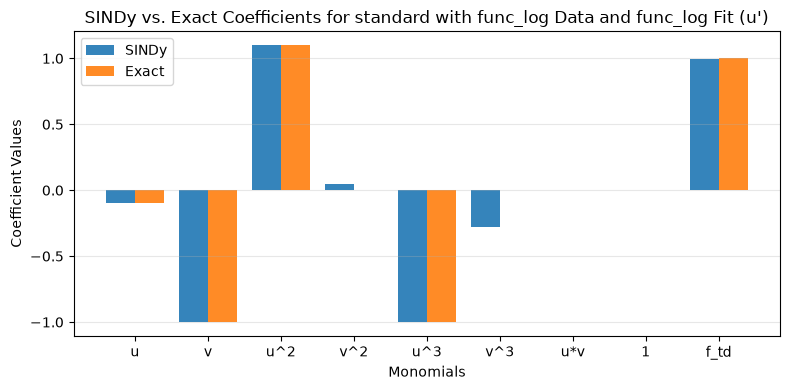

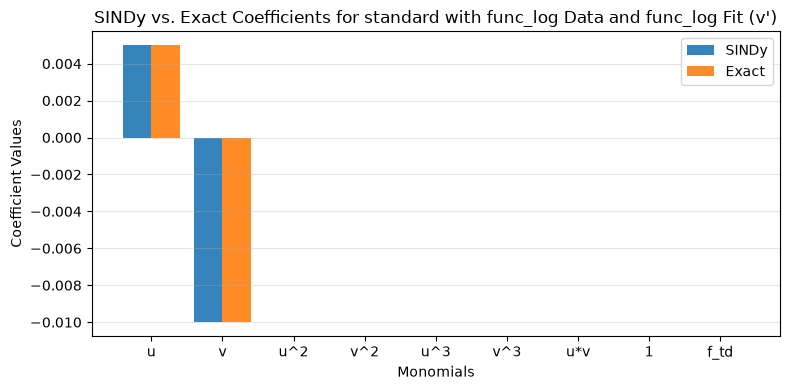

...

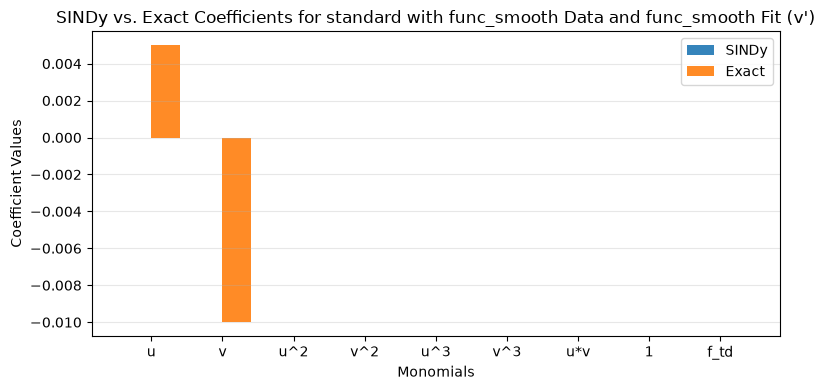

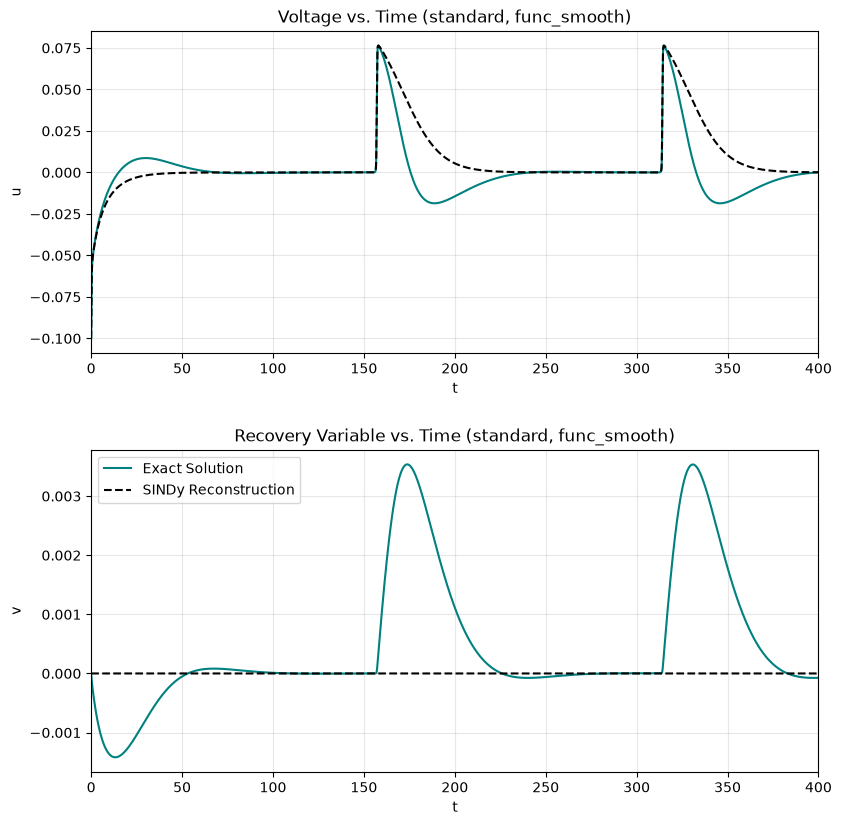

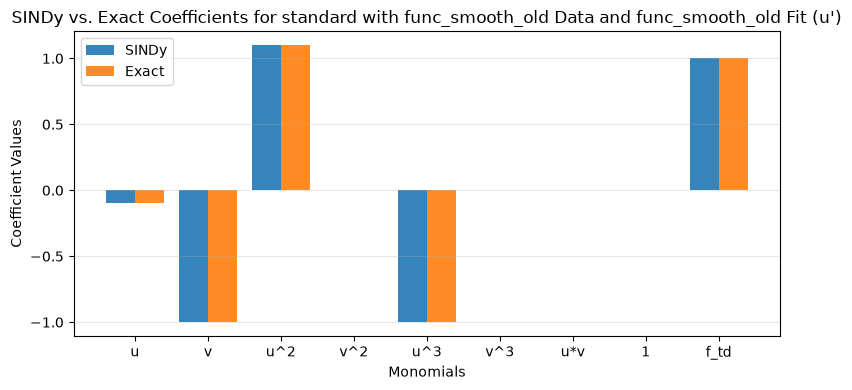

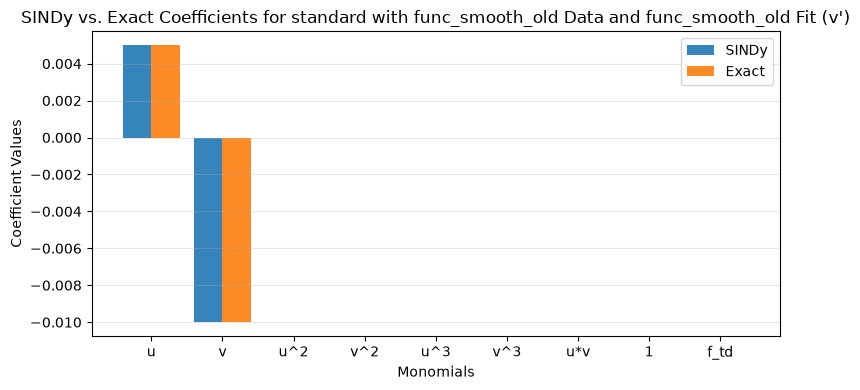

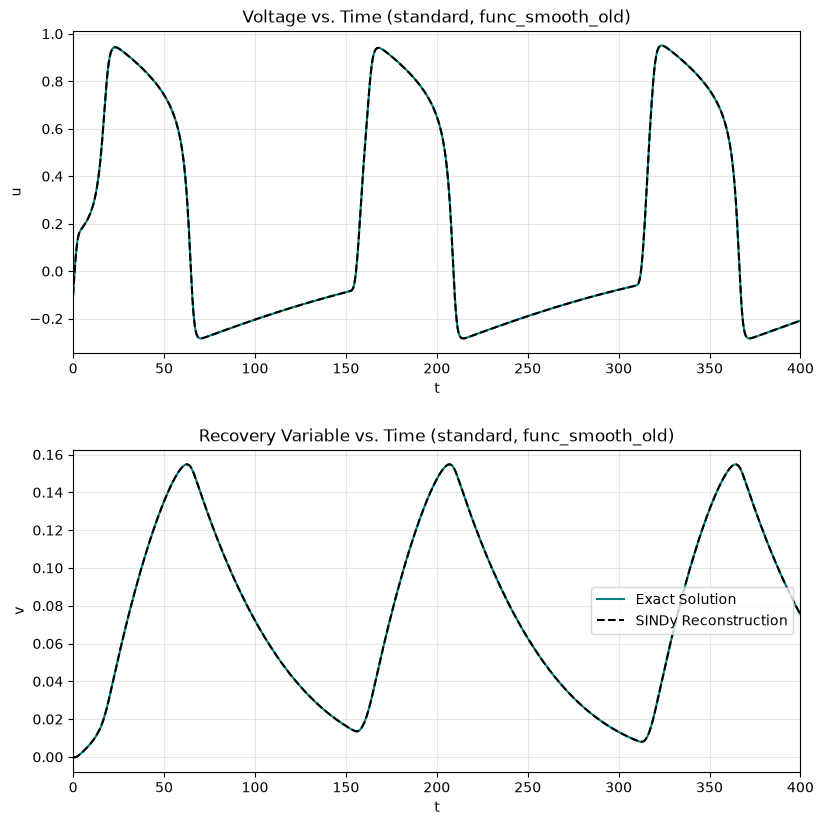

In [44]:
a_models = []

# Test fit with same data and fitting non-autonomous terms.
for func in funcs:
    print(f'----------Fitting with function: {func.__name__}----------')
    cur_gen_library_a = GenLibraryFit(func, func, model_variant='standard', color='teal')
    a_models.append(cur_gen_library_a.fit())
    print('\n\n')

Actual equations for comparison:

\begin{align}
    \dot{u} &= - 0.1 u + 1.1 u^2 - 1 u^3 - 1 v + f_{td}(t) \\
    \dot{v} &= 0.005 u - 0.01v \\
\end{align}

##### Different Fit and Data Stimuli

----------Fitting logical_non_aut data with smooth_non_aut fit----------
Number of SINDy terms for u', v': (9, 2)
Number of exact terms for u', v': (5, 2)
Mean Absolute Error of coefficients: 8.04770e+00

SINDy coefficients:
(u)' =  0.16420 u + -1.88209 v +  0.87470 u^2 +  22.80391 v^2 + -1.06029 u^3 + -118.72661 v^3 + -0.95283 u*v +  0.03987 1 +  0.09653 f_td(t)
(v)' =  0.00500 u + -0.01000 v
(t)' =  1.00000 1

Exact coefficients:
u' = -0.10000 u + -1.00000 v + 1.10000 u^2 + -1.00000 u^3 + 1.00000 f_td
v' = 0.00500 u + -0.01000 v


Mean Absolute Error between reconstruction and true values: 4.99002e-01
Beat recall: 1.00000e+00 (13/13)
Beat F1: 9.62963e-01
Mean IBI (true/predicted): 1.55008e+02 / 1.46141e+02
IBI MAE: 8.82583e+00
APD90 MAE: 1.28154e+00
Activation time MAE: 3.89269e+01





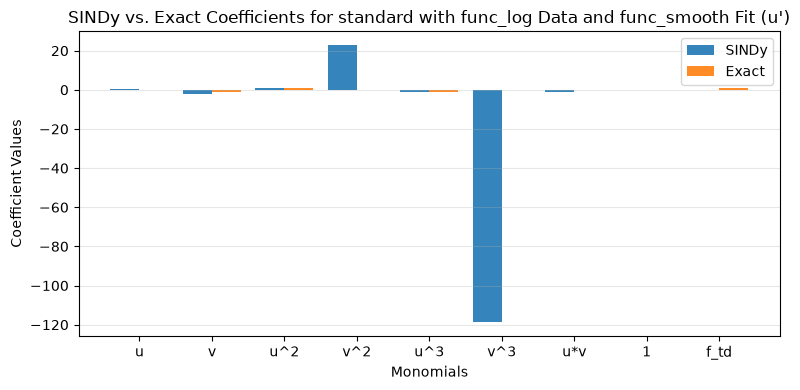

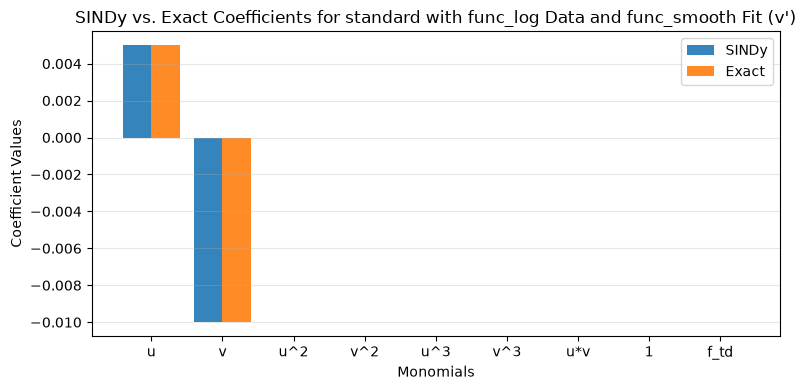

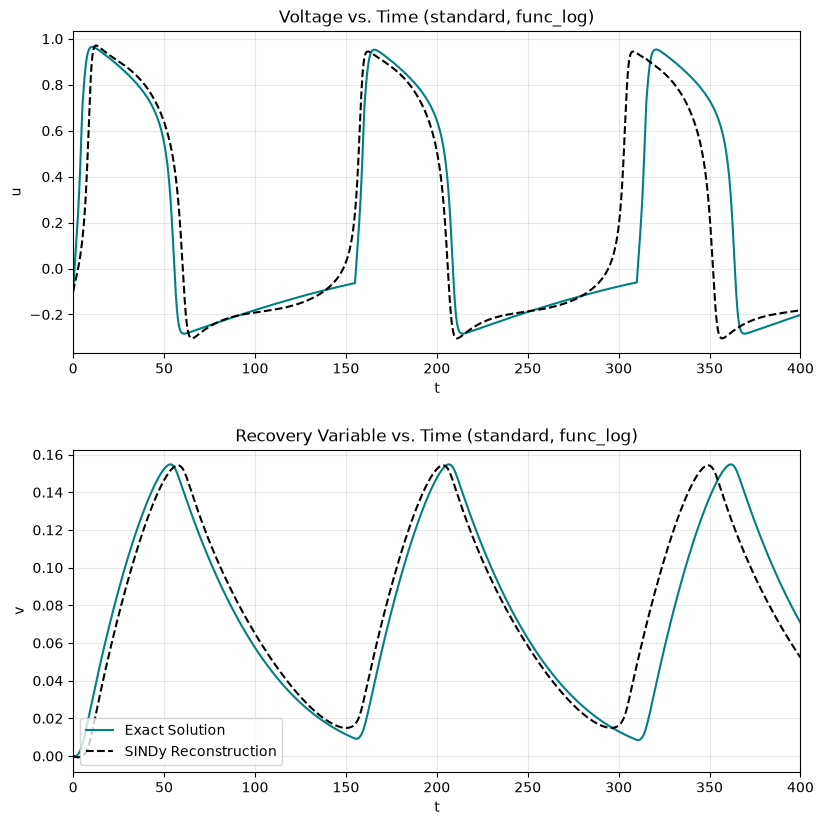

In [45]:
# TODO Can't correctly ID w/ similar-looking non-autonomous functions; the magnitude of the effect of small differences in stimulus currents is a clear limitation.
# Test fit with different data and fitting non-autonomous terms.
print(f'----------Fitting logical_non_aut data with smooth_non_aut fit----------')
cur_gen_library_a = GenLibraryFit(func_log, func_smooth, model_variant='standard', color='teal')
cur_gen_library_a.fit()
print('\n\n')

### b.) FHN-c Test

----------Fitting with function: <lambda>----------
Number of SINDy terms for u', v': (8, 2)
Number of exact terms for u', v': (5, 2)
Mean Absolute Error of coefficients: 5.44128e-01

SINDy coefficients:
(u)' =  0.07781 u +  0.69449 v + -2.72012 v^2 + -0.11933 u^3 +  2.53438 v^3 + -0.09673 u*v + -0.02604 1 +  0.24248 f_td(t)
(v)' =  0.00500 u + -0.01000 v
(t)' =  1.00000 1

Exact coefficients:
u' = -0.10000 u + 1.10000 u^2 + -1.00000 u^3 + -1.00000 u*v + 1.00000 f_td
v' = 0.00500 u + -0.01000 v


Mean Absolute Error between reconstruction and true values: 4.08080e-02
Beat recall: 1.00000e+00 (6/6)
Beat F1: 1.00000e+00
Mean IBI (true/predicted): 3.14794e+02 / 3.14846e+02
IBI MAE: 2.32000e-01
APD90 MAE: 8.11500e+00
Activation time MAE: 3.80333e+00



----------Fitting with function: func_log----------
Number of SINDy terms for u', v': (9, 2)
Number of exact terms for u', v': (5, 2)
Mean Absolute Error of coefficients: 8.93556e-02

SINDy coefficients:
(u)' = -0.09655 u + -0.06441 v +  1.0

c:\Dev\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\optimizers\stlsq.py:234: UserWarning: Sparsity parameter is too big (0.1) and eliminated all coefficients
  warnings.warn(


Number of SINDy terms for u', v': (4, 0)
Number of exact terms for u', v': (5, 2)
Mean Absolute Error of coefficients: 6.58611e-01

SINDy coefficients:
(u)' = -0.07490 u +  9.69276 u^3 + -1.02187 u*v +  0.99972 f_td(t)
(v)' =  0.00000
(t)' =  1.00000 1

Exact coefficients:
u' = -0.10000 u + 1.10000 u^2 + -1.00000 u^3 + -1.00000 u*v + 1.00000 f_td
v' = 0.00500 u + -0.01000 v


Mean Absolute Error between reconstruction and true values: 5.57917e-03
Beat recall: 1.00000e+00 (13/13)
Beat F1: 1.00000e+00
Mean IBI (true/predicted): 1.57098e+02 / 1.57074e+02
IBI MAE: 2.41667e-02
APD90 MAE: 1.01762e+01
Activation time MAE: 2.23077e-02



----------Fitting with function: func_smooth_old----------
Number of SINDy terms for u', v': (5, 2)
Number of exact terms for u', v': (5, 2)
Mean Absolute Error of coefficients: 3.59482e-07

SINDy coefficients:
(u)' = -0.10000 u +  1.10000 u^2 + -1.00000 u^3 + -1.00000 u*v +  1.00000 f_td(t)
(v)' =  0.00500 u + -0.01000 v
(t)' =  1.00000 1

Exact coefficients:

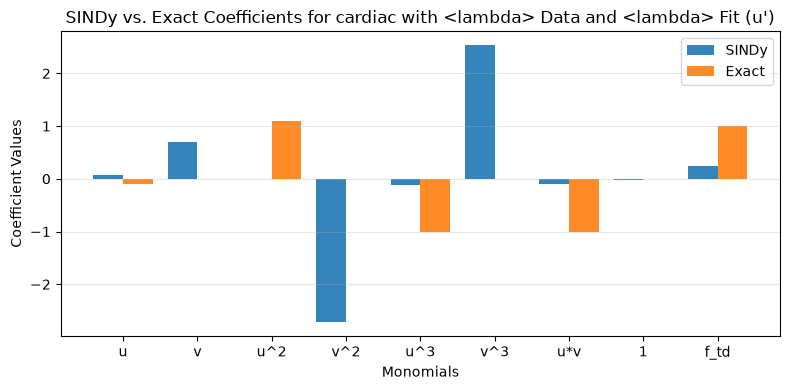

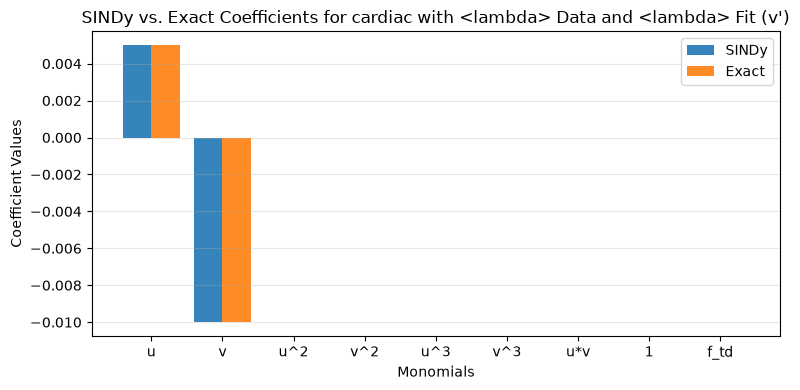

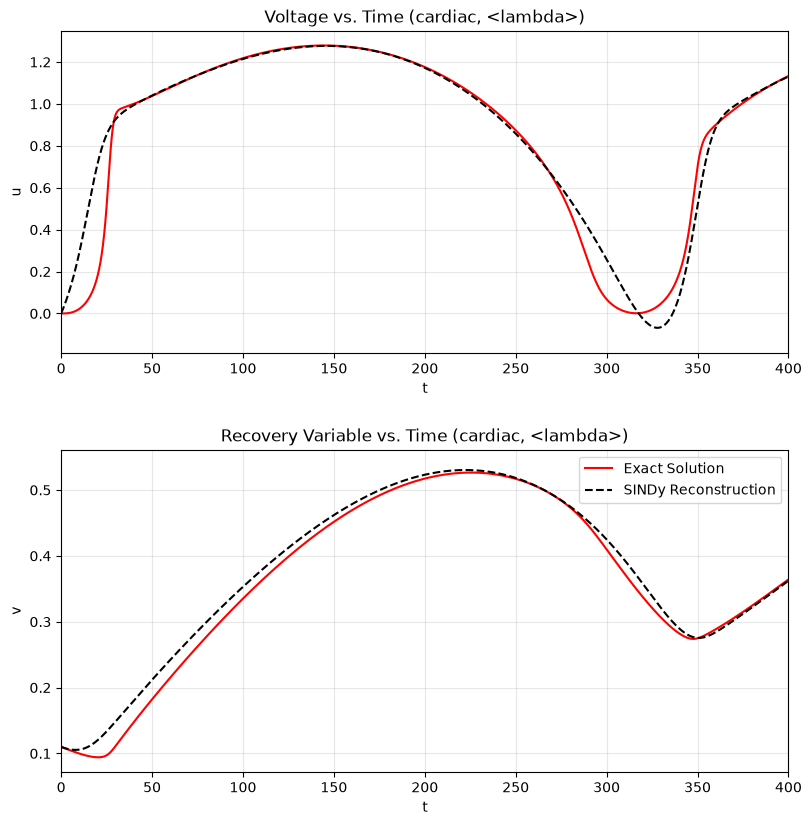

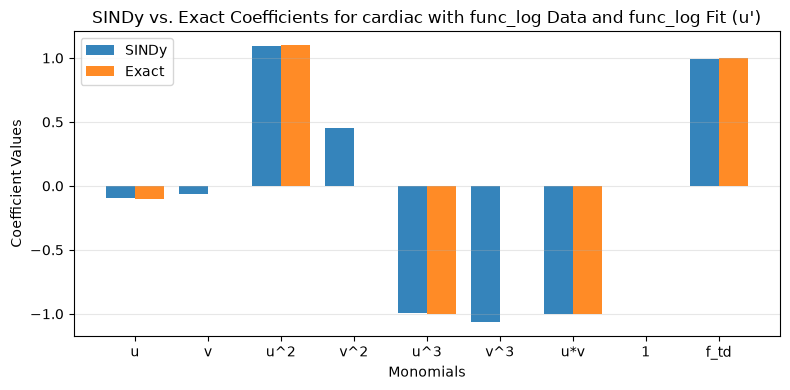

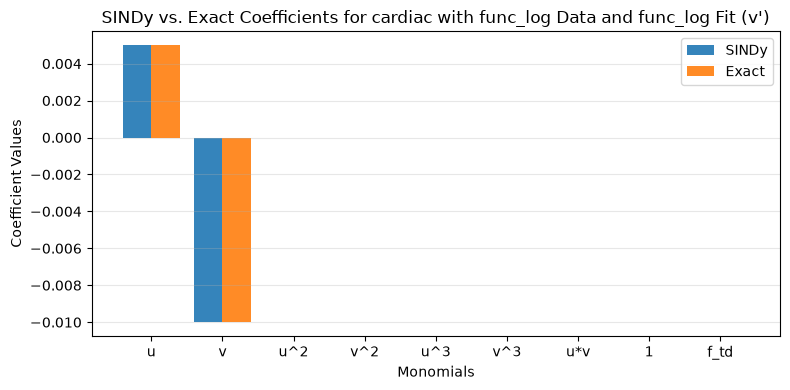

...

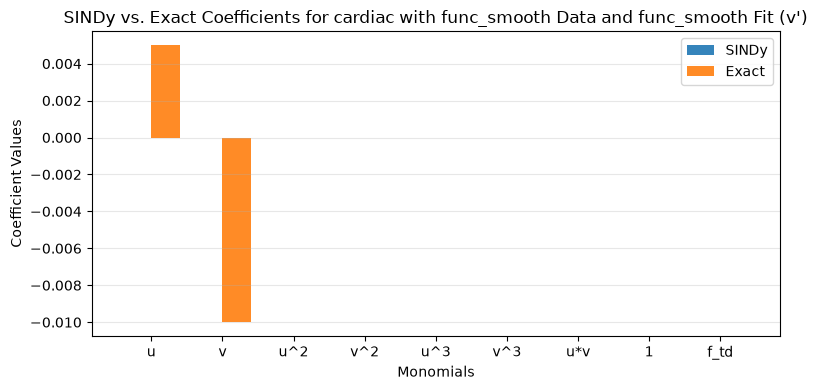

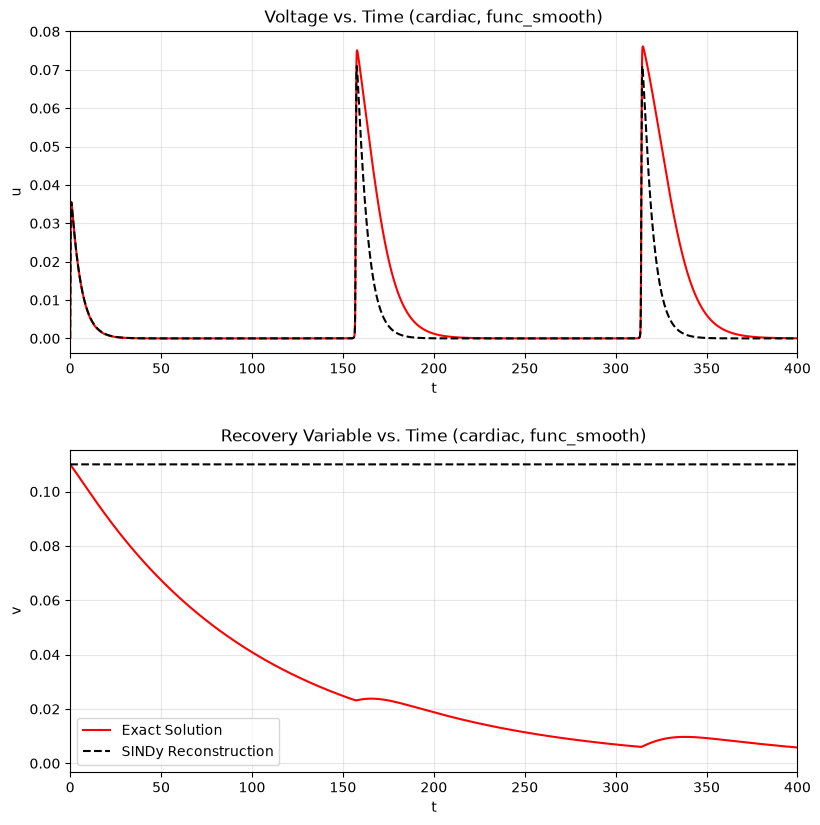

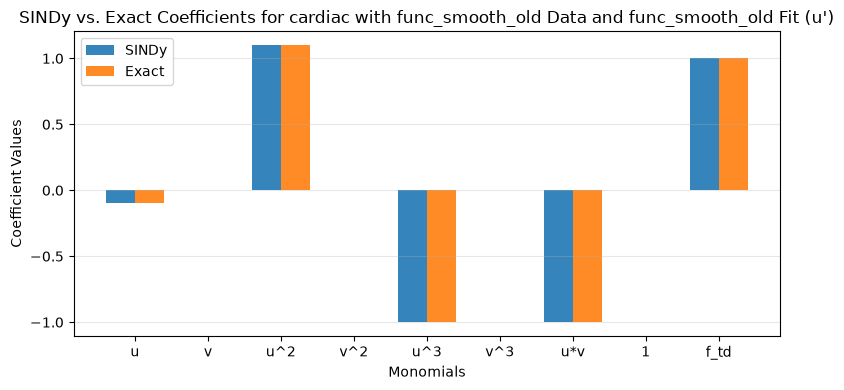

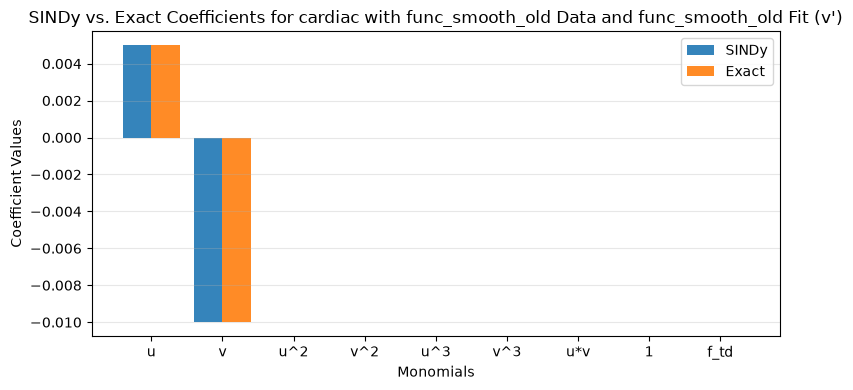

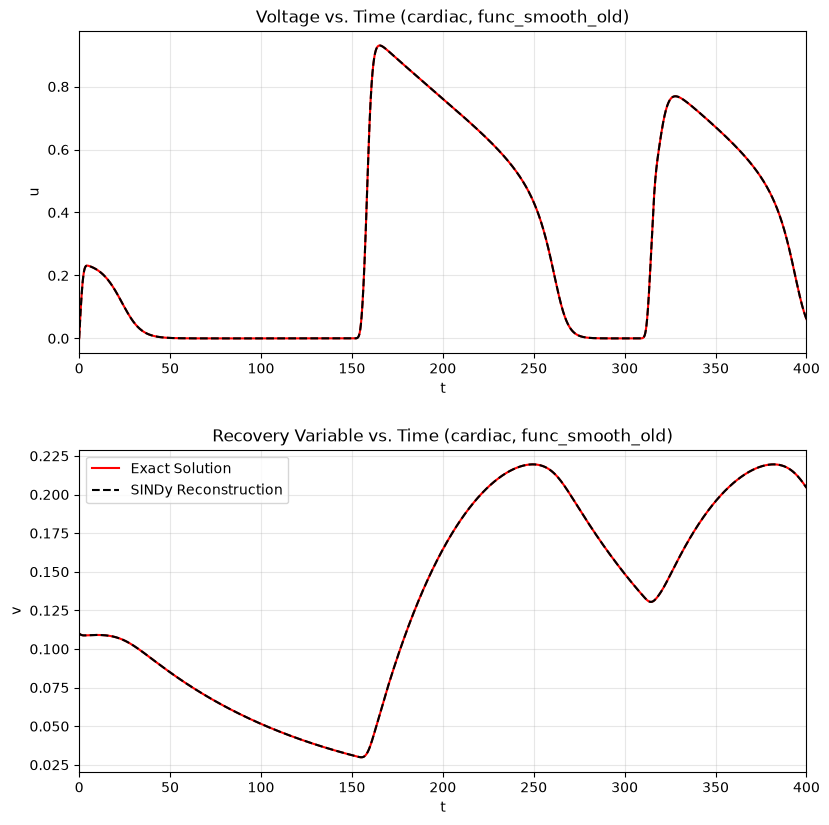

In [46]:
b_models = []

# Test fit with same data and fitting non-autonomous terms.
for func in funcs:
    print(f'----------Fitting with function: {func.__name__}----------')
    cur_gen_library_b = GenLibraryFit(func, func, model_variant='cardiac', ics=x_0_fhn_c, color='red')
    b_models.append(cur_gen_library_b.fit())
    print('\n\n')

Actual equations for comparison:

\begin{align}
    \dot{u} &= - 0.1 u + 1.1 u^2 - 1 u^3 - 1 u v + f_{td}(t) \\
    \dot{v} &= 0.005 u - 0.01v \\
\end{align}

### c.) VF-FHN (a) Test
Test SINDy ID on the 4-parameter VF-FHN model (also called VF4).  Note that this model can be put it in an alternans regime with a stimulus of period 185 and a period-1 oscillation with a stimulus of period 225.

----------Fitting with function: func_log_vf_4----------
Number of SINDy terms for u', v': (9, 4)
Number of exact terms for u', v': (5, 3)
Mean Absolute Error of coefficients: 4.23469e-01

SINDy coefficients:
(u)' = -0.19647 u + -0.29819 v +  1.18981 u^2 +  2.14975 v^2 + -0.99262 u^3 + -5.10896 v^3 + -1.00037 u*v +  0.01363 1 +  0.99564 f_td(t)
(v)' = -0.00012 u + -0.00368 v +  0.01401 u*v + -0.00013 1
(t)' =  1.00000 1

Exact coefficients:
u' = -0.20000 u + 1.20000 u^2 + -1.00000 u^3 + -1.00000 u*v + 1.00000 f_td
v' = 0.00550 u + -0.00500 v + -0.00500 u^2


Mean Absolute Error between reconstruction and true values: 4.98774e-03
Beat recall: 1.00000e+00 (18/18)
Beat F1: 1.00000e+00
Mean IBI (true/predicted): 2.24994e+02 / 2.24997e+02
IBI MAE: 7.41176e-02
APD90 MAE: 1.12889e+00
Activation time MAE: 0.00000e+00





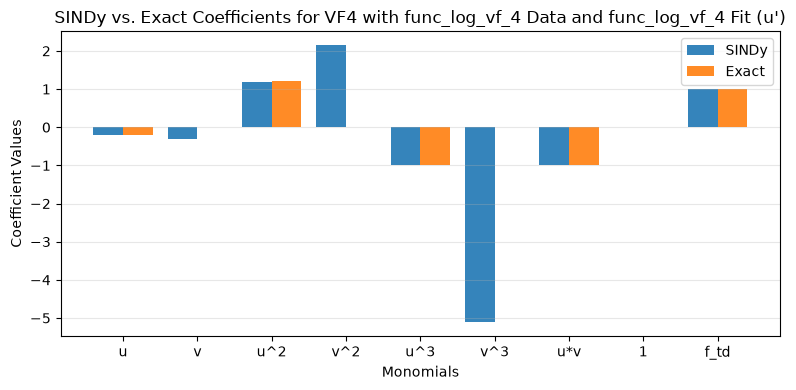

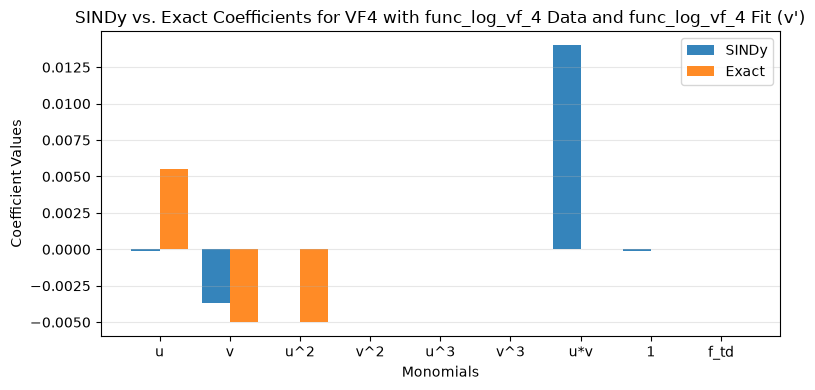

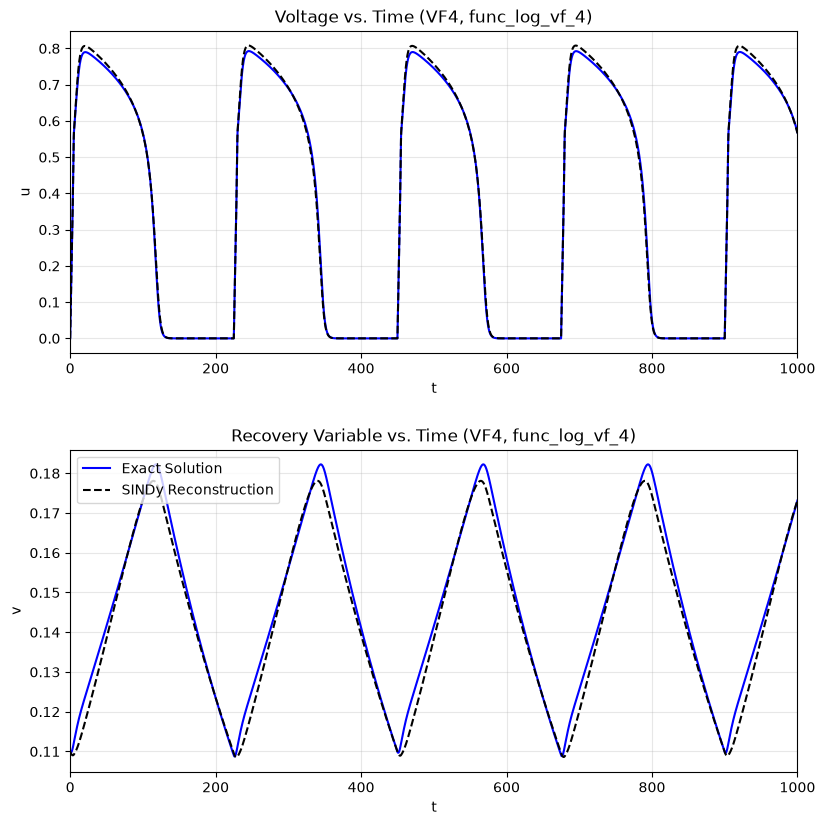

In [ ]:
def func_log_vf_4(t):
    return logical_non_aut(t, period=225.0, dur=5.0, mag=0.12)
funcs_vf_4 = [func_log_vf_4]
c_models = []

# Test fit with same data and fitting non-autonomous terms.
for func in funcs_vf_4:
    print(f'----------Fitting with function: {func.__name__}----------')
    cur_gen_library_c = GenLibraryFit(func, func, model_variant='vf4', t_range=np.arange(0,4000,0.01), ics=x_0_vf_4, color='blue')
    c_models.append(cur_gen_library_c.fit(end_time_vis=1000))
    print('\n\n')

### d.) VF-FHN (b) Test
Test SINDy ID on the 7-parameter VF-FHN model (also called VF7).

----------Fitting with function: stim_period_100----------
Excluded from v': ['f_td(t)']
Number of SINDy terms for u', v': (9, 2)
Number of exact terms for u', v': (5, 3)
Mean Absolute Error of coefficients: 2.36685e-02

SINDy coefficients:
(u)' = -0.24897 u + -0.00657 v +  1.24629 u^2 +  0.08337 v^2 + -0.99726 u^3 + -0.30550 v^3 + -0.99848 u*v +  0.00013 1 +  0.99733 f_td(t)
(v)' =  0.00106 u +  0.00384 u*v
(t)' =  1.00000 1

Exact coefficients:
u' = -0.25000 u + 1.25000 u^2 + -1.00000 u^3 + -1.00000 u*v + 1.00000 f_td
v' = 0.00600 u + -0.00500 v + -0.00500 u^2


Mean Absolute Error between reconstruction and true values: 1.85949e-01
Beat recall: 1.00000e+00 (20/20)
Beat F1: 1.00000e+00
Mean IBI (true/predicted): 1.00525e+02 / 9.94853e+01
IBI MAE: 1.79368e+01
APD90 MAE: 2.06279e+01
Activation time MAE: 2.24550e+00



----------Fitting with function: stim_period_200----------
Excluded from v': ['f_td(t)']
Number of SINDy terms for u', v': (9, 3)
Number of exact terms for u', v': (5, 3)

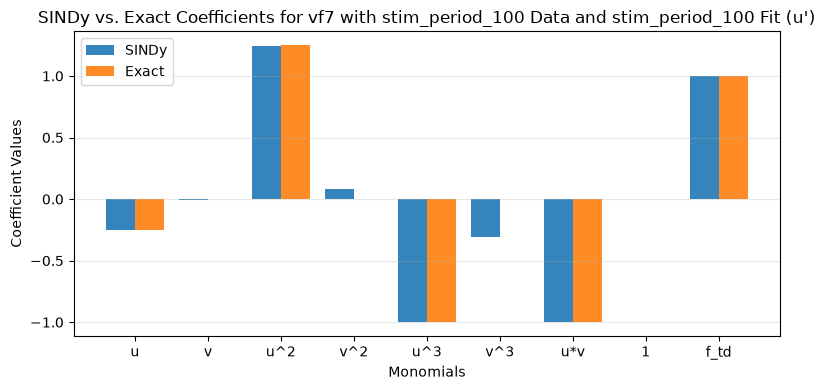

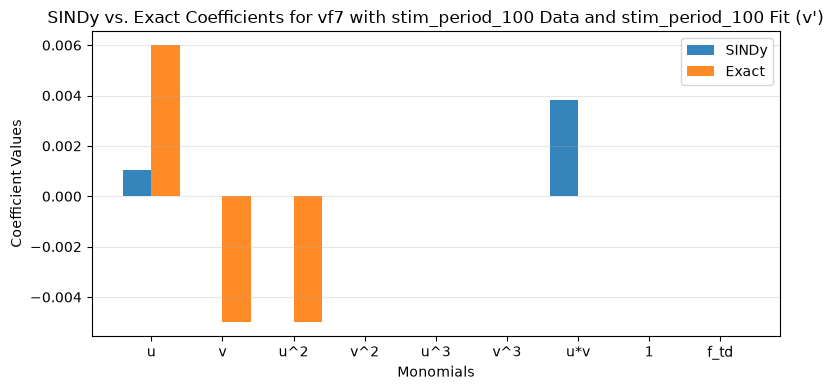

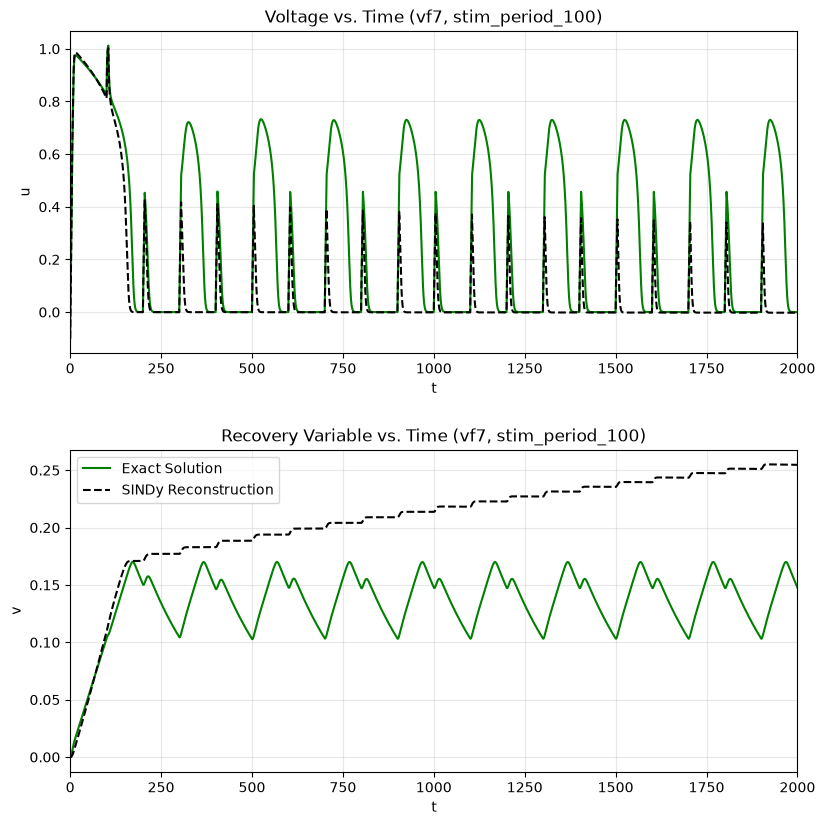

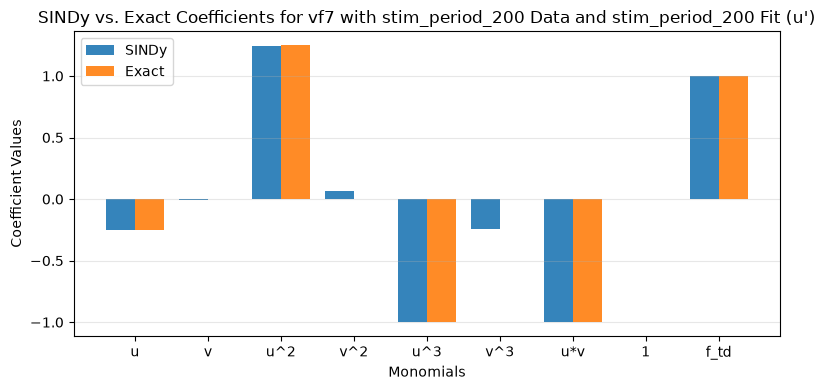

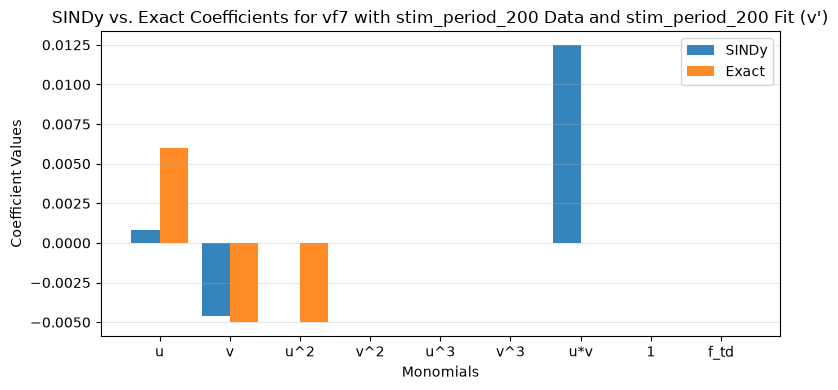

...

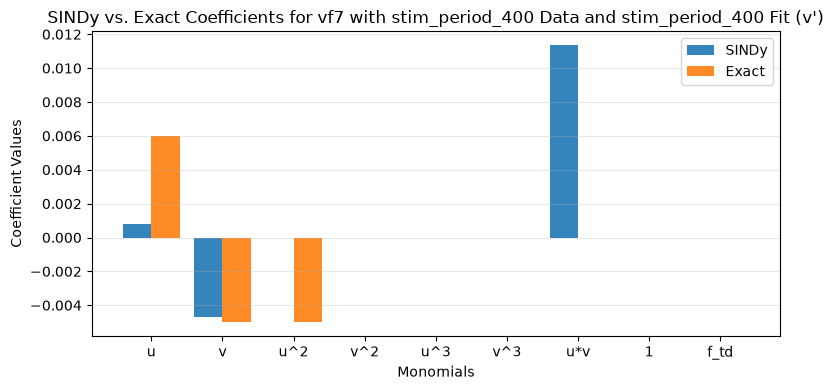

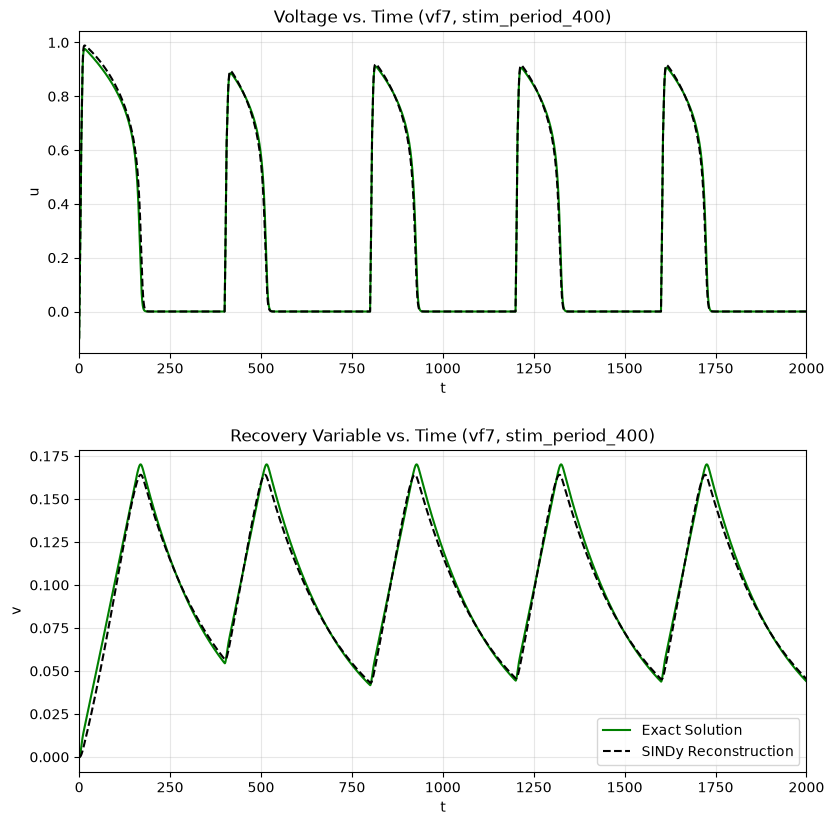

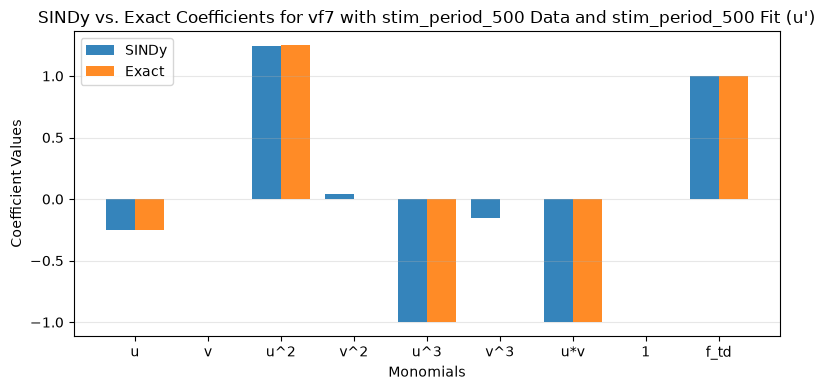

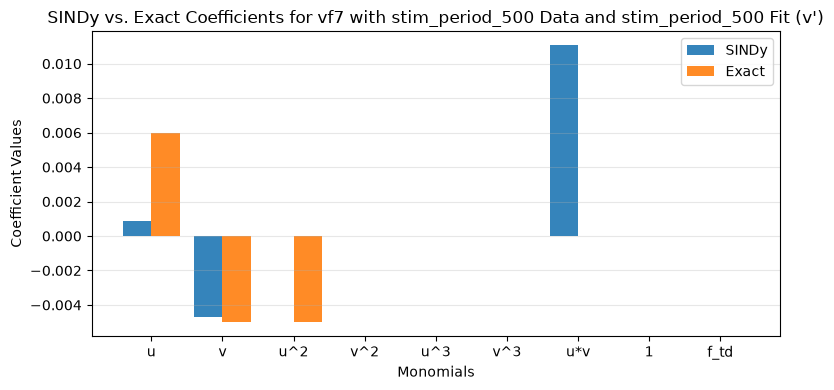

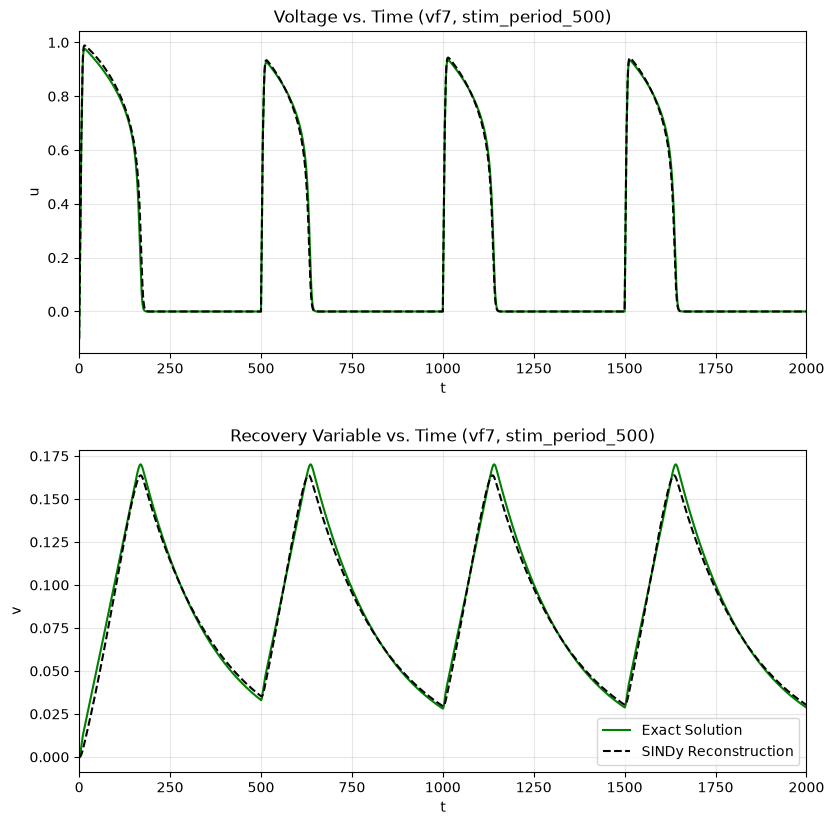

In [20]:
def stim_period_100(t):
    return logical_non_aut(t, period=100., dur=5., mag=0.12)
def stim_period_200(t):
    return logical_non_aut(t, period=200., dur=5., mag=0.12)
def stim_period_300(t):
    return logical_non_aut(t, period=300., dur=5., mag=0.12)
def stim_period_400(t):
    return logical_non_aut(t, period=400., dur=5., mag=0.12)
def stim_period_500(t):
    return logical_non_aut(t, period=500., dur=5., mag=0.12)
funcs_vf_7 = [stim_period_100, stim_period_200, stim_period_300, stim_period_400, stim_period_500]
d_models = []

# TODO VF-b has parameters slightly off based on t~1750
# Test fit with same data and fitting non-autonomous terms.
for func in funcs_vf_7:
    print(f'----------Fitting with function: {func.__name__}----------')
    cur_gen_library_d = GenLibraryFit(func, func, model_variant='vf7', color='green')
    d_models.append(cur_gen_library_d.fit(end_time_vis=2000))
    print('\n\n')

Actual equations for comparison:

\begin{align}
    \dot{u} &= - 0.2 u + 1.2 u^2 - u v - 1 u^3 + f_{td}(t) \\
    \dot{v} &= -0.001455 + 0.00705u - 0.005u^2 \\
\end{align}

# 4.) Stimulus Amplitude Comparison

In [ ]:
# (Uncomment to determine the optimal stimulus amplitude)

# Plot time-dependent FHN states for different stimulus amplitudes. The optimal amplitude will be around 1.5x to 2x the 
# first threshold amplitude that gives a good waveform (so ~1.5 * 0.08 = 0.12).
# for amp in np.arange(0.0,0.2,0.02):
#     states_fhn_td = odeint(fhn, cur_gen_library_a.x_0_fhn_td, cur_gen_library_a.t_fhn_td, args=(functools.partial(logical_non_aut, period=155.0, dur=5.0, mag=amp),), hmax=0.1) # Test --> lambda t: 0       Actual --> logical_non_aut
#     plt.plot(states_fhn_td[:,0:1], label='u')
#     plt.ylim(-0.5,1.5)
#     plt.xlim(0,50000)
#     plt.title(f"FHN Time-Dependent States with Stimulus Amplitude {amp:.2f}")
#     plt.show()

# 5.) Noisy Data Test
Add Gaussian noise to our data, then test the ability of SINDy to identify the equations under noisy conditions. Based on the results, it seems like ID usually works for noise levels with $\sigma < 0.001$.

----------Fitting with function: func_log_vf_4----------
Number of SINDy terms for u', v': (9, 4)
Number of exact terms for u', v': (5, 3)
Mean Absolute Error of coefficients: 4.25248e-01

SINDy coefficients:
(u)' = -0.19646 u + -0.29948 v +  1.18978 u^2 +  2.15890 v^2 + -0.99260 u^3 + -5.13041 v^3 + -1.00037 u*v +  0.01369 1 +  0.99563 f_td(t)
(v)' = -0.00012 u + -0.00367 v +  0.01401 u*v + -0.00013 1
(t)' =  1.00000 1

Exact coefficients:
u' = -0.20000 u + 1.20000 u^2 + -1.00000 u^3 + -1.00000 u*v + 1.00000 f_td
v' = 0.00550 u + -0.00500 v + -0.00500 u^2


Mean Absolute Error between reconstruction and true values: 4.98673e-03





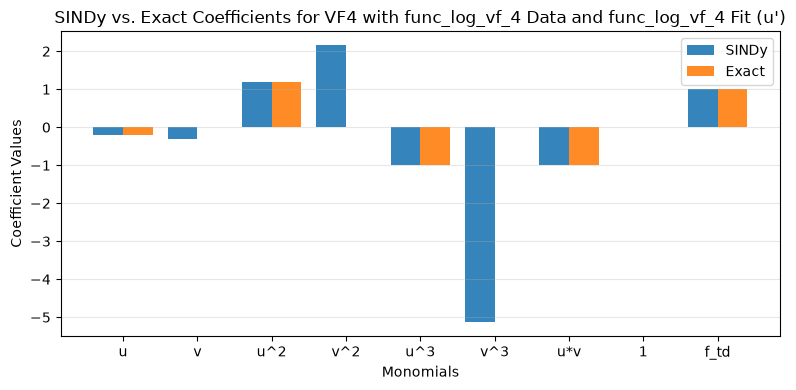

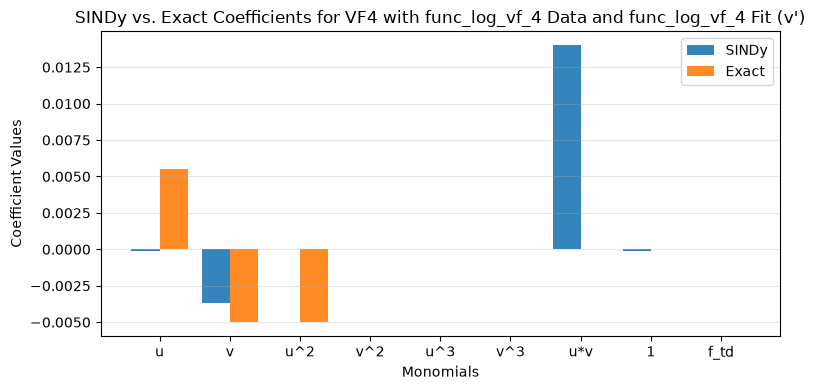

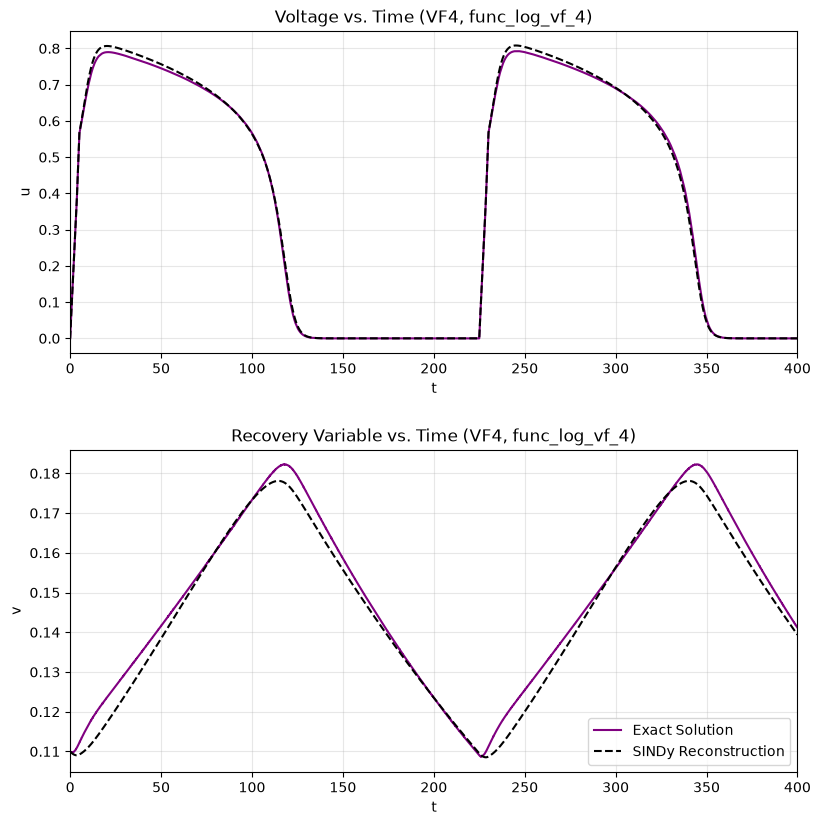

In [ ]:
# Test fit with noise added. Since u is around 2x the magnitude of v on average (0.34 / 0.15 ~ 2.27), we add noise with std dev sigma
# to u and sigma/2 to v.
sigma = 1e-5

# Run the fit with VF4 stimulus.  Note that the reconstruction MAE is generally higher than the coefficient MAE for noisy data.
for func in funcs_vf_4:
    print(f'----------Fitting with function: {func.__name__}----------')
    cur_gen_library_c = GenLibraryFit(func, func, model_variant='vf4', t_range=np.arange(0,4000,0.01), ics=x_0_vf_4, color='purple', u_noise=sigma, v_noise=sigma/2)
    c_models.append(cur_gen_library_c.fit())
    print('\n\n')

# 6.) SINDy Identification Using Only Voltage
### a.) Takens' Theorem
In this section, we test how well SINDy can identify the equation $u'$ without the recovery equation $v'$. Instead, we pass a time-shifted version of the $u'$ equation for the remaining inputs, with the optimal delay interval determined by the average mutual information.  Takens' theorem states that at least $2n+1$ delayed copies in the embedded space will be needed to reconstruct the original dynamics of a system in $n$ dimensions.  In practice, we'll usually need a few more dimensions.

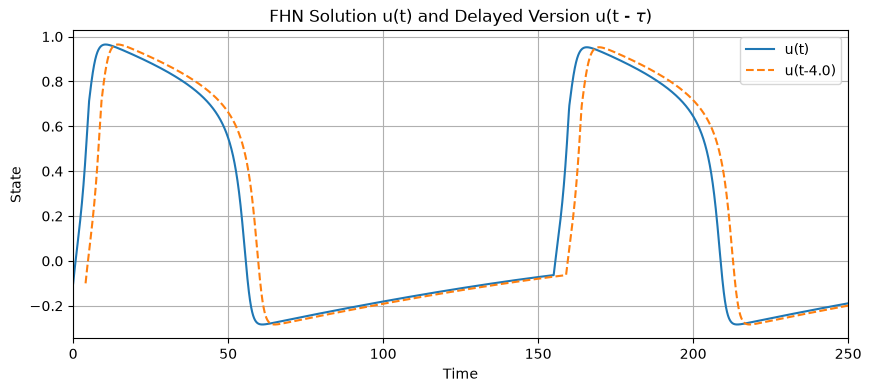

In [43]:
# Extract u from FHN solution
u_fhn = states_fhn[:, 0]

# Define time delay
# Notes on best practices for this:
# - In general, use tau around 1/4 of the AP duration (155 TU stimulus --> ~ 167 TU APD, so tau ~ 40).
# - According to Takens method results, tau ~ 24 appears better, so use that for sake of consistency in this comparison.
tau_cur = 4.0

# Calculate number of steps to shift indices by and construct delayed u array using this value
shift_indices = int(tau_cur / dt)
u_delayed = np.full_like(u_fhn, np.nan)
u_delayed[shift_indices:] = u_fhn[:-shift_indices]

# Compare u and shifted u
plt.figure(figsize=(10, 4))
plt.plot(t_fhn, u_fhn, label='u(t)')
plt.plot(t_fhn, u_delayed, label=f'u(t-{tau_cur})', linestyle='--')
plt.xlabel('Time')
plt.ylabel('State')
plt.title(r'FHN Solution u(t) and Delayed Version u(t - $\tau$)')
plt.legend()
plt.grid(True)
plt.xlim(0, 250)
plt.show()

(200000, 2)
[-0.1        -0.09858244 -0.09716974 -0.0957618  -0.09435858 -0.09296001
 -0.091566   -0.09017648 -0.0887914  -0.08741068]


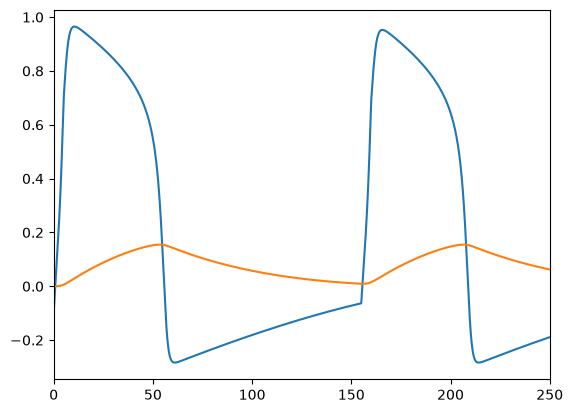

In [44]:
print(states_fhn.shape)
plt.plot(t_fhn, states_fhn)
plt.xlim(0,250)
print(u_fhn[:10])

Time of maximum dV/dt: 4.93
Maximum dV/dt: 0.24043854871553805
Time of peak voltage: 10.46
Peak voltage: 0.9647188980573602
Rest voltage: -0.1
APD90: 50.71


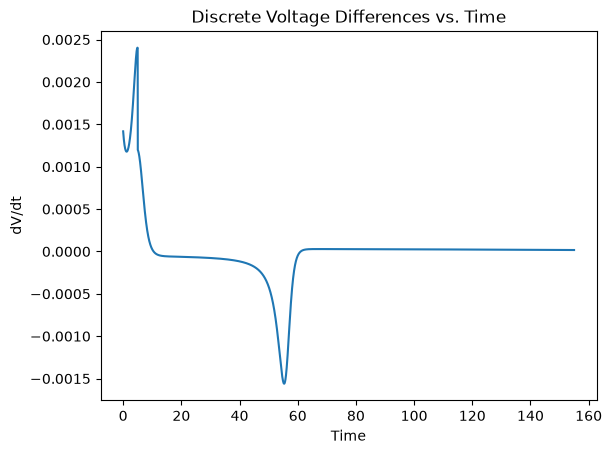

In [20]:
# Calculate upstroke time, activation time for beginning of APD (i.e., time at which maximum dV / dt occurs), and APD90 for the FHN system we're testing
# (time range = np.arange(0,2000,dt), ICs = np.array([-0.1,0]), stimulus = logical_non_aut)

t_end = 155
i_end = int(t_end / dt)

diff_max = -np.inf
t_act = np.nan
diffs = []
for i in range(1, i_end):
    diff_cur = u_fhn[i] - u_fhn[i - 1]
    diffs.append(diff_cur)
    # print(i * dt, diff_cur)

    # Save current maximum dV/dt
    if (diff_cur > diff_max):
        diff_max = diff_cur
        t_act = i * dt

dv_dt_max = diff_max / dt
print(f'Time of maximum dV/dt: {t_act}')
print(f'Maximum dV/dt: {dv_dt_max}')
plt.plot(t_fhn[:i_end-1], diffs)
plt.xlabel('Time')
plt.ylabel('dV/dt')
plt.title('Discrete Voltage Differences vs. Time')

# Calculate APD90
v_peak = np.max(u_fhn[:i_end-1])
t_peak = np.argmax(u_fhn[:i_end-1]) * dt
v_rest = u_fhn[0]
print(f'Time of peak voltage: {t_peak}')
print(f'Peak voltage: {v_peak}')
print(f'Rest voltage: {v_rest}')

# TODO v_rest vs. v_act and t_rest vs. t_act?
v_90 = v_peak - 0.9 * (v_peak - v_rest)
# Find the time at which the voltage crosses v_90 after the peak
t_90 = np.nan
for i in range(int(t_peak / dt), i_end):
    if u_fhn[i] <= v_90:
        t_90 = i * dt
        break
apd_90 = t_90 - t_act
print(f'APD90: {apd_90}')

##### a1.) Test embedding reconstruction on FHN:

----------Fitting with function: func_log----------


c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)




Minimum MAE for tau=125.0 and n_embed=6: 1.91587e-02



----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 125.0000 (delay_idx = 2500)
Embedding dimension = 6
(u(t-0))' =  0.010 u(t-0) +  0.627 u(t-0)^2 + -0.624 u(t-0)^3 +  0.006 u(t-5000) +  0.058 u(t-5000)^2 + -0.042 u(t-5000)^3 + -0.033 u(t-7500) +  0.024 u(t-7500)^2 + -0.027 u(t-7500)^3 + -0.016 u(t-10000) +  0.008 u(t-10000)^2 + -0.028 u(t-10000)^3 + -0.049 u(t-12500) + -0.382 u(t-12500)^2 +  0.282 u(t-12500)^3 +  0.021 u(t-0)*u(t-2500) +  0.113 u(t-0)*u(t-5000) + -0.172 u(t-0)*u(t-7500) +  0.104 u(t-0)*u(t-12500) + -0.022 1 +  0.965 f_td(t)
(u(t-2500))' =  0.129 u(t-0) +  0.108 u(t-0)^2 + -0.012 u(t-2500) +  1.244 u(t-2500)^2 + -1.373 u(t-2500)^3 +  0.162 u(t-5000) +  0.146 u(t-5000)^2 + -0.135 u(t-5000)^3 + -0.048 u(t-7500) +  0.269 u(t-7500)^2 + -0.180 u(t-7500)^3 + -0.014 u(t-10000) + -0.033 u(t-12500) +  0.217 u(t-12500)^2 + -0.231 u(t-12500)^3 +  0.016 u(t-0)*u(t-2500) +  0.992 u(t-0)*u(t-5000) +  

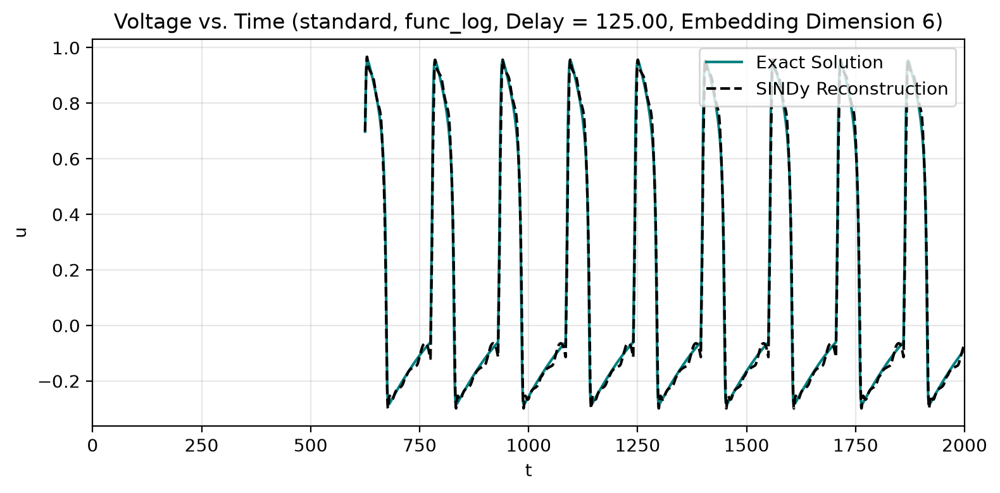

----------Fitting with function: func_log----------


c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)
c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)




Minimum MAE for tau=130.0 and n_embed=5: 3.04284e-01



----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 130.0000 (delay_idx = 2600)
Embedding dimension = 5
(u(t-0))' = -0.094 u(t-0) +  0.985 u(t-0)^2 + -0.785 u(t-0)^3 +  0.018 u(t-2600) + -0.096 u(t-2600)^2 +  0.193 u(t-2600)^3 +  0.260 u(t-5200) + -0.576 u(t-5200)^2 +  0.365 u(t-5200)^3 +  0.110 u(t-7800) + -0.361 u(t-7800)^2 +  0.242 u(t-7800)^3 + -0.042 u(t-10400) +  0.125 u(t-10400)^2 + -0.130 u(t-10400)^3 +  0.014 u(t-0)*u(t-2600) +  0.112 u(t-0)*u(t-5200) + -0.161 u(t-0)*u(t-7800) + -0.244 u(t-0)*u(t-10400) + -0.062 1 +  0.835 f_td(t)
(u(t-2600))' =  0.006 u(t-0) + -0.338 u(t-0)^2 +  0.125 u(t-0)^3 + -0.117 u(t-2600) +  1.091 u(t-2600)^2 + -1.005 u(t-2600)^3 +  0.196 u(t-5200) +  0.029 u(t-5200)^2 + -0.021 u(t-5200)^3 + -0.890 u(t-7800)^2 +  0.686 u(t-7800)^3 +  0.206 u(t-10400) + -0.196 u(t-10400)^3 +  0.038 u(t-0)*u(t-2600) + -0.029 u(t-0)*u(t-5200) + -0.994 u(t-0)*u(t-7800) + -0.033 1 + -0.259 f_t

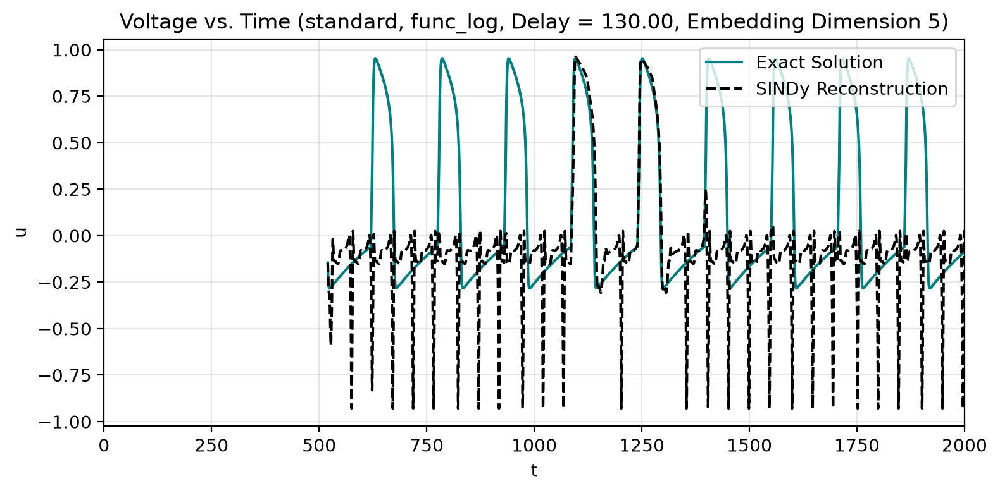

----------Fitting with function: func_log----------


Minimum MAE for tau=135.0 and n_embed=5: 3.62326e-02



----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 135.0000 (delay_idx = 2700)
Embedding dimension = 5
(u(t-0))' = -0.260 u(t-0) +  1.099 u(t-0)^2 + -1.013 u(t-0)^3 +  0.068 u(t-2700) + -0.039 u(t-2700)^2 +  0.127 u(t-5400) + -0.193 u(t-5400)^2 +  0.110 u(t-5400)^3 + -0.046 u(t-8100) +  0.006 u(t-8100)^2 + -0.054 u(t-10800) + -0.034 u(t-0)*u(t-2700) + -0.076 u(t-0)*u(t-5400) + -0.544 u(t-0)*u(t-8100) + -0.416 u(t-0)*u(t-10800) + -0.102 1 +  1.036 f_td(t)
(u(t-2700))' = -0.099 u(t-0) + -0.115 u(t-0)^2 +  0.045 u(t-0)^3 + -0.025 u(t-2700) +  1.254 u(t-2700)^2 + -1.322 u(t-2700)^3 +  0.106 u(t-5400) + -0.235 u(t-5400)^2 +  0.150 u(t-5400)^3 +  0.051 u(t-8100) + -0.040 u(t-8100)^3 + -0.136 u(t-10800) +  0.242 u(t-10800)^2 + -0.189 u(t-10800)^3 + -0.030 u(t-0)*u(t-2700) + -0.003 u(t-0)*u(t-5400) + -0.064 u(t-0)*u(t-8100) + -0.494 u(t-0)*u(t-10800) + -0.059 1

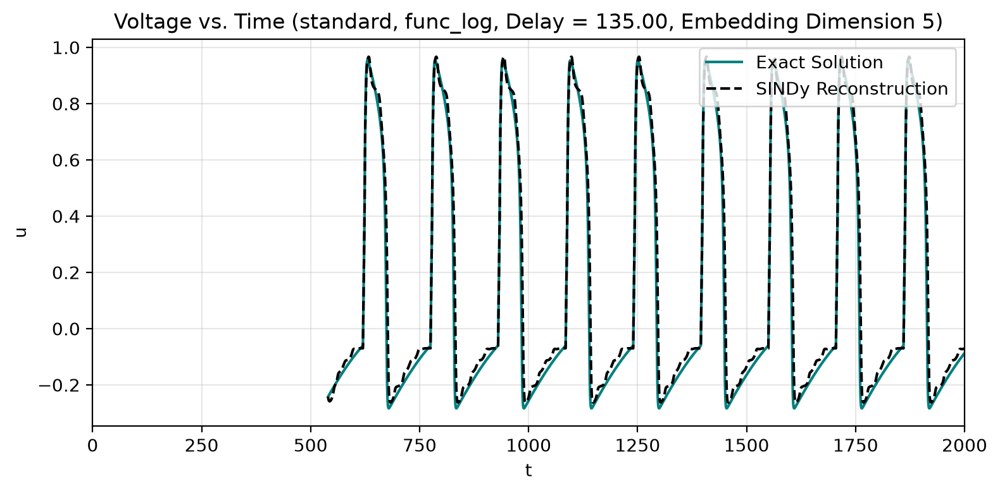

----------Fitting with function: func_log----------


Minimum MAE for tau=140.0 and n_embed=5: 4.86258e-02



----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 140.0000 (delay_idx = 2800)
Embedding dimension = 5
(u(t-0))' = -0.245 u(t-0) +  0.982 u(t-0)^2 + -0.860 u(t-0)^3 +  0.060 u(t-2800) + -0.225 u(t-2800)^2 +  0.170 u(t-2800)^3 +  0.079 u(t-5600) + -0.195 u(t-5600)^2 +  0.137 u(t-5600)^3 +  0.088 u(t-8400) + -0.066 u(t-8400)^2 + -0.049 u(t-11200) + -0.060 u(t-11200)^2 + -0.022 u(t-0)*u(t-2800) + -0.028 u(t-0)*u(t-5600) + -0.021 u(t-0)*u(t-8400) + -0.754 u(t-0)*u(t-11200) + -0.058 1 +  1.051 f_td(t)
(u(t-2800))' = -0.063 u(t-0) + -0.083 u(t-0)^2 + -0.078 u(t-0)^3 +  0.019 u(t-2800) +  1.148 u(t-2800)^2 + -1.263 u(t-2800)^3 +  0.069 u(t-5600) + -0.181 u(t-5600)^2 +  0.169 u(t-5600)^3 +  0.155 u(t-8400) + -0.366 u(t-8400)^2 +  0.202 u(t-8400)^3 + -0.004 u(t-11200) + -0.127 u(t-11200)^2 +  0.055 u(t-11200)^3 +  0.063 u(t-0)*u(t-5600) + -0.157 u(t-0)*u(t-8400)

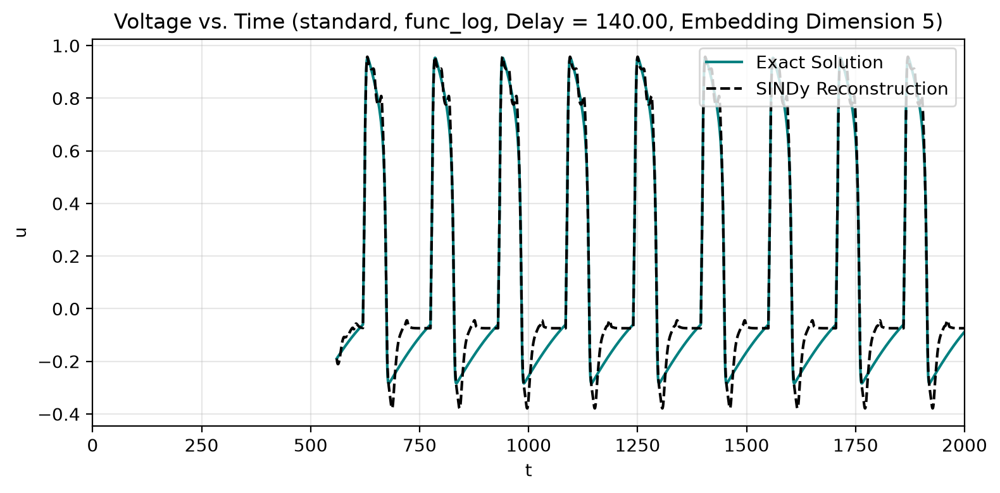

----------Fitting with function: func_log----------


Minimum MAE for tau=145.0 and n_embed=5: 4.07173e-02



----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 145.0000 (delay_idx = 2900)
Embedding dimension = 5
(u(t-0))' = -0.088 u(t-0) +  0.975 u(t-0)^2 + -0.944 u(t-0)^3 +  0.098 u(t-2900) + -0.384 u(t-2900)^2 +  0.295 u(t-2900)^3 +  0.105 u(t-5800) + -0.306 u(t-5800)^2 +  0.198 u(t-5800)^3 +  0.074 u(t-8700) + -0.085 u(t-8700)^2 +  0.032 u(t-11600) + -0.038 u(t-11600)^3 + -0.008 u(t-0)*u(t-2900) +  0.016 u(t-0)*u(t-8700) +  0.029 u(t-0)*u(t-11600) +  0.002 1 +  0.873 f_td(t)
(u(t-2900))' = -0.173 u(t-0)^2 +  0.099 u(t-0)^3 +  0.119 u(t-2900) +  0.853 u(t-2900)^2 + -1.094 u(t-2900)^3 +  0.076 u(t-5800) + -0.420 u(t-5800)^2 +  0.413 u(t-5800)^3 +  0.005 u(t-8700)^3 + -0.139 u(t-0)*u(t-2900) +  0.117 u(t-0)*u(t-5800) +  0.071 u(t-0)*u(t-8700) +  0.036 u(t-0)*u(t-11600) +  0.018 1 +  0.012 f_td(t)
(u(t-5800))' = -0.012 u(t-0) + -0.047 u(t-0)^3 +  0.100 u(t-2900

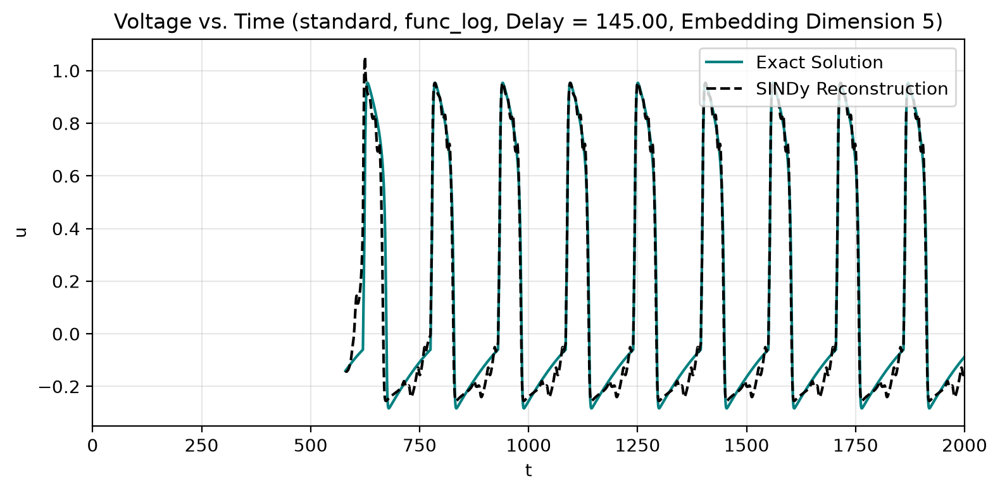

In [30]:
takens_td_models_fhn = []
delays = np.arange(125.0, 150.0, 5.0) # np.arange(1.0, 5.0, 1.0) # np.arange(4.0, 24.0, 4.0), np.arange(24.0, 26.0, 0.1)
n_embed_range = range(2,10)

# Test fit with fit_takens() method, which uses delay embeddings to reconstruct the dynamics, specifying the number of embedding
# dimensions with n_embed.
for tau_cur in delays:
    mae_min = np.inf
    best_n_embed = None

    best_gen_library_tk_fhn = None

    print(f'----------Fitting with function: {func_log.__name__}----------')
    for i in n_embed_range:
        cur_gen_library_tk_fhn = GenLibraryFit(
                    func_log,
                    func_log,
                    model_variant='standard',
                    ics=np.array([-0.1, 0]),
                    t_range=np.arange(0, 2000, 0.05),
                    color='teal',
                    tau=tau_cur
                )
        cur_gen_library_tk_fhn.fit_takens(printing=False, is_cubic=True, n_embed=i)
        mae_cur = cur_gen_library_tk_fhn.reconstruct_and_plot_takens(plotting=False, printing=False, end_time=2000)

        takens_td_models_fhn.append(cur_gen_library_tk_fhn)

        if mae_cur < mae_min:
            mae_min = mae_cur
            best_n_embed = i
            best_gen_library_tk_fhn = cur_gen_library_tk_fhn

    print(f'\n\nMinimum MAE for tau={tau_cur:.1f} and n_embed={best_n_embed}: {mae_min:.5e}\n\n')

    if best_gen_library_tk_fhn is not None and best_n_embed is not None:
        best_gen_library_tk_fhn.fit_takens(is_cubic=True, n_embed=best_n_embed)
        mae_cur = best_gen_library_tk_fhn.reconstruct_and_plot_takens(plotting=True, printing=True, end_time=2000)
    else:
        raise TypeError(f'Either best_gen_library_tk_fhn or best_n_embed is None for tau={tau_cur:.1f}.')

##### a2.) Test robustness of FHN identification across varying periods:

----------Fitting with stimulus of period 152.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.0000 (delay_idx = 80)
Embedding dimension = 3
(u(t-0))' =  0.270 u(t-0) +  0.603 u(t-0)^2 + -0.971 u(t-0)^3 + -0.188 u(t-80) + -0.572 u(t-80)^2 +  0.932 u(t-80)^3 + -0.153 u(t-160) +  0.016 u(t-160)^2 +  0.245 u(t-160)^3 +  0.238 u(t-0)*u(t-80) + -0.438 u(t-0)*u(t-160) + -0.002 1
(u(t-80))' =  0.102 u(t-0) + -0.301 u(t-0)^2 +  0.582 u(t-0)^3 + -0.068 u(t-80) +  0.557 u(t-80)^2 + -0.728 u(t-80)^3 + -0.003 u(t-160) + -0.235 u(t-160)^2 +  0.066 u(t-160)^3 + -0.255 u(t-0)*u(t-80) +  0.293 u(t-0)*u(t-160) +  0.003 1
(u(t-160))' =  0.063 u(t-0) + -0.195 u(t-0)^2 + -0.039 u(t-0)^3 +  0.229 u(t-80) + -0.702 u(t-80)^2 +  0.725 u(t-80)^3 + -0.288 u(t-160) +  0.706 u(t-160)^2 + -0.618 u(t-160)^3 +  0.324 u(t-0)*u(t-80) + -0.191 u(t-0)*u(t-160) + -0.002 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1']
inp

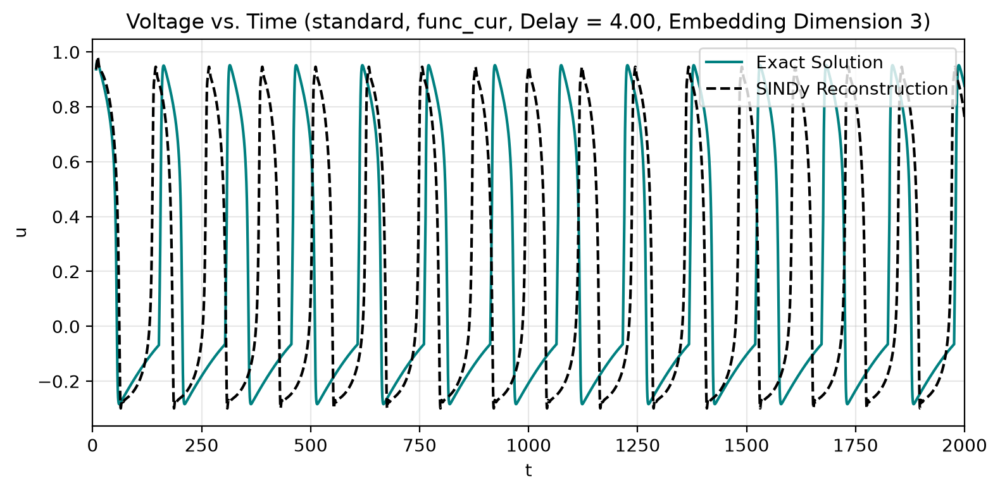

----------Fitting with stimulus of period 153.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.0000 (delay_idx = 80)
Embedding dimension = 3
(u(t-0))' =  0.271 u(t-0) +  0.615 u(t-0)^2 + -0.981 u(t-0)^3 + -0.188 u(t-80) + -0.575 u(t-80)^2 +  0.937 u(t-80)^3 + -0.154 u(t-160) +  0.016 u(t-160)^2 +  0.250 u(t-160)^3 +  0.233 u(t-0)*u(t-80) + -0.439 u(t-0)*u(t-160) + -0.002 1
(u(t-80))' =  0.064 u(t-0) + -0.172 u(t-0)^2 +  0.457 u(t-0)^3 +  0.510 u(t-80)^2 + -0.678 u(t-80)^3 + -0.032 u(t-160) + -0.310 u(t-160)^2 +  0.133 u(t-160)^3 + -0.272 u(t-0)*u(t-80) +  0.305 u(t-0)*u(t-160) +  0.004 1
(u(t-160))' =  0.064 u(t-0) + -0.198 u(t-0)^2 + -0.027 u(t-0)^3 +  0.225 u(t-80) + -0.701 u(t-80)^2 +  0.722 u(t-80)^3 + -0.283 u(t-160) +  0.711 u(t-160)^2 + -0.630 u(t-160)^3 +  0.311 u(t-0)*u(t-80) + -0.181 u(t-0)*u(t-160) + -0.002 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1']
inputs_per_libary:  

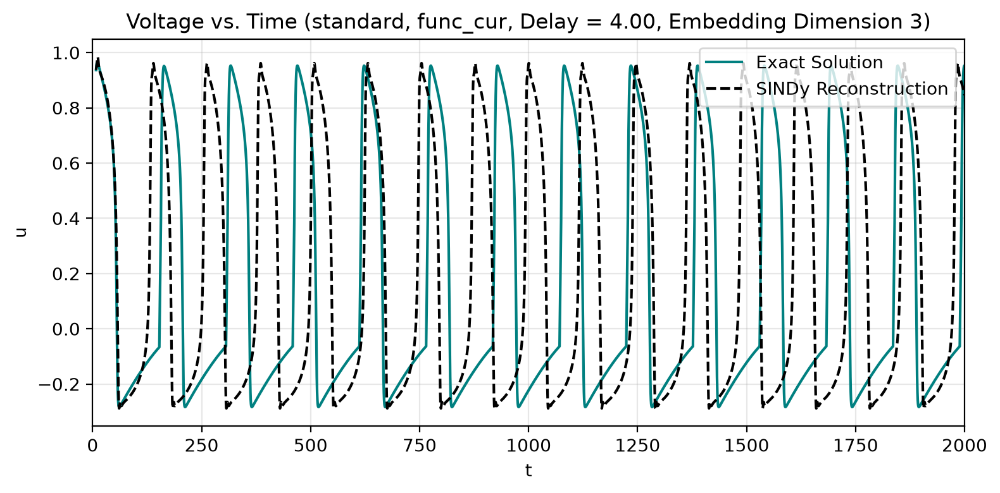

----------Fitting with stimulus of period 154.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.0000 (delay_idx = 80)
Embedding dimension = 3
(u(t-0))' =  0.263 u(t-0) +  0.645 u(t-0)^2 + -0.992 u(t-0)^3 + -0.180 u(t-80) + -0.576 u(t-80)^2 +  0.936 u(t-80)^3 + -0.153 u(t-160) +  0.003 u(t-160)^2 +  0.252 u(t-160)^3 +  0.205 u(t-0)*u(t-80) + -0.420 u(t-0)*u(t-160) + -0.002 1
(u(t-80))' =  0.064 u(t-0) + -0.182 u(t-0)^2 +  0.459 u(t-0)^3 +  0.509 u(t-80)^2 + -0.679 u(t-80)^3 + -0.033 u(t-160) + -0.308 u(t-160)^2 +  0.136 u(t-160)^3 + -0.257 u(t-0)*u(t-80) +  0.296 u(t-0)*u(t-160) +  0.004 1
(u(t-160))' =  0.064 u(t-0) + -0.201 u(t-0)^2 + -0.014 u(t-0)^3 +  0.221 u(t-80) + -0.699 u(t-80)^2 +  0.719 u(t-80)^3 + -0.278 u(t-160) +  0.716 u(t-160)^2 + -0.643 u(t-160)^3 +  0.298 u(t-0)*u(t-80) + -0.168 u(t-0)*u(t-160) + -0.001 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1']
inputs_per_libary:  

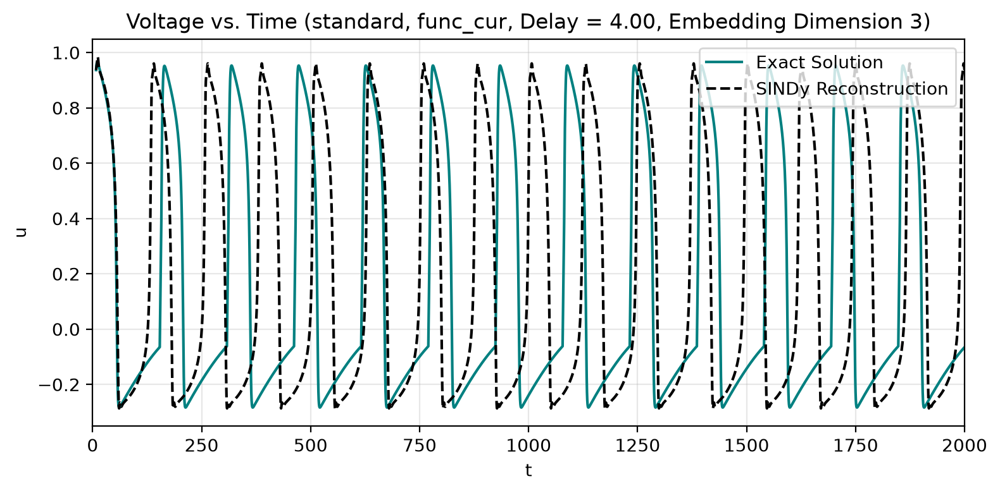

----------Fitting with stimulus of period 155.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.0000 (delay_idx = 80)
Embedding dimension = 3
(u(t-0))' =  0.264 u(t-0) +  0.651 u(t-0)^2 + -0.993 u(t-0)^3 + -0.181 u(t-80) + -0.579 u(t-80)^2 +  0.936 u(t-80)^3 + -0.153 u(t-160) +  0.004 u(t-160)^2 +  0.250 u(t-160)^3 +  0.198 u(t-0)*u(t-80) + -0.416 u(t-0)*u(t-160) + -0.002 1
(u(t-80))' =  0.065 u(t-0) + -0.189 u(t-0)^2 +  0.459 u(t-0)^3 +  0.508 u(t-80)^2 + -0.680 u(t-80)^3 + -0.035 u(t-160) + -0.306 u(t-160)^2 +  0.139 u(t-160)^3 + -0.245 u(t-0)*u(t-80) +  0.289 u(t-0)*u(t-160) +  0.004 1
(u(t-160))' =  0.064 u(t-0) + -0.203 u(t-0)^2 + -0.004 u(t-0)^3 +  0.217 u(t-80) + -0.698 u(t-80)^2 +  0.718 u(t-80)^3 + -0.274 u(t-160) +  0.720 u(t-160)^2 + -0.654 u(t-160)^3 +  0.286 u(t-0)*u(t-80) + -0.158 u(t-0)*u(t-160) + -0.001 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1']
inputs_per_libary:  

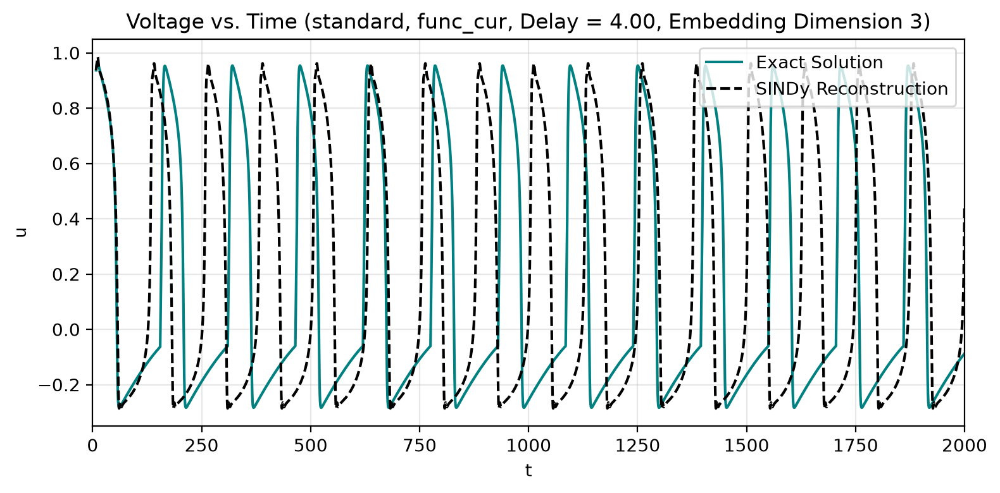

----------Fitting with stimulus of period 156.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.0000 (delay_idx = 80)
Embedding dimension = 3
(u(t-0))' =  0.265 u(t-0) +  0.657 u(t-0)^2 + -0.994 u(t-0)^3 + -0.181 u(t-80) + -0.582 u(t-80)^2 +  0.936 u(t-80)^3 + -0.152 u(t-160) +  0.005 u(t-160)^2 +  0.249 u(t-160)^3 +  0.191 u(t-0)*u(t-80) + -0.412 u(t-0)*u(t-160) + -0.002 1
(u(t-80))' =  0.066 u(t-0) + -0.197 u(t-0)^2 +  0.459 u(t-0)^3 +  0.508 u(t-80)^2 + -0.681 u(t-80)^3 + -0.036 u(t-160) + -0.304 u(t-160)^2 +  0.142 u(t-160)^3 + -0.232 u(t-0)*u(t-80) +  0.281 u(t-0)*u(t-160) +  0.004 1
(u(t-160))' =  0.065 u(t-0) + -0.205 u(t-0)^2 +  0.005 u(t-0)^3 +  0.214 u(t-80) + -0.697 u(t-80)^2 +  0.716 u(t-80)^3 + -0.270 u(t-160) +  0.723 u(t-160)^2 + -0.664 u(t-160)^3 +  0.275 u(t-0)*u(t-80) + -0.148 u(t-0)*u(t-160) + -0.001 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1']
inputs_per_libary:  

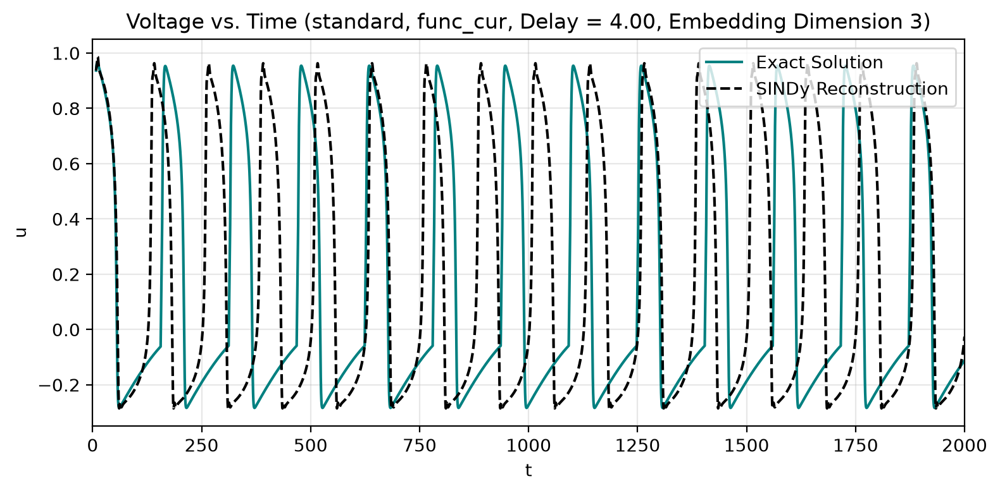

----------Fitting with stimulus of period 157.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.0000 (delay_idx = 80)
Embedding dimension = 3
(u(t-0))' =  0.265 u(t-0) +  0.662 u(t-0)^2 + -0.995 u(t-0)^3 + -0.182 u(t-80) + -0.585 u(t-80)^2 +  0.936 u(t-80)^3 + -0.151 u(t-160) +  0.006 u(t-160)^2 +  0.248 u(t-160)^3 +  0.184 u(t-0)*u(t-80) + -0.408 u(t-0)*u(t-160) + -0.002 1
(u(t-80))' =  0.067 u(t-0) + -0.203 u(t-0)^2 +  0.459 u(t-0)^3 +  0.508 u(t-80)^2 + -0.682 u(t-80)^3 + -0.038 u(t-160) + -0.303 u(t-160)^2 +  0.144 u(t-160)^3 + -0.220 u(t-0)*u(t-80) +  0.274 u(t-0)*u(t-160) +  0.003 1
(u(t-160))' =  0.065 u(t-0) + -0.207 u(t-0)^2 +  0.014 u(t-0)^3 +  0.211 u(t-80) + -0.696 u(t-80)^2 +  0.714 u(t-80)^3 + -0.266 u(t-160) +  0.727 u(t-160)^2 + -0.674 u(t-160)^3 +  0.265 u(t-0)*u(t-80) + -0.139 u(t-0)*u(t-160) + -0.001 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1']
inputs_per_libary:  

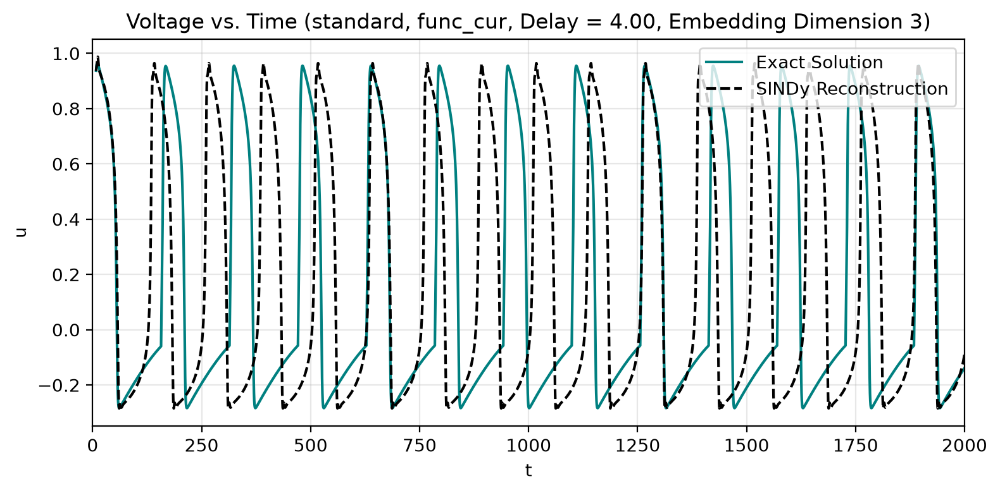

----------Fitting with stimulus of period 158.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.0000 (delay_idx = 80)
Embedding dimension = 3
(u(t-0))' =  0.266 u(t-0) +  0.668 u(t-0)^2 + -0.996 u(t-0)^3 + -0.183 u(t-80) + -0.587 u(t-80)^2 +  0.936 u(t-80)^3 + -0.151 u(t-160) +  0.007 u(t-160)^2 +  0.247 u(t-160)^3 +  0.178 u(t-0)*u(t-80) + -0.404 u(t-0)*u(t-160) + -0.002 1
(u(t-80))' =  0.067 u(t-0) + -0.210 u(t-0)^2 +  0.459 u(t-0)^3 +  0.507 u(t-80)^2 + -0.682 u(t-80)^3 + -0.040 u(t-160) + -0.301 u(t-160)^2 +  0.147 u(t-160)^3 + -0.209 u(t-0)*u(t-80) +  0.266 u(t-0)*u(t-160) +  0.003 1
(u(t-160))' =  0.066 u(t-0) + -0.209 u(t-0)^2 +  0.023 u(t-0)^3 +  0.208 u(t-80) + -0.694 u(t-80)^2 +  0.713 u(t-80)^3 + -0.262 u(t-160) +  0.731 u(t-160)^2 + -0.684 u(t-160)^3 +  0.255 u(t-0)*u(t-80) + -0.130 u(t-0)*u(t-160) + -0.001 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1']
inputs_per_libary:  

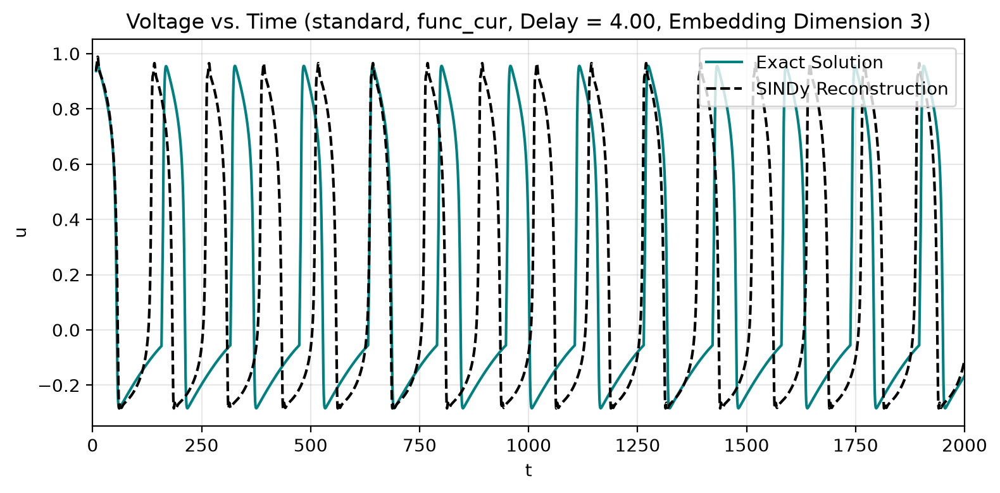

In [31]:
periods = np.arange(152.0, 159.0, 1.0)

# Test fit with fit_takens() method, which uses delay embeddings to reconstruct the dynamics, specifying the number of embedding
# dimensions with n_embed.
for period_cur in periods:
    def func_cur(t, period=period_cur):
        return logical_non_aut(t, period=period, dur=5.0, mag=0.12)

    print(f'----------Fitting with stimulus of period {period_cur}----------')
    cur_gen_library_tk_fhn = GenLibraryFit(
                func_cur,
                func_cur,
                model_variant='standard',
                ics=np.array([-0.1, 0]),
                t_range=np.arange(0, 2000, 0.05),
                color='teal',
                tau=4.0
            )
    cur_gen_library_tk_fhn.fit_takens(printing=True, is_cubic=True, n_embed=3)
    mae_cur = cur_gen_library_tk_fhn.reconstruct_and_plot_takens(plotting=True, printing=True, end_time=2000)

In [32]:
# Sanity check to make sure all parameters and intermediate variables are what we expect them to be.
# These values should stay fixed for a given run if the inputs are identical.
print(f'period_cur = {period_cur}')
print(f'tau = {cur_gen_library_tk_fhn.tau}')
print(f'dt = {cur_gen_library_tk_fhn.dt}')
print(f'delay_idx = {cur_gen_library_tk_fhn.takens_delay_idx}')
print(f'n_embed = {cur_gen_library_tk_fhn.takens_n_embed}')
print(f'takens_X_embedded shape = {cur_gen_library_tk_fhn.takens_X_embedded.shape}')
print(f'takens_t shape = {cur_gen_library_tk_fhn.takens_t.shape}')
print(f'embedded checksum = {np.sum(cur_gen_library_tk_fhn.takens_X_embedded):.8e}')
print(f'coeff checksum = {np.sum(cur_gen_library_tk_fhn.takens_model.coefficients()):.8e}')

period_cur = 158.0
tau = 4.0
dt = 0.05
delay_idx = 80
n_embed = 3
takens_X_embedded shape = (39840, 4)
takens_t shape = (39840,)
embedded checksum = 4.00160024e+07
coeff checksum = 1.00198540e+00


##### a3.) Test robustness of FHN identification across varying time delays:

In [20]:
# ---------------------------------------------------- Dim 2 ----------------------------------------------------
# Create a scatter plot of the MAE vs. time delay at a fixed embedding dimension, where tau varies from 0 to the stimulus period (which is 155).  This information
# can help diagnose sensitivity of the embedding + SINDy fit process to the size of tau.
time_delays_broad = np.arange(0.2, 5.1, 0.1) # np.arange(2., 150., 2.) # np.arange(148., 0., -2.)

# Test fit with fit_takens() method, which uses delay embeddings to reconstruct the dynamics, specifying the number of embedding
# dimensions with n_embed.
mae_vals = []
error_stats = []
for tau_cur in time_delays_broad:
    print(f'\n\n----------Fitting with tau = {tau_cur}----------')
    cur_gen_library_tk_fhn = GenLibraryFit(
                func_log,
                func_log,
                model_variant='standard',
                ics=np.array([-0.1, 0]),
                t_range=np.arange(0, 2000, 0.05),
                color='teal',
                tau=tau_cur
            )
    cur_gen_library_tk_fhn.fit_takens(printing=True, is_cubic=True, n_embed=2)
    mae_cur, error_stats_cur = cur_gen_library_tk_fhn.reconstruct_and_plot_takens(plotting=False, printing=True, end_time=2000)

    mae_vals.append(mae_cur)
    error_stats.append(error_stats_cur)



----------Fitting with tau = 0.2----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.2000 (delay_idx = 4)
Embedding dimension = 2
(u(t-0))' =  4.552 u(t-0) + -12.379 u(t-0)^2 + -0.271 u(t-0)^3 + -4.553 u(t-4) + -13.592 u(t-4)^2 +  0.268 u(t-4)^3 +  25.974 u(t-0)*u(t-4) +  0.179 f_td(t)
(u(t-4))' =  5.374 u(t-0) +  9.578 u(t-0)^2 +  0.243 u(t-0)^3 + -5.372 u(t-4) +  10.564 u(t-4)^2 + -0.242 u(t-4)^3 + -20.146 u(t-0)*u(t-4) + -0.163 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x0*x1', '1', 'f_td(x2)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [0, 1], [2]]
Takens reconstruction MAE (u): 1.65713e+00
Beat recall: 2.30769e-01 (3/13)
Beat F1: 3.75000e-01
Mean IBI (true/predicted): 1.55008e+02 / 4.64925e+02
IBI MAE: 3.09875e+02
APD90 MAE: 4.28725e+02
Activation time MAE: 4.33367e+02


----------Fitting with tau = 0.30000000000000004----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.3

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 2.44133e+00
Beat recall: 7.69231e-02 (1/13)
Beat F1: 1.42857e-01
Mean IBI (true/predicted): 1.55008e+02 / nan
IBI MAE: nan
APD90 MAE: 3.88500e+01
Activation time MAE: 6.22500e+01


----------Fitting with tau = 0.5000000000000001----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.5000 (delay_idx = 10)
Embedding dimension = 2
(u(t-0))' =  1.586 u(t-0) + -4.058 u(t-0)^2 + -0.284 u(t-0)^3 + -1.588 u(t-10) + -5.268 u(t-10)^2 +  0.278 u(t-10)^3 +  9.334 u(t-0)*u(t-10) +  0.399 f_td(t)
(u(t-10))' =  2.211 u(t-0) +  1.511 u(t-0)^2 +  0.343 u(t-0)^3 + -2.205 u(t-10) +  2.402 u(t-10)^2 + -0.344 u(t-10)^3 + -3.919 u(t-0)*u(t-10) +  0.001 1 + -0.239 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x0*x1', '1', 'f_td(x2)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [0, 1], [2]]
Takens reconstruction MAE (u): 7.31879e-02
Beat recall: 1.00000e+00 (13/13)
Beat F1: 1.00000e+00
Mean IBI (true/predicted): 1.

Tau values where MAE is above 1.0:  [0.2 0.4]
Minimum MAE:  0.01638607660191897
Tau value at which minimum MAE occurs:  1.8000000000000005
Tau values where MAE is above 1.0:  [0.2 0.4]
Minimum MAE:  0.01638607660191897
Tau value at which minimum MAE occurs:  1.8000000000000005


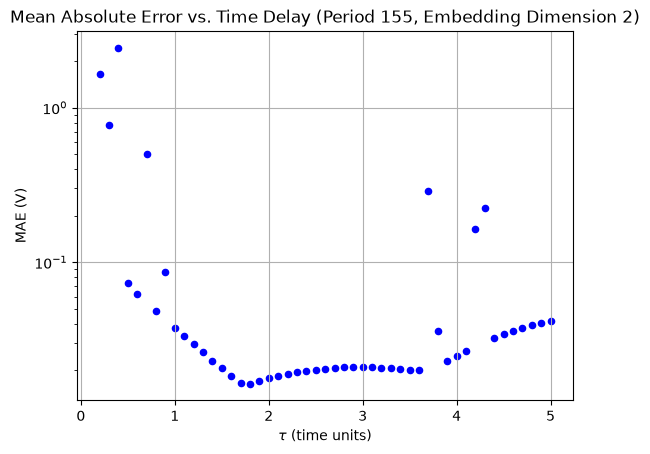

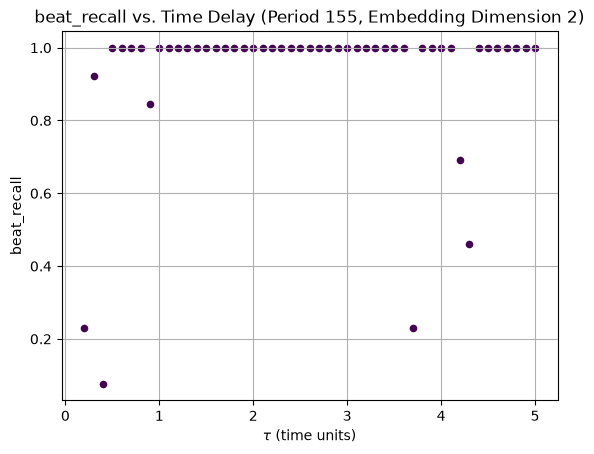

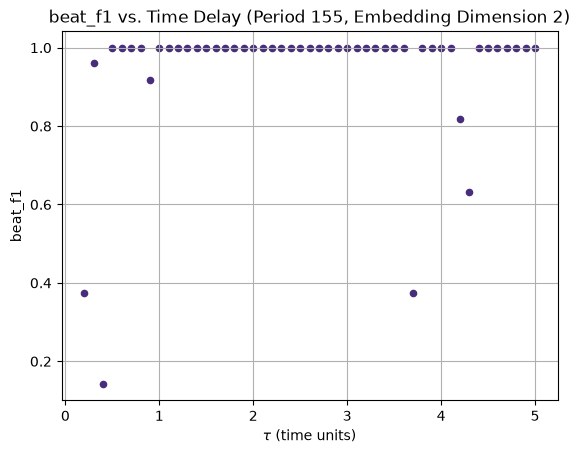

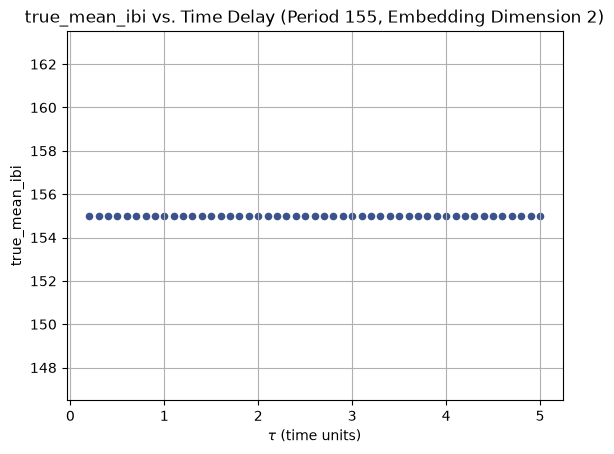

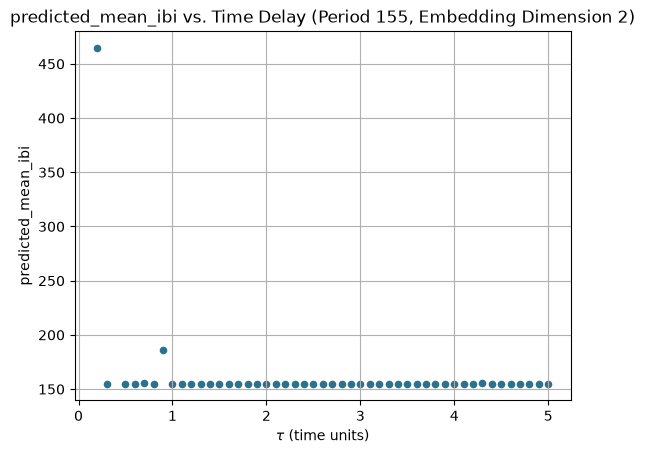

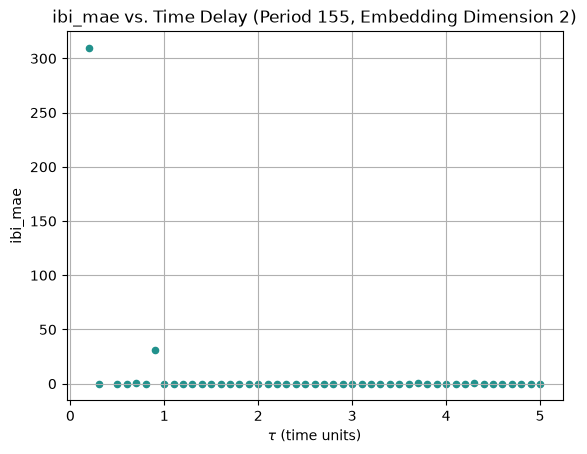

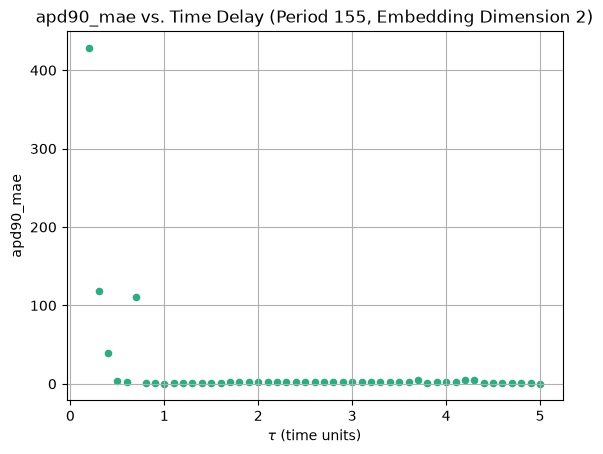

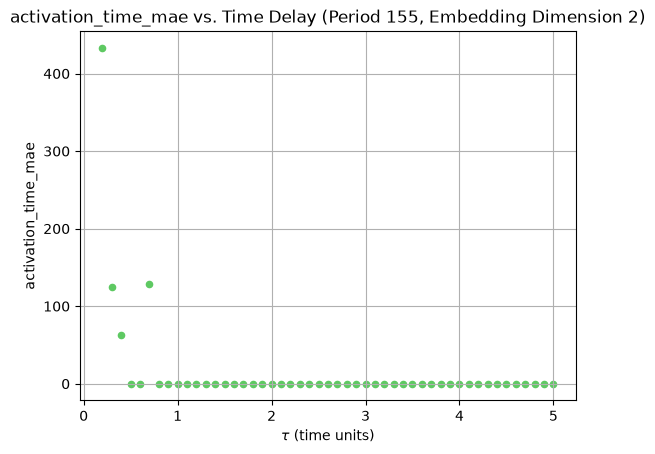

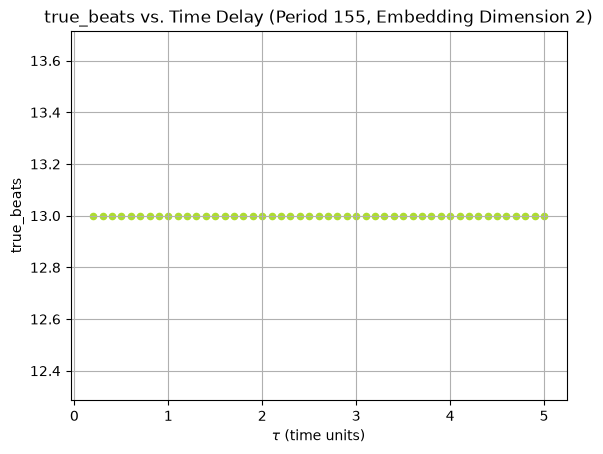

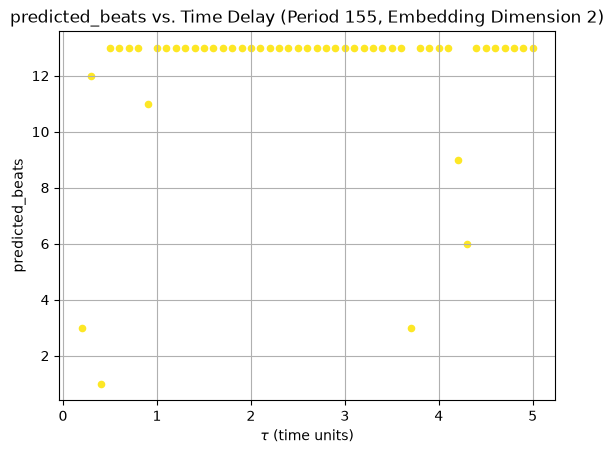

In [ ]:
mv = np.array(mae_vals)
tdb = np.array(time_delays_broad)
# print(mae_vals[:10])
print('Tau values where MAE is above 1.0: ', tdb[mv > 1.0])
print('Minimum MAE: ', np.min(mv))
print('Tau value at which minimum MAE occurs: ', tdb[np.argmin(mv)])

# Analyze MAE vs. time delay results
plt.figure()
plt.scatter(time_delays_broad, mae_vals, marker='o', s=20, color='blue')
plt.title(f'Mean Absolute Error vs. Time Delay (Period 155, Embedding Dimension 2)')
plt.ylabel('MAE (V)')
plt.yscale('log')
plt.xlabel(r'$\tau$ (time units)')
plt.grid()

# Analyze other statistics
stats = error_stats[0].keys()
colors = plt.colormaps['viridis'].resampled(len(stats))
for i, stat in enumerate(stats):
    stat_vals = [sub_dict[stat] for sub_dict in error_stats]
    plt.figure()
    plt.scatter(time_delays_broad, stat_vals, marker='o', s=20, color=colors(i))
    plt.title(f'{stat} vs. Time Delay (Period 155, Embedding Dimension 2)')
    plt.ylabel(f'{stat}')
    plt.xlabel(r'$\tau$ (time units)')
    plt.grid()

In [23]:
# ---------------------------------------------------- Dim 3 ----------------------------------------------------
# Create a scatter plot of the MAE vs. time delay at a fixed embedding dimension, where tau varies from 0 to the stimulus period (which is 155).  This information
# can help diagnose sensitivity of the embedding + SINDy fit process to the size of tau.
time_delays_broad = np.arange(0.2, 5.1, 0.1) # np.arange(2., 150., 2.) # np.arange(148., 0., -2.)

# Test fit with fit_takens() method, which uses delay embeddings to reconstruct the dynamics, specifying the number of embedding
# dimensions with n_embed.
mae_vals = []
error_stats = []
for tau_cur in time_delays_broad:
    print(f'\n\n----------Fitting with tau = {tau_cur}----------')
    cur_gen_library_tk_fhn = GenLibraryFit(
                func_log,
                func_log,
                model_variant='standard',
                ics=np.array([-0.1, 0]),
                t_range=np.arange(0, 2000, 0.05),
                color='teal',
                tau=tau_cur
            )
    cur_gen_library_tk_fhn.fit_takens(printing=True, is_cubic=True, n_embed=3)
    mae_cur, error_stats_cur = cur_gen_library_tk_fhn.reconstruct_and_plot_takens(plotting=False, printing=True, end_time=2000)

    mae_vals.append(mae_cur)
    error_stats.append(error_stats_cur)



----------Fitting with tau = 0.2----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.2000 (delay_idx = 4)
Embedding dimension = 3
(u(t-0))' =  4.610 u(t-0) +  40.357 u(t-0)^2 + -0.317 u(t-0)^3 + -4.686 u(t-4) +  58.584 u(t-4)^2 +  0.224 u(t-4)^3 +  0.076 u(t-8) + -18.433 u(t-8)^2 +  0.090 u(t-8)^3 + -115.898 u(t-0)*u(t-4) +  35.391 u(t-0)*u(t-8) +  0.143 f_td(t)
(u(t-4))' =  3.692 u(t-0) + -21.529 u(t-0)^2 + -0.265 u(t-0)^3 + -2.121 u(t-4) + -32.447 u(t-4)^2 +  0.657 u(t-4)^3 + -1.571 u(t-8) +  10.362 u(t-8)^2 + -0.390 u(t-8)^3 +  63.023 u(t-0)*u(t-4) + -19.410 u(t-0)*u(t-8) + -0.081 f_td(t)
(u(t-8))' = -27.653 u(t-0)^2 + -0.969 u(t-0)^3 +  5.132 u(t-4) + -40.749 u(t-4)^2 +  2.310 u(t-4)^3 + -5.129 u(t-8) +  11.347 u(t-8)^2 + -1.345 u(t-8)^3 +  77.156 u(t-0)*u(t-4) + -20.100 u(t-0)*u(t-8) + -0.045 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], 

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.80162e-01
Beat recall: 0.00000e+00 (0/13)
Beat F1: 0.00000e+00
Mean IBI (true/predicted): 1.55008e+02 / nan
IBI MAE: nan
APD90 MAE: nan
Activation time MAE: nan


----------Fitting with tau = 0.4000000000000001----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.4000 (delay_idx = 8)
Embedding dimension = 3
(u(t-0))' =  1.217 u(t-0) +  8.295 u(t-0)^2 + -0.093 u(t-0)^3 + -0.581 u(t-8) +  13.566 u(t-8)^2 + -0.382 u(t-8)^3 + -0.637 u(t-16) + -6.239 u(t-16)^2 +  0.468 u(t-16)^3 + -26.774 u(t-0)*u(t-8) +  11.158 u(t-0)*u(t-16) +  0.001 1 +  0.408 f_td(t)
(u(t-8))' =  2.019 u(t-0) + -6.549 u(t-0)^2 +  0.121 u(t-0)^3 + -1.300 u(t-8) + -9.722 u(t-8)^2 + -0.047 u(t-8)^3 + -0.719 u(t-16) +  3.479 u(t-16)^2 + -0.070 u(t-16)^3 +  19.187 u(t-0)*u(t-8) + -6.398 u(t-0)*u(t-16) + -0.129 f_td(t)
(u(t-16))' = -1.249 u(t-0) +  9.651 u(t-0)^2 + -0.191 u(t-0)^3 +  4.822 u(t-8) +  13.442 u(t-8)^2 +  0.395 u(t-8)^3 + -3.569 u(t-16) + -4.130

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 1.01043e+01
Beat recall: 7.69231e-02 (1/13)
Beat F1: 1.42857e-01
Mean IBI (true/predicted): 1.55008e+02 / nan
IBI MAE: nan
APD90 MAE: 3.88500e+01
Activation time MAE: 1.37500e+01


----------Fitting with tau = 0.8000000000000003----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.8000 (delay_idx = 16)
Embedding dimension = 3
(u(t-0))' =  0.269 u(t-0) +  0.185 u(t-0)^2 + -0.266 u(t-0)^3 +  0.144 u(t-16) + -0.253 u(t-16)^2 + -0.063 u(t-16)^3 + -0.415 u(t-32) + -1.353 u(t-32)^2 +  0.317 u(t-32)^3 + -0.861 u(t-0)*u(t-16) +  2.293 u(t-0)*u(t-32) +  0.001 1 +  0.706 f_td(t)
(u(t-16))' =  1.074 u(t-0) + -1.034 u(t-0)^2 +  0.084 u(t-0)^3 + -0.693 u(t-16) + -1.413 u(t-16)^2 + -0.382 u(t-32) +  0.872 u(t-32)^2 + -0.079 u(t-32)^3 +  3.053 u(t-0)*u(t-16) + -1.480 u(t-0)*u(t-32) + -0.001 1 + -0.212 f_td(t)
(u(t-32))' = -0.326 u(t-0) + -1.183 u(t-0)^2 +  0.255 u(t-0)^3 +  1.798 u(t-16) + -1.965 u(t-16)^2 + -1.465 u(t-32) +  0.474 u(

Tau values where MAE is above 1.0:  [0.7 0.8]
Minimum MAE:  0.008431928017902553
Tau value at which minimum MAE occurs:  3.9000000000000012


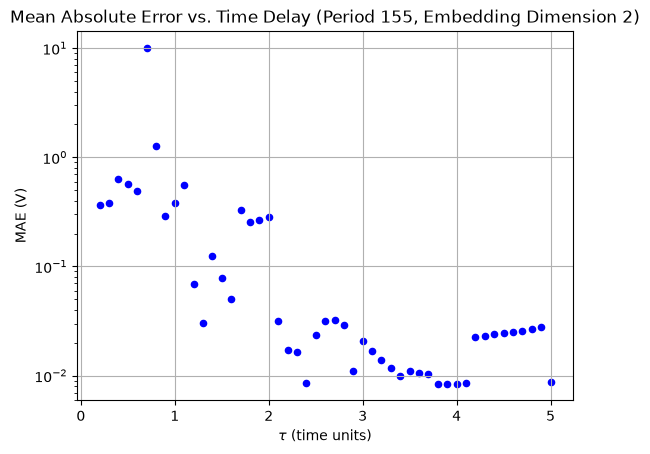

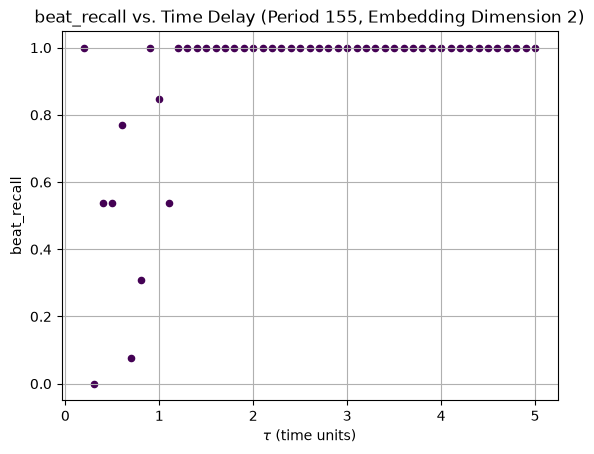

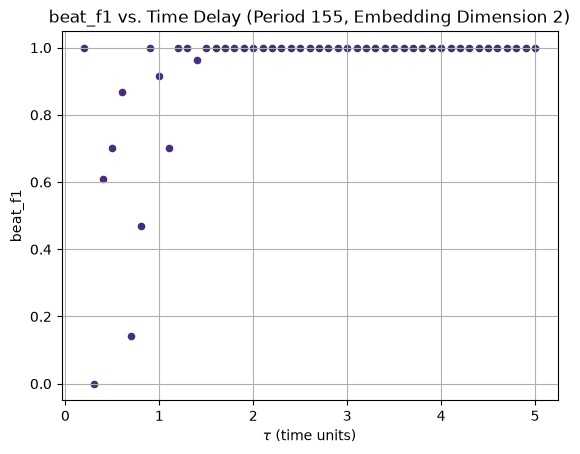

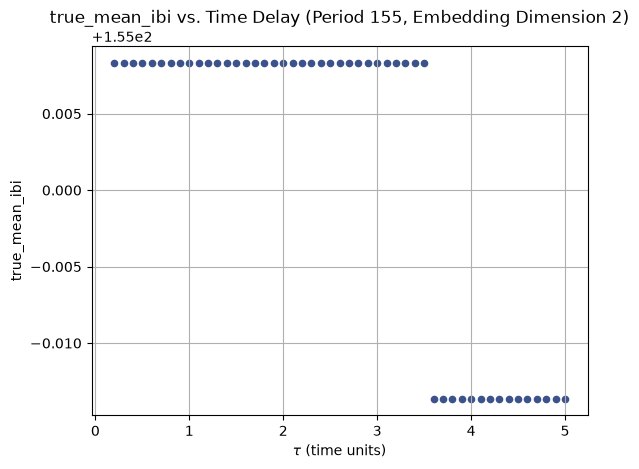

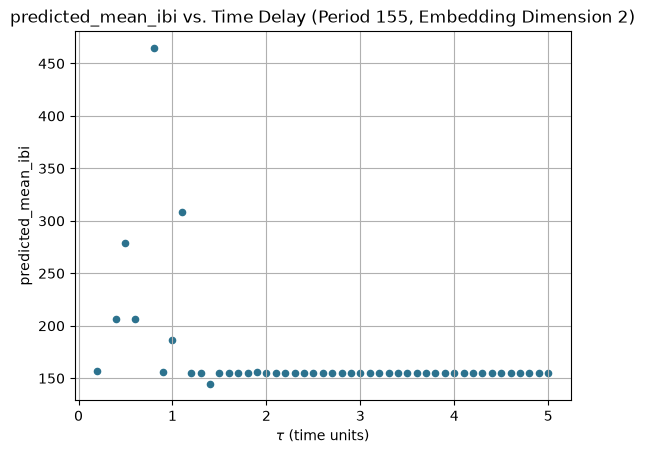

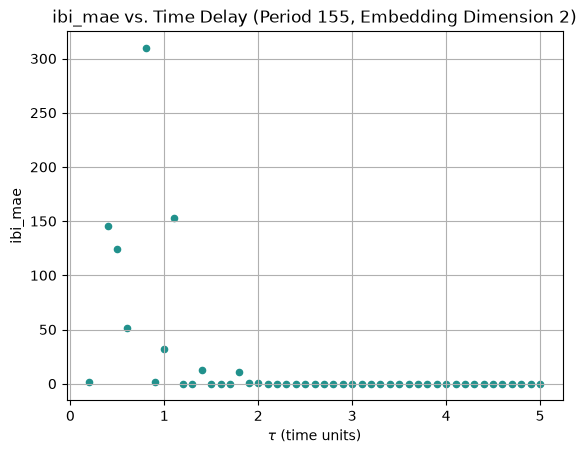

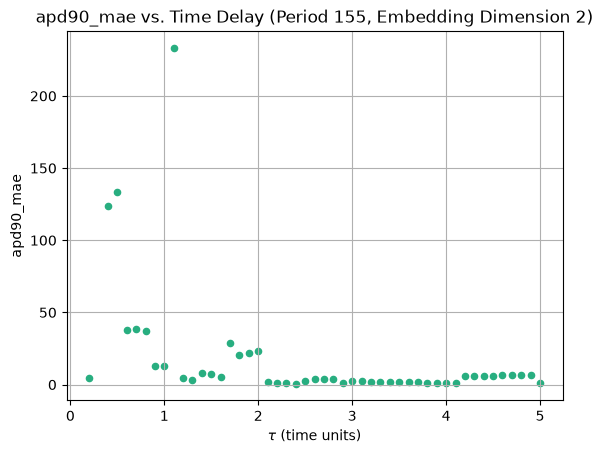

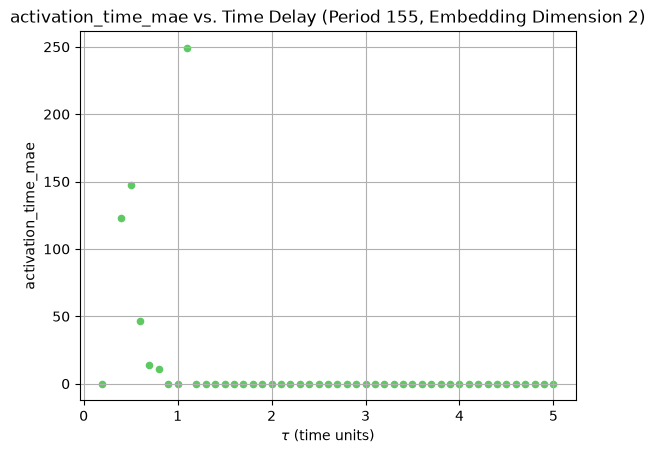

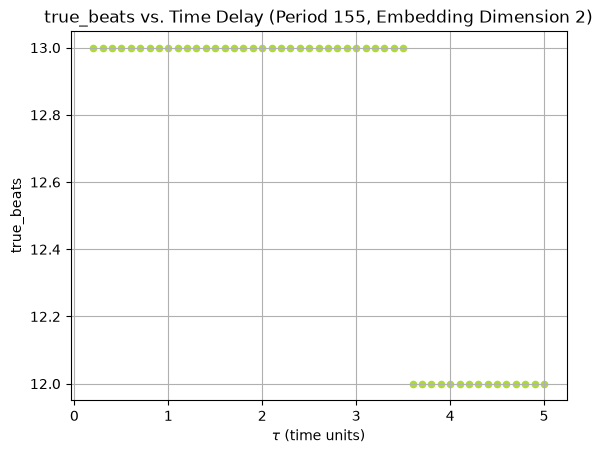

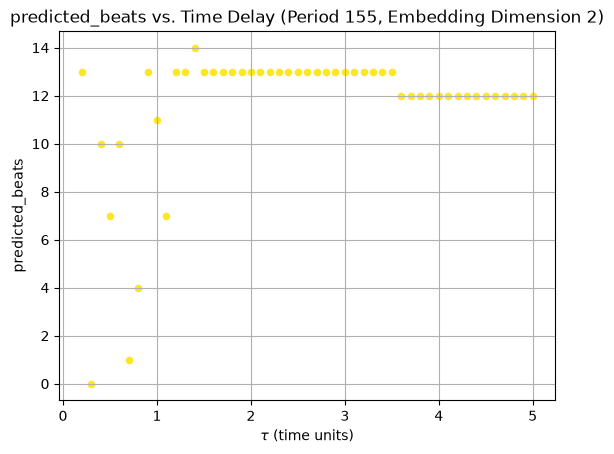

In [24]:
mv = np.array(mae_vals)
tdb = np.array(time_delays_broad)
# print(mae_vals[:10])
print('Tau values where MAE is above 1.0: ', tdb[mv > 1.0])
print('Minimum MAE: ', np.min(mv))
print('Tau value at which minimum MAE occurs: ', tdb[np.argmin(mv)])

# Analyze MAE vs. time delay results
plt.figure()
plt.scatter(time_delays_broad, mae_vals, marker='o', s=20, color='blue')
plt.title(f'Mean Absolute Error vs. Time Delay (Period 155, Embedding Dimension 2)')
plt.ylabel('MAE (V)')
plt.yscale('log')
plt.xlabel(r'$\tau$ (time units)')
plt.grid()

# Analyze other statistics
stats = error_stats[0].keys()
colors = plt.colormaps['viridis'].resampled(len(stats))
for i, stat in enumerate(stats):
    stat_vals = [sub_dict[stat] for sub_dict in error_stats]
    plt.figure()
    plt.scatter(time_delays_broad, stat_vals, marker='o', s=20, color=colors(i))
    plt.title(f'{stat} vs. Time Delay (Period 155, Embedding Dimension 2)')
    plt.ylabel(f'{stat}')
    plt.xlabel(r'$\tau$ (time units)')
    plt.grid()

In [37]:
# ---------------------------------------------------- Dim 4 ----------------------------------------------------
# Create a scatter plot of the MAE vs. time delay at a fixed embedding dimension, where tau varies from 0 to the stimulus period (which is 155).  This information
# can help diagnose sensitivity of the embedding + SINDy fit process to the size of tau.
time_delays_broad = np.arange(0.2, 5.1, 0.1) # np.arange(2., 150., 2.) # np.arange(148., 0., -2.)

# Test fit with fit_takens() method, which uses delay embeddings to reconstruct the dynamics, specifying the number of embedding
# dimensions with n_embed.
mae_vals = []
for tau_cur in time_delays_broad:
    print(f'\n\n----------Fitting with tau = {tau_cur}----------')
    cur_gen_library_tk_fhn = GenLibraryFit(
                func_log,
                func_log,
                model_variant='standard',
                ics=np.array([-0.1, 0]),
                t_range=np.arange(0, 2000, 0.05),
                color='teal',
                tau=tau_cur
            )
    cur_gen_library_tk_fhn.fit_takens(printing=True, is_cubic=True, n_embed=4)
    mae_cur = cur_gen_library_tk_fhn.reconstruct_and_plot_takens(plotting=False, printing=True, end_time=2000)

    mae_vals.append(mae_cur)



----------Fitting with tau = 0.2----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.2000 (delay_idx = 4)
Embedding dimension = 4
(u(t-0))' =  5.758 u(t-0) +  29.449 u(t-0)^2 + -4.424 u(t-0)^3 + -8.659 u(t-4) +  25.143 u(t-4)^2 +  13.111 u(t-4)^3 +  4.562 u(t-8) + -13.409 u(t-8)^3 + -1.662 u(t-12) + -4.553 u(t-12)^2 +  4.719 u(t-12)^3 + -74.046 u(t-0)*u(t-4) +  22.729 u(t-0)*u(t-8) +  1.279 u(t-0)*u(t-12) +  0.154 f_td(t)
(u(t-4))' =  2.570 u(t-0) + -5.325 u(t-0)^2 +  2.850 u(t-0)^3 +  1.552 u(t-4) +  5.551 u(t-4)^2 + -9.090 u(t-4)^3 + -5.564 u(t-8) + -9.128 u(t-8)^2 +  9.795 u(t-8)^3 +  1.444 u(t-12) +  4.403 u(t-12)^2 + -3.555 u(t-12)^3 +  6.600 u(t-0)*u(t-4) +  0.525 u(t-0)*u(t-8) + -2.626 u(t-0)*u(t-12) + -0.083 f_td(t)
(u(t-8))' = -1.080 u(t-0) +  2.597 u(t-0)^2 + -2.105 u(t-0)^3 +  4.433 u(t-4) + -5.023 u(t-4)^2 +  6.801 u(t-4)^3 + -0.793 u(t-8) +  5.561 u(t-8)^2 + -7.404 u(t-8)^3 + -2.561 u(t-12) + -2.563 u(t-12)^2 +  2.708 u(t-12)^3 + -3.3

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.67899e-01


----------Fitting with tau = 0.6000000000000001----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.6000 (delay_idx = 12)
Embedding dimension = 4
(u(t-0))' =  0.814 u(t-0) + -1.397 u(t-0)^2 + -0.827 u(t-0)^3 + -1.429 u(t-12) + -5.378 u(t-12)^2 +  1.726 u(t-12)^3 +  1.353 u(t-24) +  3.181 u(t-24)^2 + -1.886 u(t-24)^3 + -0.739 u(t-36) + -2.014 u(t-36)^2 +  0.973 u(t-36)^3 +  6.932 u(t-0)*u(t-12) + -3.975 u(t-0)*u(t-24) +  2.664 u(t-0)*u(t-36) +  0.001 1 +  0.661 f_td(t)
(u(t-12))' =  1.241 u(t-0) + -2.354 u(t-0)^2 +  0.535 u(t-0)^3 + -0.286 u(t-12) + -1.971 u(t-12)^2 + -1.315 u(t-12)^3 + -1.270 u(t-24) +  0.565 u(t-24)^2 +  1.320 u(t-24)^3 +  0.316 u(t-36) +  0.300 u(t-36)^2 + -0.536 u(t-36)^3 +  6.045 u(t-0)*u(t-12) + -2.589 u(t-0)*u(t-24) + -0.179 f_td(t)
(u(t-24))' = -0.503 u(t-0) +  3.564 u(t-0)^2 + -0.204 u(t-0)^3 +  2.078 u(t-12) +  5.758 u(t-12)^2 +  0.637 u(t-12)^3 + -1.008 u(t-24) + -3.641 u(t-24)^

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 2.65746e+00


----------Fitting with tau = 1.8000000000000005----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 1.8000 (delay_idx = 36)
Embedding dimension = 4
(u(t-0))' =  0.059 u(t-0) +  0.598 u(t-0)^2 + -0.585 u(t-0)^3 +  0.031 u(t-36) + -0.867 u(t-36)^2 +  0.509 u(t-36)^3 + -0.082 u(t-72) + -0.262 u(t-72)^2 + -0.013 u(t-108) + -0.094 u(t-108)^2 +  0.044 u(t-108)^3 +  0.228 u(t-0)*u(t-36) +  0.257 u(t-0)*u(t-72) +  0.172 u(t-0)*u(t-108) +  0.002 1 +  0.858 f_td(t)
(u(t-36))' =  0.515 u(t-0) + -1.134 u(t-0)^2 +  0.460 u(t-0)^3 + -0.221 u(t-36) + -0.940 u(t-36)^2 + -0.523 u(t-36)^3 + -0.371 u(t-72) +  0.692 u(t-72)^2 +  0.094 u(t-72)^3 +  0.078 u(t-108) + -0.055 u(t-108)^2 +  2.037 u(t-0)*u(t-36) + -0.435 u(t-0)*u(t-72) + -0.195 u(t-0)*u(t-108) + -0.001 1 + -0.167 f_td(t)
(u(t-72))' = -0.234 u(t-0) +  1.499 u(t-0)^2 + -0.581 u(t-0)^3 +  0.365 u(t-36) +  1.797 u(t-36)^2 +  0.272 u(t-36)^3 +  0.345 u(t-72) + -0.503 u(t-

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 6.86767e-01


----------Fitting with tau = 2.1000000000000005----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 2.1000 (delay_idx = 42)
Embedding dimension = 4
(u(t-0))' = -0.026 u(t-0) +  0.819 u(t-0)^2 + -0.770 u(t-0)^3 +  0.068 u(t-42) + -0.512 u(t-42)^2 +  0.392 u(t-42)^3 +  0.028 u(t-84) + -0.414 u(t-84)^2 +  0.270 u(t-84)^3 + -0.086 u(t-126) + -0.165 u(t-126)^2 +  0.078 u(t-126)^3 +  0.062 u(t-0)*u(t-42) +  0.074 u(t-0)*u(t-84) +  0.170 u(t-0)*u(t-126) +  0.001 1 +  0.920 f_td(t)
(u(t-42))' =  0.372 u(t-0) + -0.852 u(t-0)^2 +  0.336 u(t-0)^3 +  0.213 u(t-42) + -1.001 u(t-42)^2 + -0.150 u(t-42)^3 + -0.745 u(t-84) +  0.124 u(t-84)^2 +  0.092 u(t-84)^3 +  0.157 u(t-126) +  0.546 u(t-126)^2 + -0.222 u(t-126)^3 +  1.056 u(t-0)*u(t-42) +  0.843 u(t-0)*u(t-84) + -0.762 u(t-0)*u(t-126) + -0.003 1 + -0.101 f_td(t)
(u(t-84))' = -0.081 u(t-0) +  0.537 u(t-0)^2 +  0.176 u(t-0)^3 +  0.182 u(t-42) +  0.680 u(t-42)^2 +  0.099 u

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 1.13276e+00


----------Fitting with tau = 2.200000000000001----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 2.2000 (delay_idx = 44)
Embedding dimension = 4
(u(t-0))' = -0.029 u(t-0) +  0.815 u(t-0)^2 + -0.773 u(t-0)^3 +  0.081 u(t-44) + -0.545 u(t-44)^2 +  0.412 u(t-44)^3 +  0.003 u(t-88) + -0.403 u(t-88)^2 +  0.263 u(t-88)^3 + -0.072 u(t-132) + -0.140 u(t-132)^2 +  0.069 u(t-132)^3 +  0.074 u(t-0)*u(t-44) +  0.095 u(t-0)*u(t-88) +  0.139 u(t-0)*u(t-132) +  0.001 1 +  0.925 f_td(t)
(u(t-44))' =  0.304 u(t-0) + -0.531 u(t-0)^2 +  0.140 u(t-0)^3 +  0.257 u(t-44) + -0.672 u(t-44)^2 + -0.161 u(t-44)^3 + -0.649 u(t-88) + -0.107 u(t-88)^2 +  0.256 u(t-88)^3 +  0.076 u(t-132) +  0.522 u(t-132)^2 + -0.175 u(t-132)^3 +  0.600 u(t-0)*u(t-44) +  0.923 u(t-0)*u(t-88) + -0.781 u(t-0)*u(t-132) + -0.003 1 + -0.079 f_td(t)
(u(t-88))' =  0.060 u(t-0) + -0.095 u(t-0)^2 +  0.610 u(t-0)^3 +  0.082 u(t-44) + -0.039 u(t-44)^2 +  0.203 u(

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.68758e-01


----------Fitting with tau = 2.3000000000000007----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 2.3000 (delay_idx = 46)
Embedding dimension = 4
(u(t-0))' = -0.032 u(t-0) +  0.819 u(t-0)^2 + -0.779 u(t-0)^3 +  0.091 u(t-46) + -0.563 u(t-46)^2 +  0.429 u(t-46)^3 + -0.014 u(t-92) + -0.397 u(t-92)^2 +  0.260 u(t-92)^3 + -0.063 u(t-138) + -0.121 u(t-138)^2 +  0.062 u(t-138)^3 +  0.073 u(t-0)*u(t-46) +  0.109 u(t-0)*u(t-92) +  0.115 u(t-0)*u(t-138) +  0.001 1 +  0.928 f_td(t)
(u(t-46))' =  0.248 u(t-0) + -0.262 u(t-0)^2 + -0.003 u(t-0)^3 +  0.267 u(t-46) + -0.370 u(t-46)^2 + -0.222 u(t-46)^3 + -0.538 u(t-92) + -0.296 u(t-92)^2 +  0.405 u(t-92)^3 +  0.005 u(t-138) +  0.465 u(t-138)^2 + -0.122 u(t-138)^3 +  0.235 u(t-0)*u(t-46) +  0.943 u(t-0)*u(t-92) + -0.756 u(t-0)*u(t-138) + -0.004 1 + -0.062 f_td(t)
(u(t-92))' =  0.202 u(t-0) + -0.658 u(t-0)^2 +  0.909 u(t-0)^3 +  0.015 u(t-46) + -0.673 u(t-46)^2 +  0.370 u

Tau values where MAE is above 1.0:  [0.4 1.6 1.7 1.8 2.1]
Minimum MAE:  0.0031455459560618486
Tau value at which minimum MAE occurs:  1.2000000000000004


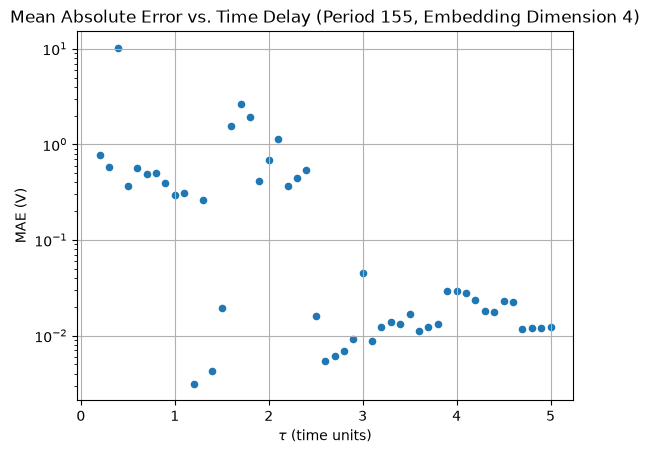

In [40]:
# Analyze MAE vs. time delay results
plt.scatter(time_delays_broad, mae_vals, marker='o', s=20)
plt.title(f'Mean Absolute Error vs. Time Delay (Period 155, Embedding Dimension 4)')
plt.ylabel('MAE (V)')
# plt.ylim(0, 5)
plt.yscale('log')
plt.xlabel(r'$\tau$ (time units)')
# plt.xlim(0, 150)
plt.grid()

mv = np.array(mae_vals)
tdb = np.array(time_delays_broad)
# print(mae_vals[:10])
print('Tau values where MAE is above 1.0: ', tdb[mv > 1.0])
print('Minimum MAE: ', np.min(mv))
print('Tau value at which minimum MAE occurs: ', tdb[np.argmin(mv)])

In [21]:
# ---------------------------------------------------- Dim 5 ----------------------------------------------------
# Create a scatter plot of the MAE vs. time delay at a fixed embedding dimension, where tau varies from 0 to the stimulus period (which is 155).  This information
# can help diagnose sensitivity of the embedding + SINDy fit process to the size of tau.
time_delays_broad = np.arange(0.2, 5.1, 0.1) # np.arange(2., 150., 2.) # np.arange(148., 0., -2.)

# Test fit with fit_takens() method, which uses delay embeddings to reconstruct the dynamics, specifying the number of embedding
# dimensions with n_embed.
mae_vals = []
for tau_cur in time_delays_broad:
    print(f'\n\n----------Fitting with tau = {tau_cur}----------')
    cur_gen_library_tk_fhn = GenLibraryFit(
                func_log,
                func_log,
                model_variant='standard',
                ics=np.array([-0.1, 0]),
                t_range=np.arange(0, 2000, 0.05),
                color='teal',
                tau=tau_cur
            )
    cur_gen_library_tk_fhn.fit_takens(printing=True, is_cubic=True, n_embed=5)
    mae_cur = cur_gen_library_tk_fhn.reconstruct_and_plot_takens(plotting=False, printing=True, end_time=2000)

    mae_vals.append(mae_cur)



----------Fitting with tau = 0.2----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.2000 (delay_idx = 4)
Embedding dimension = 5
(u(t-0))' =  6.521 u(t-0) +  12.275 u(t-0)^2 + -6.802 u(t-0)^3 + -10.985 u(t-4) + -12.936 u(t-4)^2 +  20.610 u(t-4)^3 +  6.847 u(t-8) +  16.439 u(t-8)^2 + -21.743 u(t-8)^3 + -2.333 u(t-12) + -1.632 u(t-12)^2 +  8.276 u(t-12)^3 + -0.050 u(t-16) + -3.504 u(t-16)^2 + -0.344 u(t-16)^3 + -13.621 u(t-0)*u(t-4) +  6.594 u(t-0)*u(t-8) + -10.689 u(t-0)*u(t-12) +  7.076 u(t-0)*u(t-16) +  0.149 f_td(t)
(u(t-4))' =  2.335 u(t-0) + -5.660 u(t-0)^2 +  3.476 u(t-0)^3 +  2.263 u(t-4) +  7.812 u(t-4)^2 + -11.894 u(t-4)^3 + -6.625 u(t-8) + -10.049 u(t-8)^2 +  14.552 u(t-8)^3 +  2.348 u(t-12) +  3.577 u(t-12)^2 + -7.176 u(t-12)^3 + -0.322 u(t-16) +  0.525 u(t-16)^2 +  1.044 u(t-16)^3 +  8.018 u(t-0)*u(t-4) + -7.020 u(t-0)*u(t-8) +  5.508 u(t-0)*u(t-12) + -2.713 u(t-0)*u(t-16) + -0.071 f_td(t)
(u(t-8))' = -1.069 u(t-0) +  7.259 u(t-0)^2 + 

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.36135e+00


----------Fitting with tau = 0.30000000000000004----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.3000 (delay_idx = 6)
Embedding dimension = 5
(u(t-0))' =  1.807 u(t-0) +  7.229 u(t-0)^2 +  1.574 u(t-0)^3 +  1.119 u(t-6) +  45.157 u(t-6)^2 + -8.986 u(t-6)^3 + -9.241 u(t-12) + -76.745 u(t-12)^2 +  17.463 u(t-12)^3 +  10.276 u(t-18) +  58.797 u(t-18)^2 + -15.387 u(t-18)^3 + -3.961 u(t-24) + -18.480 u(t-24)^2 +  5.329 u(t-24)^3 + -74.599 u(t-0)*u(t-6) +  120.380 u(t-0)*u(t-12) + -88.525 u(t-0)*u(t-18) +  26.792 u(t-0)*u(t-24) +  0.001 1 +  0.450 f_td(t)
(u(t-6))' =  2.378 u(t-0) + -9.066 u(t-0)^2 +  0.598 u(t-0)^3 + -0.572 u(t-6) + -12.905 u(t-6)^2 + -1.261 u(t-6)^3 + -2.354 u(t-12) +  6.637 u(t-12)^2 +  0.547 u(t-18) + -1.947 u(t-18)^2 +  1.561 u(t-18)^3 +  0.001 u(t-24) +  0.693 u(t-24)^2 + -0.897 u(t-24)^3 +  27.684 u(t-0)*u(t-6) + -11.928 u(t-0)*u(t-12) +  0.829 u(t-0)*u(t-18) + -0.143 f_td(t)
(u(t-12

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 5.15788e-01


----------Fitting with tau = 0.6000000000000001----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.6000 (delay_idx = 12)
Embedding dimension = 5
(u(t-0))' =  0.414 u(t-0) +  1.110 u(t-0)^2 + -0.430 u(t-0)^3 + -0.039 u(t-12) +  2.457 u(t-12)^2 +  0.220 u(t-12)^3 + -1.222 u(t-24) + -5.354 u(t-24)^2 +  1.717 u(t-36) +  3.694 u(t-36)^2 + -0.217 u(t-36)^3 + -0.874 u(t-48) + -1.805 u(t-48)^2 +  0.410 u(t-48)^3 + -6.288 u(t-0)*u(t-12) +  10.650 u(t-0)*u(t-24) + -7.506 u(t-0)*u(t-36) +  3.059 u(t-0)*u(t-48) +  0.001 1 +  0.750 f_td(t)
(u(t-12))' =  1.341 u(t-0) + -3.245 u(t-0)^2 +  0.501 u(t-0)^3 + -0.717 u(t-12) + -3.745 u(t-12)^2 + -1.634 u(t-12)^3 + -0.529 u(t-24) +  2.751 u(t-24)^2 +  2.214 u(t-24)^3 + -0.247 u(t-36) + -0.966 u(t-36)^2 + -1.326 u(t-36)^3 +  0.151 u(t-48) +  0.298 u(t-48)^2 +  0.254 u(t-48)^3 +  10.961 u(t-0)*u(t-12) + -9.001 u(t-0)*u(t-24) +  3.938 u(t-0)*u(t-36) + -0.998 u(t-0)*u(t-48) + -0

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 5.80842e-01


----------Fitting with tau = 0.8000000000000003----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.8000 (delay_idx = 16)
Embedding dimension = 5
(u(t-0))' =  0.223 u(t-0) +  0.848 u(t-0)^2 + -0.616 u(t-0)^3 + -0.182 u(t-16) +  0.279 u(t-16)^2 +  0.304 u(t-16)^3 + -0.195 u(t-32) + -1.128 u(t-32)^2 +  0.566 u(t-48) +  0.260 u(t-48)^2 +  0.122 u(t-48)^3 + -0.417 u(t-64) + -0.545 u(t-64)^2 +  0.167 u(t-64)^3 + -1.378 u(t-0)*u(t-16) +  1.963 u(t-0)*u(t-32) + -1.275 u(t-0)*u(t-48) +  0.998 u(t-0)*u(t-64) +  0.001 1 +  0.808 f_td(t)
(u(t-16))' =  1.041 u(t-0) + -2.464 u(t-0)^2 +  0.417 u(t-0)^3 + -0.595 u(t-16) + -2.735 u(t-16)^2 + -1.075 u(t-16)^3 + -0.404 u(t-32) +  1.780 u(t-32)^2 +  1.228 u(t-32)^3 + -0.117 u(t-48) + -0.472 u(t-48)^2 + -0.695 u(t-48)^3 +  0.073 u(t-64) +  0.126 u(t-64)^2 +  0.135 u(t-64)^3 +  7.399 u(t-0)*u(t-16) + -5.000 u(t-0)*u(t-32) +  1.825 u(t-0)*u(t-48) + -0.467 u(t-0)*u(t-64) + -0.0

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.47450e-01


----------Fitting with tau = 1.5000000000000004----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 1.5000 (delay_idx = 30)
Embedding dimension = 5
(u(t-0))' = -0.029 u(t-0) +  1.104 u(t-0)^2 + -0.871 u(t-0)^3 +  0.342 u(t-30)^3 +  0.162 u(t-60) + -0.498 u(t-60)^2 +  0.249 u(t-60)^3 + -0.073 u(t-90) + -0.361 u(t-90)^2 +  0.216 u(t-90)^3 + -0.076 u(t-120) + -0.081 u(t-120)^2 +  0.031 u(t-120)^3 + -0.520 u(t-0)*u(t-30) +  0.041 u(t-0)*u(t-60) +  0.234 u(t-0)*u(t-90) +  0.116 u(t-0)*u(t-120) +  0.001 1 +  0.898 f_td(t)
(u(t-30))' =  0.603 u(t-0) + -1.779 u(t-0)^2 +  0.814 u(t-0)^3 +  0.048 u(t-30) + -1.865 u(t-30)^2 + -0.417 u(t-30)^3 + -0.552 u(t-60) + -0.114 u(t-60)^2 +  0.353 u(t-60)^3 + -0.380 u(t-90) +  0.451 u(t-90)^2 + -0.546 u(t-90)^3 +  0.294 u(t-120) +  0.533 u(t-120)^2 + -0.158 u(t-120)^3 +  2.560 u(t-0)*u(t-30) +  0.310 u(t-0)*u(t-60) +  0.625 u(t-0)*u(t-90) + -0.764 u(t-0)*u(t-120) + -0.001 1 + -0

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 1.46574e+02


----------Fitting with tau = 2.3000000000000007----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 2.3000 (delay_idx = 46)
Embedding dimension = 5
(u(t-0))' =  0.010 u(t-0) +  0.694 u(t-0)^2 + -0.690 u(t-0)^3 + -0.009 u(t-46) + -0.617 u(t-46)^2 +  0.387 u(t-46)^3 + -0.096 u(t-92) +  0.005 u(t-92)^2 +  0.152 u(t-138) + -0.230 u(t-138)^2 +  0.177 u(t-138)^3 + -0.075 u(t-184) + -0.179 u(t-184)^2 +  0.083 u(t-184)^3 +  0.301 u(t-0)*u(t-46) + -0.014 u(t-0)*u(t-92) + -0.096 u(t-0)*u(t-138) +  0.183 u(t-0)*u(t-184) +  0.002 1 +  0.898 f_td(t)
(u(t-46))' =  0.152 u(t-0) +  0.163 u(t-0)^2 + -0.337 u(t-0)^3 +  0.358 u(t-46) +  0.054 u(t-46)^2 + -0.350 u(t-46)^3 + -0.334 u(t-92) + -0.842 u(t-92)^2 +  0.741 u(t-92)^3 + -0.234 u(t-138) +  0.486 u(t-138)^2 +  0.022 u(t-184) +  0.026 u(t-184)^2 +  0.030 u(t-184)^3 + -0.281 u(t-0)*u(t-46) +  1.145 u(t-0)*u(t-92) + -0.599 u(t-0)*u(t-138) + -0.216 u(t-0)*u(t-184) + -0.005 1

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.72484e-01


----------Fitting with tau = 2.400000000000001----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 2.4000 (delay_idx = 48)
Embedding dimension = 5
(u(t-0))' = -0.038 u(t-0) +  0.872 u(t-0)^2 + -0.821 u(t-0)^3 +  0.027 u(t-48) + -0.410 u(t-48)^2 +  0.327 u(t-48)^3 +  0.005 u(t-96) + -0.232 u(t-96)^2 +  0.203 u(t-96)^3 +  0.033 u(t-144) + -0.272 u(t-144)^2 +  0.197 u(t-144)^3 + -0.051 u(t-192) + -0.105 u(t-192)^2 +  0.053 u(t-192)^3 +  0.100 u(t-0)*u(t-48) + -0.028 u(t-0)*u(t-96) +  0.026 u(t-0)*u(t-144) +  0.096 u(t-0)*u(t-192) +  0.001 1 +  0.930 f_td(t)
(u(t-48))' =  0.134 u(t-0) +  0.256 u(t-0)^2 + -0.345 u(t-0)^3 +  0.353 u(t-48) +  0.149 u(t-48)^2 + -0.410 u(t-48)^3 + -0.251 u(t-96) + -0.989 u(t-96)^2 +  0.839 u(t-96)^3 + -0.310 u(t-144) +  0.464 u(t-144)^2 +  0.039 u(t-192) +  0.099 u(t-192)^2 + -0.002 u(t-192)^3 + -0.435 u(t-0)*u(t-48) +  1.151 u(t-0)*u(t-96) + -0.474 u(t-0)*u(t-144) + -0.283 u(t-0)*u

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 7.26217e-01


----------Fitting with tau = 4.200000000000002----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.2000 (delay_idx = 84)
Embedding dimension = 5
(u(t-0))' = -0.081 u(t-0) +  1.001 u(t-0)^2 + -0.915 u(t-0)^3 +  0.022 u(t-84) + -0.264 u(t-84)^2 +  0.260 u(t-84)^3 +  0.021 u(t-168) + -0.307 u(t-168)^2 +  0.284 u(t-168)^3 +  0.010 u(t-252) + -0.277 u(t-252)^2 +  0.235 u(t-252)^3 + -0.027 u(t-336) + -0.100 u(t-336)^2 +  0.077 u(t-336)^3 + -0.010 u(t-0)*u(t-84) + -0.020 u(t-0)*u(t-168) +  0.021 u(t-0)*u(t-252) +  0.034 u(t-0)*u(t-336) +  0.976 f_td(t)
(u(t-84))' =  0.069 u(t-0) + -0.091 u(t-0)^2 +  0.270 u(t-0)^3 +  0.698 u(t-84)^2 + -0.950 u(t-84)^3 +  0.027 u(t-168) + -0.434 u(t-168)^2 +  0.308 u(t-168)^3 + -0.065 u(t-252) + -0.142 u(t-252)^2 +  0.250 u(t-252)^3 + -0.033 u(t-336) + -0.003 u(t-336)^2 +  0.039 u(t-336)^3 + -0.149 u(t-0)*u(t-84) +  0.302 u(t-0)*u(t-168) + -0.043 u(t-0)*u(t-252) + -0.076 u(t-0)*u

Tau values where MAE is above 1.0:  [0.2 0.4 0.6 0.8 0.9 1.  1.2 1.3 2.2]
Minimum MAE:  0.0031046771380261106
Tau value at which minimum MAE occurs:  3.9000000000000012


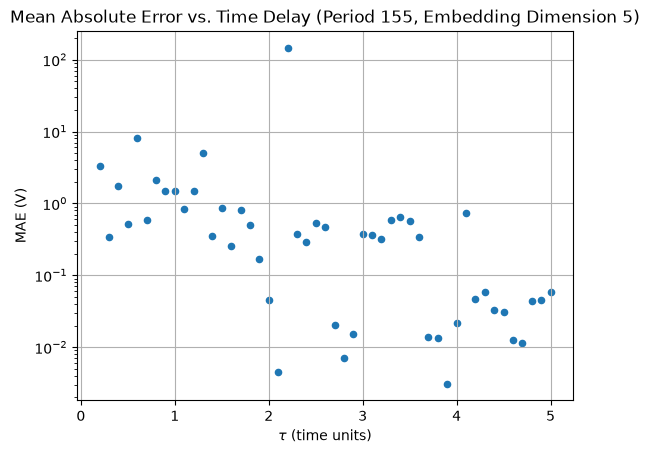

In [22]:
# Analyze MAE vs. time delay results
plt.scatter(time_delays_broad, mae_vals, marker='o', s=20)
plt.title(f'Mean Absolute Error vs. Time Delay (Period 155, Embedding Dimension 5)')
plt.ylabel('MAE (V)')
# plt.ylim(0, 5)
plt.yscale('log')
plt.xlabel(r'$\tau$ (time units)')
# plt.xlim(0, 150)
plt.grid()

mv = np.array(mae_vals)
tdb = np.array(time_delays_broad)
# print(mae_vals[:10])
print('Tau values where MAE is above 1.0: ', tdb[mv > 1.0])
print('Minimum MAE: ', np.min(mv))
print('Tau value at which minimum MAE occurs: ', tdb[np.argmin(mv)])

In [23]:
# ---------------------------------------------------- Dim 6 ----------------------------------------------------
# Create a scatter plot of the MAE vs. time delay at a fixed embedding dimension, where tau varies from 0 to the stimulus period (which is 155).  This information
# can help diagnose sensitivity of the embedding + SINDy fit process to the size of tau.
time_delays_broad = np.arange(0.2, 5.1, 0.1) # np.arange(2., 150., 2.) # np.arange(148., 0., -2.)

# Test fit with fit_takens() method, which uses delay embeddings to reconstruct the dynamics, specifying the number of embedding
# dimensions with n_embed.
mae_vals = []
for tau_cur in time_delays_broad:
    print(f'\n\n----------Fitting with tau = {tau_cur}----------')
    cur_gen_library_tk_fhn = GenLibraryFit(
                func_log,
                func_log,
                model_variant='standard',
                ics=np.array([-0.1, 0]),
                t_range=np.arange(0, 2000, 0.05),
                color='teal',
                tau=tau_cur
            )
    cur_gen_library_tk_fhn.fit_takens(printing=True, is_cubic=True, n_embed=6)
    mae_cur = cur_gen_library_tk_fhn.reconstruct_and_plot_takens(plotting=False, printing=True, end_time=2000)

    mae_vals.append(mae_cur)



----------Fitting with tau = 0.2----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.2000 (delay_idx = 4)
Embedding dimension = 6
(u(t-0))' =  5.626 u(t-0) +  1.666 u(t-0)^2 + -0.051 u(t-0)^3 + -8.425 u(t-4) + -0.295 u(t-4)^2 +  1.955 u(t-4)^3 +  5.215 u(t-8) +  10.604 u(t-8)^2 + -14.333 u(t-8)^3 + -4.888 u(t-12) + -21.229 u(t-12)^2 +  30.981 u(t-12)^3 +  4.113 u(t-16) +  19.603 u(t-16)^2 + -27.204 u(t-16)^3 + -1.642 u(t-20) + -7.468 u(t-20)^2 +  8.649 u(t-20)^3 + -4.399 u(t-0)*u(t-4) +  9.692 u(t-0)*u(t-8) + -18.722 u(t-0)*u(t-12) +  10.551 u(t-0)*u(t-16) +  0.182 f_td(t)
(u(t-4))' =  2.806 u(t-0) +  0.265 u(t-0)^2 + -0.183 u(t-0)^3 +  0.943 u(t-4) +  1.184 u(t-4)^2 + -2.017 u(t-4)^3 + -5.915 u(t-8) + -7.115 u(t-8)^2 +  11.142 u(t-8)^3 +  4.026 u(t-12) +  14.410 u(t-12)^2 + -19.898 u(t-12)^3 + -2.838 u(t-16) + -11.852 u(t-16)^2 +  15.541 u(t-16)^3 +  0.979 u(t-20) +  3.898 u(t-20)^2 + -4.585 u(t-20)^3 +  3.070 u(t-0)*u(t-4) + -9.308 u(t-0)*u(t-8)

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.63532e-01


----------Fitting with tau = 0.30000000000000004----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.3000 (delay_idx = 6)
Embedding dimension = 6
(u(t-0))' =  2.456 u(t-0) + -3.671 u(t-0)^2 + -0.190 u(t-0)^3 + -3.254 u(t-6) + -4.723 u(t-6)^2 +  0.346 u(t-6)^3 +  0.889 u(t-12) +  1.112 u(t-12)^2 + -3.871 u(t-12)^3 + -0.225 u(t-18) + -3.253 u(t-18)^2 +  10.199 u(t-18)^3 +  0.922 u(t-24) +  4.747 u(t-24)^2 + -10.229 u(t-24)^3 + -0.790 u(t-30) + -2.874 u(t-30)^2 +  3.739 u(t-30)^3 +  7.838 u(t-0)*u(t-6) +  6.795 u(t-0)*u(t-12) + -14.038 u(t-0)*u(t-18) +  8.072 u(t-0)*u(t-24) +  0.001 1 +  0.434 f_td(t)
(u(t-6))' =  1.937 u(t-0) +  0.017 u(t-0)^2 +  2.416 u(t-0)^3 +  0.840 u(t-6) +  10.784 u(t-6)^2 + -9.686 u(t-6)^3 + -3.906 u(t-12) + -7.939 u(t-12)^2 +  14.758 u(t-12)^3 +  1.470 u(t-18) +  3.470 u(t-18)^2 + -10.365 u(t-18)^3 + -0.595 u(t-24) + -0.280 u(t-24)^2 +  3.317 u(t-24)^3 +  0.254 u(t-30) +  0.116 u(t-

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.90866e-01


----------Fitting with tau = 0.4000000000000001----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.4000 (delay_idx = 8)
Embedding dimension = 6
(u(t-0))' =  0.528 u(t-0) +  10.269 u(t-0)^2 +  0.152 u(t-0)^3 +  0.354 u(t-8) +  19.739 u(t-8)^2 + -0.699 u(t-8)^3 + -5.437 u(t-16)^2 + -1.610 u(t-16)^3 + -4.450 u(t-24) + -17.123 u(t-24)^2 +  5.239 u(t-24)^3 +  6.239 u(t-32) +  19.763 u(t-32)^2 + -5.264 u(t-32)^3 + -2.674 u(t-40) + -7.561 u(t-40)^2 +  2.169 u(t-40)^3 + -38.328 u(t-0)*u(t-8) +  12.343 u(t-0)*u(t-16) +  25.815 u(t-0)*u(t-24) + -30.803 u(t-0)*u(t-32) +  11.334 u(t-0)*u(t-40) +  0.001 1 +  0.658 f_td(t)
(u(t-8))' =  1.455 u(t-0) +  0.593 u(t-0)^2 +  1.954 u(t-0)^3 +  1.109 u(t-8) +  13.435 u(t-8)^2 + -7.752 u(t-8)^3 + -4.382 u(t-16) + -16.039 u(t-16)^2 +  11.982 u(t-16)^3 +  2.599 u(t-24) +  10.703 u(t-24)^2 + -8.774 u(t-24)^3 + -0.976 u(t-32) + -2.633 u(t-32)^2 +  2.950 u(t-32)^3 +  0.193 u(t-40) 

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.95161e-01


----------Fitting with tau = 0.5000000000000001----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.5000 (delay_idx = 10)
Embedding dimension = 6
(u(t-0))' =  0.397 u(t-0) +  4.581 u(t-0)^2 + -0.435 u(t-0)^3 + -0.034 u(t-10) +  7.173 u(t-10)^2 +  0.411 u(t-10)^3 + -2.465 u(t-20)^2 + -1.114 u(t-20)^3 + -1.919 u(t-30) + -5.746 u(t-30)^2 +  1.854 u(t-30)^3 +  2.967 u(t-40) +  6.730 u(t-40)^2 + -1.546 u(t-40)^3 + -1.415 u(t-50) + -3.036 u(t-50)^2 +  0.813 u(t-50)^3 + -15.390 u(t-0)*u(t-10) +  5.928 u(t-0)*u(t-20) +  8.976 u(t-0)*u(t-30) + -11.587 u(t-0)*u(t-40) +  4.854 u(t-0)*u(t-50) +  0.001 1 +  0.729 f_td(t)
(u(t-10))' =  0.922 u(t-0) +  1.990 u(t-0)^2 +  2.732 u(t-0)^3 +  3.152 u(t-10) +  27.192 u(t-10)^2 + -10.896 u(t-10)^3 + -10.429 u(t-20) + -45.879 u(t-20)^2 +  18.877 u(t-20)^3 +  12.480 u(t-30) +  45.183 u(t-30)^2 + -17.237 u(t-30)^3 + -8.555 u(t-40) + -24.708 u(t-40)^2 +  8.540 u(t-40)^3 +  2.429 u

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 6.82785e-01


----------Fitting with tau = 0.6000000000000001----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.6000 (delay_idx = 12)
Embedding dimension = 6
(u(t-0))' =  0.355 u(t-0) +  2.098 u(t-0)^2 + -0.680 u(t-0)^3 + -0.371 u(t-12) +  1.720 u(t-12)^2 +  0.666 u(t-12)^3 +  0.354 u(t-24) + -0.825 u(t-24)^3 + -1.124 u(t-36) + -2.908 u(t-36)^2 +  0.965 u(t-36)^3 +  1.632 u(t-48) +  2.584 u(t-48)^2 + -0.543 u(t-48)^3 + -0.851 u(t-60) + -1.416 u(t-60)^2 +  0.396 u(t-60)^3 + -4.735 u(t-0)*u(t-12) +  0.757 u(t-0)*u(t-24) +  4.536 u(t-0)*u(t-36) + -4.992 u(t-0)*u(t-48) +  2.377 u(t-0)*u(t-60) +  0.001 1 +  0.764 f_td(t)
(u(t-12))' =  1.407 u(t-0) + -4.611 u(t-0)^2 +  0.741 u(t-0)^3 + -0.654 u(t-12) + -4.114 u(t-12)^2 + -2.362 u(t-12)^3 + -1.363 u(t-24) +  3.279 u(t-24)^3 +  1.600 u(t-36) +  3.283 u(t-36)^2 + -2.115 u(t-36)^3 + -1.570 u(t-48) + -2.899 u(t-48)^2 +  0.615 u(t-48)^3 +  0.579 u(t-60) +  1.077 u(t-60)^2 + -0.1

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 1.52713e+00


----------Fitting with tau = 0.8000000000000003----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 0.8000 (delay_idx = 16)
Embedding dimension = 6
(u(t-0))' =  0.239 u(t-0) +  0.904 u(t-0)^2 + -0.828 u(t-0)^3 + -0.422 u(t-16) + -0.218 u(t-16)^2 +  0.341 u(t-16)^3 +  0.269 u(t-32) +  0.239 u(t-32)^2 + -0.059 u(t-48) + -0.533 u(t-48)^2 +  0.314 u(t-48)^3 +  0.276 u(t-64) + -0.197 u(t-64)^2 + -0.314 u(t-80) + -0.278 u(t-80)^2 +  0.150 u(t-80)^3 +  0.116 u(t-0)*u(t-16) + -0.662 u(t-0)*u(t-32) +  0.256 u(t-0)*u(t-48) + -0.106 u(t-0)*u(t-64) +  0.503 u(t-0)*u(t-80) +  0.001 1 +  0.801 f_td(t)
(u(t-16))' =  1.155 u(t-0) + -3.587 u(t-0)^2 +  0.428 u(t-0)^3 + -0.935 u(t-16) + -4.852 u(t-16)^2 + -0.952 u(t-16)^3 +  3.464 u(t-32)^2 +  0.815 u(t-32)^3 + -0.177 u(t-48) + -1.439 u(t-48)^2 + -0.027 u(t-48)^3 + -0.177 u(t-64) +  0.288 u(t-64)^2 + -0.341 u(t-64)^3 +  0.133 u(t-80) +  0.125 u(t-80)^2 +  0.094 u(t-80)^3 +  1

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 2.36669e+02


----------Fitting with tau = 1.2000000000000004----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 1.2000 (delay_idx = 24)
Embedding dimension = 6
(u(t-0))' =  0.031 u(t-0) +  1.071 u(t-0)^2 + -0.915 u(t-0)^3 + -0.238 u(t-24) +  0.192 u(t-24)^2 +  0.187 u(t-48) +  0.051 u(t-48)^2 +  0.334 u(t-48)^3 +  0.107 u(t-72) + -0.278 u(t-72)^2 +  0.194 u(t-72)^3 +  0.094 u(t-96) + -0.455 u(t-96)^2 +  0.252 u(t-96)^3 + -0.201 u(t-120) + -0.235 u(t-120)^2 +  0.097 u(t-120)^3 +  0.099 u(t-0)*u(t-24) + -0.684 u(t-0)*u(t-48) + -0.139 u(t-0)*u(t-72) +  0.040 u(t-0)*u(t-96) +  0.381 u(t-0)*u(t-120) +  0.001 1 +  0.878 f_td(t)
(u(t-24))' =  0.519 u(t-0) + -0.349 u(t-0)^2 +  0.375 u(t-0)^3 +  0.114 u(t-24) +  0.247 u(t-24)^2 + -1.008 u(t-24)^3 + -1.271 u(t-48) + -0.528 u(t-48)^2 +  1.009 u(t-48)^3 +  1.469 u(t-72) +  1.148 u(t-72)^2 + -0.568 u(t-72)^3 + -1.135 u(t-96) + -1.620 u(t-96)^2 +  0.534 u(t-96)^3 +  0.300 u(t-120) +

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 4.29366e+01


----------Fitting with tau = 1.6000000000000003----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 1.6000 (delay_idx = 32)
Embedding dimension = 6
(u(t-0))' =  0.017 u(t-0) +  0.814 u(t-0)^2 + -0.820 u(t-0)^3 + -0.079 u(t-32) + -0.312 u(t-32)^2 +  0.284 u(t-32)^3 +  0.129 u(t-64) + -0.241 u(t-64)^2 +  0.176 u(t-64)^3 + -0.121 u(t-96) + -0.169 u(t-96)^2 +  0.173 u(t-96)^3 +  0.119 u(t-128) + -0.185 u(t-128)^2 +  0.091 u(t-128)^3 + -0.084 u(t-160) + -0.131 u(t-160)^2 +  0.060 u(t-160)^3 +  0.184 u(t-0)*u(t-32) + -0.076 u(t-0)*u(t-64) +  0.031 u(t-0)*u(t-96) + -0.061 u(t-0)*u(t-128) +  0.189 u(t-0)*u(t-160) +  0.001 1 +  0.884 f_td(t)
(u(t-32))' =  0.543 u(t-0) + -1.587 u(t-0)^2 +  0.766 u(t-0)^3 +  0.242 u(t-32) + -2.038 u(t-32)^2 + -0.145 u(t-32)^3 + -0.844 u(t-64) + -0.043 u(t-64)^2 +  0.088 u(t-64)^3 +  0.076 u(t-96) +  0.279 u(t-96)^2 + -0.211 u(t-96)^3 + -0.191 u(t-128) +  0.704 u(t-128)^2 + -0.390 u(t-

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 5.61757e-01


----------Fitting with tau = 2.1000000000000005----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 2.1000 (delay_idx = 42)
Embedding dimension = 6
(u(t-0))' = -0.015 u(t-0) +  0.872 u(t-0)^2 + -0.804 u(t-0)^3 + -0.069 u(t-42) + -0.292 u(t-42)^2 +  0.212 u(t-42)^3 + -0.021 u(t-84) +  0.030 u(t-84)^2 +  0.180 u(t-126) + -0.313 u(t-126)^2 +  0.271 u(t-126)^3 + -0.050 u(t-168) + -0.344 u(t-168)^2 +  0.232 u(t-168)^3 + -0.053 u(t-210) + -0.054 u(t-210)^2 +  0.031 u(t-210)^3 +  0.166 u(t-0)*u(t-42) + -0.129 u(t-0)*u(t-84) + -0.091 u(t-0)*u(t-126) +  0.179 u(t-0)*u(t-168) +  0.038 u(t-0)*u(t-210) +  0.001 1 +  0.901 f_td(t)
(u(t-42))' =  0.344 u(t-0) + -0.950 u(t-0)^2 +  0.481 u(t-0)^3 +  0.573 u(t-42) + -1.388 u(t-42)^2 +  0.565 u(t-42)^3 + -0.633 u(t-84) + -1.236 u(t-84)^2 +  1.003 u(t-84)^3 + -0.840 u(t-126) +  1.406 u(t-126)^2 + -1.269 u(t-126)^3 +  0.522 u(t-168) +  0.957 u(t-168)^2 + -0.680 u(t-168)^3 +  0.

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 1.47833e+03


----------Fitting with tau = 2.400000000000001----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 2.4000 (delay_idx = 48)
Embedding dimension = 6
(u(t-0))' =  0.003 u(t-0) +  0.714 u(t-0)^2 + -0.694 u(t-0)^3 +  0.005 u(t-48) + -0.617 u(t-48)^2 +  0.434 u(t-48)^3 + -0.119 u(t-96) + -0.009 u(t-96)^2 +  0.148 u(t-144) + -0.157 u(t-144)^2 +  0.142 u(t-144)^3 + -0.053 u(t-192) + -0.216 u(t-192)^2 +  0.084 u(t-192)^3 +  0.010 u(t-240)^2 + -0.016 u(t-240)^3 +  0.237 u(t-0)*u(t-48) +  0.040 u(t-0)*u(t-96) + -0.160 u(t-0)*u(t-144) +  0.184 u(t-0)*u(t-192) +  0.028 u(t-0)*u(t-240) +  0.002 1 +  0.903 f_td(t)
(u(t-48))' =  0.214 u(t-0) + -0.112 u(t-0)^2 + -0.057 u(t-0)^3 +  0.455 u(t-48) + -0.529 u(t-48)^2 + -0.587 u(t-96) + -0.830 u(t-96)^2 +  0.540 u(t-96)^3 + -0.183 u(t-144) +  0.978 u(t-144)^2 + -0.364 u(t-144)^3 +  0.088 u(t-192) +  0.013 u(t-192)^2 +  0.044 u(t-240)^2 + -0.020 u(t-240)^3 + -0.247 u(t-0)*u(t-48)

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 6.60722e-01


----------Fitting with tau = 2.700000000000001----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 2.7000 (delay_idx = 54)
Embedding dimension = 6
(u(t-0))' = -0.052 u(t-0) +  0.912 u(t-0)^2 + -0.827 u(t-0)^3 +  0.060 u(t-54) + -0.427 u(t-54)^2 +  0.385 u(t-54)^3 + -0.005 u(t-108) + -0.349 u(t-108)^2 +  0.270 u(t-108)^3 + -0.027 u(t-162) + -0.141 u(t-162)^2 +  0.113 u(t-162)^3 + -0.062 u(t-216)^2 +  0.013 u(t-216)^3 + -0.016 u(t-270)^2 +  0.001 u(t-270)^3 + -0.016 u(t-0)*u(t-54) +  0.076 u(t-0)*u(t-108) +  0.012 u(t-0)*u(t-162) +  0.024 u(t-0)*u(t-216) +  0.038 u(t-0)*u(t-270) +  0.001 1 +  0.939 f_td(t)
(u(t-54))' =  0.122 u(t-0) +  0.200 u(t-0)^2 + -0.067 u(t-0)^3 +  0.248 u(t-54) +  0.305 u(t-54)^2 + -0.520 u(t-54)^3 +  0.016 u(t-108) + -1.248 u(t-108)^2 +  0.946 u(t-108)^3 + -0.403 u(t-162) +  0.124 u(t-162)^2 +  0.003 u(t-162)^3 + -0.033 u(t-216) +  0.526 u(t-216)^2 + -0.261 u(t-216)^3 +  0.056 u(t-270

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 2.04504e+00


----------Fitting with tau = 2.9000000000000012----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 2.9000 (delay_idx = 58)
Embedding dimension = 6
(u(t-0))' = -0.067 u(t-0) +  0.965 u(t-0)^2 + -0.871 u(t-0)^3 +  0.049 u(t-58) + -0.336 u(t-58)^2 +  0.318 u(t-58)^3 +  0.026 u(t-116) + -0.359 u(t-116)^2 +  0.293 u(t-116)^3 + -0.018 u(t-174) + -0.221 u(t-174)^2 +  0.180 u(t-174)^3 + -0.021 u(t-232) + -0.072 u(t-232)^2 +  0.033 u(t-232)^3 + -0.004 u(t-290)^2 + -0.002 u(t-290)^3 + -0.034 u(t-0)*u(t-58) +  0.032 u(t-0)*u(t-116) +  0.034 u(t-0)*u(t-174) +  0.035 u(t-0)*u(t-232) +  0.016 u(t-0)*u(t-290) +  0.001 1 +  0.951 f_td(t)
(u(t-58))' =  0.083 u(t-0) +  0.395 u(t-0)^2 + -0.307 u(t-0)^3 +  0.136 u(t-58) +  0.848 u(t-58)^2 + -1.076 u(t-58)^3 +  0.185 u(t-116) + -1.049 u(t-116)^2 +  0.784 u(t-116)^3 + -0.256 u(t-174) + -0.465 u(t-174)^2 +  0.544 u(t-174)^3 + -0.202 u(t-232) +  0.268 u(t-232)^2 +  0.121 u(t-232)

Tau values where MAE is above 1.0:  [0.7 1.  1.1 1.5 2.1 2.2 2.3 2.8]
Minimum MAE:  0.04078853214688167
Tau value at which minimum MAE occurs:  4.800000000000002


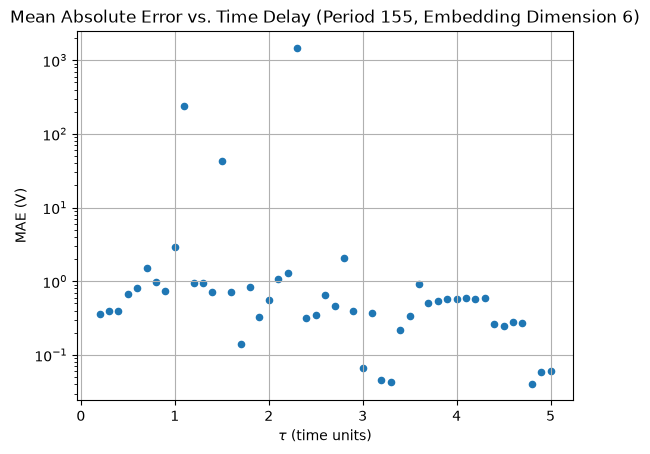

In [24]:
# Analyze MAE vs. time delay results
plt.scatter(time_delays_broad, mae_vals, marker='o', s=20)
plt.title(f'Mean Absolute Error vs. Time Delay (Period 155, Embedding Dimension 6)')
plt.ylabel('MAE (V)')
# plt.ylim(0, 5)
plt.yscale('log')
plt.xlabel(r'$\tau$ (time units)')
# plt.xlim(0, 150)
plt.grid()

mv = np.array(mae_vals)
tdb = np.array(time_delays_broad)
# print(mae_vals[:10])
print('Tau values where MAE is above 1.0: ', tdb[mv > 1.0])
print('Minimum MAE: ', np.min(mv))
print('Tau value at which minimum MAE occurs: ', tdb[np.argmin(mv)])

In [25]:
# TODO Something is different between the sweep code and individual case code; these are the same parameters as below
# but yield a much worse MAE.
print(tdb[-2], mv[-2])

4.900000000000002 0.05940405479097574


##### a4) Test $\tau=4$ in particular:



----------Fitting with tau = 4.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.0000 (delay_idx = 80)
Embedding dimension = 3
(u(t-0))' =  0.264 u(t-0) +  0.651 u(t-0)^2 + -0.993 u(t-0)^3 + -0.181 u(t-80) + -0.579 u(t-80)^2 +  0.936 u(t-80)^3 + -0.153 u(t-160) +  0.004 u(t-160)^2 +  0.250 u(t-160)^3 +  0.198 u(t-0)*u(t-80) + -0.416 u(t-0)*u(t-160) + -0.002 1
(u(t-80))' =  0.065 u(t-0) + -0.189 u(t-0)^2 +  0.459 u(t-0)^3 +  0.508 u(t-80)^2 + -0.680 u(t-80)^3 + -0.035 u(t-160) + -0.306 u(t-160)^2 +  0.139 u(t-160)^3 + -0.245 u(t-0)*u(t-80) +  0.289 u(t-0)*u(t-160) +  0.004 1
(u(t-160))' =  0.064 u(t-0) + -0.203 u(t-0)^2 + -0.004 u(t-0)^3 +  0.217 u(t-80) + -0.698 u(t-80)^2 +  0.718 u(t-80)^3 + -0.274 u(t-160) +  0.720 u(t-160)^2 + -0.654 u(t-160)^3 +  0.286 u(t-0)*u(t-80) + -0.158 u(t-0)*u(t-160) + -0.001 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1']
inputs_per_libary:  [[0], [0], [0

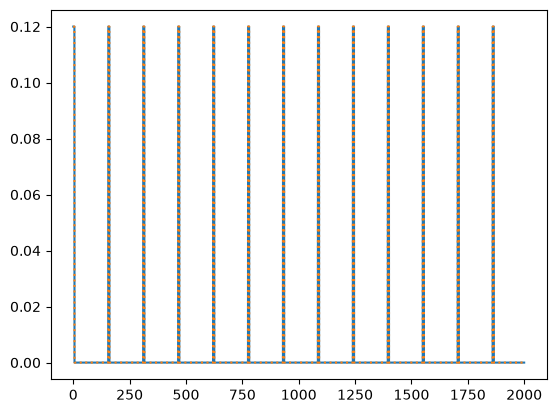

In [36]:
tau_cur = 4. # np.arange(2., 150., 2.)
period_cur = 155.0
t_func_comparison = np.arange(0,2000,0.05)

mae_vals = []

def func_cur(t, period=period_cur):
    return logical_non_aut(t, period=period, dur=5.0, mag=0.12)

plt.plot(t_func_comparison, func_cur(t_func_comparison), linestyle='-')
plt.plot(t_func_comparison, func_log(t_func_comparison), linestyle=':')

print(f'\n\n----------Fitting with tau = {tau_cur}----------')
cur_gen_library_tk_fhn = GenLibraryFit(
            func_cur,
            func_cur,
            model_variant='standard',
            ics=np.array([-0.1, 0]),
            t_range=np.arange(0, 2000, 0.05),
            color='teal',
            tau=tau_cur
        )
cur_gen_library_tk_fhn.fit_takens(printing=True, is_cubic=True, n_embed=3)
mae_cur = cur_gen_library_tk_fhn.reconstruct_and_plot_takens(plotting=False, printing=True, end_time=2000)

mae_vals.append(mae_cur)
print(mae_vals)

In [37]:
t_fit = np.arange(0, 2000, 0.05)

a = np.asarray(func_log(t_fit), dtype=float)
b = np.asarray(func_cur(t_fit), dtype=float)

print('Same shape:', a.shape == b.shape)
print('Exactly equal:', np.array_equal(a, b))
print('All close:', np.allclose(a, b, rtol=0, atol=0))
print('Maximum absolute difference:', np.max(np.abs(a - b)))
print('Number different:', np.count_nonzero(a != b))

idx = np.flatnonzero(a != b)
print('First mismatches:', list(zip(t_fit[idx[:20]], a[idx[:20]], b[idx[:20]])))

Same shape: True
Exactly equal: True
All close: True
Maximum absolute difference: 0.0
Number different: 0
First mismatches: []


##### (Cont.) Test $\tau=4$ with original stimulus function to show difference vs. func_cur:



----------Fitting with tau = 4.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.0000 (delay_idx = 80)
Embedding dimension = 3
(u(t-0))' = -0.032 u(t-0) +  0.785 u(t-0)^2 + -0.736 u(t-0)^3 +  0.074 u(t-80) + -0.638 u(t-80)^2 +  0.527 u(t-80)^3 + -0.072 u(t-160) + -0.265 u(t-160)^2 +  0.195 u(t-160)^3 +  0.052 u(t-0)*u(t-80) +  0.097 u(t-0)*u(t-160) +  0.968 f_td(t)
(u(t-80))' =  0.132 u(t-0) + -0.333 u(t-0)^2 +  0.549 u(t-0)^3 + -0.089 u(t-80) +  0.558 u(t-80)^2 + -0.686 u(t-80)^3 + -0.018 u(t-160) + -0.207 u(t-160)^2 +  0.085 u(t-160)^3 + -0.197 u(t-0)*u(t-80) +  0.217 u(t-0)*u(t-160) +  0.002 1 + -0.090 f_td(t)
(u(t-160))' =  0.064 u(t-0) + -0.203 u(t-0)^2 + -0.004 u(t-0)^3 +  0.217 u(t-80) + -0.698 u(t-80)^2 +  0.718 u(t-80)^3 + -0.274 u(t-160) +  0.720 u(t-160)^2 + -0.654 u(t-160)^3 +  0.286 u(t-0)*u(t-80) + -0.158 u(t-0)*u(t-160) + -0.001 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2'

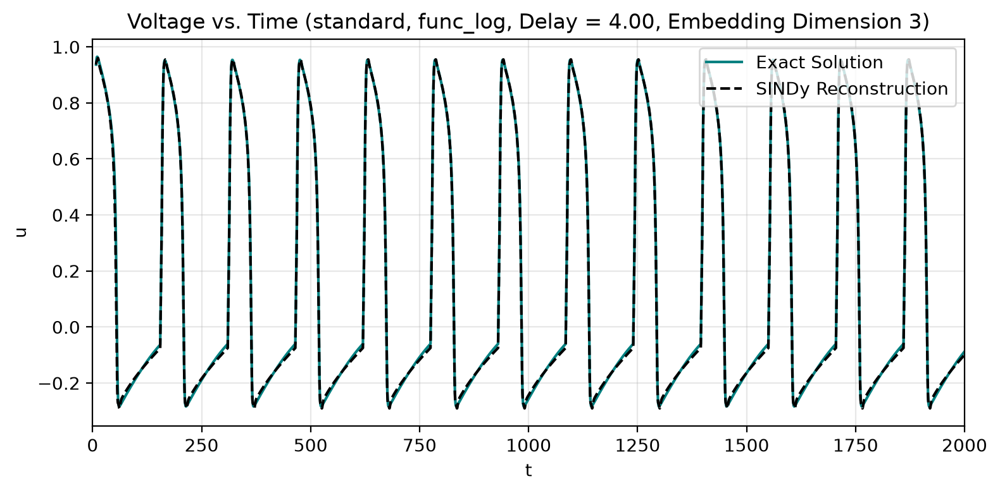

[0.008462802120273841]


In [26]:
tau_cur = 4. # np.arange(2., 150., 2.)
period_cur = 155.0

mae_vals = []

print(f'\n\n----------Fitting with tau = {tau_cur}----------')
cur_gen_library_tk_fhn = GenLibraryFit(
            func_log,
            func_log,
            model_variant='standard',
            ics=np.array([-0.1, 0]),
            t_range=np.arange(0, 2000, 0.05),
            color='teal',
            tau=tau_cur
        )
cur_gen_library_tk_fhn.fit_takens(printing=True, is_cubic=True, n_embed=3)
mae_cur = cur_gen_library_tk_fhn.reconstruct_and_plot_takens(plotting=True, printing=True, end_time=2000)

mae_vals.append(mae_cur)
print(mae_vals)

##### a5.) Do the same tests, but with FHN given a stimulus of changing period:

In [39]:
'''
    Function that defines stimulus with 3 sets of stim_count pulses, each with decreasing period.
    Params:
        t (array): Time values
        dur (float): Duration of each pulse
        mag (float): Magnitude of the stimulus
        stim_count (int): Number of stimuli of each period to generate
        periods (array): Array of periods for each set of pulses
'''
def func_pacedown(t):
    dur=5.0
    mag=0.12
    stim_count=3
    periods = np.array([305., 230., 155.])
    
    period_0_multiple = np.minimum(np.floor(t / periods[0]), stim_count)
    period_1_multiple = np.minimum(np.floor((t - period_0_multiple * periods[0]) / periods[1]), stim_count)
    period_2_multiple = np.minimum(np.floor((t - period_0_multiple * periods[0] - period_1_multiple * periods[1]) / periods[2]), stim_count)

    local_t_0 = t
    local_t_1 = t - stim_count * periods[0]
    local_t_2 = t - stim_count * periods[0] - stim_count * periods[1]

    is_stim = np.zeros_like(t, dtype=bool)

    mask_0 = period_0_multiple < stim_count
    mask_1 = (~mask_0) & (period_1_multiple < stim_count)
    mask_2 = (~mask_0) & (~mask_1) & (period_2_multiple < stim_count)

    stim_0 = np.mod(local_t_0, periods[0]) <= dur
    stim_1 = np.mod(local_t_1, periods[1]) <= dur
    stim_2 = np.mod(local_t_2, periods[2]) <= dur

    # Use np.where to allow both scalar and array t to work.
    is_stim = np.where(
        mask_0,
        stim_0,
        np.where(mask_1,
                 stim_1,
                 np.where(mask_2,
                          stim_2,
                          False))
    )

    stimulus = mag * is_stim
    return stimulus



----------Fitting with tau = 2.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 2.0000 (delay_idx = 40)
Embedding dimension = 3
(u(t-0))' =  0.686 u(t-0)^2 + -0.709 u(t-0)^3 +  0.173 u(t-40) + -0.928 u(t-40)^2 +  0.550 u(t-40)^3 + -0.185 u(t-80) + -0.322 u(t-80)^2 +  0.135 u(t-80)^3 +  0.201 u(t-0)*u(t-40) +  0.392 u(t-0)*u(t-80) +  0.920 f_td(t)
(u(t-40))' =  0.389 u(t-0) + -0.445 u(t-0)^2 +  0.252 u(t-0)^3 + -0.175 u(t-40) +  0.200 u(t-40)^2 + -0.420 u(t-40)^3 + -0.216 u(t-80) +  0.015 u(t-80)^2 +  0.191 u(t-80)^3 +  0.507 u(t-0)*u(t-40) + -0.296 u(t-0)*u(t-80) + -0.148 f_td(t)
(u(t-80))' =  0.002 u(t-0) + -0.061 u(t-0)^2 +  0.247 u(t-0)^3 +  0.414 u(t-40) + -0.636 u(t-40)^2 +  0.525 u(t-40)^3 + -0.393 u(t-80) +  0.575 u(t-80)^2 + -0.814 u(t-80)^3 + -0.247 u(t-0)*u(t-40) +  0.398 u(t-0)*u(t-80) +  0.001 1 + -0.066 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inpu

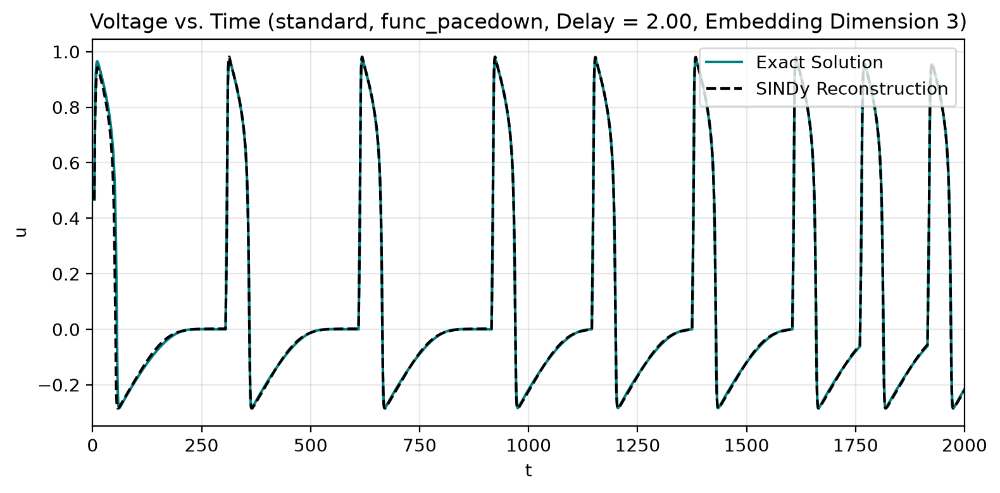



----------Fitting with tau = 4.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.0000 (delay_idx = 80)
Embedding dimension = 3
(u(t-0))' = -0.034 u(t-0) +  0.784 u(t-0)^2 + -0.738 u(t-0)^3 +  0.078 u(t-80) + -0.657 u(t-80)^2 +  0.520 u(t-80)^3 + -0.074 u(t-160) + -0.262 u(t-160)^2 +  0.201 u(t-160)^3 +  0.068 u(t-0)*u(t-80) +  0.099 u(t-0)*u(t-160) +  0.998 f_td(t)
(u(t-80))' =  0.100 u(t-0) + -0.274 u(t-0)^2 +  0.371 u(t-0)^3 +  0.459 u(t-80)^2 + -0.620 u(t-80)^3 + -0.095 u(t-160) + -0.244 u(t-160)^2 +  0.226 u(t-160)^3 +  0.006 u(t-0)*u(t-80) +  0.078 u(t-0)*u(t-160) + -0.035 f_td(t)
(u(t-160))' =  0.070 u(t-0) + -0.286 u(t-0)^2 +  0.198 u(t-0)^3 +  0.154 u(t-80) + -0.680 u(t-80)^2 +  0.679 u(t-80)^3 + -0.198 u(t-160) +  0.800 u(t-160)^2 + -0.854 u(t-160)^3 +  0.124 u(t-0)*u(t-80) +  0.016 u(t-0)*u(t-160)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  

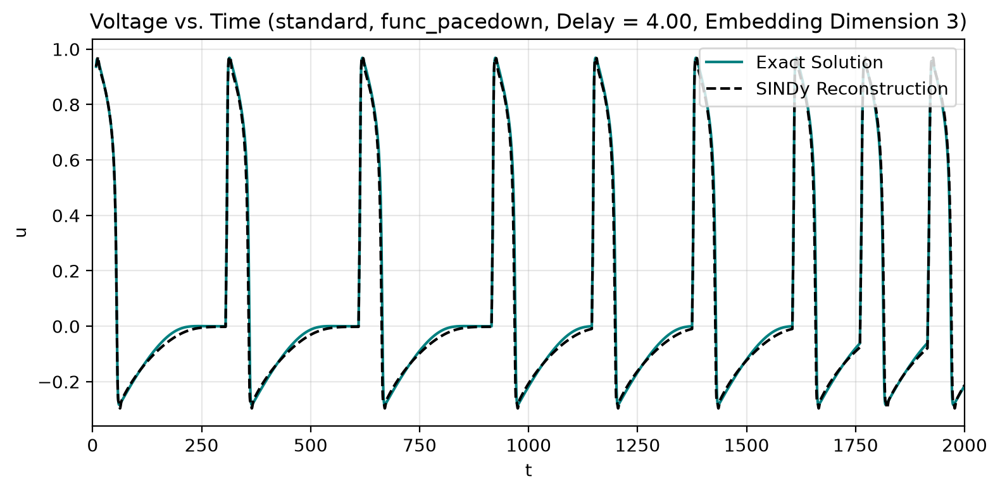



----------Fitting with tau = 6.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 6.0000 (delay_idx = 120)
Embedding dimension = 3
(u(t-0))' = -0.063 u(t-0) +  0.802 u(t-0)^2 + -0.730 u(t-0)^3 +  0.056 u(t-120) + -0.560 u(t-120)^2 +  0.466 u(t-120)^3 + -0.036 u(t-240) + -0.276 u(t-240)^2 +  0.229 u(t-240)^3 +  0.028 u(t-0)*u(t-120) +  0.061 u(t-0)*u(t-240) +  1.059 f_td(t)
(u(t-120))' =  0.041 u(t-0) + -0.529 u(t-0)^2 +  0.621 u(t-0)^3 +  0.003 u(t-120) +  0.578 u(t-120)^2 + -0.820 u(t-120)^3 + -0.026 u(t-240) + -0.199 u(t-240)^2 +  0.150 u(t-240)^3 +  0.122 u(t-0)*u(t-120) +  0.079 u(t-0)*u(t-240) +  0.107 f_td(t)
(u(t-240))' =  0.042 u(t-0) + -0.266 u(t-0)^2 +  0.254 u(t-0)^3 +  0.104 u(t-120) + -0.654 u(t-120)^2 +  0.722 u(t-120)^3 + -0.099 u(t-240) +  0.847 u(t-240)^2 + -0.974 u(t-240)^3 + -0.045 u(t-0)*u(t-120) +  0.106 u(t-0)*u(t-240)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', '

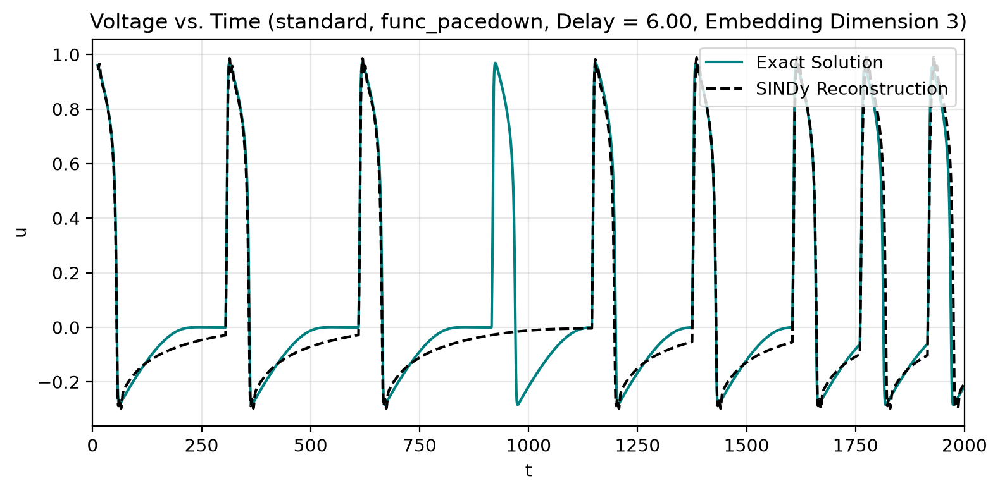



----------Fitting with tau = 8.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 8.0000 (delay_idx = 160)
Embedding dimension = 3
(u(t-0))' = -0.071 u(t-0) +  0.712 u(t-0)^2 + -0.632 u(t-0)^3 +  0.052 u(t-160) + -0.584 u(t-160)^2 +  0.466 u(t-160)^3 + -0.009 u(t-320) + -0.080 u(t-320)^2 +  0.036 u(t-0)*u(t-160) +  0.073 u(t-0)*u(t-320) + -0.001 1 +  1.134 f_td(t)
(u(t-160))' = -0.020 u(t-0) + -0.288 u(t-0)^2 +  0.370 u(t-0)^3 +  0.135 u(t-160) + -0.446 u(t-160)^3 + -0.069 u(t-320) +  0.060 u(t-320)^2 + -0.040 u(t-320)^3 +  0.278 u(t-0)*u(t-160) +  0.035 u(t-0)*u(t-320) +  0.003 1 +  0.140 f_td(t)
(u(t-320))' =  0.014 u(t-0) + -0.263 u(t-0)^2 +  0.283 u(t-0)^3 +  0.112 u(t-160) + -0.663 u(t-160)^2 +  0.702 u(t-160)^3 + -0.047 u(t-320) +  0.894 u(t-320)^2 + -1.064 u(t-320)^3 + -0.069 u(t-0)*u(t-160) +  0.150 u(t-0)*u(t-320)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_

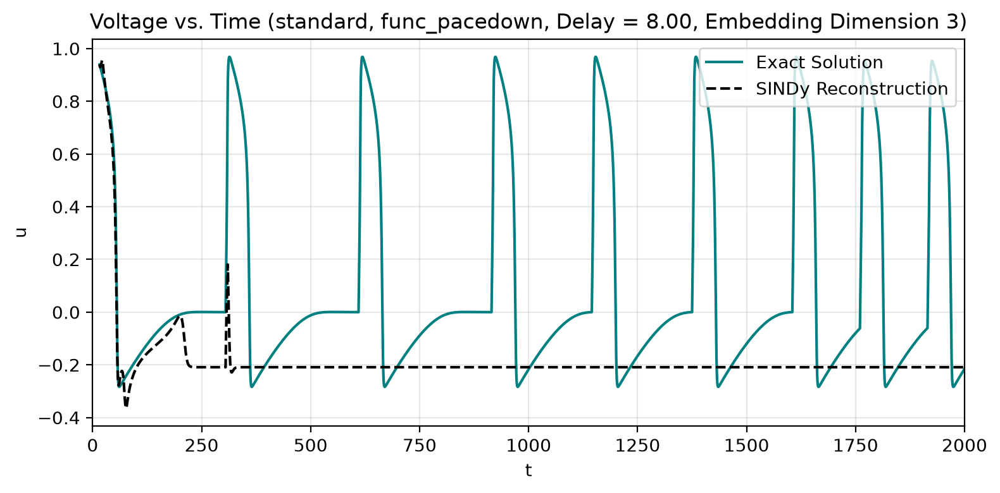



----------Fitting with tau = 10.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 10.0000 (delay_idx = 200)
Embedding dimension = 3
(u(t-0))' = -0.102 u(t-0) +  0.853 u(t-0)^2 + -0.757 u(t-0)^3 +  0.043 u(t-200) + -0.464 u(t-200)^2 +  0.383 u(t-200)^3 + -0.298 u(t-400)^2 +  0.229 u(t-400)^3 +  0.008 u(t-0)*u(t-200) +  0.054 u(t-0)*u(t-400) +  1.124 f_td(t)
(u(t-200))' = -0.014 u(t-0) + -0.528 u(t-0)^2 +  0.617 u(t-0)^3 +  0.061 u(t-200) +  0.741 u(t-200)^2 + -0.997 u(t-200)^3 + -0.006 u(t-400) + -0.276 u(t-400)^2 +  0.210 u(t-400)^3 +  0.151 u(t-0)*u(t-200) +  0.061 u(t-0)*u(t-400) +  0.001 1 +  0.271 f_td(t)
(u(t-400))' = -0.438 u(t-0)^2 +  0.488 u(t-0)^3 +  0.070 u(t-200) +  0.135 u(t-200)^3 +  0.043 u(t-400) +  0.575 u(t-400)^2 + -0.878 u(t-400)^3 + -0.170 u(t-0)*u(t-200) +  0.223 u(t-0)*u(t-400)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0],

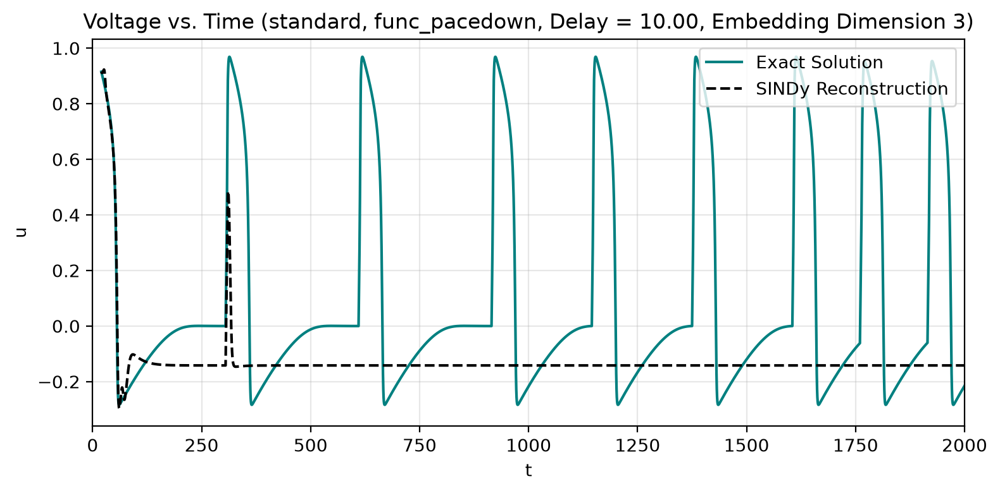



----------Fitting with tau = 12.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 12.0000 (delay_idx = 240)
Embedding dimension = 3
(u(t-0))' = -0.140 u(t-0) +  0.170 u(t-0)^2 +  0.030 u(t-240) + -0.122 u(t-240)^2 +  0.027 u(t-480) + -0.196 u(t-480)^2 +  0.138 u(t-480)^3 +  0.068 u(t-0)*u(t-240) +  0.066 u(t-0)*u(t-480) + -0.001 1 +  1.568 f_td(t)
(u(t-240))' = -0.004 u(t-0) + -0.504 u(t-0)^2 +  0.571 u(t-0)^3 +  0.065 u(t-240) +  0.823 u(t-240)^2 + -1.068 u(t-240)^3 + -0.005 u(t-480) + -0.293 u(t-480)^2 +  0.227 u(t-480)^3 +  0.146 u(t-0)*u(t-240) +  0.047 u(t-0)*u(t-480) +  0.001 1 +  0.248 f_td(t)
(u(t-480))' = -0.234 u(t-0)^2 +  0.257 u(t-0)^3 +  0.158 u(t-240) + -0.651 u(t-240)^2 +  0.624 u(t-240)^3 +  0.008 u(t-480) +  0.972 u(t-480)^2 + -1.191 u(t-480)^3 + -0.076 u(t-0)*u(t-240) +  0.182 u(t-0)*u(t-480) +  0.003 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_p

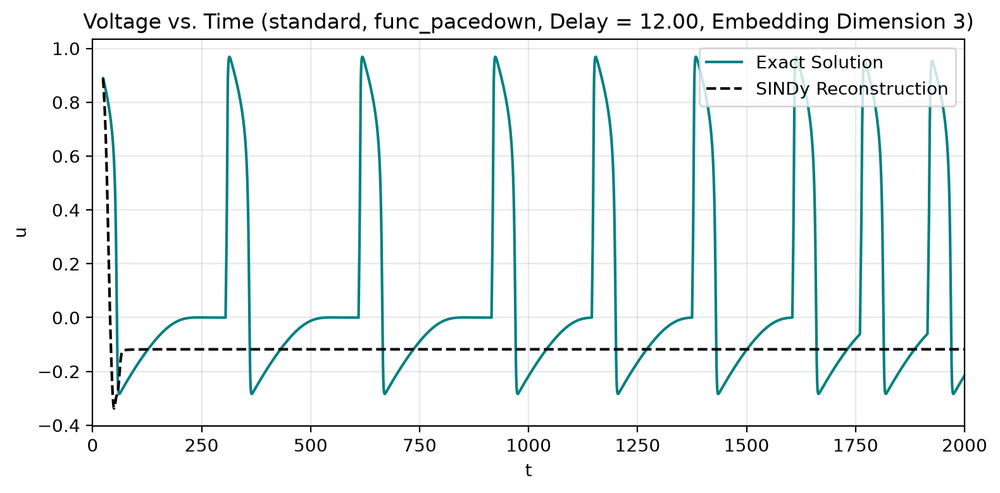



----------Fitting with tau = 14.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 14.0000 (delay_idx = 280)
Embedding dimension = 3
(u(t-0))' = -0.103 u(t-0) +  0.916 u(t-0)^2 + -0.833 u(t-0)^3 +  0.032 u(t-280) + -0.404 u(t-280)^2 +  0.325 u(t-280)^3 +  0.007 u(t-560) + -0.266 u(t-560)^2 +  0.194 u(t-560)^3 +  0.001 u(t-0)*u(t-280) +  0.040 u(t-0)*u(t-560) +  1.109 f_td(t)
(u(t-280))' =  0.021 u(t-0) + -0.471 u(t-0)^2 +  0.503 u(t-0)^3 +  0.063 u(t-280) +  0.911 u(t-280)^2 + -1.142 u(t-280)^3 + -0.007 u(t-560) + -0.299 u(t-560)^2 +  0.234 u(t-560)^3 +  0.134 u(t-0)*u(t-280) +  0.031 u(t-0)*u(t-560) +  0.001 1 +  0.188 f_td(t)
(u(t-560))' =  0.052 u(t-0) + -0.255 u(t-0)^2 +  0.220 u(t-0)^3 +  0.164 u(t-280) + -0.620 u(t-280)^2 +  0.579 u(t-280)^3 +  1.080 u(t-560)^2 + -1.264 u(t-560)^3 + -0.075 u(t-0)*u(t-280) +  0.149 u(t-0)*u(t-560) +  0.002 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', 

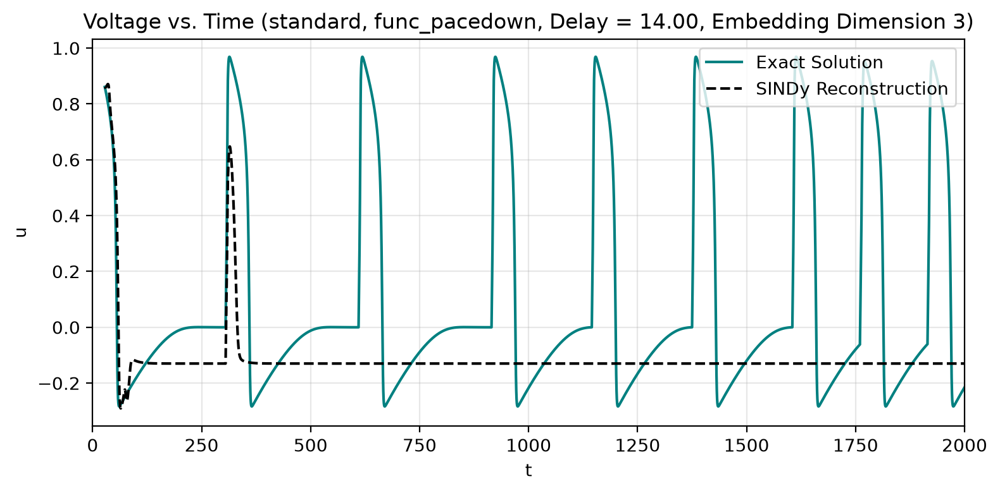



----------Fitting with tau = 16.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 16.0000 (delay_idx = 320)
Embedding dimension = 3
(u(t-0))' = -0.070 u(t-0) +  0.930 u(t-0)^2 + -0.893 u(t-0)^3 +  0.017 u(t-320) + -0.367 u(t-320)^2 +  0.286 u(t-320)^3 + -0.005 u(t-640) + -0.231 u(t-640)^2 +  0.188 u(t-640)^3 +  0.009 u(t-0)*u(t-320) + -0.001 1 +  1.044 f_td(t)
(u(t-320))' =  0.057 u(t-0) + -0.434 u(t-0)^2 +  0.422 u(t-0)^3 +  0.053 u(t-320) +  1.013 u(t-320)^2 + -1.224 u(t-320)^3 + -0.011 u(t-640) + -0.312 u(t-640)^2 +  0.250 u(t-640)^3 +  0.117 u(t-0)*u(t-320) +  0.013 u(t-0)*u(t-640) +  0.001 1 +  0.104 f_td(t)
(u(t-640))' =  0.009 u(t-0) +  0.184 u(t-320) + -0.623 u(t-320)^2 +  0.570 u(t-320)^3 +  0.024 u(t-640) +  0.956 u(t-640)^2 + -1.170 u(t-640)^3 + -0.104 u(t-0)*u(t-320) +  0.176 u(t-0)*u(t-640) +  0.002 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_liba

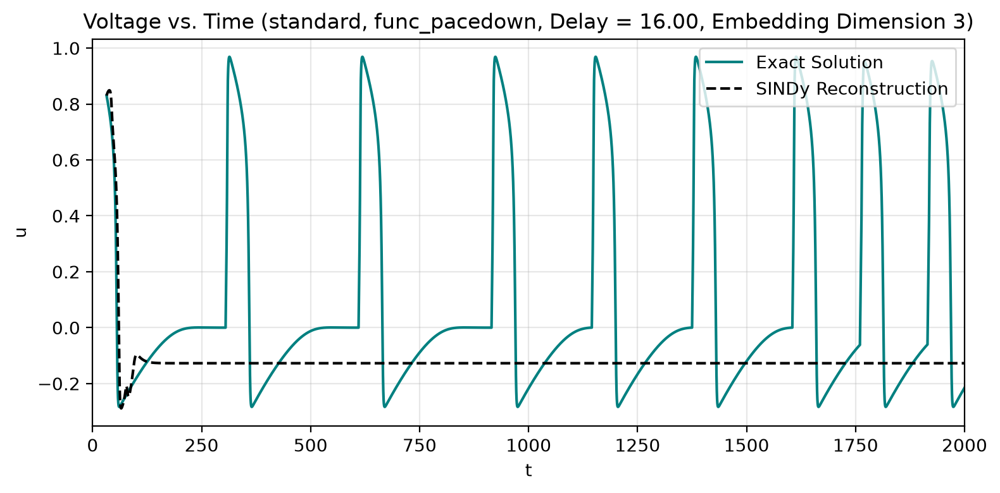



----------Fitting with tau = 18.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 18.0000 (delay_idx = 360)
Embedding dimension = 3
(u(t-0))' = -0.093 u(t-0) +  0.921 u(t-0)^2 + -0.863 u(t-0)^3 +  0.020 u(t-360) + -0.327 u(t-360)^2 +  0.248 u(t-360)^3 +  0.009 u(t-720) + -0.220 u(t-720)^2 +  0.146 u(t-720)^3 + -0.007 u(t-0)*u(t-360) +  0.024 u(t-0)*u(t-720) +  1.094 f_td(t)
(u(t-360))' =  0.141 u(t-0) + -0.532 u(t-0)^2 +  0.428 u(t-0)^3 +  0.059 u(t-360) +  1.069 u(t-360)^2 + -1.264 u(t-360)^3 + -0.017 u(t-720) + -0.075 u(t-720)^2 +  0.081 u(t-0)*u(t-360) + -0.011 u(t-0)*u(t-720) + -0.006 f_td(t)
(u(t-720))' =  0.104 u(t-0) + -0.114 u(t-0)^3 +  0.171 u(t-360) + -0.530 u(t-360)^2 +  0.482 u(t-360)^3 +  0.013 u(t-720) +  1.027 u(t-720)^2 + -1.205 u(t-720)^3 + -0.119 u(t-0)*u(t-360) +  0.123 u(t-0)*u(t-720) +  0.001 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_lib

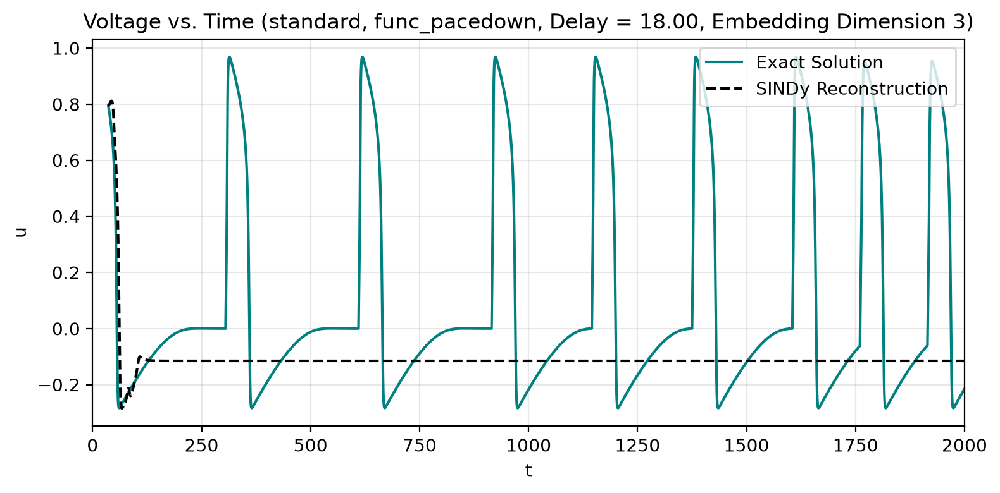



----------Fitting with tau = 20.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 20.0000 (delay_idx = 400)
Embedding dimension = 3
(u(t-0))' = -0.093 u(t-0) +  0.863 u(t-0)^2 + -0.805 u(t-0)^3 +  0.016 u(t-400) + -0.297 u(t-400)^2 +  0.221 u(t-400)^3 +  0.007 u(t-800) + -0.174 u(t-800)^2 +  0.105 u(t-800)^3 + -0.009 u(t-0)*u(t-400) +  0.012 u(t-0)*u(t-800) + -0.001 1 +  1.133 f_td(t)
(u(t-400))' =  0.176 u(t-0) + -0.610 u(t-0)^2 +  0.469 u(t-0)^3 +  0.044 u(t-400) +  1.134 u(t-400)^2 + -1.295 u(t-400)^3 + -0.023 u(t-800) + -0.061 u(t-800)^2 +  0.058 u(t-0)*u(t-400) + -0.043 u(t-0)*u(t-800) + -0.036 f_td(t)
(u(t-800))' =  0.191 u(t-0) + -0.365 u(t-0)^2 +  0.171 u(t-0)^3 +  0.167 u(t-400) + -0.392 u(t-400)^2 +  0.355 u(t-400)^3 +  0.005 u(t-800) +  1.178 u(t-800)^2 + -1.313 u(t-800)^3 + -0.126 u(t-0)*u(t-400) +  0.065 u(t-0)*u(t-800) +  0.001 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1

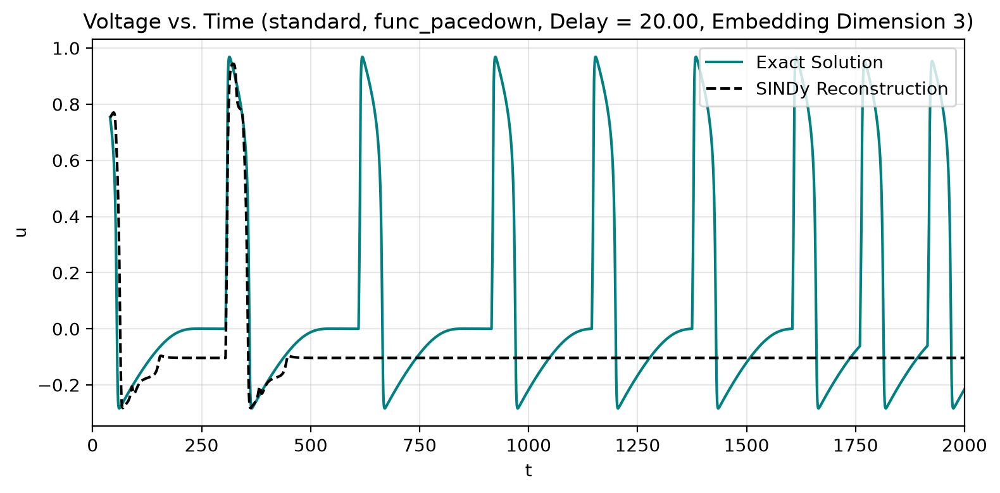



----------Fitting with tau = 22.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 22.0000 (delay_idx = 440)
Embedding dimension = 3
(u(t-0))' = -0.091 u(t-0) +  0.741 u(t-0)^2 + -0.683 u(t-0)^3 +  0.017 u(t-440) + -0.268 u(t-440)^2 +  0.196 u(t-440)^3 + -0.103 u(t-880)^2 +  0.040 u(t-880)^3 + -0.009 u(t-0)*u(t-440) + -0.022 u(t-0)*u(t-880) + -0.002 1 +  1.192 f_td(t)
(u(t-440))' =  0.186 u(t-0) + -0.730 u(t-0)^2 +  0.584 u(t-0)^3 +  0.032 u(t-440) +  1.158 u(t-440)^2 + -1.281 u(t-440)^3 + -0.027 u(t-880) + -0.055 u(t-880)^2 +  0.042 u(t-0)*u(t-440) + -0.087 u(t-0)*u(t-880) + -0.003 f_td(t)
(u(t-880))' =  0.242 u(t-0) + -0.282 u(t-0)^3 +  0.133 u(t-440) + -0.087 u(t-440)^2 + -0.017 u(t-880) +  0.801 u(t-880)^2 + -0.876 u(t-880)^3 + -0.125 u(t-0)*u(t-440) +  0.032 u(t-0)*u(t-880) + -0.443 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0],

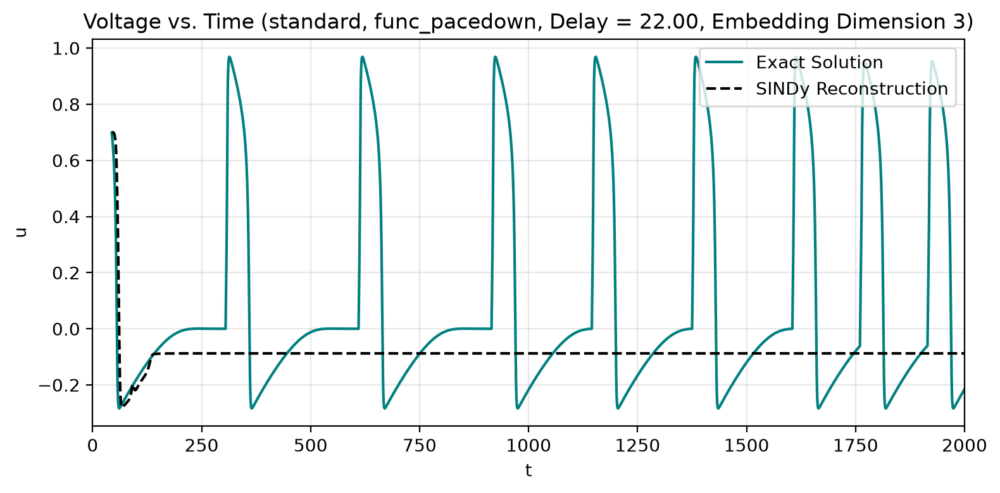



----------Fitting with tau = 24.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 24.0000 (delay_idx = 480)
Embedding dimension = 3
(u(t-0))' = -0.126 u(t-0) +  0.620 u(t-0)^2 + -0.520 u(t-0)^3 +  0.016 u(t-480) + -0.238 u(t-480)^2 +  0.170 u(t-480)^3 + -0.003 u(t-960) + -0.147 u(t-960)^2 +  0.066 u(t-960)^3 +  0.007 u(t-0)*u(t-480) + -0.119 u(t-0)*u(t-960) +  1.304 f_td(t)
(u(t-480))' = -0.313 u(t-0)^2 +  0.362 u(t-0)^3 + -0.015 u(t-480) +  1.113 u(t-480)^2 + -1.223 u(t-480)^3 + -0.014 u(t-960) + -0.618 u(t-960)^2 +  0.606 u(t-960)^3 +  0.099 u(t-0)*u(t-480) +  0.065 u(t-0)*u(t-960)
(u(t-960))' =  0.293 u(t-0) + -0.382 u(t-0)^2 +  0.070 u(t-0)^3 +  0.102 u(t-480) + -0.259 u(t-480)^2 +  0.221 u(t-480)^3 + -0.040 u(t-960) +  0.871 u(t-960)^2 + -0.807 u(t-960)^3 + -0.105 u(t-0)*u(t-480) +  0.057 u(t-0)*u(t-960) + -0.001 1 + -0.355 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_t

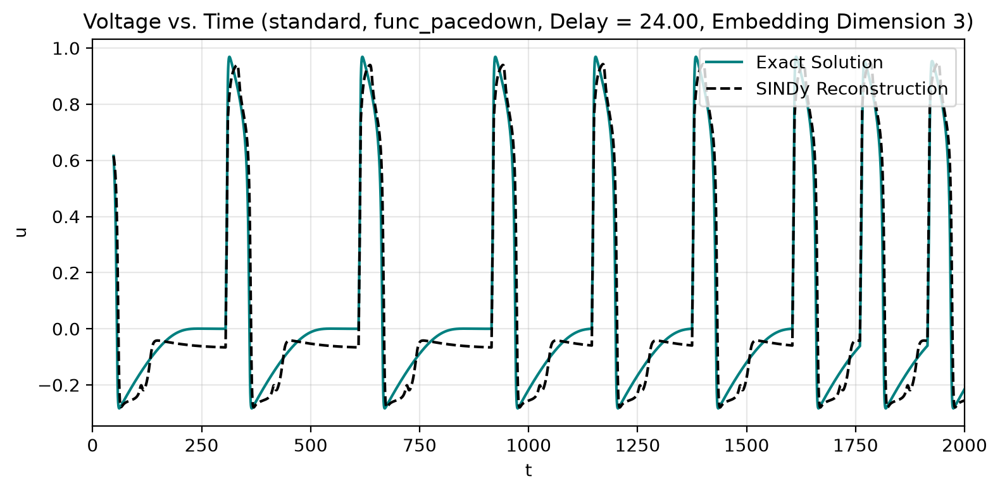



----------Fitting with tau = 26.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 26.0000 (delay_idx = 520)
Embedding dimension = 3
(u(t-0))' =  0.377 u(t-0)^2 + -0.402 u(t-0)^3 + -0.037 u(t-520) + -0.187 u(t-520)^2 +  0.133 u(t-520)^3 + -0.054 u(t-1040) + -0.139 u(t-1040)^2 +  0.240 u(t-1040)^3 +  0.040 u(t-0)*u(t-520) + -0.088 u(t-0)*u(t-1040) + -0.005 1 +  1.207 f_td(t)
(u(t-520))' = -0.016 u(t-0) + -0.108 u(t-0)^2 +  0.154 u(t-0)^3 + -0.001 u(t-520) +  0.991 u(t-520)^2 + -1.092 u(t-520)^3 + -0.016 u(t-1040) + -0.476 u(t-1040)^2 +  0.364 u(t-1040)^3 +  0.061 u(t-0)*u(t-520) + -0.135 u(t-0)*u(t-1040) + -0.002 1
(u(t-1040))' =  0.333 u(t-0) + -1.092 u(t-0)^2 +  0.800 u(t-0)^3 +  0.103 u(t-520) + -0.267 u(t-520)^2 +  0.324 u(t-520)^3 + -0.031 u(t-1040) +  1.093 u(t-1040)^2 + -0.959 u(t-1040)^3 + -0.143 u(t-0)*u(t-520) +  0.162 u(t-0)*u(t-1040) + -0.002 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 

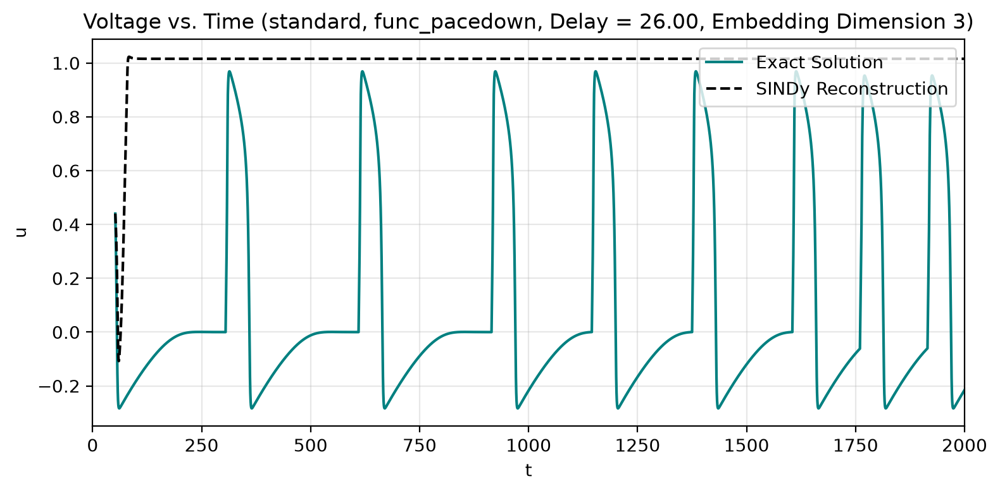



----------Fitting with tau = 28.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 28.0000 (delay_idx = 560)
Embedding dimension = 3
(u(t-0))' = -0.171 u(t-0) +  0.708 u(t-0)^2 + -0.563 u(t-0)^3 +  0.006 u(t-560) + -0.348 u(t-560)^2 +  0.245 u(t-560)^3 + -0.031 u(t-1120) + -0.189 u(t-1120)^2 +  0.183 u(t-1120)^3 +  0.070 u(t-0)*u(t-560) + -0.141 u(t-0)*u(t-1120) + -0.004 1 +  1.372 f_td(t)
(u(t-560))' = -0.010 u(t-0) +  0.055 u(t-0)^2 + -0.034 u(t-0)^3 +  0.017 u(t-560) +  1.003 u(t-560)^2 + -1.163 u(t-560)^3 + -0.015 u(t-1120) + -0.440 u(t-1120)^2 +  0.306 u(t-1120)^3 +  0.091 u(t-0)*u(t-560) + -0.162 u(t-0)*u(t-1120) + -0.003 1
(u(t-1120))' = -0.146 u(t-0) +  0.465 u(t-0)^2 + -0.336 u(t-0)^3 +  0.059 u(t-560) + -0.355 u(t-560)^2 +  0.367 u(t-560)^3 +  0.003 u(t-1120) + -0.136 u(t-1120)^3 + -0.078 u(t-0)*u(t-560) + -0.164 u(t-0)*u(t-1120)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f

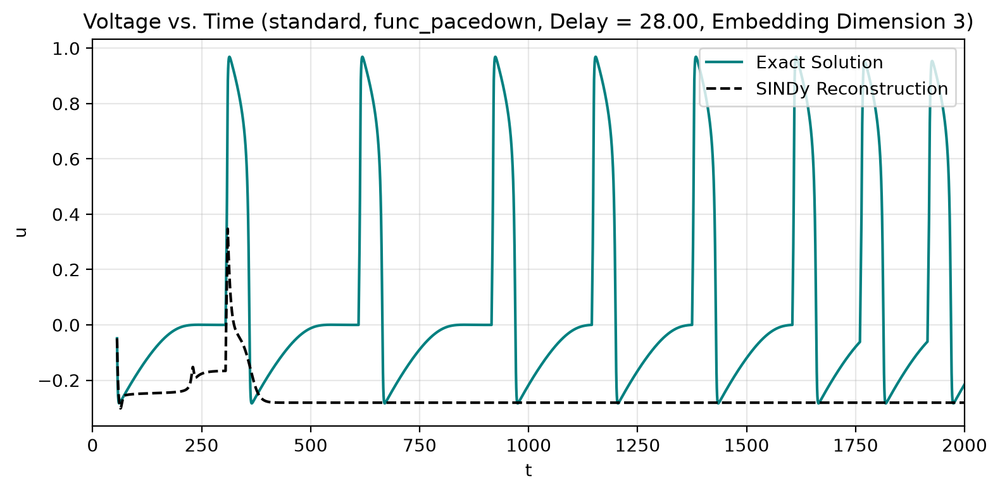



----------Fitting with tau = 30.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 30.0000 (delay_idx = 600)
Embedding dimension = 3
(u(t-0))' = -0.178 u(t-0) +  0.651 u(t-0)^2 + -0.497 u(t-0)^3 +  0.017 u(t-600) + -0.318 u(t-600)^2 +  0.202 u(t-600)^3 + -0.027 u(t-1200) + -0.145 u(t-1200)^2 +  0.126 u(t-1200)^3 +  0.077 u(t-0)*u(t-600) + -0.157 u(t-0)*u(t-1200) + -0.004 1 +  1.411 f_td(t)
(u(t-600))' =  0.009 u(t-0)^2 +  0.031 u(t-600) +  1.068 u(t-600)^2 + -1.258 u(t-600)^3 + -0.007 u(t-1200) + -0.386 u(t-1200)^2 +  0.238 u(t-1200)^3 +  0.118 u(t-0)*u(t-600) + -0.143 u(t-0)*u(t-1200) + -0.002 1 + -0.002 f_td(t)
(u(t-1200))' =  0.073 u(t-0) + -0.125 u(t-0)^2 +  0.051 u(t-0)^3 +  0.129 u(t-600) + -0.080 u(t-600)^3 + -0.007 u(t-1200) +  0.542 u(t-1200)^2 + -0.631 u(t-1200)^3 + -0.100 u(t-0)*u(t-600) + -0.103 u(t-0)*u(t-1200) + -0.007 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x

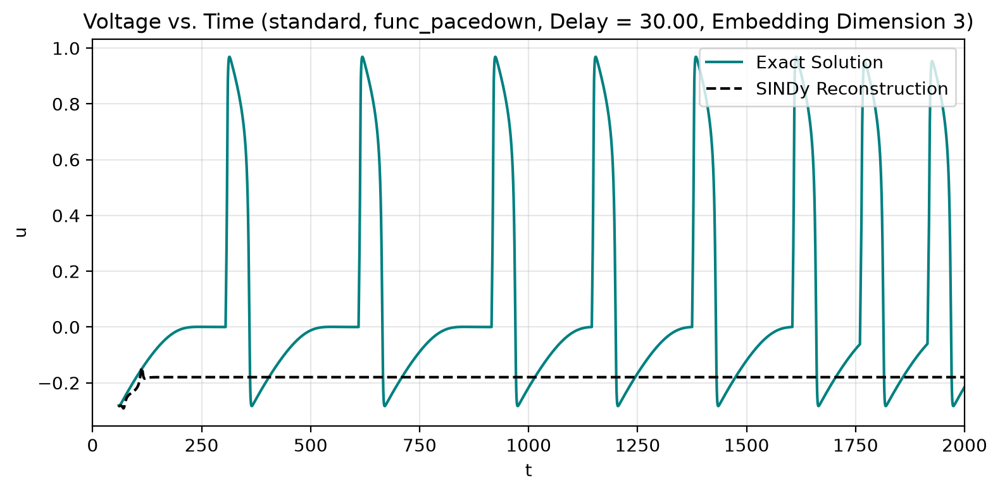



----------Fitting with tau = 32.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 32.0000 (delay_idx = 640)
Embedding dimension = 3
(u(t-0))' = -0.143 u(t-0) +  0.590 u(t-0)^2 + -0.471 u(t-0)^3 + -0.294 u(t-640)^2 +  0.214 u(t-640)^3 + -0.019 u(t-1280) + -0.024 u(t-1280)^2 +  0.047 u(t-0)*u(t-640) + -0.135 u(t-0)*u(t-1280) + -0.007 1 +  1.388 f_td(t)
(u(t-640))' =  0.004 u(t-0)^2 +  0.005 u(t-0)^3 +  0.032 u(t-640) +  1.079 u(t-640)^2 + -1.273 u(t-640)^3 + -0.349 u(t-1280)^2 +  0.193 u(t-1280)^3 +  0.137 u(t-0)*u(t-640) + -0.112 u(t-0)*u(t-1280) + -0.001 1 +  0.002 f_td(t)
(u(t-1280))' =  0.028 u(t-0) + -0.026 u(t-0)^2 + -0.006 u(t-0)^3 +  0.190 u(t-640) + -0.502 u(t-640)^2 +  0.370 u(t-640)^3 + -0.004 u(t-1280) +  0.753 u(t-1280)^2 + -0.821 u(t-1280)^3 + -0.075 u(t-0)*u(t-640) + -0.107 u(t-0)*u(t-1280) + -0.004 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_liba

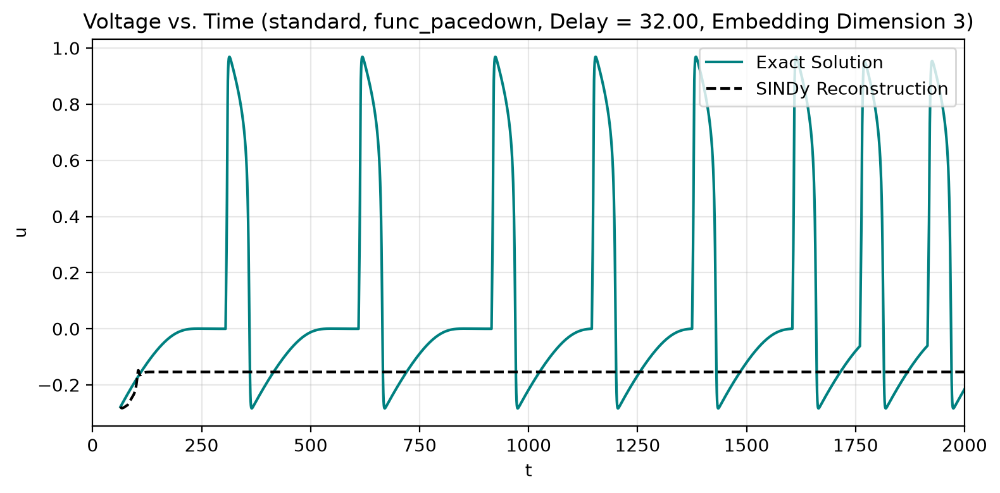



----------Fitting with tau = 34.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 34.0000 (delay_idx = 680)
Embedding dimension = 3
(u(t-0))' = -0.085 u(t-0) +  0.520 u(t-0)^2 + -0.462 u(t-0)^3 +  0.008 u(t-680) + -0.200 u(t-680)^2 +  0.112 u(t-680)^3 + -0.015 u(t-1360) + -0.036 u(t-0)*u(t-1360) + -0.005 1 +  1.314 f_td(t)
(u(t-680))' =  0.031 u(t-0)^2 + -0.025 u(t-0)^3 +  0.021 u(t-680) +  1.020 u(t-680)^2 + -1.193 u(t-680)^3 +  0.005 u(t-1360) + -0.311 u(t-1360)^2 +  0.158 u(t-1360)^3 +  0.143 u(t-0)*u(t-680) + -0.078 u(t-0)*u(t-1360) + -0.001 1 + -0.009 f_td(t)
(u(t-1360))' =  0.038 u(t-0) + -0.077 u(t-0)^2 +  0.036 u(t-0)^3 +  0.197 u(t-680) + -0.388 u(t-680)^2 +  0.229 u(t-680)^3 + -0.002 u(t-1360) +  0.705 u(t-1360)^2 + -0.763 u(t-1360)^3 + -0.060 u(t-0)*u(t-680) + -0.102 u(t-0)*u(t-1360) + -0.004 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0]

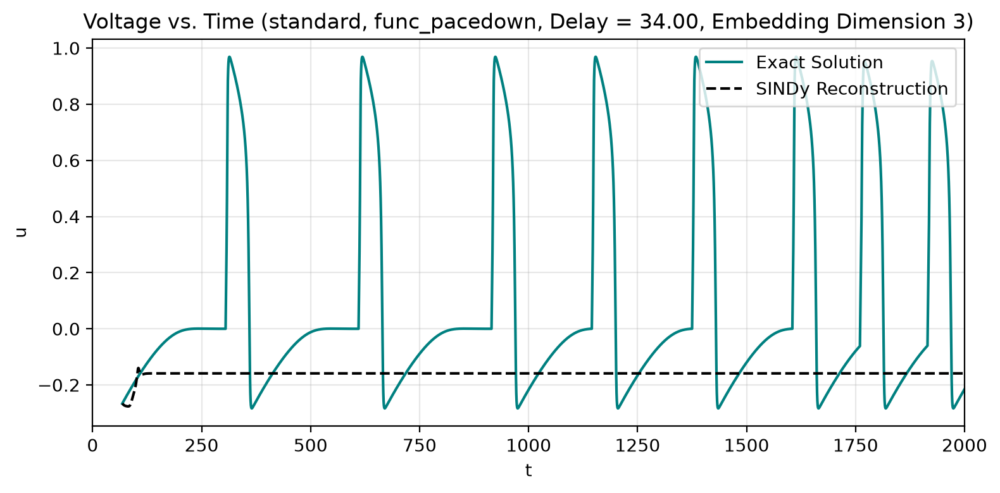



----------Fitting with tau = 36.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 36.0000 (delay_idx = 720)
Embedding dimension = 3
(u(t-0))' = -0.208 u(t-0) +  0.570 u(t-0)^2 + -0.380 u(t-0)^3 +  0.061 u(t-720) + -0.307 u(t-720)^2 +  0.136 u(t-720)^3 + -0.006 u(t-1440) + -0.059 u(t-1440)^3 +  0.102 u(t-0)*u(t-720) + -0.139 u(t-0)*u(t-1440) +  1.489 f_td(t)
(u(t-720))' =  0.160 u(t-0) + -0.120 u(t-0)^2 + -0.048 u(t-0)^3 + -0.022 u(t-720) +  1.115 u(t-720)^2 + -1.206 u(t-720)^3 +  0.013 u(t-1440) + -0.205 u(t-1440)^2 +  0.096 u(t-1440)^3 +  0.046 u(t-0)*u(t-720) +  0.063 u(t-0)*u(t-1440) + -0.001 1 + -0.221 f_td(t)
(u(t-1440))' =  0.051 u(t-0) + -0.125 u(t-0)^2 +  0.074 u(t-0)^3 +  0.195 u(t-720) + -0.266 u(t-720)^2 +  0.094 u(t-720)^3 + -0.004 u(t-1440) +  0.636 u(t-1440)^2 + -0.678 u(t-1440)^3 + -0.052 u(t-0)*u(t-720) + -0.087 u(t-0)*u(t-1440) + -0.005 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1',

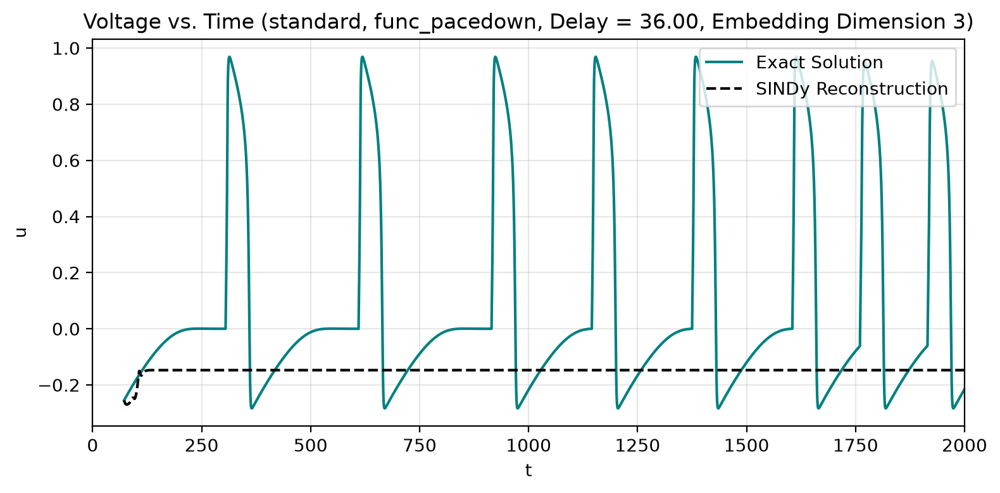



----------Fitting with tau = 38.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 38.0000 (delay_idx = 760)
Embedding dimension = 3
(u(t-0))' = -0.226 u(t-0) +  0.580 u(t-0)^2 + -0.369 u(t-0)^3 +  0.058 u(t-760) + -0.291 u(t-760)^2 +  0.121 u(t-760)^3 + -0.070 u(t-1520)^3 +  0.110 u(t-0)*u(t-760) + -0.136 u(t-0)*u(t-1520) +  1.519 f_td(t)
(u(t-760))' =  0.141 u(t-0) + -0.074 u(t-0)^2 + -0.083 u(t-0)^3 + -0.043 u(t-760) +  0.972 u(t-760)^2 + -1.018 u(t-760)^3 +  0.012 u(t-1520) + -0.203 u(t-1520)^2 +  0.088 u(t-1520)^3 +  0.049 u(t-0)*u(t-760) + -0.001 1 + -0.217 f_td(t)
(u(t-1520))' =  0.069 u(t-0) + -0.179 u(t-0)^2 +  0.113 u(t-0)^3 +  0.190 u(t-760) + -0.153 u(t-760)^2 + -0.021 u(t-760)^3 + -0.008 u(t-1520) +  0.564 u(t-1520)^2 + -0.583 u(t-1520)^3 + -0.054 u(t-0)*u(t-760) + -0.065 u(t-0)*u(t-1520) + -0.005 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:

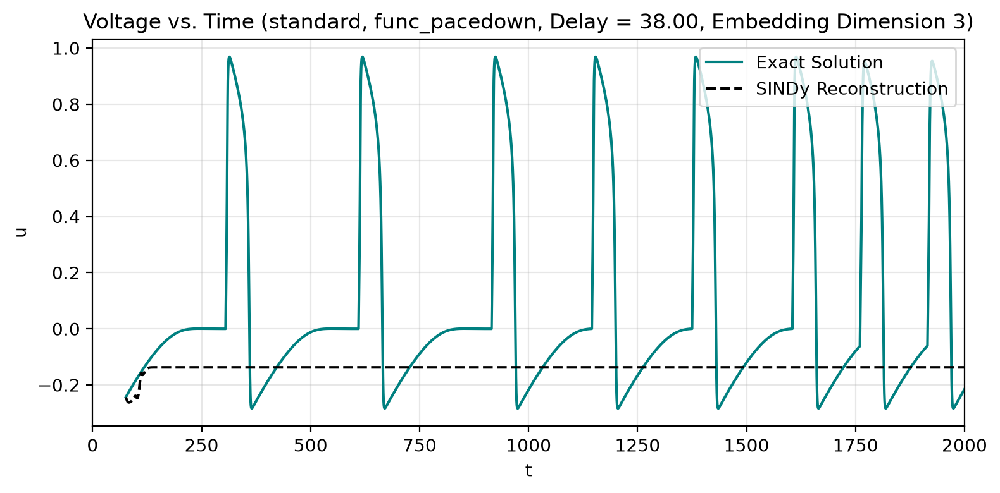



----------Fitting with tau = 40.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 40.0000 (delay_idx = 800)
Embedding dimension = 3
(u(t-0))' = -0.247 u(t-0) +  0.613 u(t-0)^2 + -0.377 u(t-0)^3 +  0.045 u(t-800) + -0.256 u(t-800)^2 +  0.098 u(t-800)^3 + -0.072 u(t-1600)^3 +  0.117 u(t-0)*u(t-800) + -0.127 u(t-0)*u(t-1600) + -0.003 1 +  1.559 f_td(t)
(u(t-800))' =  0.124 u(t-0) + -0.015 u(t-0)^2 + -0.126 u(t-0)^3 + -0.060 u(t-800) +  0.814 u(t-800)^2 + -0.820 u(t-800)^3 +  0.013 u(t-1600) + -0.169 u(t-1600)^2 +  0.061 u(t-1600)^3 +  0.054 u(t-0)*u(t-800) + -0.002 1 + -0.208 f_td(t)
(u(t-1600))' =  0.089 u(t-0) + -0.256 u(t-0)^2 +  0.168 u(t-0)^3 +  0.189 u(t-800) + -0.088 u(t-800)^2 + -0.093 u(t-800)^3 + -0.004 u(t-1600) +  0.463 u(t-1600)^2 + -0.470 u(t-1600)^3 + -0.061 u(t-0)*u(t-800) + -0.056 u(t-0)*u(t-1600)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:

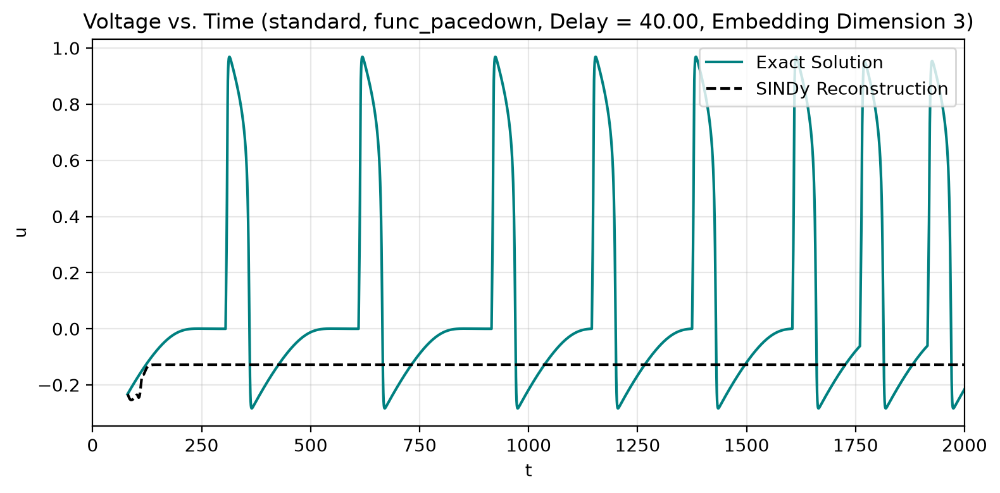



----------Fitting with tau = 42.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 42.0000 (delay_idx = 840)
Embedding dimension = 3
(u(t-0))' = -0.219 u(t-0) +  0.564 u(t-0)^2 + -0.348 u(t-0)^3 +  0.025 u(t-840) + -0.153 u(t-840)^2 +  0.017 u(t-840)^3 + -0.006 u(t-1680) + -0.036 u(t-1680)^3 +  0.084 u(t-0)*u(t-840) + -0.005 1 +  1.549 f_td(t)
(u(t-840))' =  0.092 u(t-0) +  0.066 u(t-0)^2 + -0.177 u(t-0)^3 + -0.071 u(t-840) +  0.662 u(t-840)^2 + -0.635 u(t-840)^3 +  0.015 u(t-1680) + -0.134 u(t-1680)^2 +  0.025 u(t-1680)^3 +  0.080 u(t-0)*u(t-840) + -0.003 1 + -0.183 f_td(t)
(u(t-1680))' =  0.063 u(t-0) + -0.069 u(t-0)^2 +  0.186 u(t-840) + -0.136 u(t-840)^2 + -0.054 u(t-840)^3 + -0.025 u(t-1680) +  0.462 u(t-1680)^2 + -0.424 u(t-1680)^3 + -0.055 u(t-0)*u(t-840) + -0.030 u(t-0)*u(t-1680) + -0.007 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [

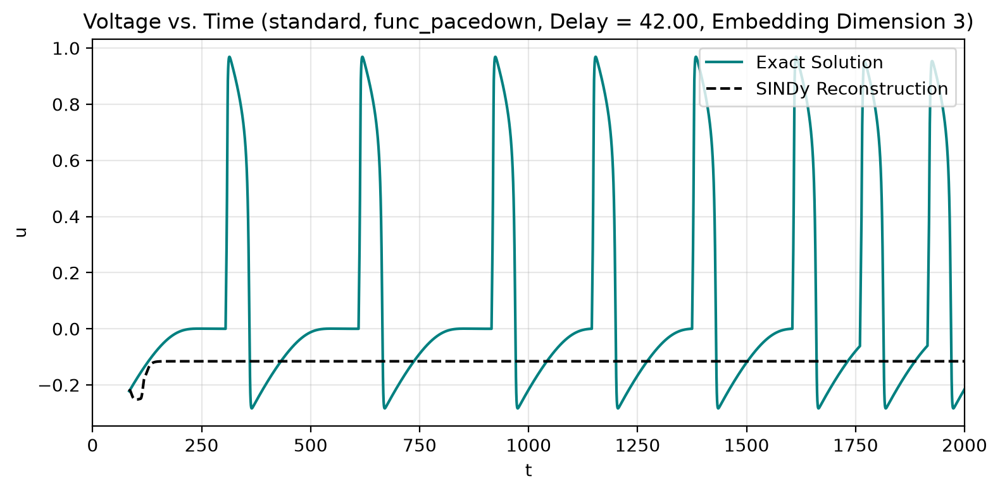



----------Fitting with tau = 44.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 44.0000 (delay_idx = 880)
Embedding dimension = 3
(u(t-0))' = -0.185 u(t-0) +  0.487 u(t-0)^2 + -0.303 u(t-0)^3 + -0.071 u(t-880)^2 + -0.032 u(t-880)^3 + -0.026 u(t-1760) +  0.031 u(t-0)*u(t-880) +  0.010 u(t-0)*u(t-1760) + -0.008 1 +  1.524 f_td(t)
(u(t-880))' =  0.064 u(t-0) +  0.139 u(t-0)^2 + -0.220 u(t-0)^3 + -0.088 u(t-880) +  0.555 u(t-880)^2 + -0.486 u(t-880)^3 +  0.014 u(t-1760) + -0.110 u(t-1760)^2 +  0.004 u(t-1760)^3 +  0.129 u(t-0)*u(t-880) +  0.017 u(t-0)*u(t-1760) + -0.005 1 + -0.155 f_td(t)
(u(t-1760))' =  0.054 u(t-0) + -0.058 u(t-0)^2 +  0.206 u(t-880) + -0.180 u(t-880)^2 + -0.037 u(t-880)^3 + -0.036 u(t-1760) +  0.452 u(t-1760)^2 + -0.378 u(t-1760)^3 + -0.056 u(t-0)*u(t-880) + -0.017 u(t-0)*u(t-1760) + -0.008 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary: 

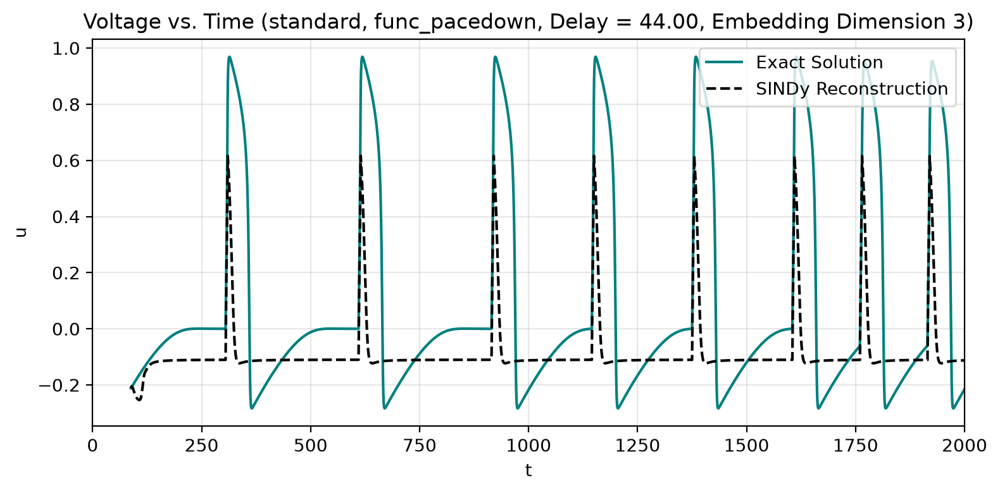



----------Fitting with tau = 46.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 46.0000 (delay_idx = 920)
Embedding dimension = 3
(u(t-0))' = -0.084 u(t-0) +  0.094 u(t-0)^2 + -0.014 u(t-920) +  0.062 u(t-920)^2 + -0.142 u(t-920)^3 +  0.005 u(t-1840) + -0.063 u(t-1840)^2 +  0.047 u(t-1840)^3 + -0.121 u(t-0)*u(t-920) +  0.033 u(t-0)*u(t-1840) +  1.492 f_td(t)
(u(t-920))' =  0.039 u(t-0) +  0.180 u(t-0)^2 + -0.238 u(t-0)^3 + -0.113 u(t-920) +  0.504 u(t-920)^2 + -0.369 u(t-920)^3 +  0.011 u(t-1840) + -0.124 u(t-1840)^2 +  0.008 u(t-1840)^3 +  0.234 u(t-0)*u(t-920) + -0.031 u(t-0)*u(t-1840) + -0.006 1 + -0.127 f_td(t)
(u(t-1840))' =  0.017 u(t-0) + -0.026 u(t-0)^2 +  0.253 u(t-920) + -0.359 u(t-920)^2 +  0.082 u(t-920)^3 + -0.037 u(t-1840) +  0.404 u(t-1840)^2 + -0.311 u(t-1840)^3 + -0.040 u(t-0)*u(t-920) + -0.052 u(t-0)*u(t-1840)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 7.65823e+02


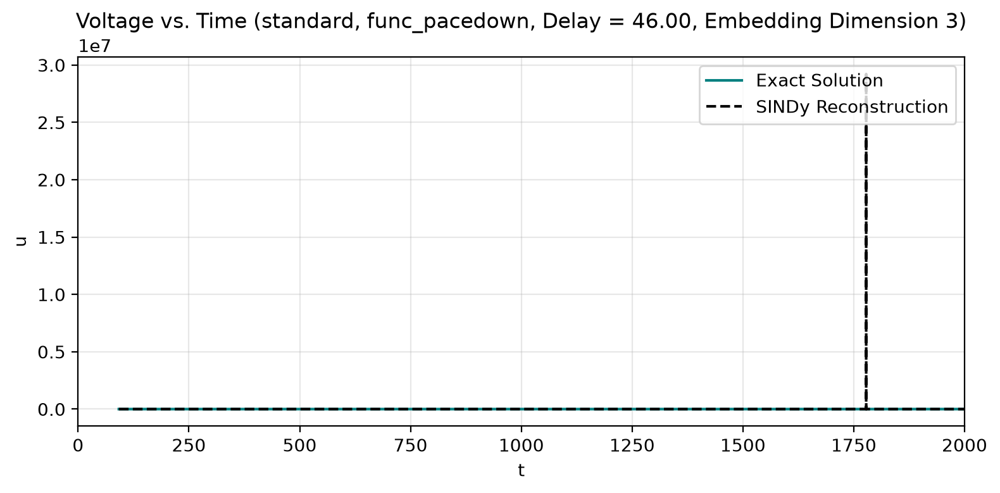



----------Fitting with tau = 48.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 48.0000 (delay_idx = 960)
Embedding dimension = 3
(u(t-0))' = -0.200 u(t-0) +  0.449 u(t-0)^2 + -0.250 u(t-0)^3 + -0.045 u(t-960) + -0.054 u(t-960)^2 + -0.041 u(t-960)^3 +  0.007 u(t-1920) + -0.095 u(t-1920)^2 +  0.052 u(t-1920)^3 + -0.126 u(t-0)*u(t-960) +  0.027 u(t-0)*u(t-1920) + -0.003 1 +  1.548 f_td(t)
(u(t-960))' =  0.175 u(t-0) + -0.194 u(t-0)^2 +  0.009 u(t-0)^3 + -0.132 u(t-960) +  0.613 u(t-960)^2 + -0.359 u(t-960)^3 +  0.004 u(t-1920) + -0.106 u(t-1920)^2 +  0.024 u(t-1920)^3 +  0.282 u(t-0)*u(t-960) + -0.023 u(t-0)*u(t-1920) + -0.006 1 + -0.195 f_td(t)
(u(t-1920))' = -0.005 u(t-0) +  0.276 u(t-960) + -0.461 u(t-960)^2 +  0.141 u(t-960)^3 + -0.076 u(t-1920) +  0.201 u(t-1920)^2 + -0.083 u(t-0)*u(t-960) + -0.049 u(t-0)*u(t-1920)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_pe

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.81991e+01


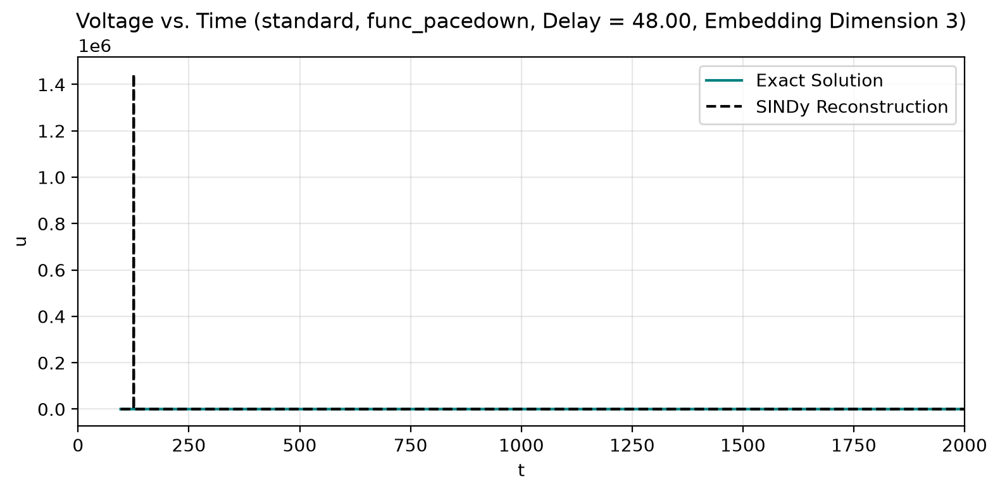



----------Fitting with tau = 50.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 50.0000 (delay_idx = 1000)
Embedding dimension = 3
(u(t-0))' = -0.173 u(t-0) +  0.344 u(t-0)^2 + -0.162 u(t-0)^3 + -0.088 u(t-1000) + -0.072 u(t-1000)^2 + -0.070 u(t-1000)^3 +  0.015 u(t-2000) + -0.121 u(t-2000)^2 +  0.115 u(t-2000)^3 + -0.525 u(t-0)*u(t-1000) +  0.217 u(t-0)*u(t-2000) + -0.002 1 +  1.544 f_td(t)
(u(t-1000))' =  0.484 u(t-0) + -1.118 u(t-0)^2 +  0.649 u(t-0)^3 + -0.082 u(t-1000) +  0.699 u(t-1000)^2 + -0.296 u(t-1000)^3 + -0.012 u(t-2000) +  0.015 u(t-2000)^2 +  0.320 u(t-0)*u(t-1000) + -0.018 u(t-0)*u(t-2000) + -0.004 1 + -0.326 f_td(t)
(u(t-2000))' = -0.254 u(t-0) +  0.598 u(t-0)^2 + -0.357 u(t-0)^3 +  0.391 u(t-1000) + -1.078 u(t-1000)^2 +  0.612 u(t-1000)^3 + -0.114 u(t-2000) +  0.260 u(t-2000)^2 +  0.157 u(t-0)*u(t-1000) + -0.197 u(t-0)*u(t-2000) +  0.137 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3'

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 1.49077e+01


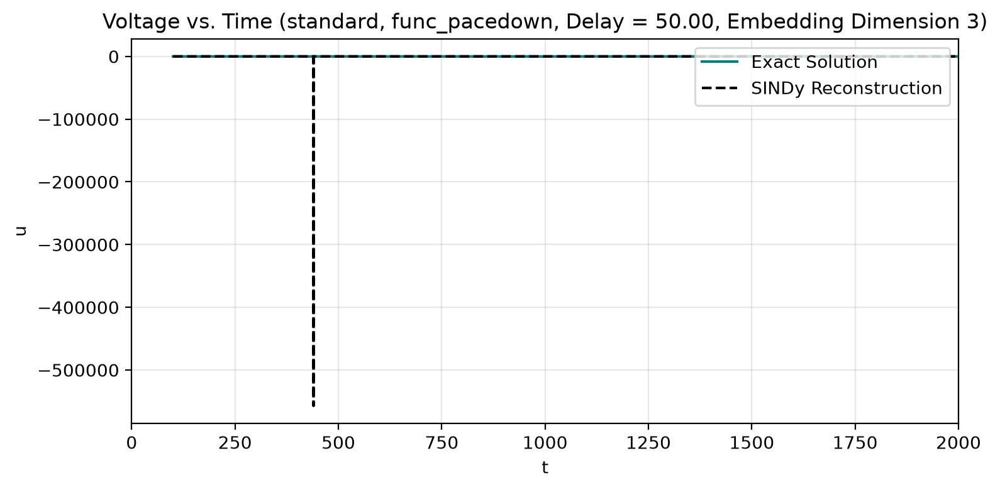



----------Fitting with tau = 52.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 52.0000 (delay_idx = 1040)
Embedding dimension = 3
(u(t-0))' = -0.204 u(t-0) +  0.400 u(t-0)^2 + -0.174 u(t-0)^3 + -0.117 u(t-1040) + -0.036 u(t-1040)^3 +  0.003 u(t-2080) + -0.032 u(t-2080)^2 + -0.283 u(t-0)*u(t-1040) +  0.154 u(t-0)*u(t-2080) + -0.012 1 +  1.584 f_td(t)
(u(t-1040))' =  0.404 u(t-0) + -1.018 u(t-0)^2 +  0.639 u(t-0)^3 +  0.112 u(t-1040) +  0.113 u(t-1040)^2 + -0.058 u(t-2080) +  0.290 u(t-2080)^2 + -0.110 u(t-2080)^3 +  0.057 u(t-0)*u(t-1040) +  0.098 u(t-0)*u(t-2080) + -0.004 1
(u(t-2080))' = -0.337 u(t-0) +  0.955 u(t-0)^2 + -0.645 u(t-0)^3 +  0.158 u(t-1040) + -0.115 u(t-1040)^2 + -0.054 u(t-2080) +  0.168 u(t-2080)^2 + -0.223 u(t-2080)^3 +  0.869 u(t-0)*u(t-1040) + -0.469 u(t-0)*u(t-2080) + -0.014 1 +  0.069 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_

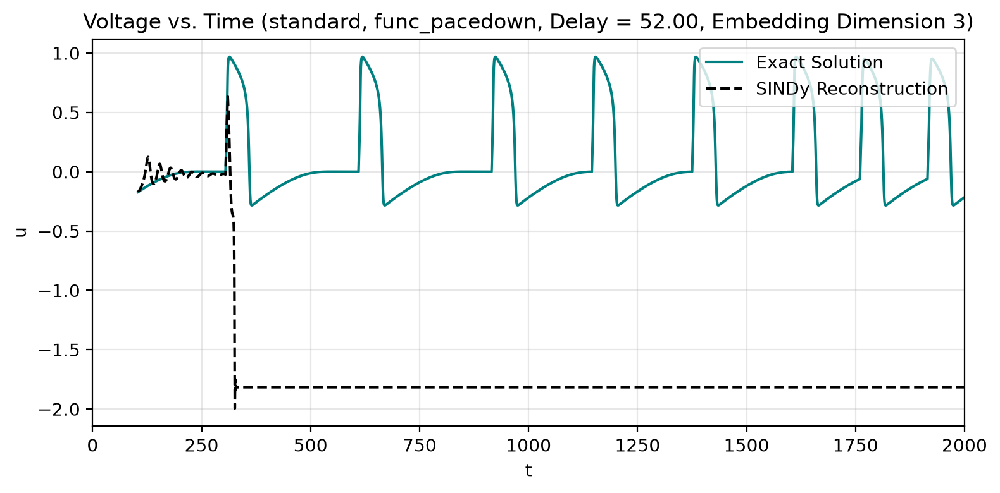



----------Fitting with tau = 54.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 54.0000 (delay_idx = 1080)
Embedding dimension = 3
(u(t-0))' = -0.059 u(t-0) +  0.006 u(t-0)^2 +  0.089 u(t-0)^3 + -0.101 u(t-1080) +  0.218 u(t-1080)^2 + -0.137 u(t-1080)^3 + -0.007 u(t-2160) + -0.052 u(t-2160)^2 +  0.041 u(t-2160)^3 + -0.070 u(t-0)*u(t-1080) +  0.121 u(t-0)*u(t-2160) + -0.013 1 +  1.519 f_td(t)
(u(t-1080))' =  0.085 u(t-0)^2 + -0.087 u(t-0)^3 +  0.044 u(t-1080) + -0.214 u(t-1080)^2 +  0.033 u(t-1080)^3 + -0.040 u(t-2160) +  0.146 u(t-2160)^2 + -0.016 u(t-2160)^3 + -0.473 u(t-0)*u(t-1080) +  0.215 u(t-0)*u(t-2160) + -0.007 1
(u(t-2160))' = -0.227 u(t-0) +  0.676 u(t-0)^2 + -0.472 u(t-0)^3 +  0.014 u(t-1080) +  0.023 u(t-1080)^2 +  0.092 u(t-1080)^3 +  0.011 u(t-2160)^2 + -0.140 u(t-2160)^3 +  0.866 u(t-0)*u(t-1080) + -0.403 u(t-0)*u(t-2160) + -0.006 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 4.66365e+02


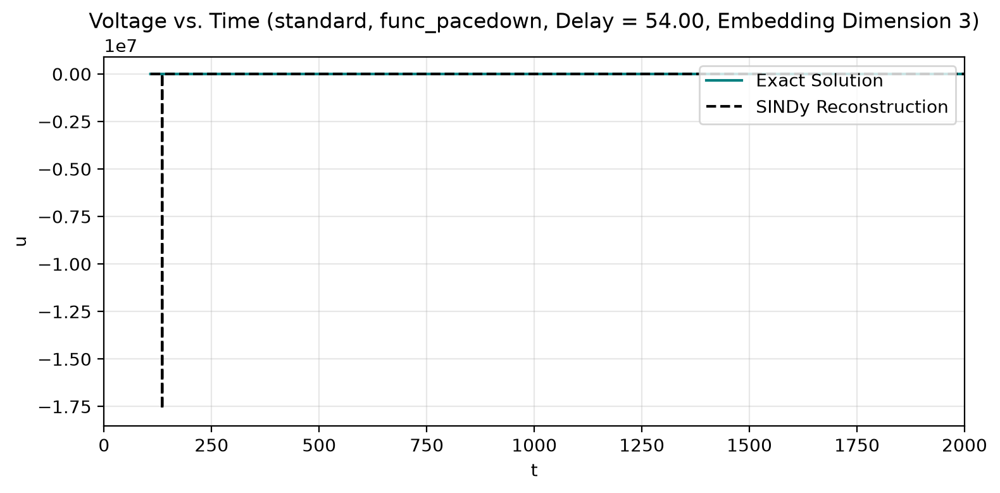



----------Fitting with tau = 56.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 56.0000 (delay_idx = 1120)
Embedding dimension = 3
(u(t-0))' = -0.049 u(t-0) + -0.028 u(t-0)^2 +  0.109 u(t-0)^3 + -0.023 u(t-1120) +  0.029 u(t-1120)^2 + -0.017 u(t-2240) +  0.032 u(t-2240)^2 + -0.013 u(t-0)*u(t-1120) +  0.083 u(t-0)*u(t-2240) + -0.011 1 +  1.521 f_td(t)
(u(t-1120))' = -0.157 u(t-0) +  0.520 u(t-0)^2 + -0.379 u(t-0)^3 +  0.032 u(t-1120) + -0.312 u(t-1120)^2 +  0.140 u(t-1120)^3 + -0.030 u(t-2240) +  0.134 u(t-2240)^2 + -0.070 u(t-2240)^3 + -0.253 u(t-0)*u(t-1120) +  0.052 u(t-0)*u(t-2240) + -0.010 1
(u(t-2240))' = -0.105 u(t-0) +  0.416 u(t-0)^2 + -0.310 u(t-0)^3 + -0.102 u(t-1120) +  0.461 u(t-1120)^2 + -0.258 u(t-1120)^3 + -0.017 u(t-2240) + -0.017 u(t-2240)^2 + -0.072 u(t-2240)^3 +  0.595 u(t-0)*u(t-1120) + -0.114 u(t-0)*u(t-2240) + -0.017 1 +  0.145 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


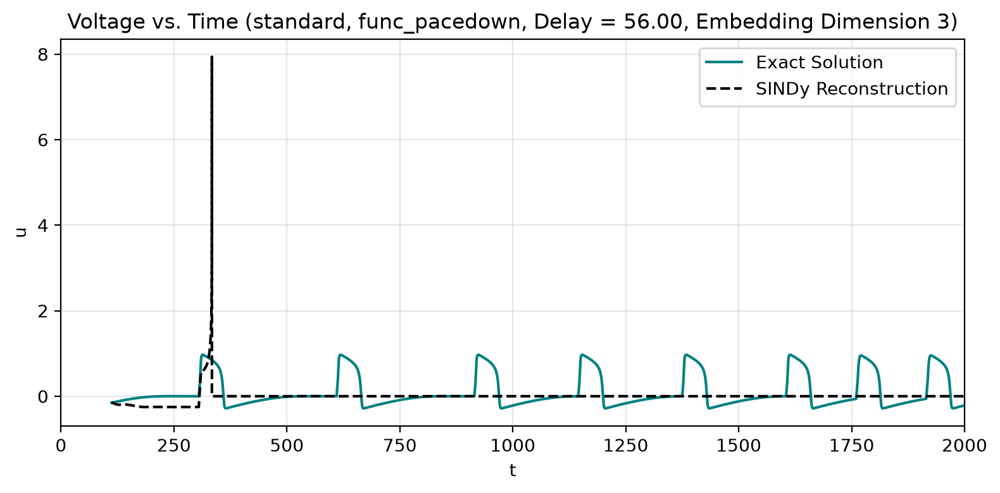



----------Fitting with tau = 58.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 58.0000 (delay_idx = 1160)
Embedding dimension = 3
(u(t-0))' = -0.040 u(t-0) + -0.035 u(t-0)^2 +  0.105 u(t-0)^3 + -0.019 u(t-1160) +  0.102 u(t-1160)^2 + -0.076 u(t-1160)^3 + -0.021 u(t-2320) +  0.030 u(t-2320)^2 +  0.006 u(t-0)*u(t-1160) +  0.053 u(t-0)*u(t-2320) + -0.013 1 +  1.527 f_td(t)
(u(t-1160))' = -0.128 u(t-0) +  0.439 u(t-0)^2 + -0.329 u(t-0)^3 +  0.014 u(t-1160) + -0.213 u(t-1160)^2 +  0.076 u(t-1160)^3 + -0.021 u(t-2320) +  0.101 u(t-2320)^2 + -0.061 u(t-2320)^3 + -0.250 u(t-0)*u(t-1160) + -0.010 1
(u(t-2320))' = -0.033 u(t-0) +  0.154 u(t-0)^2 + -0.128 u(t-0)^3 + -0.079 u(t-1160) +  0.352 u(t-1160)^2 + -0.209 u(t-1160)^3 +  0.013 u(t-2320) + -0.094 u(t-2320)^2 +  0.006 u(t-2320)^3 +  0.363 u(t-0)*u(t-1160) + -0.055 u(t-0)*u(t-2320) +  0.041 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 6.98354e+01


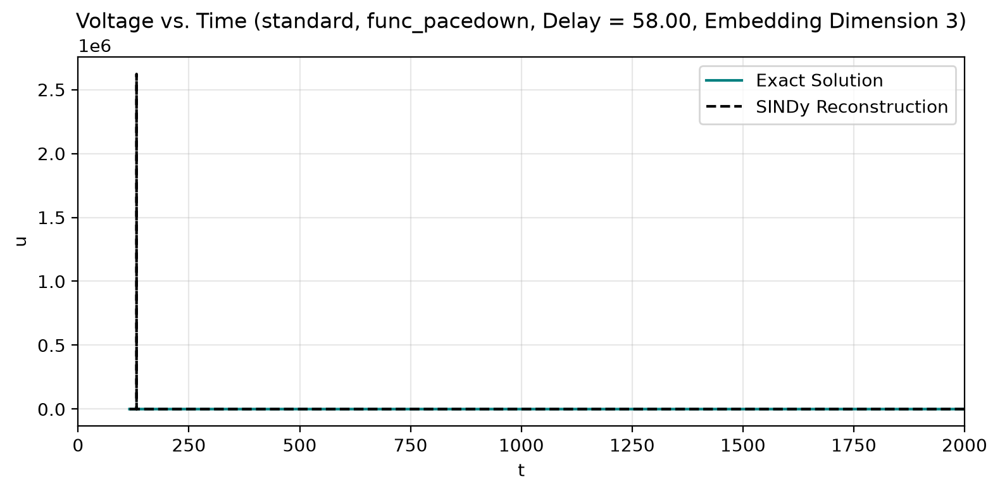



----------Fitting with tau = 60.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 60.0000 (delay_idx = 1200)
Embedding dimension = 3
(u(t-0))' = -0.044 u(t-0) + -0.029 u(t-0)^2 +  0.100 u(t-0)^3 + -0.015 u(t-1200) +  0.090 u(t-1200)^2 + -0.068 u(t-1200)^3 + -0.020 u(t-2400) +  0.029 u(t-2400)^2 +  0.012 u(t-0)*u(t-1200) +  0.032 u(t-0)*u(t-2400) + -0.013 1 +  1.534 f_td(t)
(u(t-1200))' = -0.100 u(t-0) +  0.349 u(t-0)^2 + -0.267 u(t-0)^3 +  0.002 u(t-1200) + -0.137 u(t-1200)^2 +  0.021 u(t-1200)^3 + -0.019 u(t-2400) +  0.078 u(t-2400)^2 + -0.045 u(t-2400)^3 + -0.278 u(t-0)*u(t-1200) + -0.016 u(t-0)*u(t-2400) + -0.010 1
(u(t-2400))' = -0.017 u(t-0) +  0.099 u(t-0)^2 + -0.085 u(t-0)^3 + -0.054 u(t-1200) +  0.290 u(t-1200)^2 + -0.175 u(t-1200)^3 +  0.011 u(t-2400) + -0.045 u(t-2400)^2 + -0.019 u(t-2400)^3 +  0.326 u(t-0)*u(t-1200) + -0.021 u(t-0)*u(t-2400) +  0.028 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 1.02657e+02


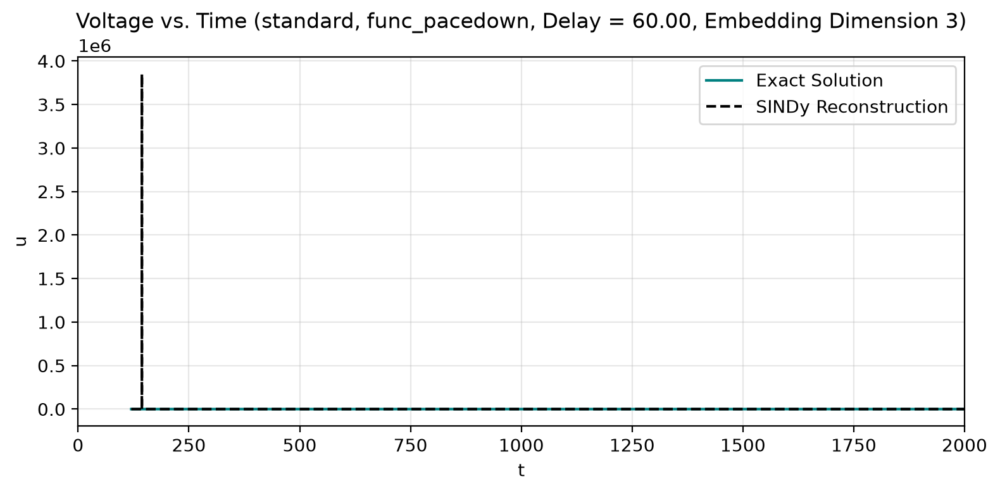



----------Fitting with tau = 62.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 62.0000 (delay_idx = 1240)
Embedding dimension = 3
(u(t-0))' = -0.051 u(t-0) + -0.027 u(t-0)^2 +  0.104 u(t-0)^3 + -0.012 u(t-1240) +  0.020 u(t-1240)^2 + -0.014 u(t-2480) +  0.025 u(t-2480)^2 +  0.017 u(t-0)*u(t-2480) + -0.011 1 +  1.537 f_td(t)
(u(t-1240))' = -0.084 u(t-0) +  0.284 u(t-0)^2 + -0.217 u(t-0)^3 + -0.007 u(t-1240) + -0.094 u(t-1240)^2 + -0.016 u(t-1240)^3 + -0.016 u(t-2480) +  0.061 u(t-2480)^2 + -0.034 u(t-2480)^3 + -0.328 u(t-0)*u(t-1240) + -0.035 u(t-0)*u(t-2480) + -0.010 1
(u(t-2480))' = -0.021 u(t-0) +  0.042 u(t-0)^2 + -0.057 u(t-1240) +  0.347 u(t-1240)^2 + -0.219 u(t-1240)^3 + -0.012 u(t-2480) + -0.025 u(t-2480)^3 +  0.320 u(t-0)*u(t-1240) + -0.005 u(t-0)*u(t-2480) + -0.011 1 +  0.106 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0]

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 2.49689e-01


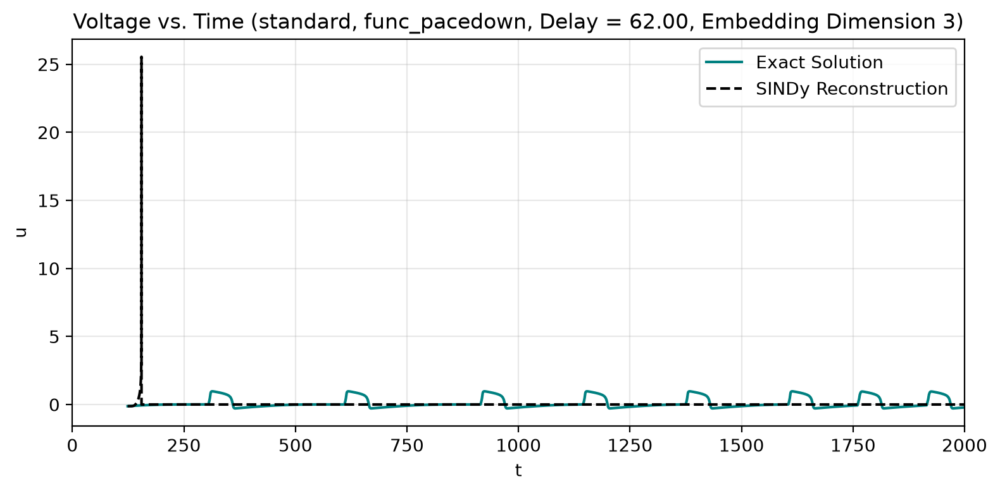



----------Fitting with tau = 64.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 64.0000 (delay_idx = 1280)
Embedding dimension = 3
(u(t-0))' = -0.050 u(t-0) + -0.031 u(t-0)^2 +  0.106 u(t-0)^3 + -0.013 u(t-1280) +  0.020 u(t-1280)^2 +  0.006 u(t-2560)^2 +  0.007 u(t-0)*u(t-2560) + -0.009 1 +  1.536 f_td(t)
(u(t-1280))' = -0.075 u(t-0) +  0.239 u(t-0)^2 + -0.181 u(t-0)^3 + -0.016 u(t-1280) + -0.064 u(t-1280)^2 + -0.045 u(t-1280)^3 + -0.014 u(t-2560) +  0.048 u(t-2560)^2 + -0.026 u(t-2560)^3 + -0.391 u(t-0)*u(t-1280) + -0.053 u(t-0)*u(t-2560) + -0.010 1
(u(t-2560))' = -0.021 u(t-0) +  0.125 u(t-0)^2 + -0.092 u(t-0)^3 + -0.051 u(t-1280) +  0.315 u(t-1280)^2 + -0.198 u(t-1280)^3 + -0.013 u(t-2560) + -0.013 u(t-2560)^3 +  0.325 u(t-0)*u(t-1280) +  0.011 u(t-0)*u(t-2560) + -0.012 1 +  0.074 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0],

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


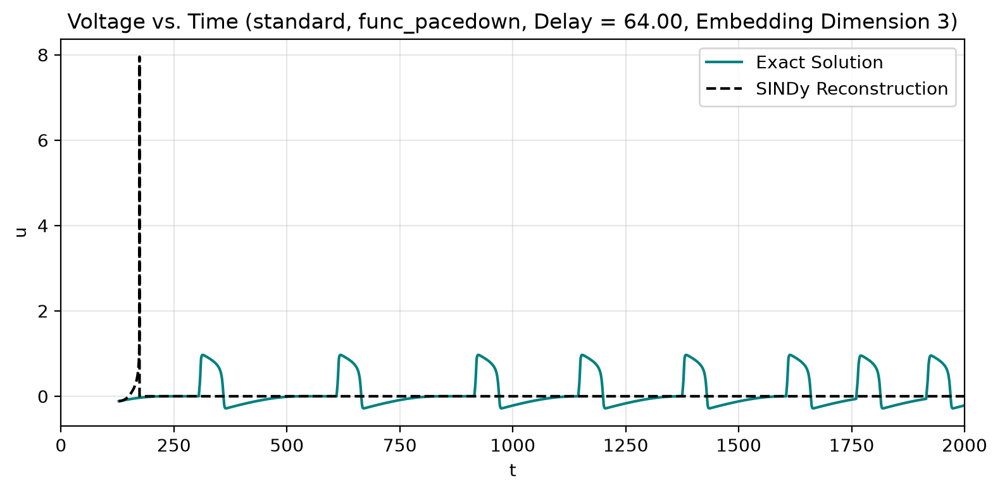



----------Fitting with tau = 66.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 66.0000 (delay_idx = 1320)
Embedding dimension = 3
(u(t-0))' = -0.048 u(t-0) + -0.027 u(t-0)^2 +  0.101 u(t-0)^3 + -0.014 u(t-1320) +  0.066 u(t-1320)^2 + -0.049 u(t-1320)^3 +  0.004 u(t-2640)^2 +  0.004 u(t-0)*u(t-2640) + -0.010 1 +  1.538 f_td(t)
(u(t-1320))' = -0.069 u(t-0) +  0.208 u(t-0)^2 + -0.156 u(t-0)^3 + -0.025 u(t-1320) + -0.041 u(t-1320)^2 + -0.071 u(t-1320)^3 + -0.013 u(t-2640) +  0.041 u(t-2640)^2 + -0.023 u(t-2640)^3 + -0.467 u(t-0)*u(t-1320) + -0.070 u(t-0)*u(t-2640) + -0.010 1
(u(t-2640))' = -0.032 u(t-0) +  0.128 u(t-0)^2 + -0.077 u(t-0)^3 + -0.018 u(t-1320) +  0.127 u(t-1320)^2 +  0.120 u(t-2640)^2 + -0.139 u(t-2640)^3 +  0.442 u(t-0)*u(t-1320) +  0.020 u(t-0)*u(t-2640) + -0.012 1 +  0.092 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.14702e+03


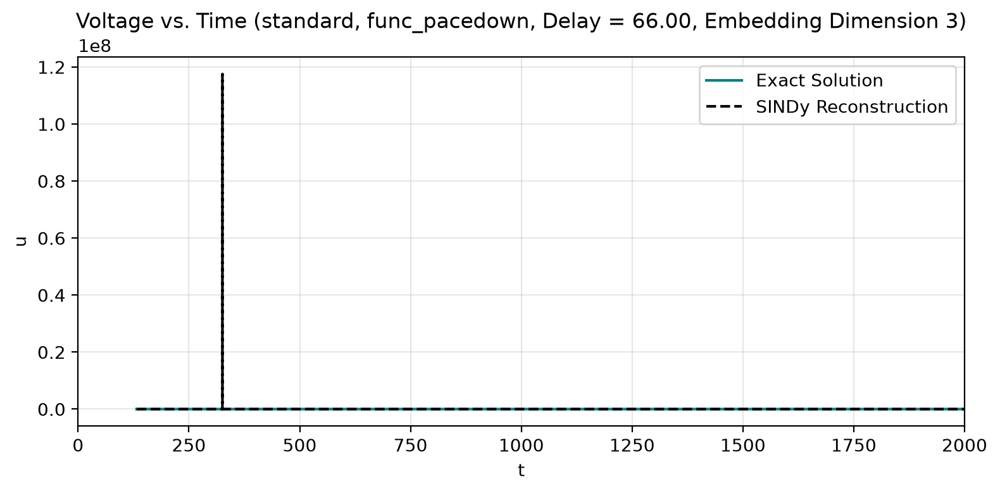



----------Fitting with tau = 68.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 68.0000 (delay_idx = 1360)
Embedding dimension = 3
(u(t-0))' = -0.050 u(t-0) + -0.023 u(t-0)^2 +  0.099 u(t-0)^3 + -0.013 u(t-1360) +  0.066 u(t-1360)^2 + -0.050 u(t-1360)^3 +  0.004 u(t-2720)^2 +  0.003 u(t-0)*u(t-2720) + -0.011 1 +  1.539 f_td(t)
(u(t-1360))' = -0.066 u(t-0) +  0.191 u(t-0)^2 + -0.142 u(t-0)^3 + -0.035 u(t-1360) + -0.020 u(t-1360)^2 + -0.097 u(t-1360)^3 + -0.012 u(t-2720) +  0.039 u(t-2720)^2 + -0.025 u(t-2720)^3 + -0.553 u(t-0)*u(t-1360) + -0.089 u(t-0)*u(t-2720) + -0.010 1
(u(t-2720))' = -0.032 u(t-0) +  0.100 u(t-0)^2 + -0.047 u(t-0)^3 + -0.017 u(t-1360) +  0.121 u(t-1360)^2 +  0.109 u(t-2720)^2 + -0.123 u(t-2720)^3 +  0.424 u(t-0)*u(t-1360) +  0.024 u(t-0)*u(t-2720) + -0.011 1 +  0.102 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


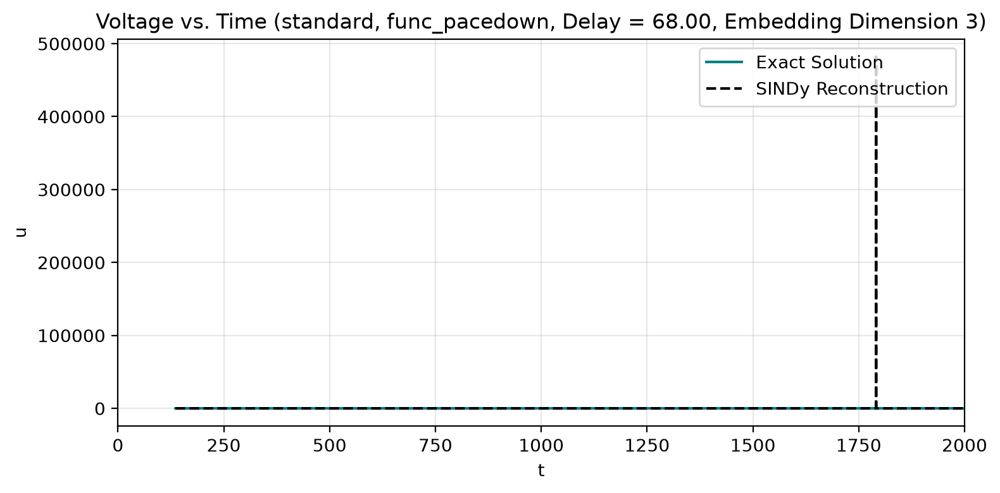



----------Fitting with tau = 70.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 70.0000 (delay_idx = 1400)
Embedding dimension = 3
(u(t-0))' = -0.051 u(t-0) + -0.020 u(t-0)^2 +  0.096 u(t-0)^3 + -0.013 u(t-1400) +  0.067 u(t-1400)^2 + -0.052 u(t-1400)^3 +  0.005 u(t-2800)^2 +  0.001 u(t-0)*u(t-2800) + -0.011 1 +  1.539 f_td(t)
(u(t-1400))' = -0.063 u(t-0) +  0.178 u(t-0)^2 + -0.136 u(t-0)^3 + -0.047 u(t-1400) + -0.007 u(t-1400)^2 + -0.119 u(t-1400)^3 + -0.013 u(t-2800) +  0.014 u(t-2800)^2 + -0.669 u(t-0)*u(t-1400) + -0.109 u(t-0)*u(t-2800) + -0.010 1
(u(t-2800))' = -0.033 u(t-0) +  0.075 u(t-0)^2 + -0.017 u(t-0)^3 + -0.017 u(t-1400) +  0.115 u(t-1400)^2 +  0.095 u(t-2800)^2 + -0.105 u(t-2800)^3 +  0.403 u(t-0)*u(t-1400) +  0.025 u(t-0)*u(t-2800) + -0.010 1 +  0.113 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [2]

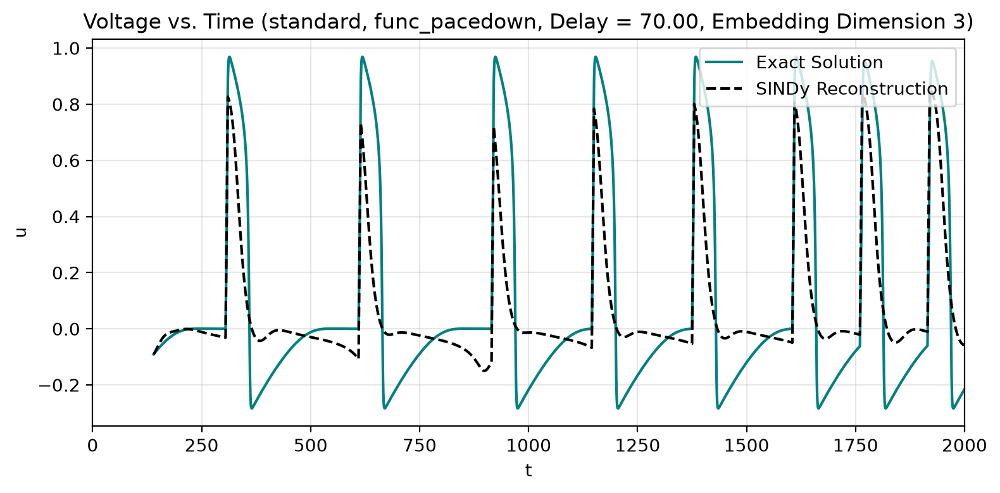



----------Fitting with tau = 72.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 72.0000 (delay_idx = 1440)
Embedding dimension = 3
(u(t-0))' = -0.052 u(t-0) + -0.013 u(t-0)^2 +  0.091 u(t-0)^3 + -0.013 u(t-1440) +  0.075 u(t-1440)^2 + -0.059 u(t-1440)^3 + -0.005 u(t-2880) +  0.012 u(t-2880)^2 + -0.012 1 +  1.537 f_td(t)
(u(t-1440))' = -0.060 u(t-0) +  0.183 u(t-0)^2 + -0.150 u(t-0)^3 + -0.057 u(t-1440) +  0.012 u(t-1440)^2 + -0.147 u(t-1440)^3 + -0.014 u(t-2880) +  0.014 u(t-2880)^2 + -0.776 u(t-0)*u(t-1440) + -0.128 u(t-0)*u(t-2880) + -0.011 1
(u(t-2880))' = -0.036 u(t-0) +  0.052 u(t-0)^2 +  0.012 u(t-0)^3 + -0.018 u(t-1440) +  0.109 u(t-1440)^2 +  0.081 u(t-2880)^2 + -0.087 u(t-2880)^3 +  0.382 u(t-0)*u(t-1440) +  0.026 u(t-0)*u(t-2880) + -0.010 1 +  0.125 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [2], [2], 

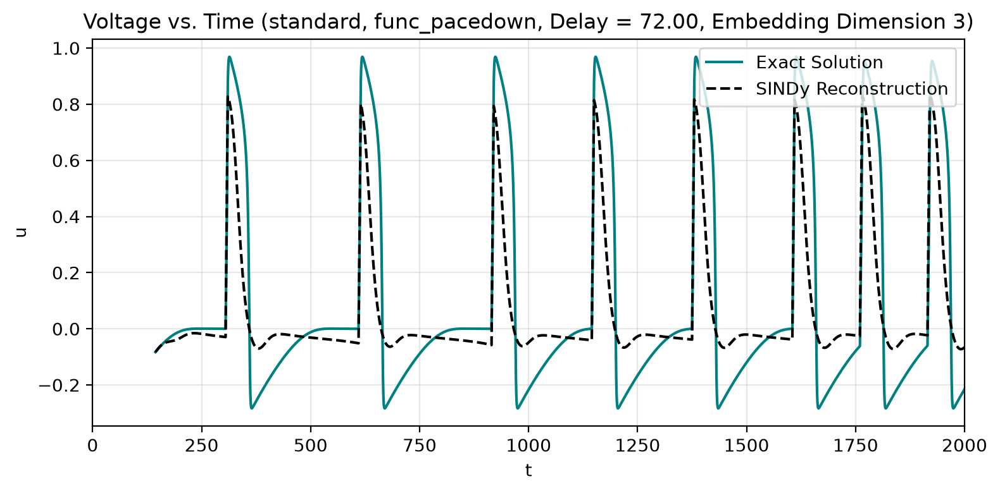



----------Fitting with tau = 74.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 74.0000 (delay_idx = 1480)
Embedding dimension = 3
(u(t-0))' = -0.055 u(t-0) + -0.004 u(t-0)^2 +  0.085 u(t-0)^3 + -0.012 u(t-1480) +  0.085 u(t-1480)^2 + -0.071 u(t-1480)^3 + -0.003 u(t-2960) +  0.048 u(t-2960)^2 + -0.041 u(t-2960)^3 + -0.014 1 +  1.545 f_td(t)
(u(t-1480))' = -0.055 u(t-0) +  0.197 u(t-0)^2 + -0.176 u(t-0)^3 + -0.066 u(t-1480) +  0.031 u(t-1480)^2 + -0.173 u(t-1480)^3 + -0.016 u(t-2960) +  0.015 u(t-2960)^2 + -0.877 u(t-0)*u(t-1480) + -0.146 u(t-0)*u(t-2960) + -0.012 1
(u(t-2960))' = -0.040 u(t-0) +  0.036 u(t-0)^2 +  0.036 u(t-0)^3 + -0.019 u(t-1480) +  0.103 u(t-1480)^2 +  0.067 u(t-2960)^2 + -0.071 u(t-2960)^3 +  0.357 u(t-0)*u(t-1480) +  0.026 u(t-0)*u(t-2960) + -0.010 1 +  0.161 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1],

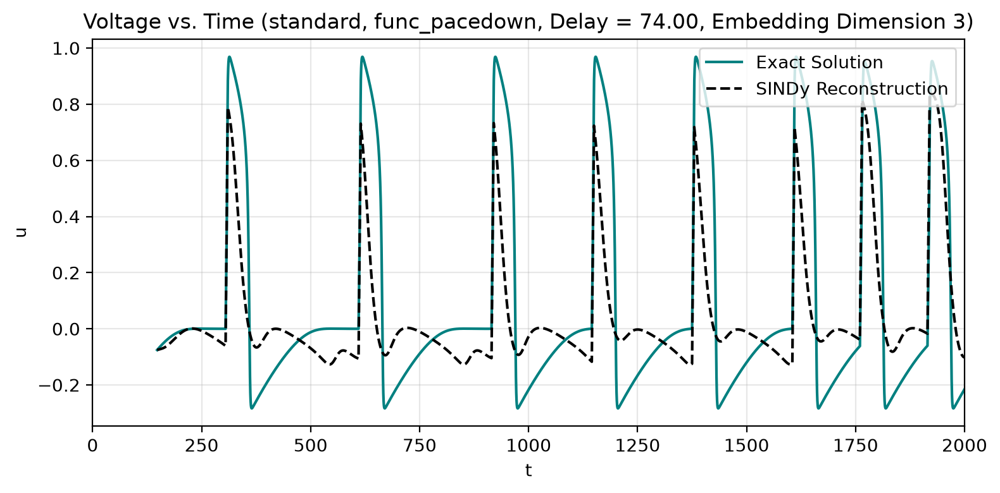



----------Fitting with tau = 76.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 76.0000 (delay_idx = 1520)
Embedding dimension = 3
(u(t-0))' = -0.055 u(t-0) +  0.013 u(t-0)^2 +  0.069 u(t-0)^3 + -0.013 u(t-1520) +  0.103 u(t-1520)^2 + -0.088 u(t-1520)^3 + -0.013 u(t-3040) +  0.069 u(t-3040)^2 + -0.046 u(t-3040)^3 + -0.004 u(t-0)*u(t-1520) + -0.008 u(t-0)*u(t-3040) + -0.017 1 +  1.537 f_td(t)
(u(t-1520))' = -0.051 u(t-0) +  0.221 u(t-0)^2 + -0.208 u(t-0)^3 + -0.067 u(t-1520) +  0.063 u(t-1520)^2 + -0.204 u(t-1520)^3 + -0.016 u(t-3040) +  0.081 u(t-3040)^2 + -0.071 u(t-3040)^3 + -0.902 u(t-0)*u(t-1520) + -0.152 u(t-0)*u(t-3040) + -0.016 1
(u(t-3040))' = -0.039 u(t-0) +  0.059 u(t-0)^2 +  0.006 u(t-0)^3 + -0.032 u(t-1520) +  0.195 u(t-1520)^2 + -0.136 u(t-1520)^3 +  0.152 u(t-0)*u(t-1520) + -0.003 u(t-0)*u(t-3040) + -0.012 1 +  0.362 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 

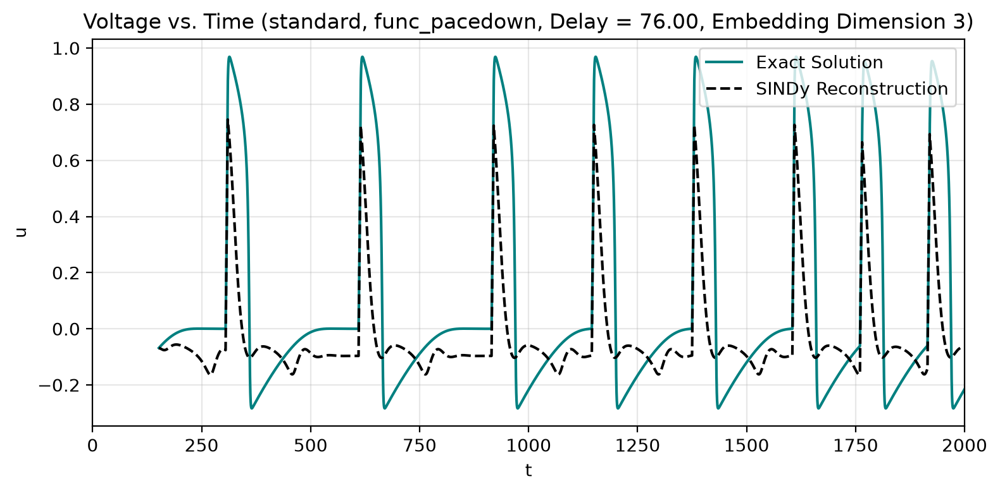



----------Fitting with tau = 78.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 78.0000 (delay_idx = 1560)
Embedding dimension = 3
(u(t-0))' = -0.059 u(t-0) +  0.030 u(t-0)^2 +  0.054 u(t-0)^3 + -0.020 u(t-1560) +  0.133 u(t-1560)^2 + -0.121 u(t-1560)^3 + -0.019 u(t-3120) +  0.118 u(t-3120)^2 + -0.093 u(t-3120)^3 + -0.050 u(t-0)*u(t-1560) + -0.021 u(t-0)*u(t-3120) + -0.020 1 +  1.535 f_td(t)
(u(t-1560))' = -0.046 u(t-0) +  0.202 u(t-0)^2 + -0.196 u(t-0)^3 + -0.053 u(t-1560) +  0.039 u(t-1560)^2 + -0.165 u(t-1560)^3 + -0.019 u(t-3120) +  0.024 u(t-3120)^2 + -0.793 u(t-0)*u(t-1560) + -0.131 u(t-0)*u(t-3120) + -0.012 1
(u(t-3120))' = -0.018 u(t-0) +  0.110 u(t-0)^2 + -0.092 u(t-0)^3 + -0.054 u(t-1560) +  0.204 u(t-1560)^2 + -0.200 u(t-1560)^3 + -0.222 u(t-0)*u(t-1560) + -0.055 u(t-0)*u(t-3120) + -0.015 1 +  0.233 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_pe

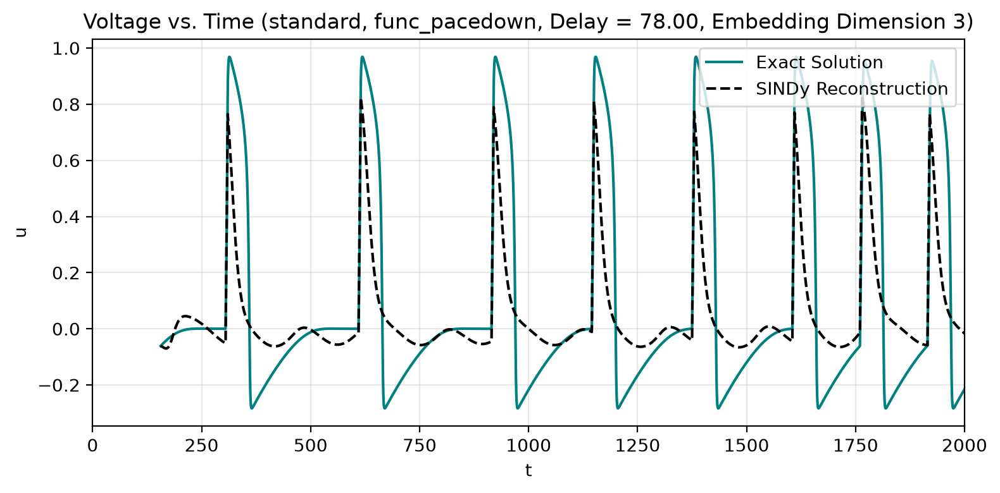



----------Fitting with tau = 80.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 80.0000 (delay_idx = 1600)
Embedding dimension = 3
(u(t-0))' = -0.057 u(t-0) +  0.027 u(t-0)^2 +  0.048 u(t-0)^3 + -0.029 u(t-1600) +  0.123 u(t-1600)^2 + -0.120 u(t-1600)^3 + -0.021 u(t-3200) +  0.059 u(t-3200)^2 + -0.031 u(t-3200)^3 + -0.140 u(t-0)*u(t-1600) + -0.038 u(t-0)*u(t-3200) + -0.018 1 +  1.494 f_td(t)
(u(t-1600))' = -0.042 u(t-0) +  0.186 u(t-0)^2 + -0.175 u(t-0)^3 + -0.027 u(t-1600) +  0.031 u(t-1600)^2 + -0.122 u(t-1600)^3 + -0.022 u(t-3200) +  0.035 u(t-3200)^2 + -0.527 u(t-0)*u(t-1600) + -0.088 u(t-0)*u(t-3200) + -0.012 1
(u(t-3200))' = -0.011 u(t-0) +  0.016 u(t-0)^3 + -0.054 u(t-1600) +  0.175 u(t-1600)^2 + -0.186 u(t-1600)^3 +  0.020 u(t-3200)^2 + -0.035 u(t-3200)^3 + -0.317 u(t-0)*u(t-1600) + -0.049 u(t-0)*u(t-3200) + -0.010 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
in

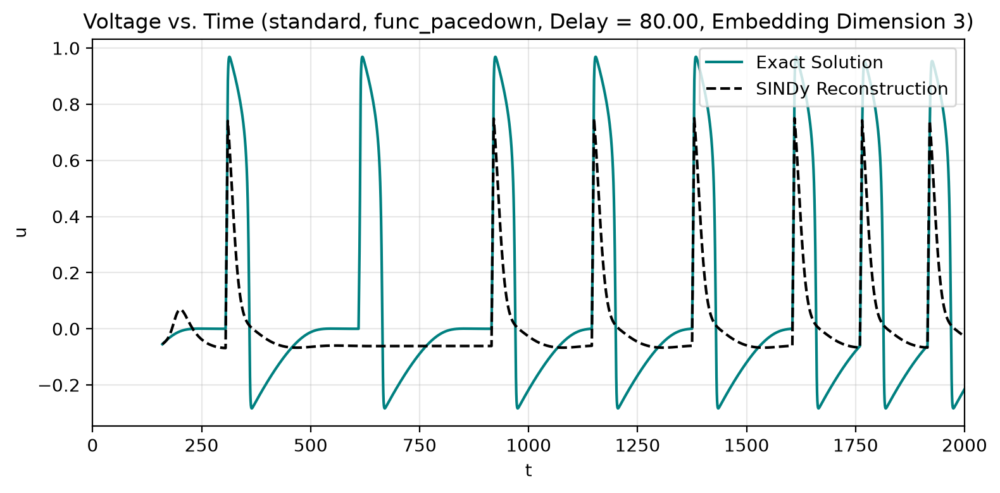



----------Fitting with tau = 82.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 82.0000 (delay_idx = 1640)
Embedding dimension = 3
(u(t-0))' = -0.056 u(t-0) +  0.026 u(t-0)^2 +  0.048 u(t-0)^3 + -0.025 u(t-1640) +  0.120 u(t-1640)^2 + -0.111 u(t-1640)^3 + -0.021 u(t-3280) +  0.046 u(t-3280)^2 + -0.015 u(t-3280)^3 + -0.095 u(t-0)*u(t-1640) + -0.031 u(t-0)*u(t-3280) + -0.017 1 +  1.500 f_td(t)
(u(t-1640))' = -0.036 u(t-0) +  0.173 u(t-0)^2 + -0.162 u(t-0)^3 + -0.017 u(t-1640) +  0.025 u(t-1640)^2 + -0.086 u(t-1640)^3 + -0.022 u(t-3280) +  0.038 u(t-3280)^2 + -0.356 u(t-0)*u(t-1640) + -0.060 u(t-0)*u(t-3280) + -0.011 1
(u(t-3280))' = -0.010 u(t-0) + -0.012 u(t-0)^2 +  0.035 u(t-0)^3 + -0.040 u(t-1640) +  0.164 u(t-1640)^2 + -0.159 u(t-1640)^3 +  0.032 u(t-3280)^2 + -0.045 u(t-3280)^3 + -0.181 u(t-0)*u(t-1640) + -0.020 u(t-0)*u(t-3280) + -0.010 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '

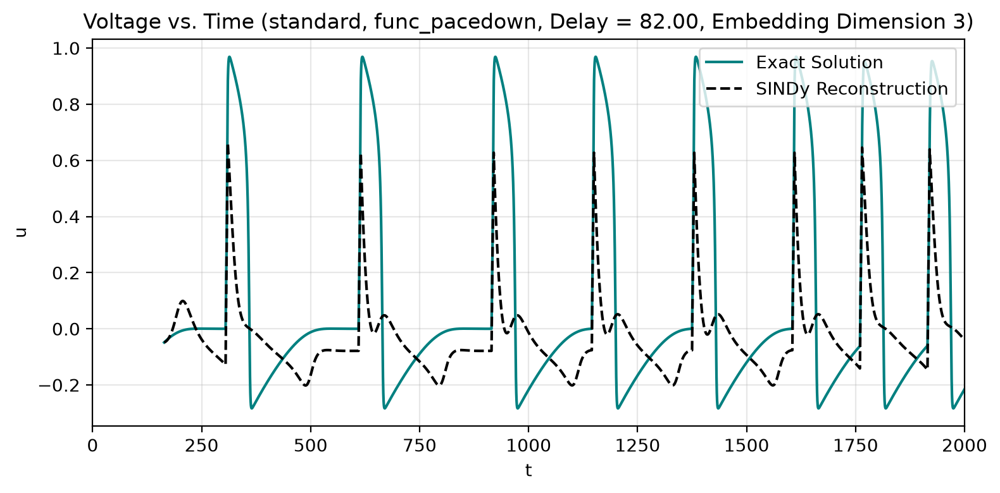



----------Fitting with tau = 84.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 84.0000 (delay_idx = 1680)
Embedding dimension = 3
(u(t-0))' = -0.057 u(t-0) +  0.023 u(t-0)^2 +  0.054 u(t-0)^3 + -0.022 u(t-1680) +  0.119 u(t-1680)^2 + -0.105 u(t-1680)^3 + -0.018 u(t-3360) +  0.044 u(t-3360)^2 + -0.018 u(t-3360)^3 + -0.054 u(t-0)*u(t-1680) + -0.022 u(t-0)*u(t-3360) + -0.016 1 +  1.510 f_td(t)
(u(t-1680))' = -0.033 u(t-0) +  0.162 u(t-0)^2 + -0.153 u(t-0)^3 + -0.013 u(t-1680) +  0.028 u(t-1680)^2 + -0.075 u(t-1680)^3 + -0.022 u(t-3360) +  0.038 u(t-3360)^2 + -0.278 u(t-0)*u(t-1680) + -0.047 u(t-0)*u(t-3360) + -0.011 1
(u(t-3360))' = -0.006 u(t-0) + -0.003 u(t-0)^2 +  0.024 u(t-0)^3 + -0.034 u(t-1680) +  0.163 u(t-1680)^2 + -0.146 u(t-1680)^3 +  0.042 u(t-3360)^2 + -0.055 u(t-3360)^3 + -0.097 u(t-0)*u(t-1680) + -0.010 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per

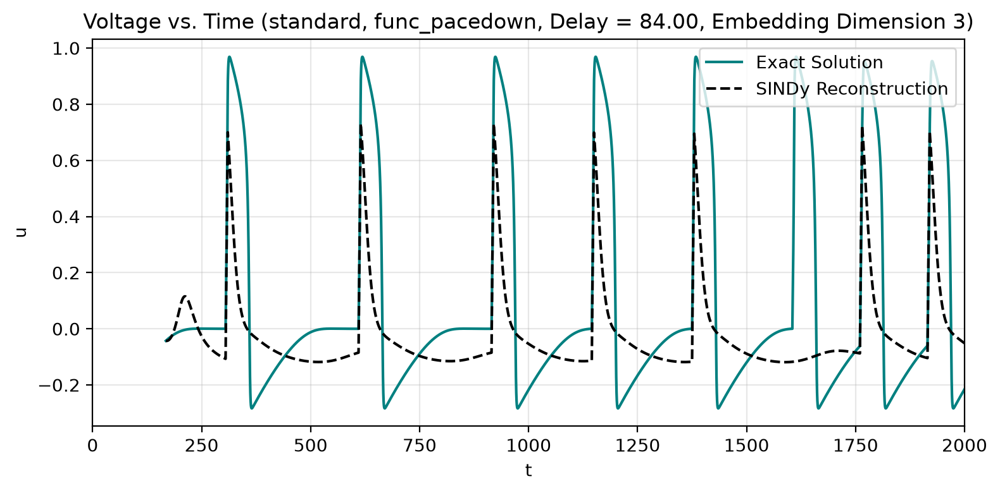



----------Fitting with tau = 86.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 86.0000 (delay_idx = 1720)
Embedding dimension = 3
(u(t-0))' = -0.055 u(t-0) +  0.008 u(t-0)^2 +  0.067 u(t-0)^3 + -0.019 u(t-1720) +  0.097 u(t-1720)^2 + -0.083 u(t-1720)^3 + -0.010 u(t-3440) +  0.018 u(t-3440)^3 + -0.041 u(t-0)*u(t-1720) + -0.019 u(t-0)*u(t-3440) + -0.013 1 +  1.522 f_td(t)
(u(t-1720))' = -0.031 u(t-0) +  0.151 u(t-0)^2 + -0.142 u(t-0)^3 + -0.009 u(t-1720) +  0.029 u(t-1720)^2 + -0.068 u(t-1720)^3 + -0.022 u(t-3440) +  0.038 u(t-3440)^2 + -0.235 u(t-0)*u(t-1720) + -0.040 u(t-0)*u(t-3440) + -0.011 1
(u(t-3440))' =  0.014 u(t-0)^2 + -0.001 u(t-0)^3 + -0.033 u(t-1720) +  0.173 u(t-1720)^2 + -0.148 u(t-1720)^3 + -0.008 u(t-3440) +  0.059 u(t-3440)^2 + -0.061 u(t-3440)^3 + -0.055 u(t-0)*u(t-1720) +  0.009 u(t-0)*u(t-3440) + -0.011 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
in

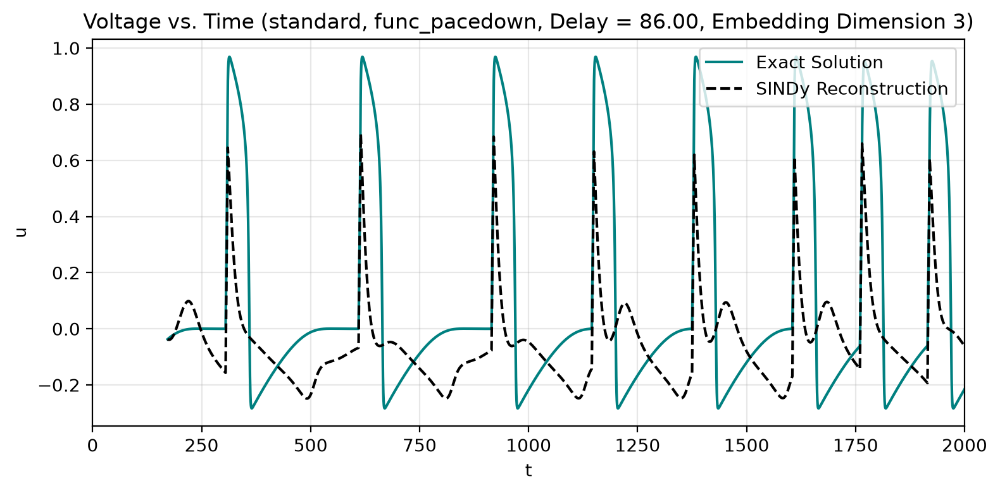



----------Fitting with tau = 88.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 88.0000 (delay_idx = 1760)
Embedding dimension = 3
(u(t-0))' = -0.054 u(t-0) +  0.076 u(t-0)^3 + -0.019 u(t-1760) +  0.091 u(t-1760)^2 + -0.075 u(t-1760)^3 + -0.028 u(t-0)*u(t-1760) + -0.012 u(t-0)*u(t-3520) + -0.012 1 +  1.527 f_td(t)
(u(t-1760))' = -0.030 u(t-0) +  0.141 u(t-0)^2 + -0.132 u(t-0)^3 + -0.007 u(t-1760) +  0.028 u(t-1760)^2 + -0.063 u(t-1760)^3 + -0.022 u(t-3520) +  0.038 u(t-3520)^2 + -0.206 u(t-0)*u(t-1760) + -0.034 u(t-0)*u(t-3520) + -0.010 1
(u(t-3520))' =  0.004 u(t-0) +  0.014 u(t-0)^2 + -0.008 u(t-0)^3 + -0.032 u(t-1760) +  0.141 u(t-1760)^2 + -0.116 u(t-1760)^3 + -0.009 u(t-3520)^3 + -0.047 u(t-0)*u(t-1760) +  0.014 u(t-0)*u(t-3520) + -0.007 1 + -0.264 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [2], [2], [2], [

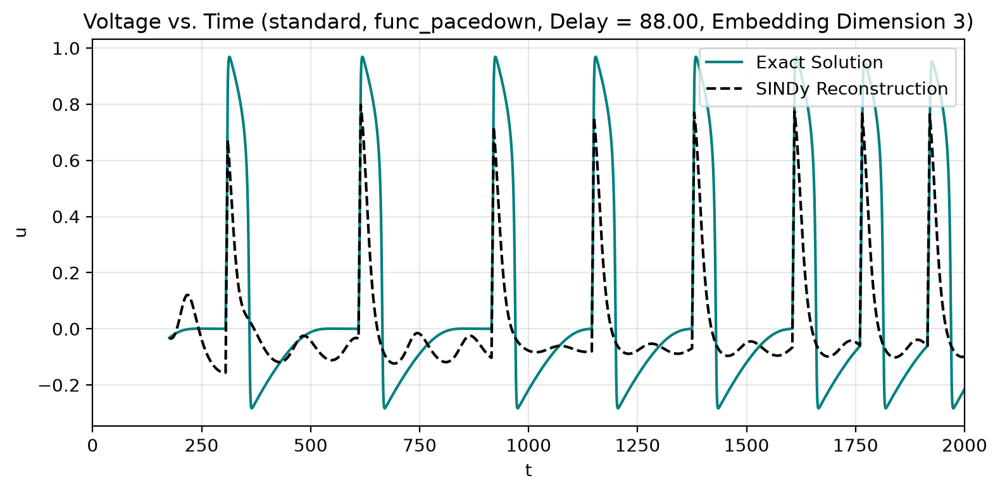



----------Fitting with tau = 90.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 90.0000 (delay_idx = 1800)
Embedding dimension = 3
(u(t-0))' = -0.057 u(t-0) +  0.002 u(t-0)^2 +  0.080 u(t-0)^3 + -0.017 u(t-1800) +  0.098 u(t-1800)^2 + -0.080 u(t-1800)^3 + -0.004 u(t-3600) +  0.008 u(t-3600)^2 + -0.007 u(t-0)*u(t-1800) + -0.006 u(t-0)*u(t-3600) + -0.013 1 +  1.548 f_td(t)
(u(t-1800))' = -0.028 u(t-0) +  0.131 u(t-0)^2 + -0.123 u(t-0)^3 +  0.024 u(t-1800)^2 + -0.062 u(t-1800)^3 + -0.023 u(t-3600) +  0.039 u(t-3600)^2 + -0.191 u(t-0)*u(t-1800) + -0.030 u(t-0)*u(t-3600) + -0.010 1
(u(t-3600))' =  0.017 u(t-0) + -0.018 u(t-0)^2 + -0.026 u(t-1800) +  0.096 u(t-1800)^2 + -0.076 u(t-1800)^3 +  0.005 u(t-3600) + -0.019 u(t-3600)^3 + -0.039 u(t-0)*u(t-1800) +  0.023 u(t-0)*u(t-3600) + -0.403 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1

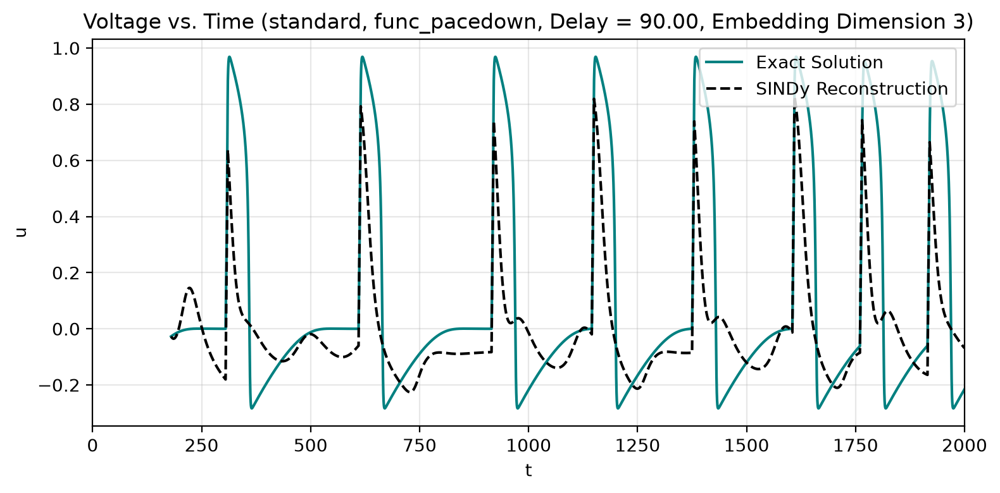



----------Fitting with tau = 92.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 92.0000 (delay_idx = 1840)
Embedding dimension = 3
(u(t-0))' = -0.058 u(t-0) +  0.008 u(t-0)^2 +  0.078 u(t-0)^3 + -0.017 u(t-1840) +  0.112 u(t-1840)^2 + -0.092 u(t-1840)^3 +  0.004 u(t-3680) +  0.052 u(t-3680)^2 + -0.060 u(t-3680)^3 +  0.004 u(t-0)*u(t-1840) + -0.015 1 +  1.531 f_td(t)
(u(t-1840))' = -0.032 u(t-0) +  0.115 u(t-0)^2 + -0.095 u(t-0)^3 +  0.023 u(t-1840)^2 + -0.055 u(t-1840)^3 + -0.023 u(t-3680) +  0.039 u(t-3680)^2 + -0.164 u(t-0)*u(t-1840) + -0.018 u(t-0)*u(t-3680) + -0.010 1 +  0.052 f_td(t)
(u(t-3680))' =  0.030 u(t-0) +  0.068 u(t-0)^2 + -0.124 u(t-0)^3 + -0.031 u(t-1840) +  0.129 u(t-1840)^2 + -0.104 u(t-1840)^3 + -0.008 u(t-3680)^3 + -0.054 u(t-0)*u(t-1840) + -0.004 u(t-0)*u(t-3680) + -0.004 1 + -0.214 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libar

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


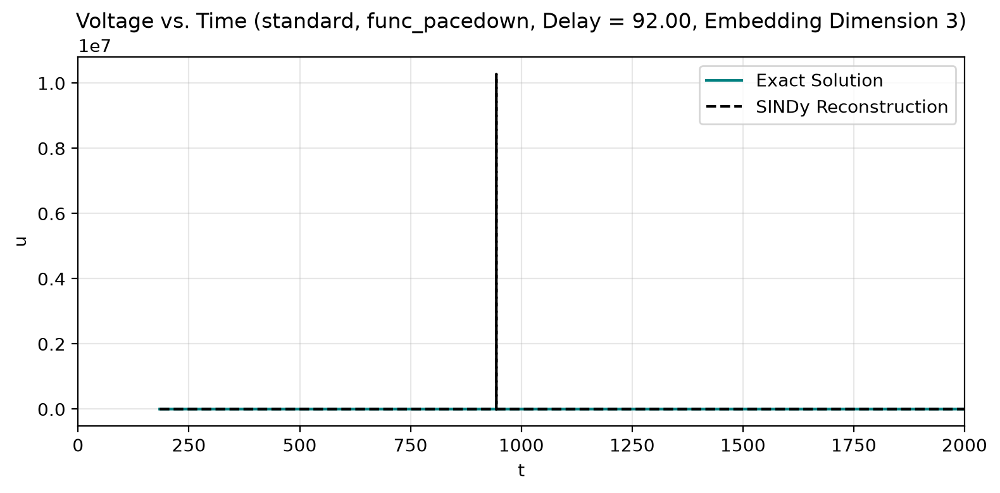



----------Fitting with tau = 94.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 94.0000 (delay_idx = 1880)
Embedding dimension = 3
(u(t-0))' = -0.059 u(t-0) +  0.012 u(t-0)^2 +  0.072 u(t-0)^3 + -0.018 u(t-1880) +  0.121 u(t-1880)^2 + -0.099 u(t-1880)^3 +  0.003 u(t-3760) +  0.069 u(t-3760)^2 + -0.078 u(t-3760)^3 +  0.006 u(t-0)*u(t-1880) + -0.016 1 +  1.525 f_td(t)
(u(t-1880))' = -0.033 u(t-0) +  0.103 u(t-0)^2 + -0.079 u(t-0)^3 +  0.021 u(t-1880)^2 + -0.049 u(t-1880)^3 + -0.023 u(t-3760) +  0.038 u(t-3760)^2 + -0.146 u(t-0)*u(t-1880) + -0.007 u(t-0)*u(t-3760) + -0.009 1
(u(t-3760))' =  0.033 u(t-0) +  0.098 u(t-0)^2 + -0.164 u(t-0)^3 + -0.032 u(t-1880) +  0.126 u(t-1880)^2 + -0.098 u(t-1880)^3 + -0.008 u(t-3760)^3 + -0.039 u(t-0)*u(t-1880) + -0.004 1 + -0.166 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [2], [2]

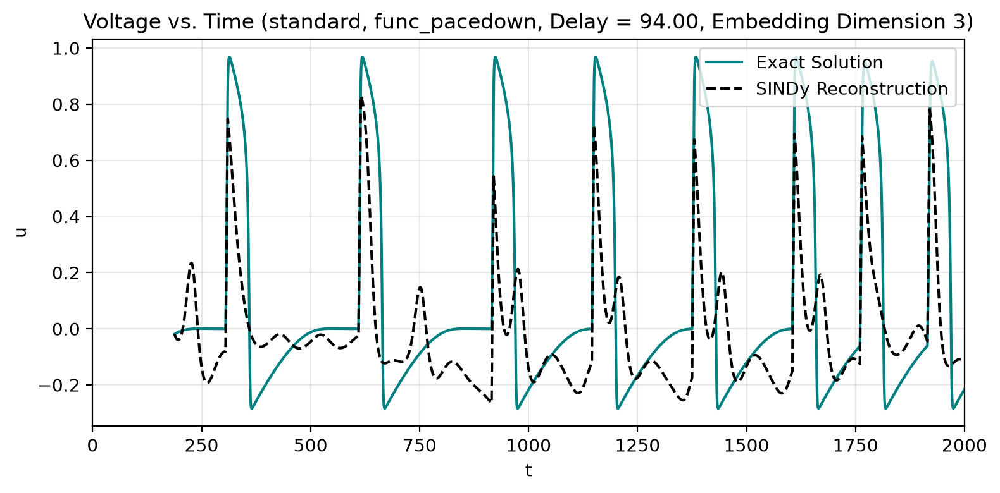



----------Fitting with tau = 96.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 96.0000 (delay_idx = 1920)
Embedding dimension = 3
(u(t-0))' = -0.059 u(t-0) +  0.015 u(t-0)^2 +  0.069 u(t-0)^3 + -0.018 u(t-1920) +  0.124 u(t-1920)^2 + -0.101 u(t-1920)^3 +  0.004 u(t-3840) +  0.073 u(t-3840)^2 + -0.084 u(t-3840)^3 +  0.009 u(t-0)*u(t-1920) + -0.016 1 +  1.524 f_td(t)
(u(t-1920))' = -0.033 u(t-0) +  0.099 u(t-0)^2 + -0.072 u(t-0)^3 +  0.024 u(t-1920)^2 + -0.049 u(t-1920)^3 + -0.024 u(t-3840) +  0.040 u(t-3840)^2 + -0.136 u(t-0)*u(t-1920) + -0.010 1
(u(t-3840))' =  0.034 u(t-0) +  0.102 u(t-0)^2 + -0.173 u(t-0)^3 + -0.030 u(t-1920) +  0.114 u(t-1920)^2 + -0.087 u(t-1920)^3 +  0.007 u(t-3840) + -0.016 u(t-3840)^3 + -0.032 u(t-0)*u(t-1920) + -0.003 1 + -0.152 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [2], [2], [2], 

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 1.93395e+02


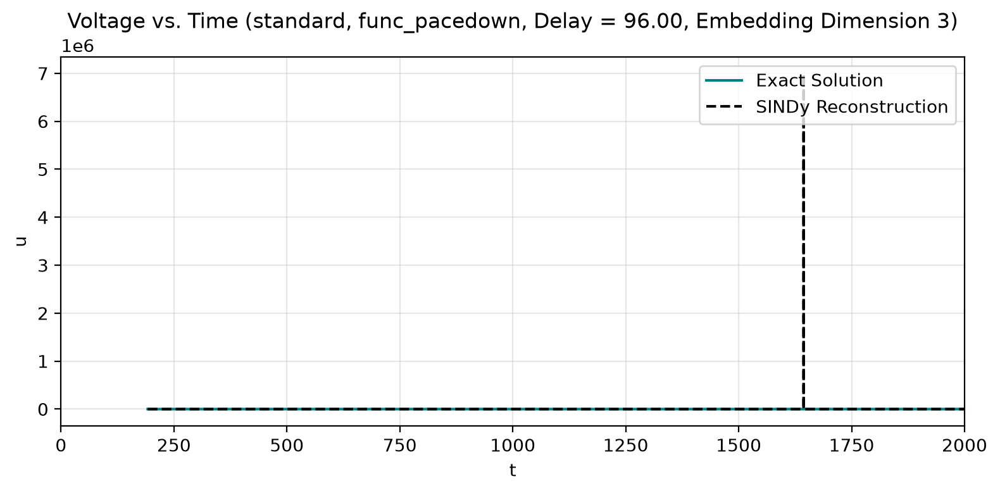



----------Fitting with tau = 98.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 98.0000 (delay_idx = 1960)
Embedding dimension = 3
(u(t-0))' = -0.059 u(t-0) +  0.016 u(t-0)^2 +  0.069 u(t-0)^3 + -0.019 u(t-1960) +  0.126 u(t-1960)^2 + -0.102 u(t-1960)^3 +  0.005 u(t-3920) +  0.072 u(t-3920)^2 + -0.086 u(t-3920)^3 +  0.013 u(t-0)*u(t-1960) + -0.015 1 +  1.529 f_td(t)
(u(t-1960))' = -0.032 u(t-0) +  0.096 u(t-0)^2 + -0.070 u(t-0)^3 + -0.001 u(t-1960) +  0.024 u(t-1960)^2 + -0.046 u(t-1960)^3 + -0.023 u(t-3920) +  0.039 u(t-3920)^2 + -0.131 u(t-0)*u(t-1960) + -0.010 1
(u(t-3920))' =  0.034 u(t-0) +  0.094 u(t-0)^2 + -0.165 u(t-0)^3 + -0.027 u(t-1960) +  0.104 u(t-1960)^2 + -0.078 u(t-1960)^3 +  0.010 u(t-3920) + -0.017 u(t-3920)^3 + -0.027 u(t-0)*u(t-1960) + -0.002 1 + -0.138 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.33274e+03


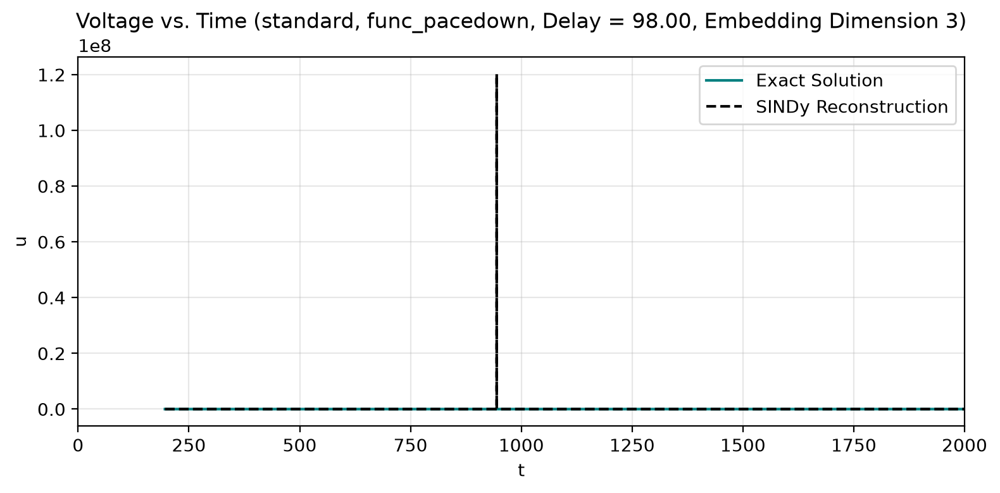



----------Fitting with tau = 100.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 100.0000 (delay_idx = 2000)
Embedding dimension = 3
(u(t-0))' = -0.061 u(t-0) +  0.018 u(t-0)^2 +  0.069 u(t-0)^3 + -0.020 u(t-2000) +  0.131 u(t-2000)^2 + -0.106 u(t-2000)^3 +  0.003 u(t-4000) +  0.056 u(t-4000)^2 + -0.065 u(t-4000)^3 +  0.018 u(t-0)*u(t-2000) + -0.016 1 +  1.546 f_td(t)
(u(t-2000))' = -0.028 u(t-0) +  0.094 u(t-0)^2 + -0.074 u(t-0)^3 +  0.020 u(t-2000)^2 + -0.041 u(t-2000)^3 + -0.020 u(t-4000) +  0.034 u(t-4000)^2 + -0.127 u(t-0)*u(t-2000) + -0.009 1 + -0.068 f_td(t)
(u(t-4000))' =  0.032 u(t-0) +  0.051 u(t-0)^2 + -0.120 u(t-0)^3 + -0.031 u(t-2000) +  0.038 u(t-2000)^2 +  0.007 u(t-4000) +  0.044 u(t-4000)^2 + -0.061 u(t-4000)^3 + -0.030 u(t-0)*u(t-2000) + -0.001 u(t-0)*u(t-4000) + -0.116 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [

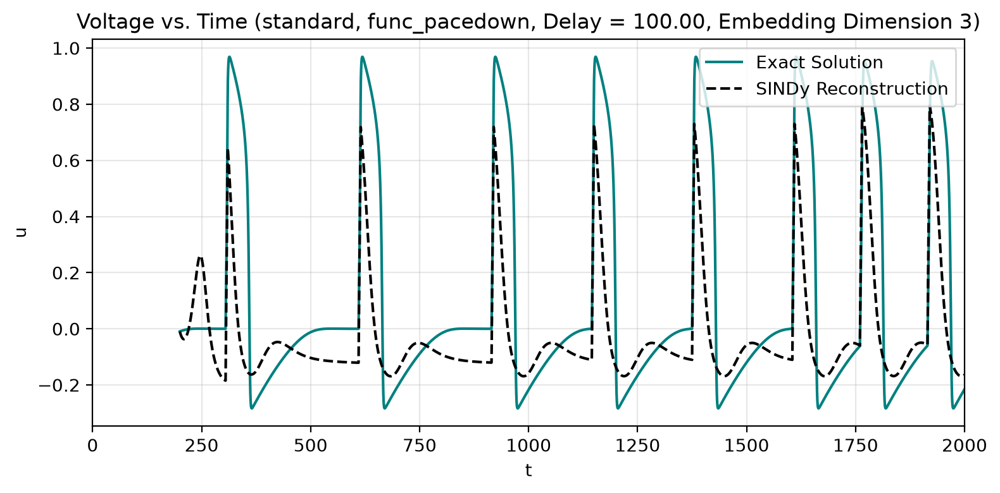



----------Fitting with tau = 102.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 102.0000 (delay_idx = 2040)
Embedding dimension = 3
(u(t-0))' = -0.061 u(t-0) +  0.021 u(t-0)^2 +  0.067 u(t-0)^3 + -0.020 u(t-2040) +  0.134 u(t-2040)^2 + -0.107 u(t-2040)^3 + -0.007 u(t-4080) +  0.015 u(t-4080)^2 + -0.001 u(t-4080)^3 +  0.020 u(t-0)*u(t-2040) +  0.004 u(t-0)*u(t-4080) + -0.016 1 +  1.556 f_td(t)
(u(t-2040))' = -0.024 u(t-0) +  0.086 u(t-0)^2 + -0.071 u(t-0)^3 +  0.003 u(t-2040) +  0.006 u(t-2040)^2 + -0.029 u(t-2040)^3 + -0.013 u(t-4080) +  0.026 u(t-4080)^2 + -0.124 u(t-0)*u(t-2040) + -0.007 1 + -0.193 f_td(t)
(u(t-4080))' =  0.012 u(t-0) + -0.015 u(t-0)^2 + -0.017 u(t-0)^3 + -0.034 u(t-2040) +  0.043 u(t-2040)^2 +  0.009 u(t-4080) +  0.065 u(t-4080)^2 + -0.085 u(t-4080)^3 + -0.003 u(t-0)*u(t-2040) + -0.019 u(t-0)*u(t-4080)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inpu

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


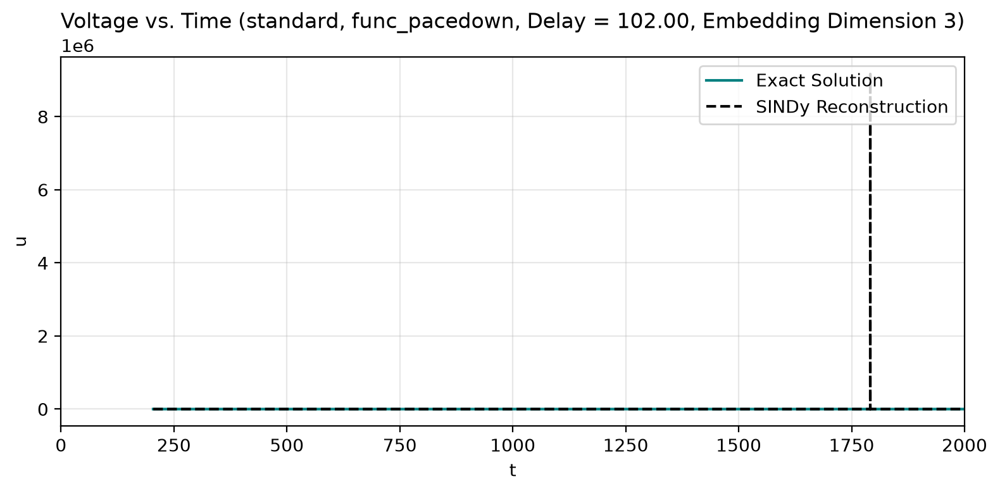



----------Fitting with tau = 104.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 104.0000 (delay_idx = 2080)
Embedding dimension = 3
(u(t-0))' = -0.060 u(t-0) +  0.023 u(t-0)^2 +  0.064 u(t-0)^3 + -0.019 u(t-2080) +  0.123 u(t-2080)^2 + -0.096 u(t-2080)^3 + -0.001 u(t-4160) +  0.024 u(t-4160)^2 + -0.015 u(t-4160)^3 +  0.018 u(t-0)*u(t-2080) + -0.016 1 +  1.560 f_td(t)
(u(t-2080))' = -0.025 u(t-0) +  0.066 u(t-0)^2 + -0.051 u(t-0)^3 +  0.008 u(t-2080) + -0.011 u(t-2080)^2 + -0.018 u(t-2080)^3 + -0.007 u(t-4160) +  0.017 u(t-4160)^2 + -0.129 u(t-0)*u(t-2080) + -0.004 1 + -0.239 f_td(t)
(u(t-4160))' = -0.020 u(t-0) +  0.028 u(t-0)^2 + -0.010 u(t-0)^3 + -0.047 u(t-2080) +  0.147 u(t-2080)^2 + -0.086 u(t-2080)^3 +  0.003 u(t-4160) +  0.113 u(t-4160)^2 + -0.127 u(t-4160)^3 +  0.069 u(t-0)*u(t-2080) + -0.024 u(t-0)*u(t-4160) + -0.009 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)'

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 2.28326e+02


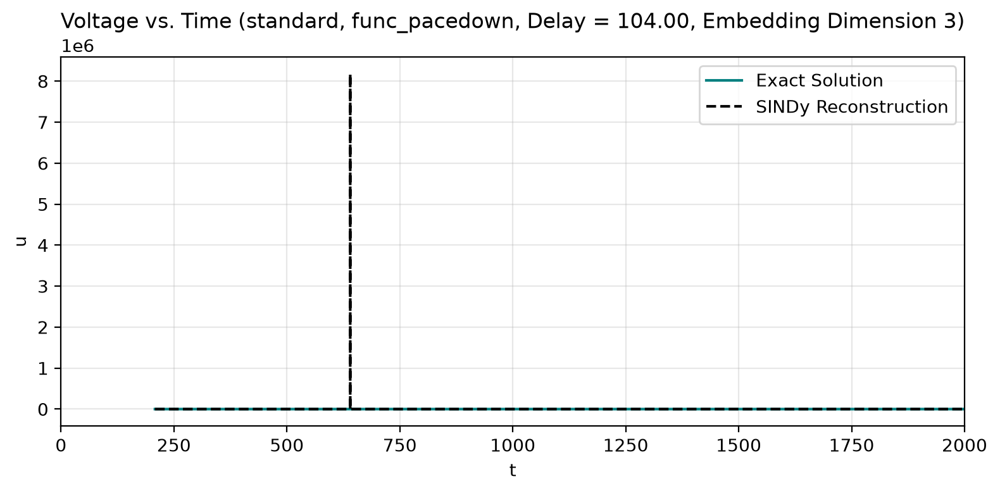



----------Fitting with tau = 106.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 106.0000 (delay_idx = 2120)
Embedding dimension = 3
(u(t-0))' = -0.053 u(t-0) + -0.011 u(t-0)^2 +  0.089 u(t-0)^3 +  0.008 u(t-2120)^2 +  0.015 u(t-4240) + -0.028 u(t-4240)^2 +  0.019 u(t-4240)^3 + -0.008 1 +  1.543 f_td(t)
(u(t-2120))' = -0.027 u(t-0) +  0.056 u(t-0)^2 + -0.044 u(t-0)^3 +  0.009 u(t-2120) + -0.005 u(t-2120)^2 + -0.030 u(t-2120)^3 +  0.059 u(t-4240)^2 + -0.056 u(t-4240)^3 + -0.152 u(t-0)*u(t-2120) + -0.004 1 + -0.155 f_td(t)
(u(t-4240))' = -0.025 u(t-0) + -0.021 u(t-0)^2 +  0.048 u(t-0)^3 + -0.035 u(t-2120) +  0.059 u(t-2120)^2 + -0.018 u(t-2120)^3 +  0.015 u(t-4240) +  0.053 u(t-4240)^2 + -0.081 u(t-4240)^3 +  0.052 u(t-0)*u(t-2120) + -0.025 u(t-0)*u(t-4240) +  0.076 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [2], 

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 1.95914e+02


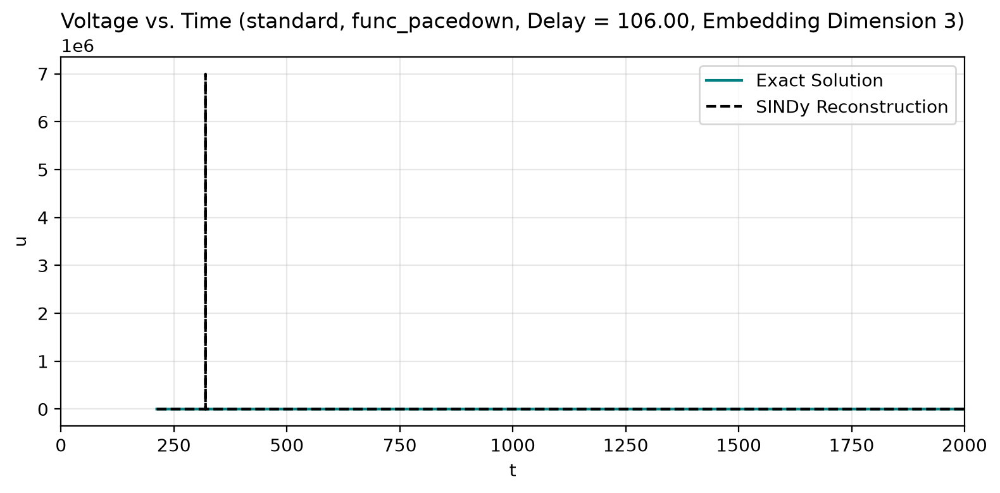



----------Fitting with tau = 108.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 108.0000 (delay_idx = 2160)
Embedding dimension = 3
(u(t-0))' = -0.054 u(t-0) + -0.005 u(t-0)^2 +  0.091 u(t-0)^3 +  0.016 u(t-2160)^2 +  0.021 u(t-4320) + -0.043 u(t-4320)^2 +  0.027 u(t-4320)^3 +  0.063 u(t-0)*u(t-2160) + -0.008 1 +  1.532 f_td(t)
(u(t-2160))' = -0.021 u(t-0) +  0.037 u(t-0)^2 + -0.040 u(t-0)^3 +  0.019 u(t-2160) + -0.039 u(t-2160)^2 + -0.011 u(t-2160)^3 +  0.008 u(t-4320) +  0.045 u(t-4320)^2 + -0.052 u(t-4320)^3 + -0.193 u(t-0)*u(t-2160) + -0.054 f_td(t)
(u(t-4320))' = -0.032 u(t-0) + -0.038 u(t-0)^2 +  0.077 u(t-0)^3 + -0.031 u(t-2160) +  0.059 u(t-2160)^2 + -0.025 u(t-2160)^3 +  0.015 u(t-4320) +  0.052 u(t-4320)^2 + -0.077 u(t-4320)^3 +  0.048 u(t-0)*u(t-2160) + -0.024 u(t-0)*u(t-4320) +  0.090 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 2.91601e+03


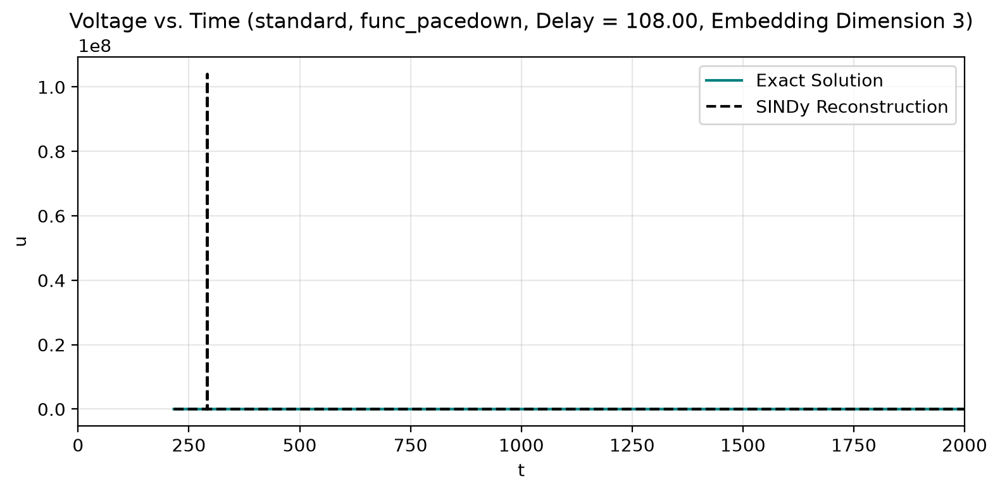



----------Fitting with tau = 110.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 110.0000 (delay_idx = 2200)
Embedding dimension = 3
(u(t-0))' = -0.056 u(t-0) + -0.001 u(t-0)^2 +  0.091 u(t-0)^3 +  0.018 u(t-2200)^2 +  0.026 u(t-4400) + -0.053 u(t-4400)^2 +  0.030 u(t-4400)^3 +  0.082 u(t-0)*u(t-2200) + -0.008 1 +  1.530 f_td(t)
(u(t-2200))' = -0.018 u(t-0) +  0.047 u(t-0)^2 + -0.055 u(t-0)^3 +  0.021 u(t-2200) + -0.026 u(t-2200)^2 + -0.028 u(t-2200)^3 +  0.009 u(t-4400) +  0.048 u(t-4400)^2 + -0.057 u(t-4400)^3 + -0.184 u(t-0)*u(t-2200)
(u(t-4400))' = -0.039 u(t-0) + -0.053 u(t-0)^2 +  0.106 u(t-0)^3 + -0.031 u(t-2200) +  0.034 u(t-2200)^2 +  0.017 u(t-4400) +  0.047 u(t-4400)^2 + -0.072 u(t-4400)^3 +  0.039 u(t-0)*u(t-2200) + -0.023 u(t-0)*u(t-4400) +  0.118 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [2], [2],

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.88640e+02


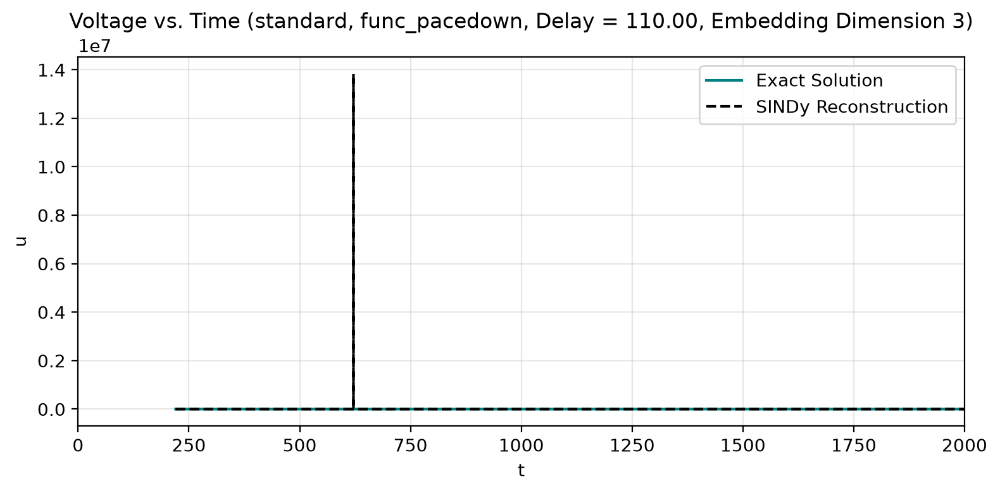



----------Fitting with tau = 112.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 112.0000 (delay_idx = 2240)
Embedding dimension = 3
(u(t-0))' = -0.059 u(t-0) +  0.001 u(t-0)^2 +  0.090 u(t-0)^3 +  0.017 u(t-2240)^2 +  0.028 u(t-4480) + -0.054 u(t-4480)^2 +  0.030 u(t-4480)^3 +  0.073 u(t-0)*u(t-2240) + -0.008 1 +  1.538 f_td(t)
(u(t-2240))' = -0.015 u(t-0) +  0.048 u(t-0)^2 + -0.057 u(t-0)^3 +  0.023 u(t-2240) + -0.007 u(t-2240)^2 + -0.044 u(t-2240)^3 +  0.008 u(t-4480) +  0.046 u(t-4480)^2 + -0.053 u(t-4480)^3 + -0.153 u(t-0)*u(t-2240)
(u(t-4480))' = -0.054 u(t-0) + -0.027 u(t-0)^2 +  0.103 u(t-0)^3 + -0.040 u(t-2240) +  0.048 u(t-2240)^2 +  0.018 u(t-4480) +  0.064 u(t-4480)^2 + -0.089 u(t-4480)^3 +  0.035 u(t-0)*u(t-2240) + -0.024 u(t-0)*u(t-4480) + -0.005 1 +  0.190 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1]

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.73567e+03


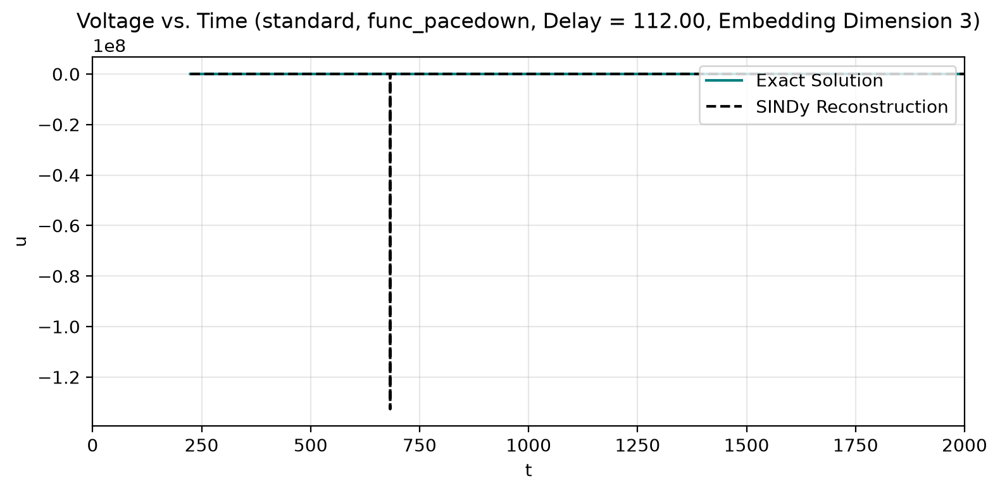



----------Fitting with tau = 114.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 114.0000 (delay_idx = 2280)
Embedding dimension = 3
(u(t-0))' = -0.057 u(t-0) + -0.003 u(t-0)^2 +  0.088 u(t-0)^3 +  0.017 u(t-2280)^2 +  0.011 u(t-4560) + -0.004 u(t-4560)^3 +  0.056 u(t-0)*u(t-2280) + -0.010 1 +  1.524 f_td(t)
(u(t-2280))' = -0.013 u(t-0) +  0.039 u(t-0)^2 + -0.048 u(t-0)^3 +  0.023 u(t-2280) +  0.007 u(t-2280)^2 + -0.055 u(t-2280)^3 +  0.044 u(t-4560)^2 + -0.040 u(t-4560)^3 + -0.124 u(t-0)*u(t-2280)
(u(t-4560))' = -0.062 u(t-0) +  0.024 u(t-0)^2 +  0.062 u(t-0)^3 + -0.038 u(t-2280) +  0.043 u(t-2280)^2 +  0.027 u(t-4560) +  0.021 u(t-4560)^2 + -0.053 u(t-4560)^3 + -0.020 u(t-0)*u(t-4560) + -0.008 1 +  0.609 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [2], [2], [2], [0, 1], [0, 2], [3]]
Takens reconstruction MAE (u

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


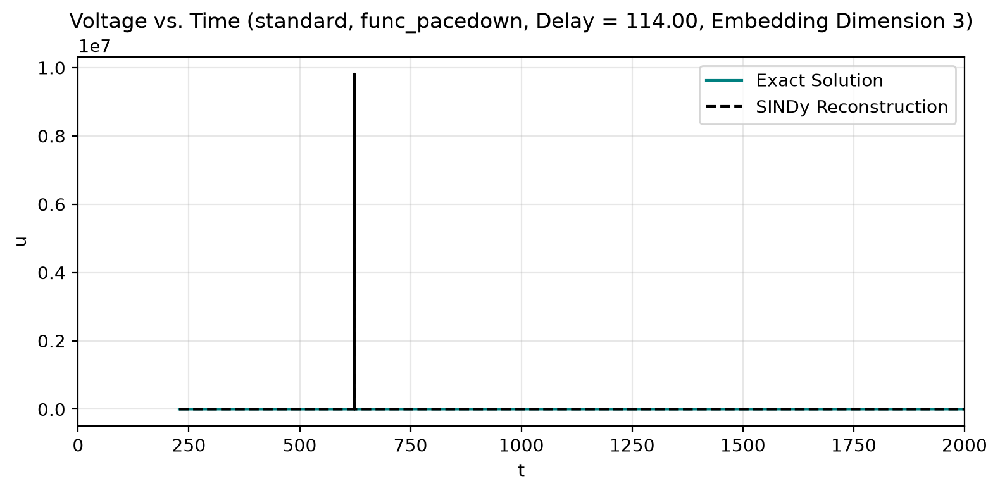



----------Fitting with tau = 116.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 116.0000 (delay_idx = 2320)
Embedding dimension = 3
(u(t-0))' = -0.059 u(t-0) +  0.005 u(t-0)^2 +  0.083 u(t-0)^3 + -0.022 u(t-2320) +  0.043 u(t-2320)^2 + -0.002 u(t-4640) +  0.028 u(t-4640)^2 + -0.019 u(t-4640)^3 +  0.049 u(t-0)*u(t-2320) + -0.007 u(t-0)*u(t-4640) + -0.014 1 +  1.540 f_td(t)
(u(t-2320))' = -0.013 u(t-0) +  0.034 u(t-0)^2 + -0.040 u(t-0)^3 +  0.022 u(t-2320) +  0.017 u(t-2320)^2 + -0.061 u(t-2320)^3 +  0.043 u(t-4640)^2 + -0.039 u(t-4640)^3 + -0.102 u(t-0)*u(t-2320)
(u(t-4640))' = -0.050 u(t-0) +  0.050 u(t-0)^2 +  0.029 u(t-0)^3 + -0.031 u(t-2320) +  0.125 u(t-2320)^2 + -0.097 u(t-2320)^3 +  0.022 u(t-4640) +  0.048 u(t-4640)^2 + -0.077 u(t-4640)^3 + -0.014 u(t-0)*u(t-2320) + -0.007 u(t-0)*u(t-4640) + -0.012 1 +  0.378 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
in

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


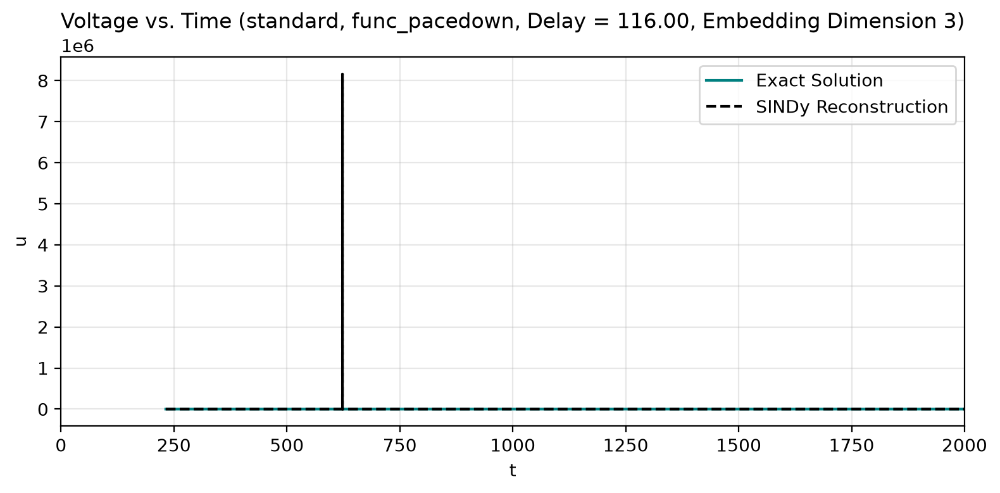



----------Fitting with tau = 118.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 118.0000 (delay_idx = 2360)
Embedding dimension = 3
(u(t-0))' = -0.055 u(t-0) +  0.005 u(t-0)^2 +  0.076 u(t-0)^3 + -0.015 u(t-2360) +  0.031 u(t-2360)^2 + -0.010 u(t-4720) + -0.045 u(t-4720)^2 +  0.070 u(t-4720)^3 +  0.034 u(t-0)*u(t-2360) + -0.009 u(t-0)*u(t-4720) + -0.011 1 +  1.531 f_td(t)
(u(t-2360))' = -0.020 u(t-0) +  0.052 u(t-0)^2 + -0.045 u(t-0)^3 +  0.015 u(t-2360) + -0.027 u(t-2360)^3 +  0.059 u(t-4720)^2 + -0.054 u(t-4720)^3 + -0.082 u(t-0)*u(t-2360) + -0.003 1 +  0.038 f_td(t)
(u(t-4720))' = -0.030 u(t-0) + -0.099 u(t-0)^2 +  0.170 u(t-0)^3 + -0.021 u(t-2360) +  0.069 u(t-2360)^2 + -0.054 u(t-2360)^3 +  0.010 u(t-4720) +  0.039 u(t-4720)^2 + -0.064 u(t-4720)^3 + -0.019 u(t-0)*u(t-2360) +  0.009 u(t-0)*u(t-4720) + -0.004 1 +  0.111 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


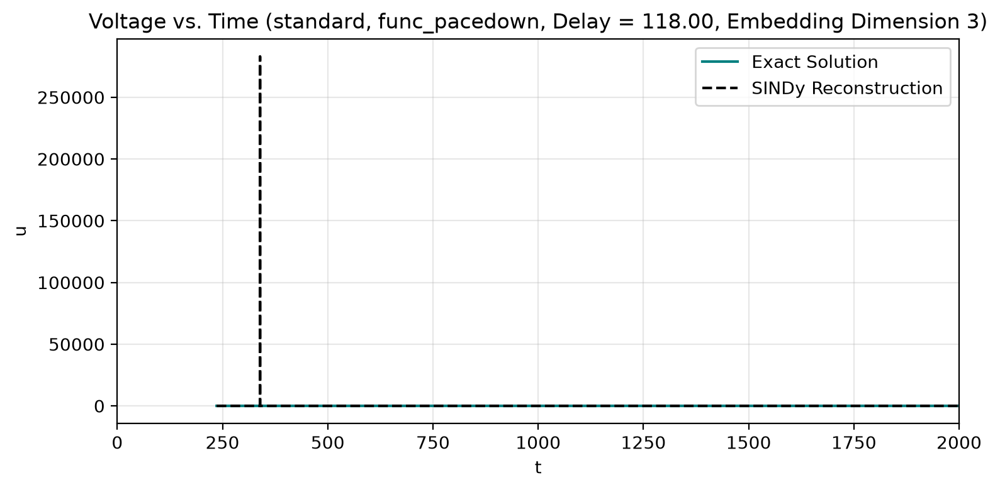



----------Fitting with tau = 120.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 120.0000 (delay_idx = 2400)
Embedding dimension = 3
(u(t-0))' = -0.057 u(t-0) +  0.006 u(t-0)^2 +  0.077 u(t-0)^3 + -0.012 u(t-2400) +  0.026 u(t-2400)^2 + -0.006 u(t-4800) + -0.065 u(t-4800)^2 +  0.083 u(t-4800)^3 +  0.025 u(t-0)*u(t-2400) + -0.008 u(t-0)*u(t-4800) + -0.010 1 +  1.542 f_td(t)
(u(t-2400))' = -0.020 u(t-0) +  0.046 u(t-0)^2 + -0.036 u(t-0)^3 +  0.016 u(t-2400) + -0.026 u(t-2400)^3 + -0.005 u(t-4800) +  0.016 u(t-4800)^2 + -0.070 u(t-0)*u(t-2400) + -0.003 1 +  0.042 f_td(t)
(u(t-4800))' = -0.016 u(t-0) + -0.123 u(t-0)^2 +  0.174 u(t-0)^3 + -0.018 u(t-2400) +  0.056 u(t-2400)^2 + -0.043 u(t-2400)^3 +  0.001 u(t-4800) +  0.043 u(t-4800)^2 + -0.058 u(t-4800)^3 + -0.016 u(t-0)*u(t-2400) +  0.020 u(t-0)*u(t-4800) + -0.002 1 +  0.085 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.22097e+02


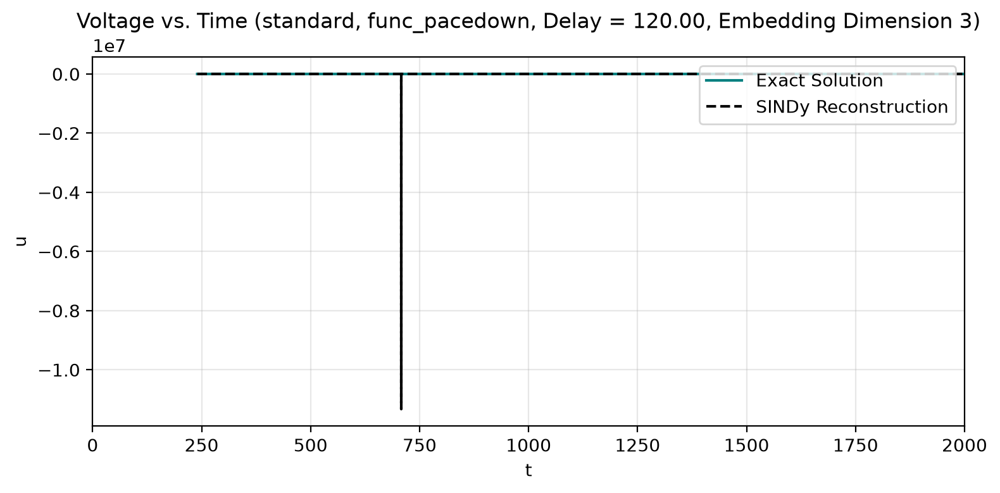



----------Fitting with tau = 122.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 122.0000 (delay_idx = 2440)
Embedding dimension = 3
(u(t-0))' = -0.062 u(t-0) +  0.016 u(t-0)^2 +  0.073 u(t-0)^3 + -0.009 u(t-2440) +  0.062 u(t-2440)^2 + -0.044 u(t-2440)^3 + -0.001 u(t-4880) + -0.060 u(t-4880)^2 +  0.073 u(t-4880)^3 +  0.015 u(t-0)*u(t-2440) + -0.008 u(t-0)*u(t-4880) + -0.011 1 +  1.556 f_td(t)
(u(t-2440))' = -0.031 u(t-0) +  0.028 u(t-0)^2 +  0.008 u(t-2440) +  0.085 u(t-2440)^2 + -0.107 u(t-2440)^3 + -0.014 u(t-4880) +  0.031 u(t-4880)^2 + -0.068 u(t-0)*u(t-2440) + -0.007 1 +  0.066 f_td(t)
(u(t-4880))' = -0.118 u(t-0)^2 +  0.146 u(t-0)^3 + -0.019 u(t-2440) +  0.018 u(t-2440)^2 +  0.043 u(t-4880)^2 + -0.060 u(t-4880)^3 + -0.006 u(t-0)*u(t-2440) +  0.027 u(t-0)*u(t-4880)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [2], [

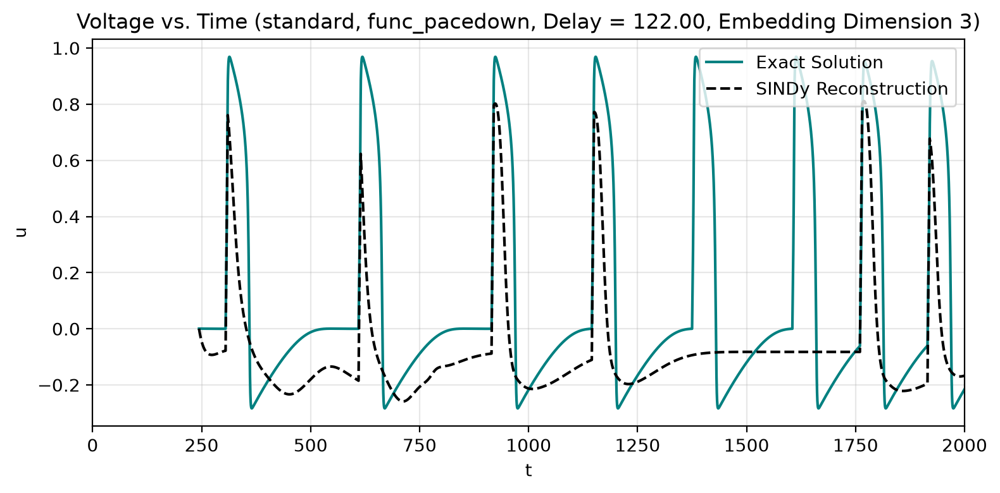



----------Fitting with tau = 124.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 124.0000 (delay_idx = 2480)
Embedding dimension = 3
(u(t-0))' = -0.058 u(t-0) +  0.003 u(t-0)^2 +  0.081 u(t-0)^3 +  0.010 u(t-2480)^2 + -0.073 u(t-4960)^2 +  0.081 u(t-4960)^3 +  0.012 u(t-0)*u(t-2480) + -0.006 u(t-0)*u(t-4960) + -0.008 1 +  1.552 f_td(t)
(u(t-2480))' = -0.033 u(t-0) +  0.031 u(t-0)^2 +  0.006 u(t-2480) +  0.096 u(t-2480)^2 + -0.114 u(t-2480)^3 + -0.017 u(t-4960) +  0.036 u(t-4960)^2 + -0.063 u(t-0)*u(t-2480) + -0.008 1 +  0.068 f_td(t)
(u(t-4960))' = -0.001 u(t-0) + -0.094 u(t-0)^2 +  0.121 u(t-0)^3 + -0.021 u(t-2480) +  0.022 u(t-2480)^2 +  0.001 u(t-4960) +  0.054 u(t-4960)^2 + -0.072 u(t-4960)^3 +  0.034 u(t-0)*u(t-4960) + -0.001 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [2], [2], [2], [0, 1], [0, 2], [3]]
Takens re

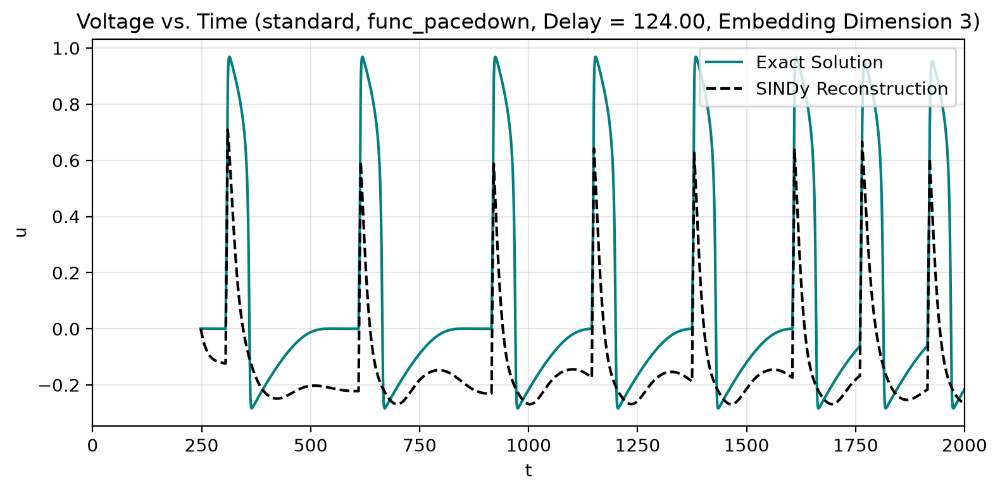



----------Fitting with tau = 126.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 126.0000 (delay_idx = 2520)
Embedding dimension = 3
(u(t-0))' = -0.062 u(t-0) +  0.012 u(t-0)^2 +  0.077 u(t-0)^3 +  0.045 u(t-2520)^2 + -0.039 u(t-2520)^3 +  0.007 u(t-5040) + -0.061 u(t-5040)^2 +  0.059 u(t-5040)^3 +  0.007 u(t-0)*u(t-2520) + -0.005 u(t-0)*u(t-5040) + -0.010 1 +  1.547 f_td(t)
(u(t-2520))' = -0.034 u(t-0) +  0.032 u(t-0)^2 +  0.001 u(t-2520) +  0.125 u(t-2520)^2 + -0.136 u(t-2520)^3 + -0.020 u(t-5040) +  0.099 u(t-5040)^2 + -0.064 u(t-5040)^3 + -0.062 u(t-0)*u(t-2520) + -0.011 1 +  0.086 f_td(t)
(u(t-5040))' =  0.003 u(t-0) + -0.059 u(t-0)^2 +  0.079 u(t-0)^3 + -0.017 u(t-2520) +  0.031 u(t-2520)^2 + -0.013 u(t-2520)^3 +  0.006 u(t-5040) + -0.019 u(t-5040)^3 +  0.033 u(t-0)*u(t-5040) + -0.332 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0]

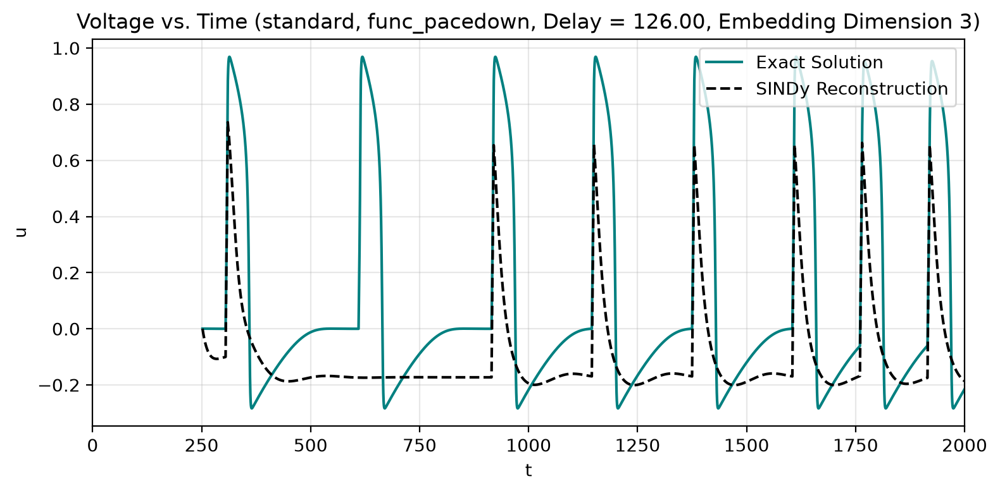



----------Fitting with tau = 128.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 128.0000 (delay_idx = 2560)
Embedding dimension = 3
(u(t-0))' = -0.061 u(t-0) +  0.016 u(t-0)^2 +  0.074 u(t-0)^3 +  0.028 u(t-2560)^2 + -0.021 u(t-2560)^3 +  0.020 u(t-5120) + -0.074 u(t-5120)^2 +  0.052 u(t-5120)^3 +  0.010 u(t-0)*u(t-2560) + -0.008 1 +  1.529 f_td(t)
(u(t-2560))' = -0.036 u(t-0) +  0.023 u(t-0)^2 +  0.015 u(t-0)^3 +  0.128 u(t-2560)^2 + -0.136 u(t-2560)^3 + -0.023 u(t-5120) +  0.094 u(t-5120)^2 + -0.055 u(t-5120)^3 + -0.059 u(t-0)*u(t-2560) + -0.012 1 +  0.106 f_td(t)
(u(t-5120))' =  0.029 u(t-0) + -0.033 u(t-0)^2 + -0.018 u(t-2560) +  0.027 u(t-2560)^2 + -0.008 u(t-2560)^3 +  0.006 u(t-5120) +  0.092 u(t-5120)^2 + -0.122 u(t-5120)^3 +  0.010 u(t-0)*u(t-2560) +  0.040 u(t-0)*u(t-5120) +  0.001 1 + -0.433 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libar

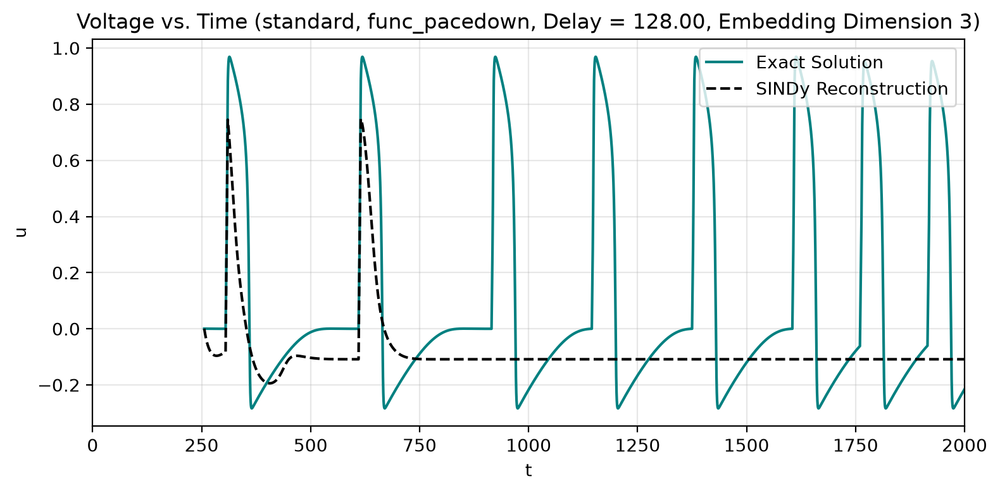



----------Fitting with tau = 130.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 130.0000 (delay_idx = 2600)
Embedding dimension = 3
(u(t-0))' = -0.060 u(t-0) +  0.014 u(t-0)^2 +  0.072 u(t-0)^3 + -0.001 u(t-2600) +  0.029 u(t-2600)^2 + -0.021 u(t-2600)^3 +  0.024 u(t-5200) + -0.044 u(t-5200)^2 +  0.009 u(t-5200)^3 +  0.010 u(t-0)*u(t-2600) +  0.010 u(t-0)*u(t-5200) + -0.008 1 +  1.507 f_td(t)
(u(t-2600))' = -0.038 u(t-0) +  0.013 u(t-0)^2 +  0.031 u(t-0)^3 + -0.001 u(t-2600) +  0.125 u(t-2600)^2 + -0.131 u(t-2600)^3 + -0.024 u(t-5200) +  0.084 u(t-5200)^2 + -0.043 u(t-5200)^3 + -0.055 u(t-0)*u(t-2600) + -0.011 1 +  0.105 f_td(t)
(u(t-5200))' =  0.044 u(t-0) + -0.016 u(t-0)^2 + -0.051 u(t-0)^3 + -0.015 u(t-2600) +  0.015 u(t-2600)^2 +  0.092 u(t-5200)^2 + -0.111 u(t-5200)^3 + -0.001 u(t-0)*u(t-2600) +  0.026 u(t-0)*u(t-5200) +  0.003 1 + -0.343 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


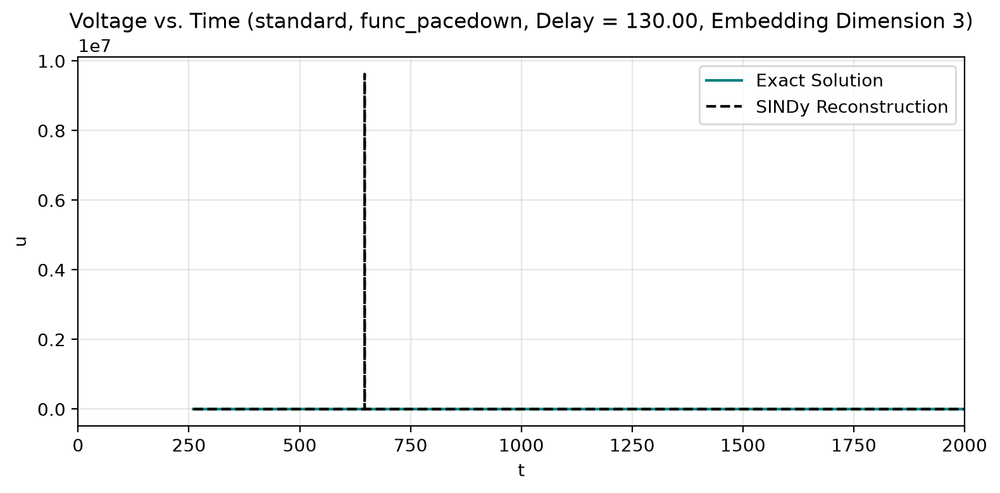



----------Fitting with tau = 132.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 132.0000 (delay_idx = 2640)
Embedding dimension = 3
(u(t-0))' = -0.054 u(t-0) +  0.018 u(t-0)^2 +  0.058 u(t-0)^3 +  0.003 u(t-2640) +  0.005 u(t-2640)^3 +  0.031 u(t-5280) + -0.041 u(t-5280)^2 + -0.005 u(t-5280)^3 +  0.010 u(t-0)*u(t-2640) +  0.009 u(t-0)*u(t-5280) + -0.005 1 +  1.492 f_td(t)
(u(t-2640))' = -0.040 u(t-0) +  0.003 u(t-0)^2 +  0.046 u(t-0)^3 + -0.003 u(t-2640) +  0.127 u(t-2640)^2 + -0.130 u(t-2640)^3 + -0.025 u(t-5280) +  0.092 u(t-5280)^2 + -0.051 u(t-5280)^3 + -0.050 u(t-0)*u(t-2640) +  0.014 u(t-0)*u(t-5280) + -0.012 1 +  0.085 f_td(t)
(u(t-5280))' =  0.055 u(t-0) +  0.021 u(t-0)^2 + -0.114 u(t-0)^3 + -0.011 u(t-2640) +  0.011 u(t-2640)^2 +  0.080 u(t-5280)^2 + -0.095 u(t-5280)^3 + -0.010 u(t-0)*u(t-2640) +  0.014 u(t-0)*u(t-5280) +  0.004 1 + -0.250 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 2.97320e+02


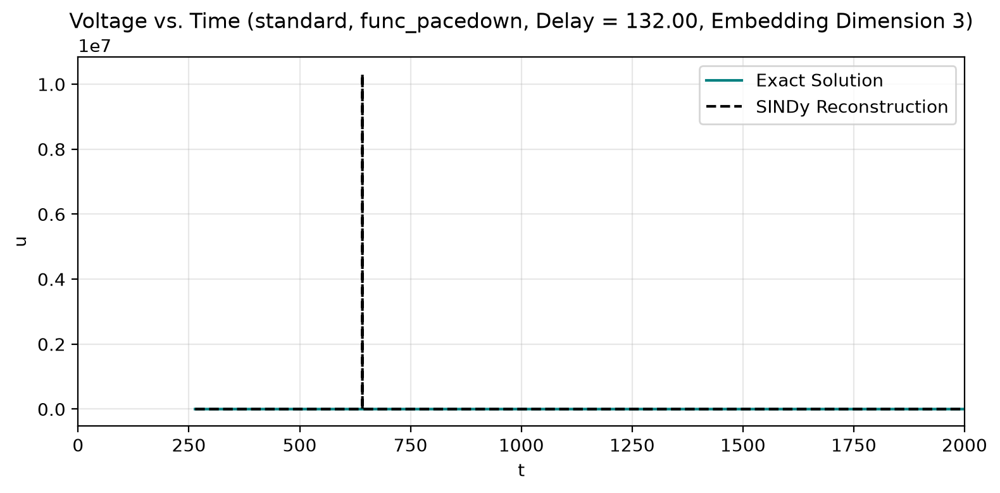



----------Fitting with tau = 134.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 134.0000 (delay_idx = 2680)
Embedding dimension = 3
(u(t-0))' = -0.053 u(t-0) +  0.021 u(t-0)^2 +  0.050 u(t-0)^3 +  0.005 u(t-2680) +  0.003 u(t-2680)^3 +  0.033 u(t-5360) + -0.030 u(t-5360)^2 + -0.023 u(t-5360)^3 +  0.007 u(t-0)*u(t-2680) +  0.004 u(t-0)*u(t-5360) + -0.005 1 +  1.499 f_td(t)
(u(t-2680))' = -0.035 u(t-0) +  0.005 u(t-0)^2 +  0.038 u(t-0)^3 + -0.003 u(t-2680) +  0.119 u(t-2680)^2 + -0.120 u(t-2680)^3 + -0.023 u(t-5360) +  0.087 u(t-5360)^2 + -0.049 u(t-5360)^3 + -0.045 u(t-0)*u(t-2680) +  0.014 u(t-0)*u(t-5360) + -0.011 1
(u(t-5360))' =  0.061 u(t-0) +  0.039 u(t-0)^2 + -0.146 u(t-0)^3 + -0.011 u(t-2680) +  0.012 u(t-2680)^2 +  0.080 u(t-5360)^2 + -0.093 u(t-5360)^3 + -0.011 u(t-0)*u(t-2680) +  0.014 u(t-0)*u(t-5360) +  0.003 1 + -0.227 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1'

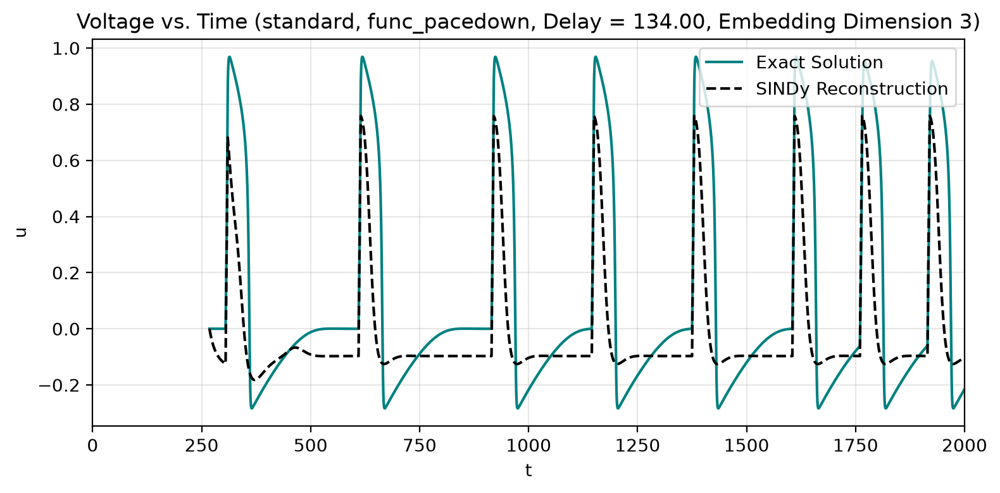



----------Fitting with tau = 136.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 136.0000 (delay_idx = 2720)
Embedding dimension = 3
(u(t-0))' = -0.055 u(t-0) +  0.017 u(t-0)^2 +  0.056 u(t-0)^3 +  0.006 u(t-2720) +  0.001 u(t-2720)^3 +  0.036 u(t-5440) + -0.026 u(t-5440)^2 + -0.032 u(t-5440)^3 +  0.005 u(t-0)*u(t-2720) + -0.003 u(t-0)*u(t-5440) + -0.005 1 +  1.520 f_td(t)
(u(t-2720))' = -0.032 u(t-0) +  0.006 u(t-0)^2 +  0.033 u(t-0)^3 + -0.003 u(t-2720) +  0.111 u(t-2720)^2 + -0.112 u(t-2720)^3 + -0.022 u(t-5440) +  0.077 u(t-5440)^2 + -0.041 u(t-5440)^3 + -0.043 u(t-0)*u(t-2720) +  0.013 u(t-0)*u(t-5440) + -0.010 1
(u(t-5440))' =  0.064 u(t-0) +  0.042 u(t-0)^2 + -0.157 u(t-0)^3 + -0.013 u(t-2720) +  0.012 u(t-2720)^2 +  0.003 u(t-2720)^3 +  0.073 u(t-5440)^2 + -0.082 u(t-5440)^3 + -0.009 u(t-0)*u(t-2720) +  0.018 u(t-0)*u(t-5440) +  0.003 1 + -0.222 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 

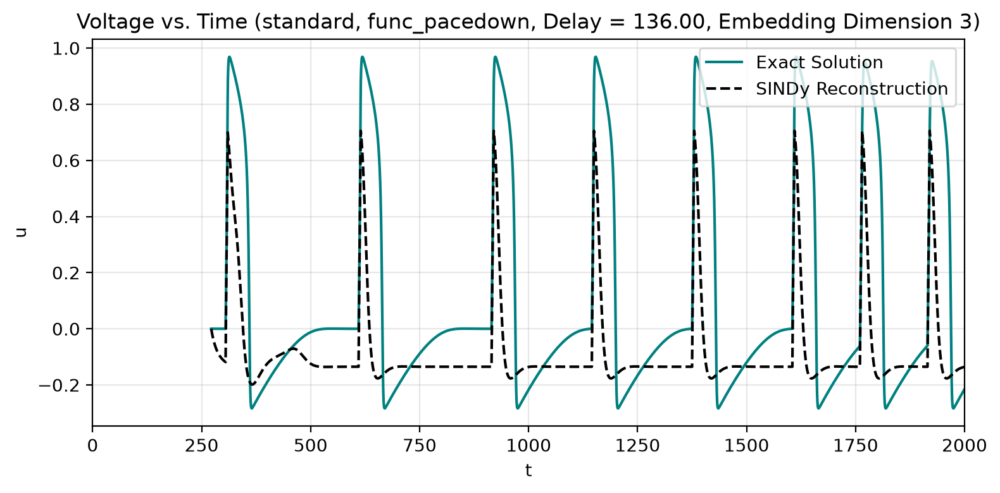



----------Fitting with tau = 138.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 138.0000 (delay_idx = 2760)
Embedding dimension = 3
(u(t-0))' = -0.061 u(t-0) +  0.017 u(t-0)^2 +  0.066 u(t-0)^3 +  0.008 u(t-2760) + -0.001 u(t-2760)^3 +  0.032 u(t-5520) + -0.045 u(t-5520)^2 + -0.006 u(t-5520)^3 +  0.004 u(t-0)*u(t-2760) + -0.004 u(t-0)*u(t-5520) + -0.005 1 +  1.552 f_td(t)
(u(t-2760))' = -0.029 u(t-0) +  0.004 u(t-0)^2 +  0.030 u(t-0)^3 + -0.003 u(t-2760) +  0.102 u(t-2760)^2 + -0.101 u(t-2760)^3 + -0.019 u(t-5520) +  0.070 u(t-5520)^2 + -0.037 u(t-5520)^3 + -0.041 u(t-0)*u(t-2760) +  0.011 u(t-0)*u(t-5520) + -0.009 1
(u(t-5520))' =  0.067 u(t-0) +  0.017 u(t-0)^2 + -0.139 u(t-0)^3 + -0.014 u(t-2760) + -0.004 u(t-2760)^2 +  0.021 u(t-2760)^3 +  0.009 u(t-5520) +  0.056 u(t-5520)^2 + -0.071 u(t-5520)^3 + -0.005 u(t-0)*u(t-2760) +  0.016 u(t-0)*u(t-5520) +  0.006 1 + -0.222 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2

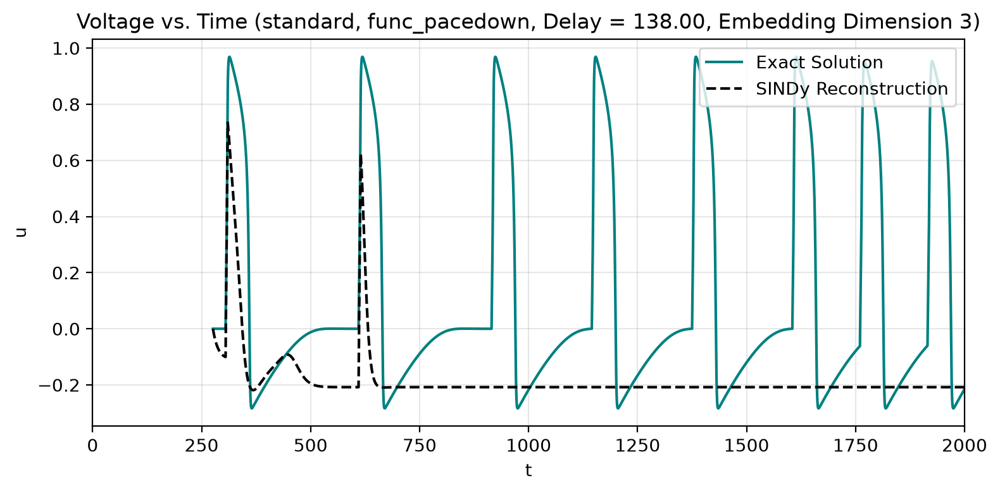



----------Fitting with tau = 140.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 140.0000 (delay_idx = 2800)
Embedding dimension = 3
(u(t-0))' = -0.062 u(t-0) +  0.037 u(t-0)^2 +  0.047 u(t-0)^3 +  0.011 u(t-2800) + -0.004 u(t-2800)^2 +  0.008 u(t-5600) + -0.131 u(t-5600)^2 +  0.127 u(t-5600)^3 +  0.005 u(t-0)*u(t-2800) +  0.014 u(t-0)*u(t-5600) + -0.006 1 +  1.539 f_td(t)
(u(t-2800))' = -0.027 u(t-0) + -0.004 u(t-0)^2 +  0.036 u(t-0)^3 + -0.002 u(t-2800) +  0.091 u(t-2800)^2 + -0.090 u(t-2800)^3 + -0.018 u(t-5600) +  0.065 u(t-5600)^2 + -0.035 u(t-5600)^3 + -0.038 u(t-0)*u(t-2800) +  0.009 u(t-0)*u(t-5600) + -0.008 1
(u(t-5600))' =  0.051 u(t-0) + -0.104 u(t-0)^2 +  0.015 u(t-0)^3 + -0.020 u(t-2800) + -0.008 u(t-2800)^2 +  0.031 u(t-2800)^3 +  0.002 u(t-5600) +  0.087 u(t-5600)^2 + -0.091 u(t-5600)^3 + -0.002 u(t-0)*u(t-2800) +  0.007 1 + -0.138 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1'

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 5.58454e+02


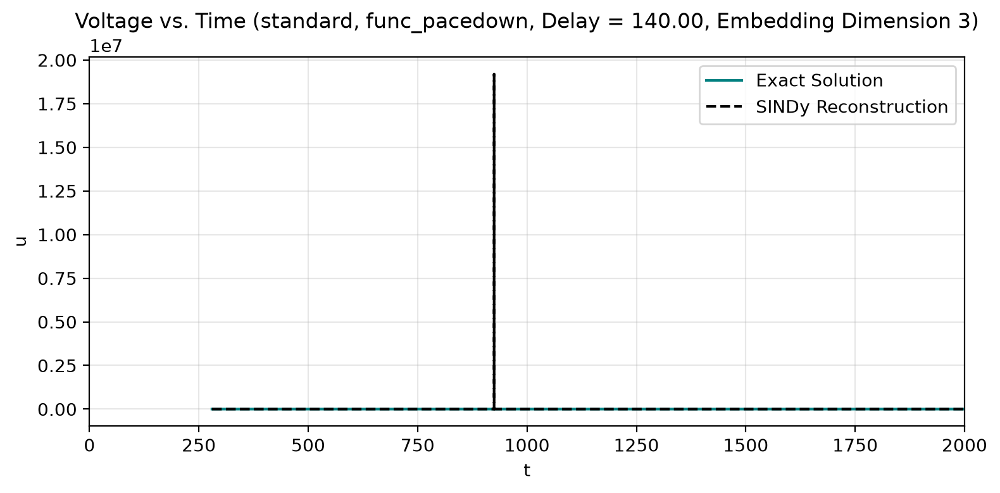



----------Fitting with tau = 142.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 142.0000 (delay_idx = 2840)
Embedding dimension = 3
(u(t-0))' = -0.060 u(t-0) +  0.033 u(t-0)^2 +  0.048 u(t-0)^3 +  0.010 u(t-2840) + -0.002 u(t-2840)^2 +  0.009 u(t-5680) + -0.112 u(t-5680)^2 +  0.112 u(t-5680)^3 +  0.004 u(t-0)*u(t-2840) +  0.012 u(t-0)*u(t-5680) + -0.007 1 +  1.520 f_td(t)
(u(t-2840))' = -0.027 u(t-0) + -0.014 u(t-0)^2 +  0.047 u(t-0)^3 + -0.003 u(t-2840) +  0.084 u(t-2840)^2 + -0.081 u(t-2840)^3 + -0.018 u(t-5680) +  0.059 u(t-5680)^2 + -0.029 u(t-5680)^3 + -0.035 u(t-0)*u(t-2840) +  0.006 u(t-0)*u(t-5680) + -0.007 1
(u(t-5680))' =  0.001 u(t-0) + -0.021 u(t-0)^2 + -0.025 u(t-2840) +  0.030 u(t-2840)^2 +  0.001 u(t-2840)^3 +  0.013 u(t-5680) +  0.084 u(t-5680)^2 + -0.104 u(t-5680)^3 + -0.006 u(t-0)*u(t-2840) + -0.018 u(t-0)*u(t-5680)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_t

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.67966e+02


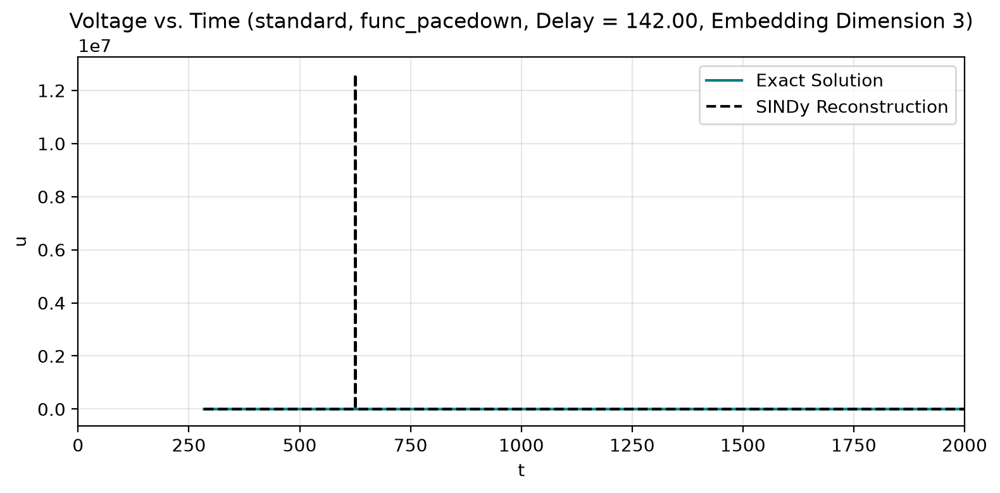



----------Fitting with tau = 144.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 144.0000 (delay_idx = 2880)
Embedding dimension = 3
(u(t-0))' = -0.062 u(t-0) +  0.033 u(t-0)^2 +  0.050 u(t-0)^3 +  0.012 u(t-2880) + -0.004 u(t-2880)^2 +  0.020 u(t-5760) + -0.108 u(t-5760)^2 +  0.092 u(t-5760)^3 +  0.008 u(t-0)*u(t-5760) + -0.006 1 +  1.526 f_td(t)
(u(t-2880))' = -0.027 u(t-0) + -0.017 u(t-0)^2 +  0.052 u(t-0)^3 + -0.003 u(t-2880) +  0.079 u(t-2880)^2 + -0.075 u(t-2880)^3 + -0.017 u(t-5760) +  0.055 u(t-5760)^2 + -0.026 u(t-5760)^3 + -0.033 u(t-0)*u(t-2880) +  0.005 u(t-0)*u(t-5760) + -0.007 1
(u(t-5760))' = -0.018 u(t-0) + -0.049 u(t-0)^2 +  0.062 u(t-0)^3 + -0.027 u(t-2880) +  0.034 u(t-2880)^2 +  0.001 u(t-2880)^3 +  0.010 u(t-5760) +  0.083 u(t-5760)^2 + -0.098 u(t-5760)^3 + -0.006 u(t-0)*u(t-2880) + -0.021 u(t-0)*u(t-5760) + -0.002 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', '

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 3.26799e+02


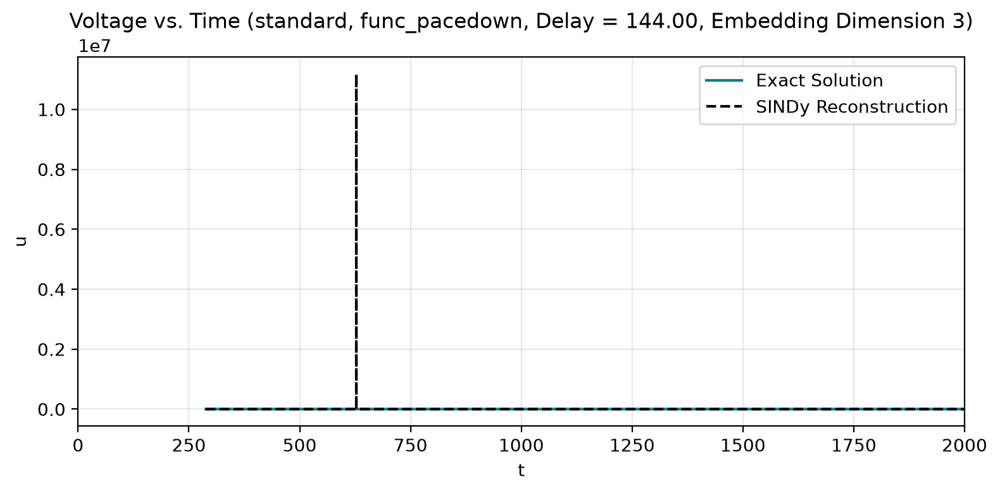



----------Fitting with tau = 146.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 146.0000 (delay_idx = 2920)
Embedding dimension = 3
(u(t-0))' = -0.066 u(t-0) +  0.034 u(t-0)^2 +  0.052 u(t-0)^3 +  0.015 u(t-2920) + -0.002 u(t-2920)^2 + -0.005 u(t-2920)^3 +  0.025 u(t-5840) + -0.119 u(t-5840)^2 +  0.096 u(t-5840)^3 +  0.009 u(t-0)*u(t-5840) + -0.006 1 +  1.534 f_td(t)
(u(t-2920))' = -0.028 u(t-0) + -0.018 u(t-0)^2 +  0.055 u(t-0)^3 +  0.071 u(t-2920)^2 + -0.069 u(t-2920)^3 + -0.015 u(t-5840) +  0.049 u(t-5840)^2 + -0.021 u(t-5840)^3 + -0.032 u(t-0)*u(t-2920) +  0.003 u(t-0)*u(t-5840) + -0.007 1
(u(t-5840))' = -0.022 u(t-0) + -0.076 u(t-0)^2 +  0.100 u(t-0)^3 + -0.026 u(t-2920) +  0.016 u(t-2920)^2 +  0.017 u(t-2920)^3 +  0.011 u(t-5840) +  0.067 u(t-5840)^2 + -0.081 u(t-5840)^3 + -0.003 u(t-0)*u(t-2920) + -0.020 u(t-0)*u(t-5840)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)'

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


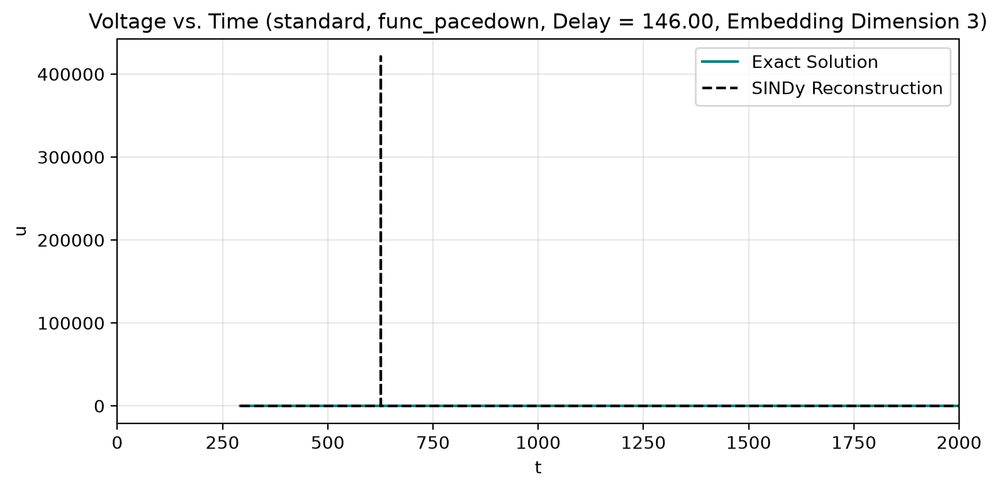



----------Fitting with tau = 148.0----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 148.0000 (delay_idx = 2960)
Embedding dimension = 3
(u(t-0))' = -0.071 u(t-0) +  0.031 u(t-0)^2 +  0.061 u(t-0)^3 +  0.015 u(t-2960) + -0.007 u(t-2960)^2 +  0.031 u(t-5920) + -0.127 u(t-5920)^2 +  0.096 u(t-5920)^3 +  0.009 u(t-0)*u(t-5920) + -0.005 1 +  1.547 f_td(t)
(u(t-2960))' = -0.028 u(t-0) + -0.018 u(t-0)^2 +  0.055 u(t-0)^3 +  0.066 u(t-2960)^2 + -0.063 u(t-2960)^3 + -0.013 u(t-5920) +  0.046 u(t-5920)^2 + -0.019 u(t-5920)^3 + -0.030 u(t-0)*u(t-2960) +  0.002 u(t-0)*u(t-5920) + -0.007 1
(u(t-5920))' = -0.031 u(t-0) + -0.082 u(t-0)^2 +  0.121 u(t-0)^3 + -0.027 u(t-2960) +  0.026 u(t-2960)^2 +  0.010 u(t-2960)^3 +  0.011 u(t-5920) +  0.063 u(t-5920)^2 + -0.074 u(t-5920)^3 + -0.003 u(t-0)*u(t-2960) + -0.019 u(t-0)*u(t-5920) + -0.002 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_p

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


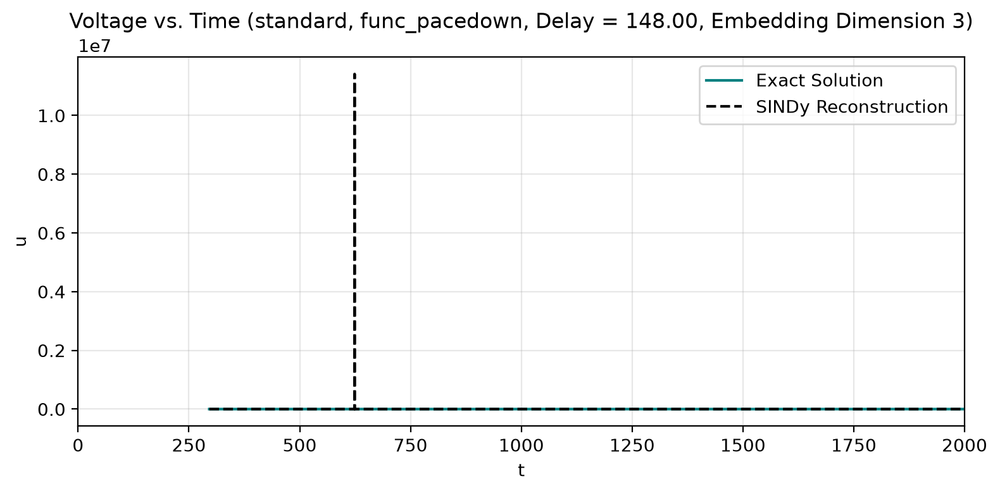

In [40]:
# Create a scatter plot of the MAE vs. time delay at a fixed embedding dimension, where tau varies from 0 to the stimulus period (which is 155).  This information
# can help diagnose sensitivity of the embedding + SINDy fit process to the size of tau.
time_delays_broad = np.arange(2., 150., 2.) # np.arange(1., 31., 1.)

# Test fit with fit_takens() method, which uses delay embeddings to reconstruct the dynamics, specifying the number of embedding
# dimensions with n_embed.
mae_vals = []
for tau_cur in time_delays_broad:
    print(f'\n\n----------Fitting with tau = {tau_cur}----------')
    cur_gen_library_tk_fhn = GenLibraryFit(
                func_pacedown,
                func_pacedown,
                model_variant='standard',
                ics=np.array([-0.1, 0]),
                t_range=np.arange(0, 2000, 0.05),
                color='teal',
                tau=tau_cur
            )
    cur_gen_library_tk_fhn.fit_takens(printing=True, is_cubic=True, n_embed=3)
    mae_cur = cur_gen_library_tk_fhn.reconstruct_and_plot_takens(plotting=True, printing=True, end_time=2000)

    mae_vals.append(mae_cur)

Tau values where MAE is above 1.0:  [ 46.  48.  50.  52.  54.  58.  60.  66.  68.  92.  96.  98. 102. 104.
 106. 108. 110. 112. 114. 116. 118. 120. 130. 132. 140. 142. 144. 146.
 148.]
Minimum MAE:  0.005380395273449637
Tau value at which minimum MAE occurs:  2.0


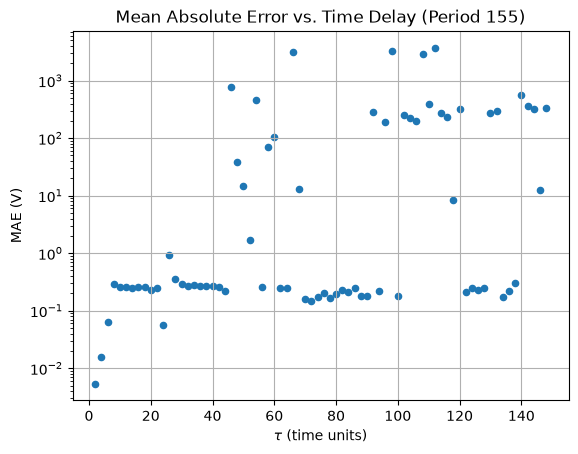

In [41]:
# Analyze pacedown results over different time delays
plt.scatter(time_delays_broad, mae_vals, marker='o', s=20)
plt.title(f'Mean Absolute Error vs. Time Delay (Period 155)')
plt.ylabel('MAE (V)')
# plt.ylim(0, 5)
plt.yscale('log')
plt.xlabel(r'$\tau$ (time units)')
# plt.xlim(0, 150)
plt.grid()

mv = np.array(mae_vals)
tdb = np.array(time_delays_broad)
# print(mae_vals[:10])
print('Tau values where MAE is above 1.0: ', tdb[mv > 1.0])
print('Minimum MAE: ', np.min(mv))
print('Tau value at which minimum MAE occurs: ', tdb[np.argmin(mv)])

Takens reconstruction MAE (u): 2.58663e-02


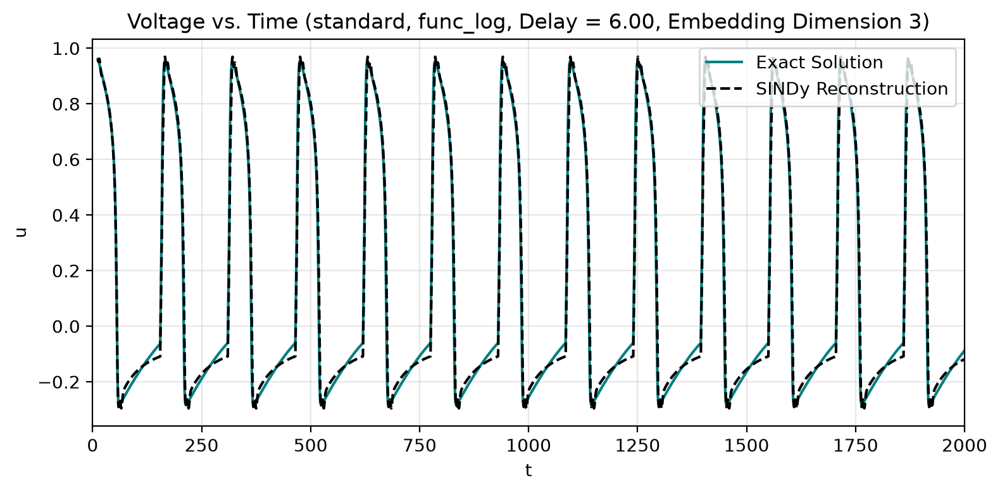

In [42]:
# Run basic test at time delay of tau=6.0 to see if same or different results from sweep.
cur_gen_library_tk_fhn = GenLibraryFit(
                    func_log,
                    func_log,
                    model_variant='standard',
                    ics=np.array([-0.1, 0]),
                    t_range=np.arange(0, 2000, 0.05),
                    color='teal',
                    tau=6.0
                )
cur_gen_library_tk_fhn.fit_takens(printing=False, is_cubic=True, n_embed=3)
mae_cur = cur_gen_library_tk_fhn.reconstruct_and_plot_takens(plotting=True, printing=True, end_time=2000)

Test embedding reconstruction on FHN-c:

----------Fitting with function: func_log----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 2
(u(t-0))' =  0.012 u(t-0) +  0.225 u(t-0)^2 + -0.148 u(t-0)^3 + -0.144 u(t-99) +  0.193 u(t-99)^2 + -0.070 u(t-99)^3 + -0.085 u(t-0)*u(t-99) +  0.910 f_td(t)
(u(t-99))' =  0.289 u(t-0) + -0.542 u(t-0)^2 +  0.410 u(t-0)^3 + -0.217 u(t-99) + -0.220 u(t-99)^2 + -0.316 u(t-99)^3 +  0.613 u(t-0)*u(t-99) + -0.351 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x0*x1', '1', 'f_td(x2)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [0, 1], [2]]
Takens reconstruction MAE (u): 5.76364e-02


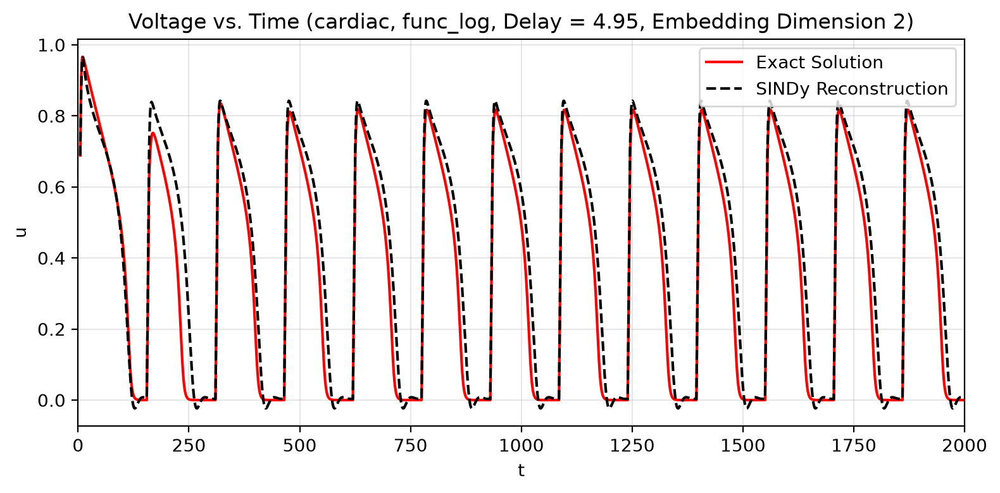


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 3
(u(t-0))' =  0.022 u(t-0) +  0.331 u(t-0)^2 + -0.340 u(t-0)^3 + -0.176 u(t-99) + -0.028 u(t-99)^2 +  0.122 u(t-99)^3 +  0.035 u(t-198) +  0.022 u(t-198)^2 +  0.087 u(t-0)*u(t-99) + -0.100 u(t-0)*u(t-198) +  0.876 f_td(t)
(u(t-99))' =  0.222 u(t-0) + -0.554 u(t-0)^2 +  0.536 u(t-0)^3 + -0.033 u(t-99) + -0.318 u(t-99)^2 + -0.300 u(t-99)^3 + -0.159 u(t-198) +  0.281 u(t-198)^2 + -0.162 u(t-198)^3 +  0.452 u(t-0)*u(t-99) +  0.060 u(t-0)*u(t-198) +  0.001 1 + -0.246 f_td(t)
(u(t-198))' = -0.035 u(t-0) +  0.254 u(t-0)^2 + -0.267 u(t-0)^3 +  0.149 u(t-99) + -0.095 u(t-99)^2 +  0.662 u(t-99)^3 + -0.226 u(t-198) +  0.464 u(t-198)^2 + -0.623 u(t-198)^3 + -0.296 u(t-0)*u(t-99) + -0.001 1 + -0.034 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [2]

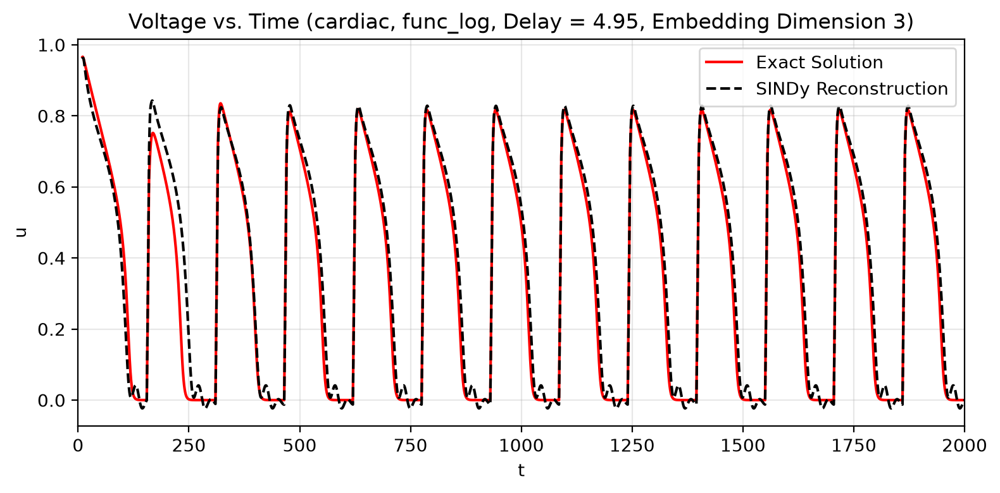


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 4
(u(t-0))' = -0.001 u(t-0) +  0.423 u(t-0)^2 + -0.426 u(t-0)^3 + -0.170 u(t-99) +  0.026 u(t-99)^2 +  0.064 u(t-99)^3 +  0.064 u(t-198) + -0.114 u(t-198)^2 +  0.150 u(t-198)^3 + -0.019 u(t-297) +  0.053 u(t-297)^2 + -0.028 u(t-297)^3 +  0.073 u(t-0)*u(t-99) + -0.093 u(t-0)*u(t-198) + -0.036 u(t-0)*u(t-297) +  0.880 f_td(t)
(u(t-99))' =  0.332 u(t-0) + -0.994 u(t-0)^2 +  0.985 u(t-0)^3 + -0.183 u(t-99) +  0.260 u(t-99)^2 + -0.742 u(t-99)^3 + -0.325 u(t-198) +  0.506 u(t-198)^2 + -0.325 u(t-198)^3 +  0.099 u(t-297) +  0.347 u(t-0)*u(t-99) +  0.186 u(t-0)*u(t-198) + -0.117 u(t-0)*u(t-297) + -0.279 f_td(t)
(u(t-198))' = -0.024 u(t-0) +  0.045 u(t-0)^2 +  0.291 u(t-99) + -0.036 u(t-99)^2 +  0.408 u(t-99)^3 + -0.070 u(t-198) + -0.416 u(t-198)^2 + -0.110 u(t-198)^3 + -0.155 u(t-297) +  0.370 u(t-297)^2 + -0.203 u(t-297)^3 + -0.474 u(t-0)*u(t-99) +  0.434 u(t-0)*u(t-198) 

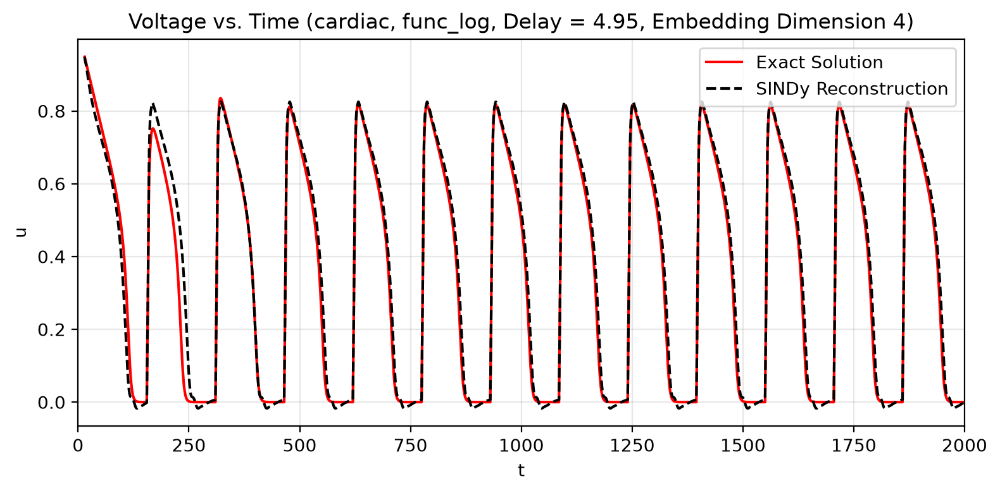


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 5
(u(t-0))' = -0.006 u(t-0) +  0.441 u(t-0)^2 + -0.437 u(t-0)^3 + -0.241 u(t-99) +  0.134 u(t-99)^2 + -0.047 u(t-99)^3 +  0.191 u(t-198) + -0.172 u(t-198)^2 +  0.182 u(t-198)^3 + -0.082 u(t-297) + -0.042 u(t-297)^2 +  0.065 u(t-297)^3 +  0.013 u(t-396) +  0.028 u(t-396)^2 + -0.016 u(t-396)^3 +  0.127 u(t-0)*u(t-99) + -0.207 u(t-0)*u(t-198) +  0.074 u(t-0)*u(t-297) + -0.046 u(t-0)*u(t-396) +  0.879 f_td(t)
(u(t-99))' =  0.327 u(t-0) + -0.973 u(t-0)^2 +  0.959 u(t-0)^3 + -0.065 u(t-99) +  0.187 u(t-99)^2 + -0.653 u(t-99)^3 + -0.597 u(t-198) +  0.675 u(t-198)^2 + -0.453 u(t-198)^3 +  0.278 u(t-297) +  0.032 u(t-297)^3 + -0.065 u(t-396) +  0.057 u(t-396)^2 + -0.033 u(t-396)^3 +  0.225 u(t-0)*u(t-99) +  0.438 u(t-0)*u(t-198) + -0.349 u(t-0)*u(t-297) +  0.033 u(t-0)*u(t-396) +  0.001 1 + -0.280 f_td(t)
(u(t-198))' =  0.001 u(t-0) + -0.001 u(t-0)^2 +  0.260 u(t-99) + -0.3

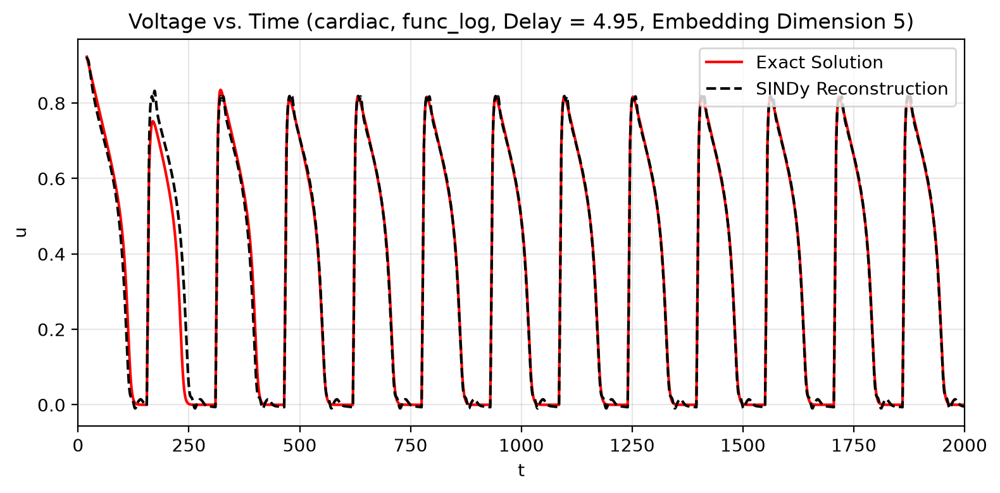


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 6
(u(t-0))' = -0.010 u(t-0) +  0.447 u(t-0)^2 + -0.436 u(t-0)^3 + -0.240 u(t-99) +  0.148 u(t-99)^2 + -0.051 u(t-99)^3 +  0.152 u(t-198) + -0.106 u(t-198)^2 +  0.118 u(t-198)^3 + -0.009 u(t-297) + -0.103 u(t-297)^2 +  0.112 u(t-297)^3 + -0.029 u(t-396) +  0.011 u(t-396)^2 +  0.009 u(t-495) +  0.015 u(t-495)^2 + -0.011 u(t-495)^3 +  0.117 u(t-0)*u(t-99) + -0.183 u(t-0)*u(t-198) +  0.017 u(t-0)*u(t-297) +  0.011 u(t-0)*u(t-396) + -0.020 u(t-0)*u(t-495) +  0.883 f_td(t)
(u(t-99))' =  0.294 u(t-0) + -0.934 u(t-0)^2 +  0.979 u(t-0)^3 +  0.053 u(t-99) +  0.308 u(t-99)^2 + -0.717 u(t-99)^3 + -0.900 u(t-198) +  0.744 u(t-198)^2 + -0.510 u(t-198)^3 +  0.609 u(t-297) +  0.018 u(t-297)^3 + -0.282 u(t-396) +  0.045 u(t-396)^2 +  0.063 u(t-495) +  0.010 u(t-495)^2 +  0.783 u(t-0)*u(t-198) + -0.752 u(t-0)*u(t-297) +  0.307 u(t-0)*u(t-396) + -0.104 u(t-0)*u(t-495) + -0.246 f_td(t

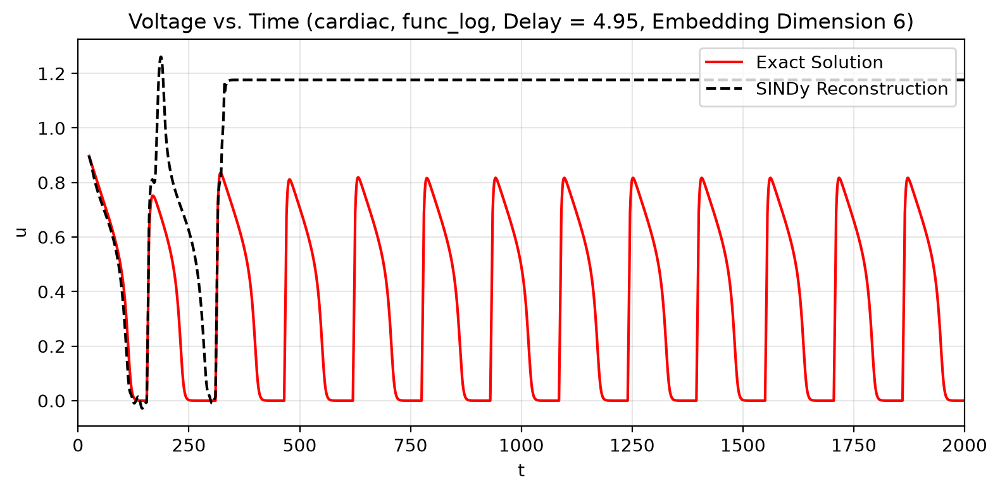


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 7
(u(t-0))' = -0.011 u(t-0) +  0.450 u(t-0)^2 + -0.436 u(t-0)^3 + -0.252 u(t-99) +  0.143 u(t-99)^2 + -0.046 u(t-99)^3 +  0.182 u(t-198) + -0.095 u(t-198)^2 +  0.112 u(t-198)^3 + -0.075 u(t-297) + -0.081 u(t-297)^2 +  0.093 u(t-297)^3 +  0.051 u(t-396) +  0.002 u(t-396)^2 + -0.038 u(t-495) + -0.001 u(t-495)^2 +  0.013 u(t-594) +  0.001 u(t-594)^2 +  0.132 u(t-0)*u(t-99) + -0.227 u(t-0)*u(t-198) +  0.089 u(t-0)*u(t-297) + -0.084 u(t-0)*u(t-396) +  0.053 u(t-0)*u(t-495) + -0.019 u(t-0)*u(t-594) +  0.884 f_td(t)
(u(t-99))' =  0.295 u(t-0) + -0.936 u(t-0)^2 +  0.979 u(t-0)^3 +  0.049 u(t-99) +  0.323 u(t-99)^2 + -0.729 u(t-99)^3 + -0.918 u(t-198) +  0.777 u(t-198)^2 + -0.542 u(t-198)^3 +  0.633 u(t-297) +  0.010 u(t-297)^3 + -0.328 u(t-396) +  0.045 u(t-396)^2 +  0.090 u(t-495) +  0.032 u(t-495)^2 + -0.013 u(t-594) +  0.012 u(t-594)^2 +  0.795 u(t-0)*u(t-198) + -0.774 

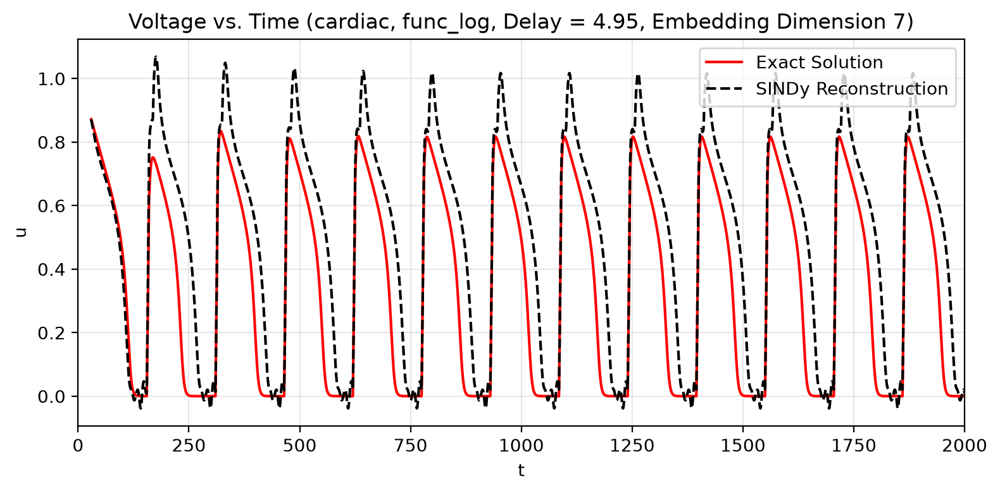


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 8
(u(t-0))' = -0.013 u(t-0) +  0.449 u(t-0)^2 + -0.432 u(t-0)^3 + -0.256 u(t-99) +  0.166 u(t-99)^2 + -0.062 u(t-99)^3 +  0.161 u(t-198) + -0.090 u(t-198)^2 +  0.113 u(t-198)^3 + -0.041 u(t-297) + -0.053 u(t-297)^2 +  0.070 u(t-297)^3 + -0.009 u(t-396) +  0.004 u(t-396)^2 +  0.032 u(t-495) + -0.008 u(t-495)^2 + -0.032 u(t-594) +  0.002 u(t-594)^2 +  0.011 u(t-693) +  0.004 u(t-693)^2 +  0.125 u(t-0)*u(t-99) + -0.204 u(t-0)*u(t-198) +  0.033 u(t-0)*u(t-297) + -0.006 u(t-0)*u(t-396) + -0.036 u(t-0)*u(t-495) +  0.046 u(t-0)*u(t-594) + -0.022 u(t-0)*u(t-693) +  0.886 f_td(t)
(u(t-99))' =  0.291 u(t-0) + -0.921 u(t-0)^2 +  0.969 u(t-0)^3 +  0.036 u(t-99) +  0.364 u(t-99)^2 + -0.760 u(t-99)^3 + -0.963 u(t-198) +  0.858 u(t-198)^2 + -0.616 u(t-198)^3 +  0.712 u(t-297) + -0.440 u(t-396) +  0.044 u(t-396)^2 +  0.221 u(t-495) +  0.012 u(t-495)^2 + -0.087 u(t-594) + -0.040 u(

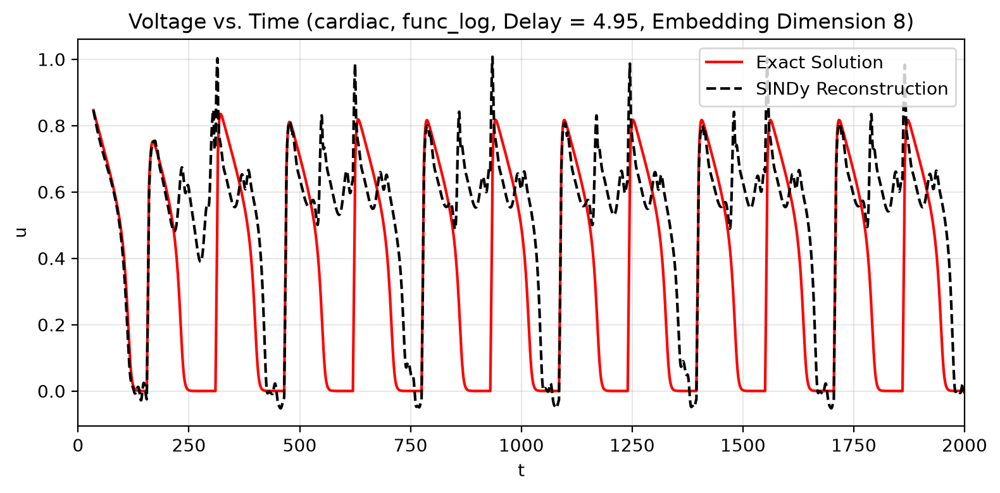


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 9
(u(t-0))' = -0.016 u(t-0) +  0.455 u(t-0)^2 + -0.433 u(t-0)^3 + -0.262 u(t-99) +  0.177 u(t-99)^2 + -0.069 u(t-99)^3 +  0.161 u(t-198) + -0.075 u(t-198)^2 +  0.103 u(t-198)^3 + -0.052 u(t-297) + -0.040 u(t-297)^2 +  0.062 u(t-297)^3 +  0.006 u(t-396) +  0.007 u(t-396)^2 +  0.016 u(t-495) + -0.007 u(t-495)^2 + -0.011 u(t-594) + -0.008 u(t-594)^2 +  0.006 u(t-792)^2 +  0.127 u(t-0)*u(t-99) + -0.211 u(t-0)*u(t-198) +  0.042 u(t-0)*u(t-297) + -0.029 u(t-0)*u(t-396) + -0.017 u(t-0)*u(t-495) +  0.023 u(t-0)*u(t-594) +  0.005 u(t-0)*u(t-693) + -0.010 u(t-0)*u(t-792) +  0.887 f_td(t)
(u(t-99))' =  0.283 u(t-0) + -0.902 u(t-0)^2 +  0.958 u(t-0)^3 +  0.028 u(t-99) +  0.383 u(t-99)^2 + -0.771 u(t-99)^3 + -0.971 u(t-198) +  0.910 u(t-198)^2 + -0.662 u(t-198)^3 +  0.698 u(t-297) +  0.002 u(t-297)^3 + -0.397 u(t-396) +  0.046 u(t-396)^2 +  0.166 u(t-495) +  0.010 u(t-495)^2 + 

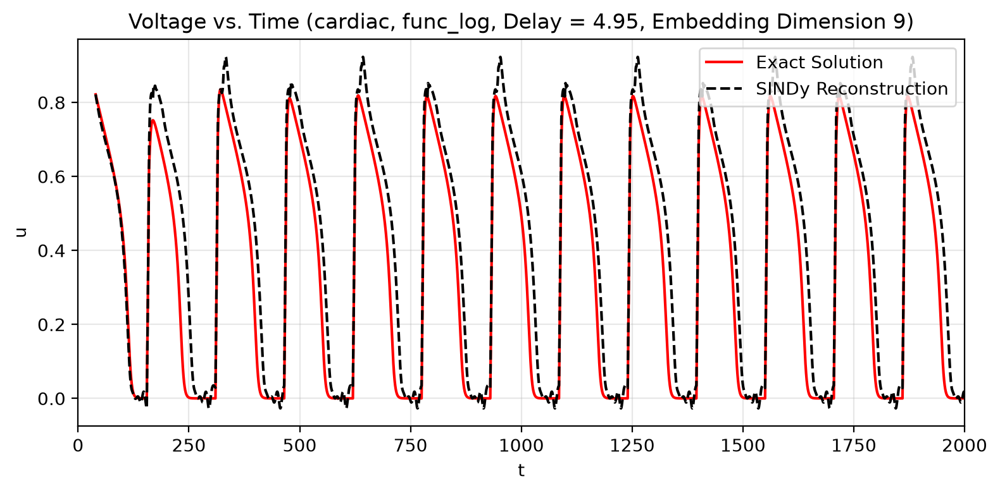

In [43]:
takens_td_models_fhn_c = []
n_embed_range = range(2,10)

# Test fit with fit_takens() method, which uses delay embeddings to reconstruct the dynamics, specifying the number of embedding
# dimensions with n_embed.
print(f'----------Fitting with function: {func_log.__name__}----------')
cur_gen_library_tk_fhn_c = GenLibraryFit(
            func_log,
            func_log,
            model_variant='cardiac',
            ics=np.array([-0.1, 0]),
            t_range=np.arange(0, 2000, 0.05),
            color='red'
        )

for i in n_embed_range:
    cur_gen_library_tk_fhn_c.fit_takens(is_cubic=True, n_embed=i)
    cur_gen_library_tk_fhn_c.reconstruct_and_plot_takens(end_time=2000)
    
    takens_td_models_fhn_c.append(cur_gen_library_tk_fhn_c)

Test embedding reconstruction on VF4:

----------Fitting with function: func_log_vf_4----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 2
(u(t-0))' = -0.164 u(t-0) +  0.605 u(t-0)^2 + -0.368 u(t-0)^3 + -0.061 u(t-99) +  0.026 u(t-99)^2 + -0.075 u(t-99)^3 +  0.930 f_td(t)
(u(t-99))' =  0.438 u(t-0) + -0.677 u(t-0)^2 +  0.258 u(t-0)^3 + -0.137 u(t-99) + -0.857 u(t-99)^2 +  0.252 u(t-99)^3 +  0.754 u(t-0)*u(t-99) + -0.001 1 + -0.497 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x0*x1', '1', 'f_td(x2)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [0, 1], [2]]
Takens reconstruction MAE (u): 1.77812e-01


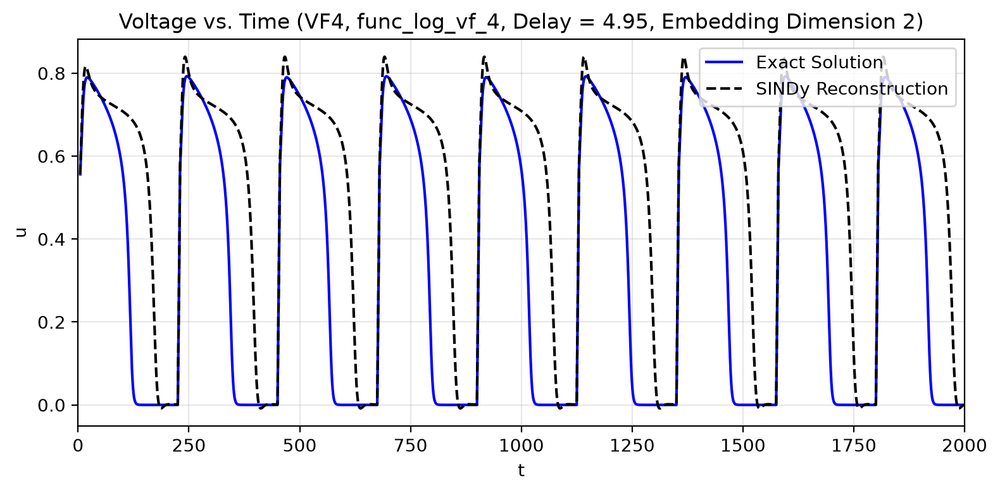


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 3
(u(t-0))' = -0.175 u(t-0) +  0.719 u(t-0)^2 + -0.545 u(t-0)^3 +  0.005 u(t-99) + -0.169 u(t-99)^2 +  0.195 u(t-99)^3 +  0.007 u(t-198) + -0.088 u(t-198)^2 +  0.042 u(t-198)^3 + -0.015 u(t-0)*u(t-99) +  0.925 f_td(t)
(u(t-99))' =  0.450 u(t-0) + -1.072 u(t-0)^2 +  0.880 u(t-0)^3 + -0.316 u(t-99) + -0.223 u(t-99)^2 + -0.647 u(t-99)^3 + -0.185 u(t-198) +  0.783 u(t-198)^2 + -0.364 u(t-198)^3 +  0.876 u(t-0)*u(t-99) + -0.187 u(t-0)*u(t-198) + -0.420 f_td(t)
(u(t-198))' = -0.036 u(t-0) + -0.086 u(t-0)^2 +  0.364 u(t-0)^3 +  0.255 u(t-99) +  1.173 u(t-99)^2 + -0.551 u(t-99)^3 + -0.034 u(t-198) + -1.073 u(t-198)^2 +  0.503 u(t-198)^3 + -1.049 u(t-0)*u(t-99) +  0.556 u(t-0)*u(t-198) + -0.001 1
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [2], [2], [

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 2.88659e+01


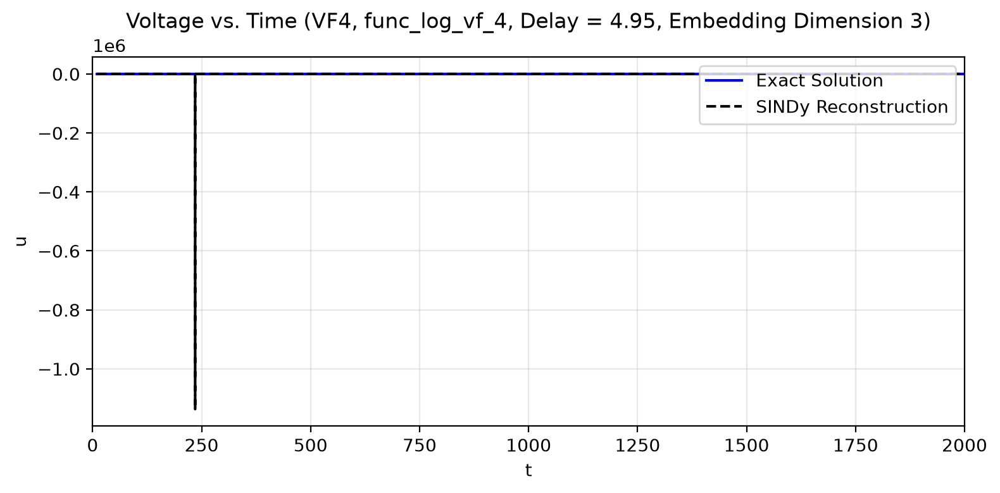


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 4
(u(t-0))' = -0.187 u(t-0) +  0.812 u(t-0)^2 + -0.675 u(t-0)^3 +  0.003 u(t-99) + -0.212 u(t-99)^2 +  0.301 u(t-99)^3 + -0.053 u(t-198) +  0.019 u(t-198)^2 +  0.003 u(t-297) +  0.077 u(t-297)^2 + -0.049 u(t-297)^3 +  0.005 u(t-0)*u(t-99) + -0.076 u(t-0)*u(t-297) +  0.919 f_td(t)
(u(t-99))' =  0.352 u(t-0) + -0.998 u(t-0)^2 +  1.031 u(t-0)^3 + -0.192 u(t-99)^2 + -0.616 u(t-99)^3 + -0.665 u(t-198) +  1.026 u(t-198)^2 + -0.674 u(t-198)^3 +  0.133 u(t-297) +  0.226 u(t-297)^2 + -0.172 u(t-297)^3 +  0.346 u(t-0)*u(t-99) +  0.376 u(t-0)*u(t-198) + -0.207 u(t-0)*u(t-297) + -0.311 f_td(t)
(u(t-198))' = -0.137 u(t-0) +  0.702 u(t-0)^2 + -0.859 u(t-0)^3 +  0.931 u(t-99) + -1.233 u(t-99)^2 +  2.410 u(t-99)^3 + -0.817 u(t-198) +  0.280 u(t-198)^2 + -1.204 u(t-198)^3 + -0.125 u(t-297) +  1.131 u(t-297)^2 + -0.479 u(t-297)^3 + -1.111 u(t-0)*u(t-99) +  1.097 u(t-0)*u(t-198) + -0

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 6.50319e-01


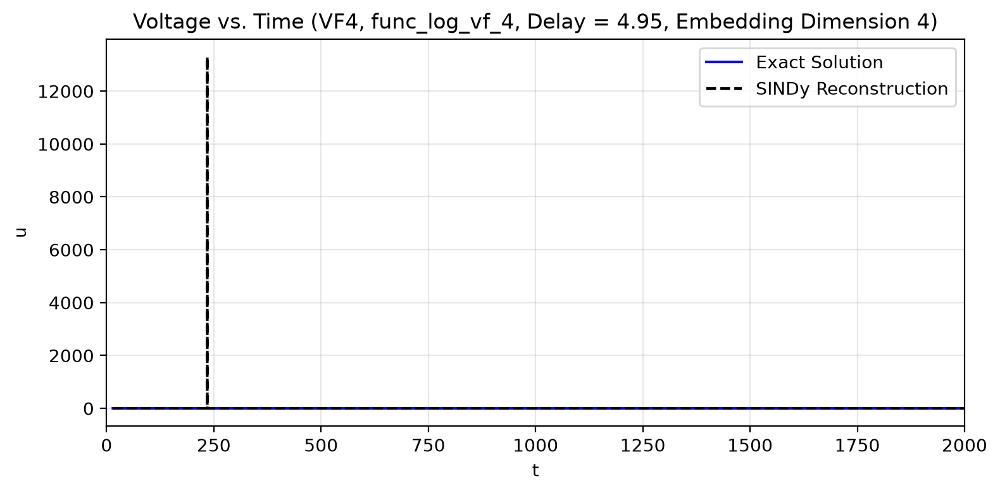


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 5
(u(t-0))' = -0.190 u(t-0) +  0.799 u(t-0)^2 + -0.633 u(t-0)^3 + -0.062 u(t-99) +  0.028 u(t-99)^2 + -0.135 u(t-198)^2 +  0.194 u(t-198)^3 +  0.011 u(t-297) +  0.040 u(t-297)^2 + -0.008 u(t-396) +  0.005 u(t-396)^2 + -0.005 u(t-396)^3 +  0.017 u(t-0)*u(t-99) + -0.078 u(t-0)*u(t-297) + -0.020 u(t-0)*u(t-396) +  0.921 f_td(t)
(u(t-99))' =  0.441 u(t-0) + -1.385 u(t-0)^2 +  1.460 u(t-0)^3 + -0.190 u(t-99)^2 + -0.527 u(t-99)^3 + -0.945 u(t-198) +  1.599 u(t-198)^2 + -1.383 u(t-198)^3 +  0.456 u(t-297) + -0.001 u(t-297)^2 + -0.079 u(t-396) + -0.111 u(t-396)^2 +  0.034 u(t-396)^3 +  0.267 u(t-0)*u(t-99) +  0.533 u(t-0)*u(t-198) + -0.456 u(t-0)*u(t-297) +  0.248 u(t-0)*u(t-396) + -0.342 f_td(t)
(u(t-198))' =  0.001 u(t-0) +  0.223 u(t-0)^2 + -0.390 u(t-0)^3 +  0.334 u(t-99) + -0.635 u(t-99)^2 +  1.564 u(t-99)^3 +  0.094 u(t-198) + -0.203 u(t-198)^2 + -0.494 u(t-198)^3 + 

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 2.88672e+00


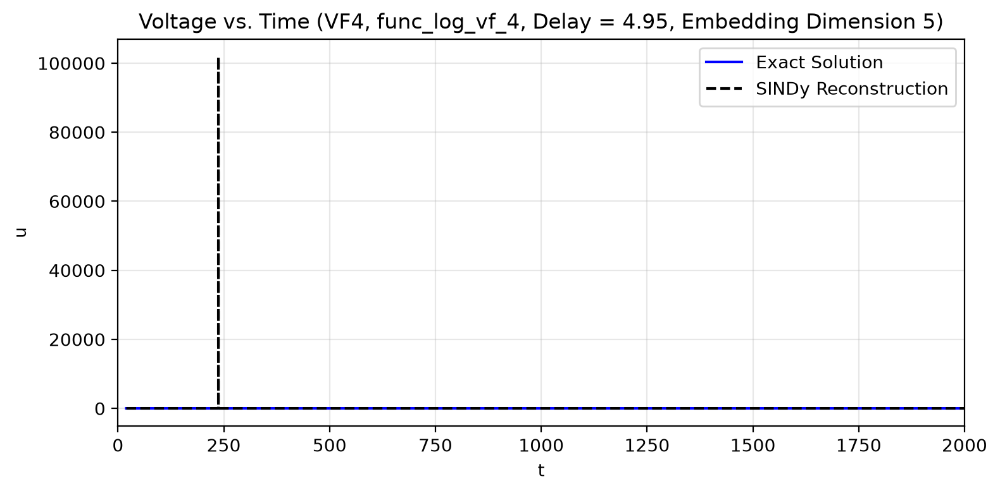


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 6
(u(t-0))' = -0.170 u(t-0) +  0.788 u(t-0)^2 + -0.670 u(t-0)^3 + -0.139 u(t-99) +  0.021 u(t-99)^2 +  0.113 u(t-198) + -0.140 u(t-198)^2 +  0.226 u(t-198)^3 + -0.072 u(t-297) +  0.020 u(t-297)^2 +  0.021 u(t-396) +  0.019 u(t-396)^2 + -0.004 u(t-495) +  0.148 u(t-0)*u(t-99) + -0.167 u(t-0)*u(t-198) +  0.040 u(t-0)*u(t-297) + -0.065 u(t-0)*u(t-396) + -0.002 u(t-0)*u(t-495) +  0.899 f_td(t)
(u(t-99))' =  0.405 u(t-0) + -1.295 u(t-0)^2 +  1.395 u(t-0)^3 + -0.313 u(t-99)^2 + -0.509 u(t-99)^3 + -0.606 u(t-198) +  1.252 u(t-198)^2 + -1.097 u(t-198)^3 +  0.175 u(t-297) + -0.093 u(t-297)^2 +  0.049 u(t-396) + -0.014 u(t-396)^2 + -0.024 u(t-495) + -0.029 u(t-495)^2 +  0.346 u(t-0)*u(t-99) +  0.250 u(t-0)*u(t-198) +  0.023 u(t-0)*u(t-396) +  0.055 u(t-0)*u(t-495) + -0.313 f_td(t)
(u(t-198))' =  0.021 u(t-0) +  0.093 u(t-0)^2 + -0.254 u(t-0)^3 +  0.607 u(t-99) + -1.361 u(t-9

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


Takens reconstruction MAE (u): 7.34702e-01


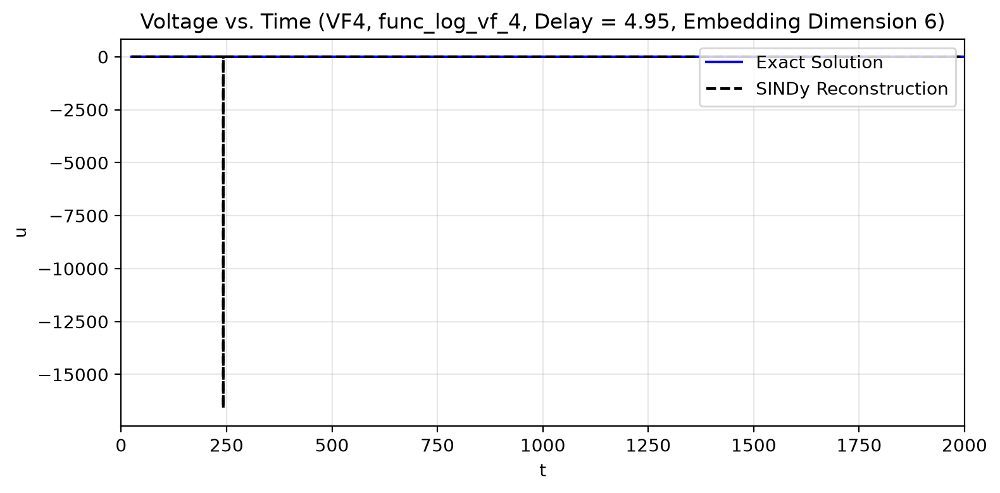


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 7
(u(t-0))' = -0.170 u(t-0) +  0.786 u(t-0)^2 + -0.667 u(t-0)^3 + -0.142 u(t-99) +  0.024 u(t-99)^2 +  0.107 u(t-198) + -0.111 u(t-198)^2 +  0.191 u(t-198)^3 + -0.077 u(t-297) +  0.020 u(t-297)^2 +  0.023 u(t-396) +  0.026 u(t-396)^2 + -0.011 u(t-495) +  0.007 u(t-495)^2 +  0.003 u(t-594) +  0.150 u(t-0)*u(t-99) + -0.168 u(t-0)*u(t-198) +  0.050 u(t-0)*u(t-297) + -0.070 u(t-0)*u(t-396) +  0.002 u(t-0)*u(t-495) + -0.009 u(t-0)*u(t-594) +  0.899 f_td(t)
(u(t-99))' =  0.423 u(t-0) + -1.374 u(t-0)^2 +  1.485 u(t-0)^3 + -0.312 u(t-99)^2 + -0.484 u(t-99)^3 + -0.635 u(t-198) +  1.258 u(t-198)^2 + -1.053 u(t-198)^3 +  0.094 u(t-297) +  0.178 u(t-297)^2 + -0.301 u(t-297)^3 +  0.107 u(t-396) + -0.016 u(t-396)^2 + -0.064 u(t-495) + -0.021 u(t-495)^2 +  0.022 u(t-594) + -0.021 u(t-594)^2 +  0.326 u(t-0)*u(t-99) +  0.258 u(t-0)*u(t-198) + -0.023 u(t-0)*u(t-396) +  0.119 u(t-0)*

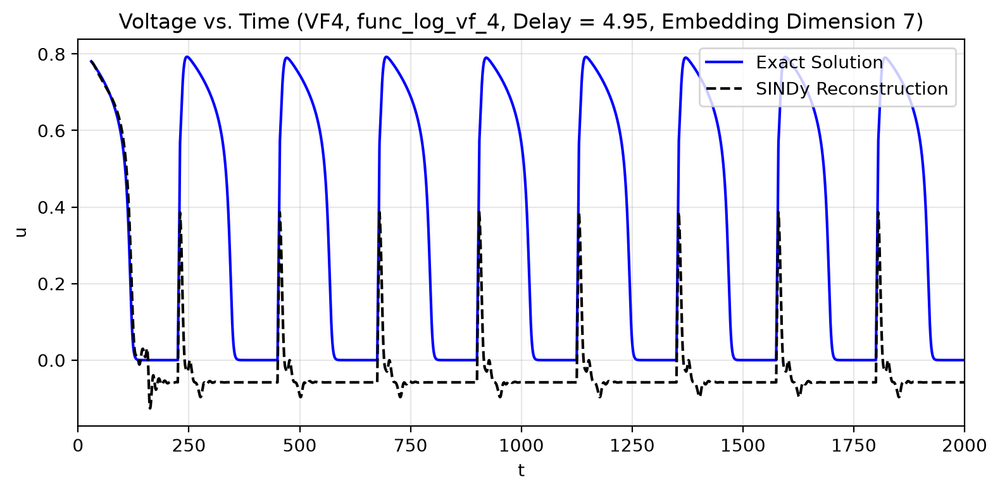


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 8
(u(t-0))' = -0.150 u(t-0) +  0.706 u(t-0)^2 + -0.581 u(t-0)^3 + -0.159 u(t-99) +  0.041 u(t-99)^2 +  0.045 u(t-198) +  0.058 u(t-198)^2 + -0.042 u(t-297) +  0.023 u(t-297)^2 +  0.002 u(t-396) +  0.019 u(t-396)^2 + -0.009 u(t-495) +  0.018 u(t-495)^2 +  0.008 u(t-594)^2 +  0.153 u(t-0)*u(t-99) + -0.148 u(t-0)*u(t-198) +  0.021 u(t-0)*u(t-297) + -0.024 u(t-0)*u(t-396) + -0.010 u(t-0)*u(t-495) + -0.012 u(t-0)*u(t-594) + -0.008 u(t-0)*u(t-693) +  0.891 f_td(t)
(u(t-99))' =  0.396 u(t-0) + -1.303 u(t-0)^2 +  1.446 u(t-0)^3 + -0.227 u(t-99)^2 + -0.545 u(t-99)^3 + -0.790 u(t-198) +  1.634 u(t-198)^2 + -1.488 u(t-198)^3 +  0.084 u(t-297) +  0.399 u(t-297)^2 + -0.583 u(t-297)^3 +  0.196 u(t-396) + -0.114 u(t-396)^2 +  0.112 u(t-495) + -0.758 u(t-495)^2 +  0.820 u(t-495)^3 +  0.025 u(t-594) + -0.132 u(t-594)^2 +  0.132 u(t-594)^3 + -0.014 u(t-693) + -0.008 u(t-693)^2 +  0.

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


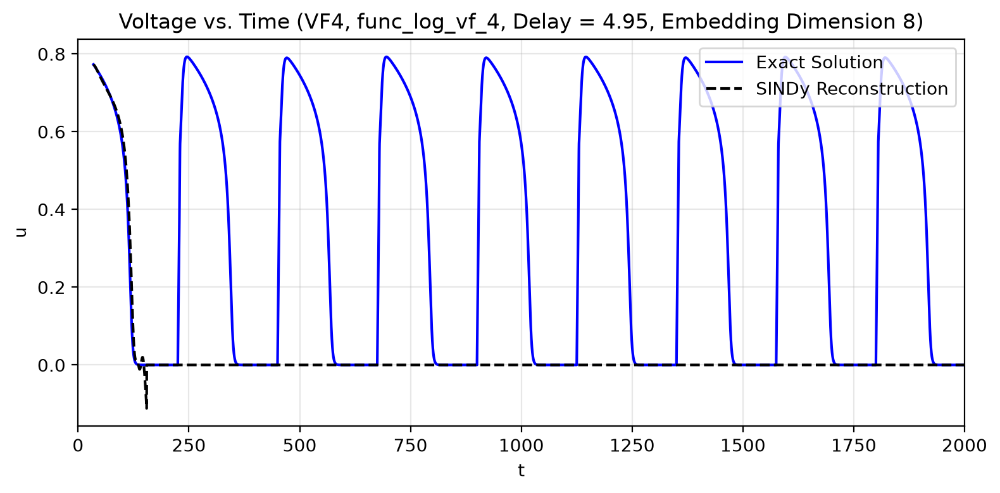


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 9
(u(t-0))' = -0.150 u(t-0) +  0.707 u(t-0)^2 + -0.581 u(t-0)^3 + -0.158 u(t-99) +  0.041 u(t-99)^2 +  0.045 u(t-198) +  0.057 u(t-198)^2 + -0.042 u(t-297) +  0.023 u(t-297)^2 +  0.002 u(t-396) +  0.019 u(t-396)^2 + -0.009 u(t-495) +  0.018 u(t-495)^2 +  0.009 u(t-594)^2 +  0.153 u(t-0)*u(t-99) + -0.148 u(t-0)*u(t-198) +  0.021 u(t-0)*u(t-297) + -0.024 u(t-0)*u(t-396) + -0.009 u(t-0)*u(t-495) + -0.013 u(t-0)*u(t-594) + -0.008 u(t-0)*u(t-693) +  0.891 f_td(t)
(u(t-99))' =  0.382 u(t-0) + -1.253 u(t-0)^2 +  1.400 u(t-0)^3 + -0.173 u(t-99)^2 + -0.604 u(t-99)^3 + -0.830 u(t-198) +  1.722 u(t-198)^2 + -1.602 u(t-198)^3 +  0.082 u(t-297) +  0.492 u(t-297)^2 + -0.709 u(t-297)^3 +  0.163 u(t-396) + -0.127 u(t-396)^2 +  0.159 u(t-495) + -0.795 u(t-495)^2 +  0.848 u(t-495)^3 + -0.278 u(t-594)^2 +  0.341 u(t-594)^3 +  0.001 u(t-693)^2 +  0.056 u(t-693)^3 + -0.005 u(t-792) +  

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\_core.py:646: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(rhs, x0, t, tfirst=True, **integrator_kws)


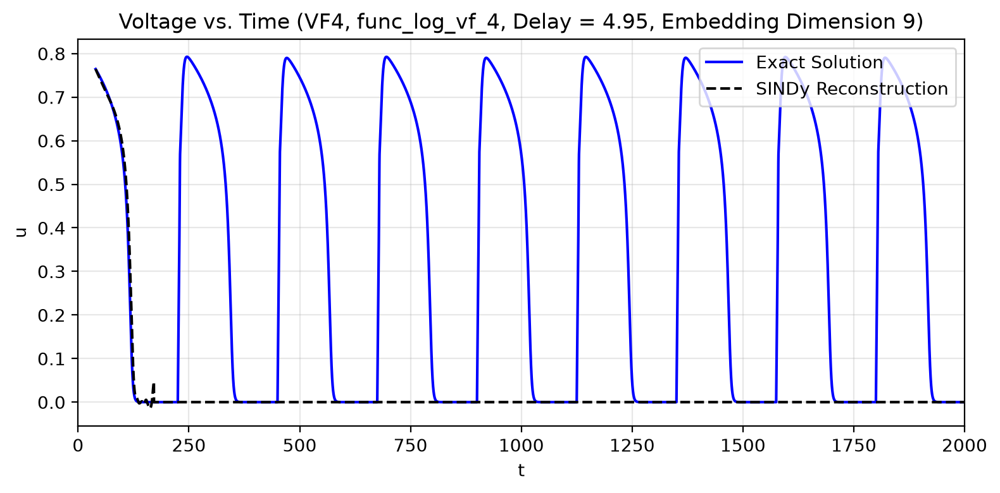

In [ ]:
takens_td_models_vf4 = []
n_embed_range = range(2,10)

# Test fit with fit_takens() method, which uses delay embeddings to reconstruct the dynamics, specifying the number of embedding
# dimensions with n_embed.
print(f'----------Fitting with function: {func_log_vf_4.__name__}----------')
for i in n_embed_range:
    cur_gen_library_tk_vf4 = GenLibraryFit(
            func_log_vf_4,
            func_log_vf_4,
            model_variant='vf4',
            t_range=np.arange(0, 2000, 0.05),
            ics=x_0_vf_4,
            color='blue'
        )
    cur_gen_library_tk_vf4.fit_takens(is_cubic=True, n_embed=i)
    cur_gen_library_tk_vf4.reconstruct_and_plot_takens(end_time=2000)
    
    takens_td_models_vf4.append(cur_gen_library_tk_vf4)

Test embedding reconstruction on VF7:

----------Fitting with function: func_log_vf_7----------

----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 2
(u(t-0))' =  0.050 u(t-0) +  0.263 u(t-0)^2 + -0.212 u(t-0)^3 + -0.144 u(t-99) + -0.013 u(t-99)^2 +  0.102 u(t-99)^3 + -0.048 u(t-0)*u(t-99) +  0.954 f_td(t)
(u(t-99))' =  0.323 u(t-0) + -0.796 u(t-0)^2 +  0.665 u(t-0)^3 + -0.384 u(t-99) +  0.710 u(t-99)^2 + -0.768 u(t-99)^3 +  0.251 u(t-0)*u(t-99) + -0.320 f_td(t)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x0*x1', '1', 'f_td(x2)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1], [0, 1], [2]]
Takens reconstruction MAE (u): 9.67693e-02


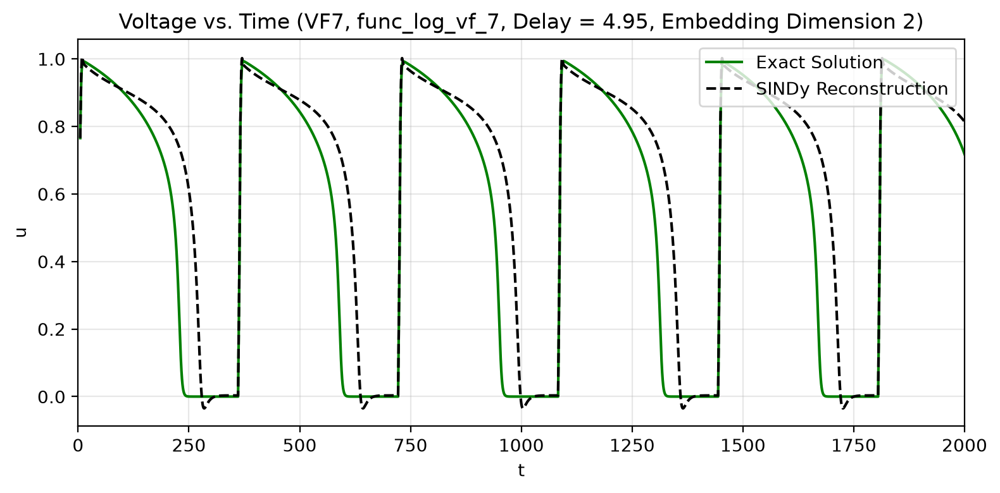


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 3
(u(t-0))' =  0.057 u(t-0) +  0.499 u(t-0)^2 + -0.516 u(t-0)^3 + -0.158 u(t-99) + -0.479 u(t-99)^2 +  0.486 u(t-99)^3 + -0.014 u(t-198) +  0.268 u(t-198)^2 + -0.097 u(t-198)^3 +  0.192 u(t-0)*u(t-99) + -0.242 u(t-0)*u(t-198) +  0.850 f_td(t)
(u(t-99))' =  0.400 u(t-0) + -1.139 u(t-0)^2 +  0.980 u(t-0)^3 + -0.521 u(t-99) +  1.132 u(t-99)^2 + -1.109 u(t-99)^3 +  0.032 u(t-198) + -0.046 u(t-198)^2 + -0.017 u(t-198)^3 +  0.196 u(t-0)*u(t-99) +  0.095 u(t-0)*u(t-198) + -0.311 f_td(t)
(u(t-198))' = -0.005 u(t-0) +  0.047 u(t-0)^2 + -0.065 u(t-0)^3 +  0.350 u(t-99) + -0.646 u(t-99)^2 +  0.750 u(t-99)^3 + -0.411 u(t-198) +  0.825 u(t-198)^2 + -0.784 u(t-198)^3 + -0.183 u(t-0)*u(t-99) +  0.124 u(t-0)*u(t-198)
(t)' =  1.000 1
['x0', 'x0^2', 'x0^3', 'x1', 'x1^2', 'x1^3', 'x2', 'x2^2', 'x2^3', 'x0*x1', 'x0*x2', '1', 'f_td(x3)']
inputs_per_libary:  [[0], [0], [0], [1], [1], [1

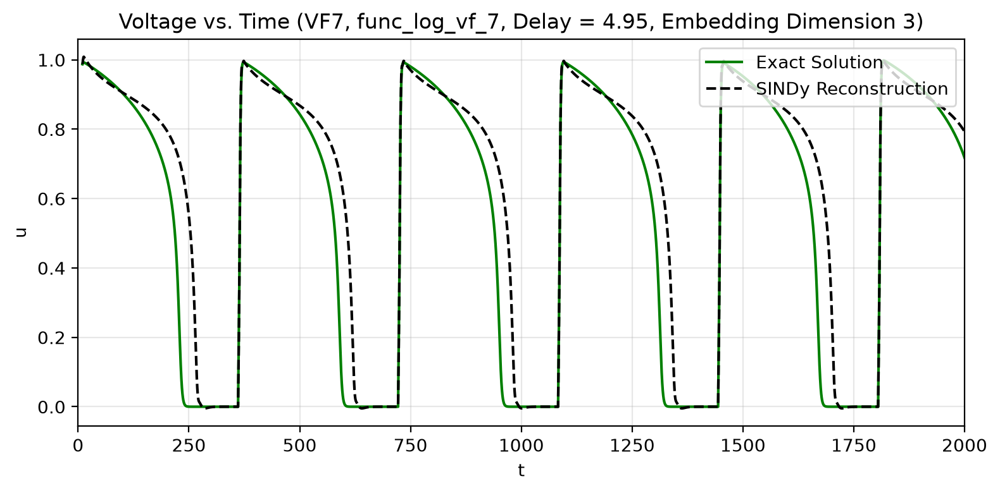


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 4
(u(t-0))' = -0.003 u(t-0) +  0.666 u(t-0)^2 + -0.632 u(t-0)^3 + -0.085 u(t-99) + -0.396 u(t-99)^2 +  0.397 u(t-99)^3 +  0.007 u(t-198) + -0.040 u(t-198)^2 +  0.155 u(t-198)^3 + -0.021 u(t-297) +  0.088 u(t-297)^2 + -0.022 u(t-297)^3 +  0.116 u(t-0)*u(t-99) + -0.150 u(t-0)*u(t-198) + -0.086 u(t-0)*u(t-297) +  0.883 f_td(t)
(u(t-99))' =  0.203 u(t-0) + -0.555 u(t-0)^2 +  0.501 u(t-0)^3 + -0.002 u(t-99)^2 + -0.306 u(t-99)^3 + -0.308 u(t-198) +  0.392 u(t-198)^2 + -0.254 u(t-198)^3 +  0.079 u(t-297) + -0.052 u(t-297)^2 +  0.195 u(t-0)*u(t-99) +  0.111 u(t-0)*u(t-198) + -0.187 f_td(t)
(u(t-198))' =  0.019 u(t-0) + -0.009 u(t-0)^2 + -0.047 u(t-0)^3 +  0.464 u(t-99) + -1.013 u(t-99)^2 +  1.026 u(t-99)^3 + -0.620 u(t-198) +  1.143 u(t-198)^2 + -1.025 u(t-198)^3 +  0.024 u(t-297) +  0.152 u(t-297)^2 + -0.112 u(t-297)^3 + -0.161 u(t-0)*u(t-99) +  0.193 u(t-0)*u(t-198) + -0

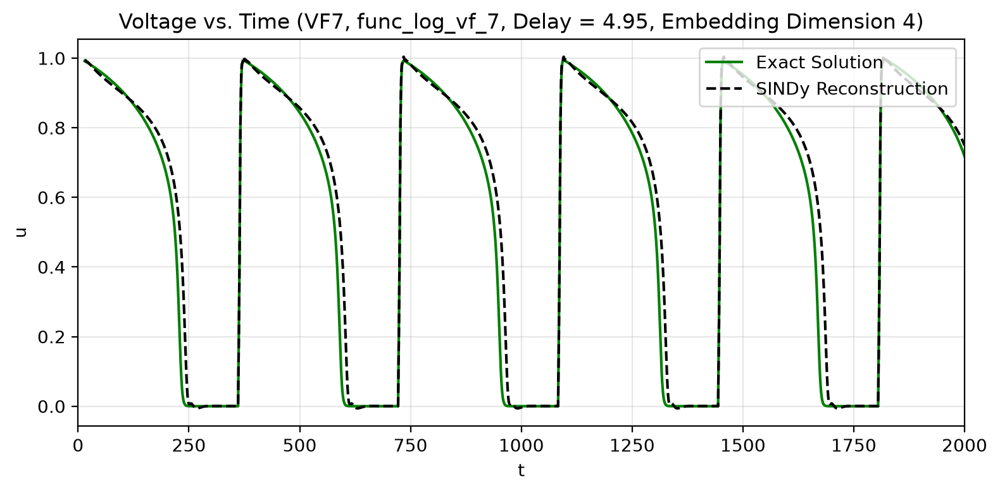


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 5
(u(t-0))' = -0.063 u(t-0) +  0.833 u(t-0)^2 + -0.762 u(t-0)^3 +  0.102 u(t-99) + -0.619 u(t-99)^2 +  0.554 u(t-99)^3 + -0.253 u(t-198) +  0.192 u(t-198)^2 +  0.145 u(t-297) + -0.040 u(t-297)^2 +  0.093 u(t-297)^3 + -0.042 u(t-396) +  0.010 u(t-396)^2 +  0.013 u(t-396)^3 +  0.038 u(t-0)*u(t-99) + -0.205 u(t-0)*u(t-297) + -0.005 u(t-0)*u(t-396) +  0.922 f_td(t)
(u(t-99))' =  0.203 u(t-0) + -0.553 u(t-0)^2 +  0.499 u(t-0)^3 +  0.007 u(t-99)^2 + -0.311 u(t-99)^3 + -0.304 u(t-198) +  0.381 u(t-198)^2 + -0.240 u(t-198)^3 +  0.077 u(t-297) + -0.057 u(t-297)^2 +  0.004 u(t-396) + -0.004 u(t-396)^2 +  0.190 u(t-0)*u(t-99) +  0.106 u(t-0)*u(t-198) +  0.005 u(t-0)*u(t-396) + -0.188 f_td(t)
(u(t-198))' =  0.015 u(t-0) +  0.019 u(t-0)^2 + -0.078 u(t-0)^3 +  0.509 u(t-99) + -1.055 u(t-99)^2 +  1.039 u(t-99)^3 + -0.639 u(t-198) +  1.019 u(t-198)^2 + -0.908 u(t-198)^3 + -0.043 u

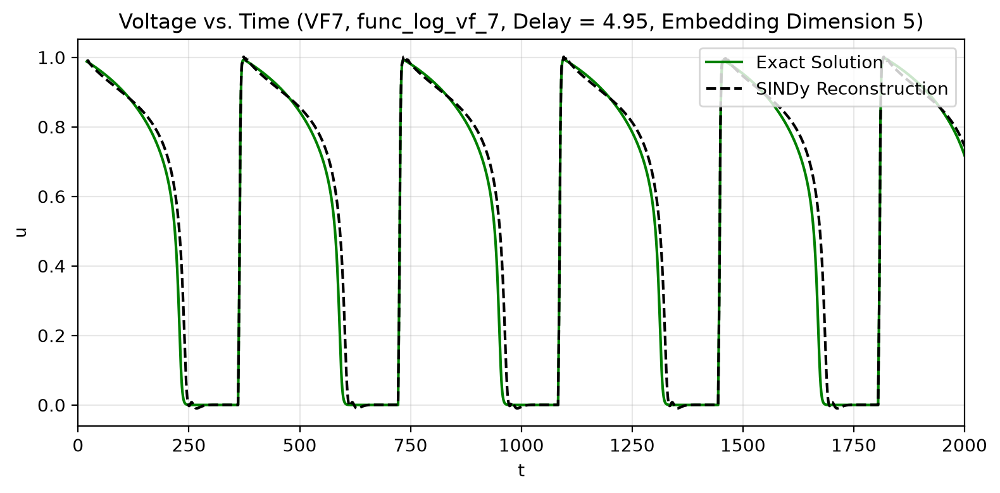


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 6
(u(t-0))' = -0.073 u(t-0) +  0.875 u(t-0)^2 + -0.789 u(t-0)^3 + -0.003 u(t-99) + -0.321 u(t-99)^2 +  0.305 u(t-99)^3 + -0.139 u(t-198) +  0.096 u(t-198)^2 +  0.248 u(t-297) + -0.231 u(t-297)^2 +  0.209 u(t-297)^3 + -0.146 u(t-396) + -0.247 u(t-396)^2 +  0.280 u(t-396)^3 + -0.005 u(t-495) +  0.221 u(t-495)^2 + -0.092 u(t-495)^3 +  0.052 u(t-0)*u(t-99) + -0.208 u(t-0)*u(t-297) +  0.141 u(t-0)*u(t-396) + -0.185 u(t-0)*u(t-495) +  0.915 f_td(t)
(u(t-99))' =  0.400 u(t-0) + -1.170 u(t-0)^2 +  1.026 u(t-0)^3 + -0.609 u(t-99) +  1.206 u(t-99)^2 + -1.104 u(t-99)^3 + -0.078 u(t-198) +  0.536 u(t-198)^2 + -0.506 u(t-198)^3 +  0.426 u(t-297) + -0.793 u(t-297)^2 +  0.498 u(t-297)^3 + -0.226 u(t-396) +  0.058 u(t-396)^2 +  0.053 u(t-495) + -0.003 u(t-495)^2 +  0.219 u(t-0)*u(t-99) + -0.006 u(t-0)*u(t-198) +  0.131 u(t-0)*u(t-396) + -0.054 u(t-0)*u(t-495) + -0.305 f_td(t)
(u(t

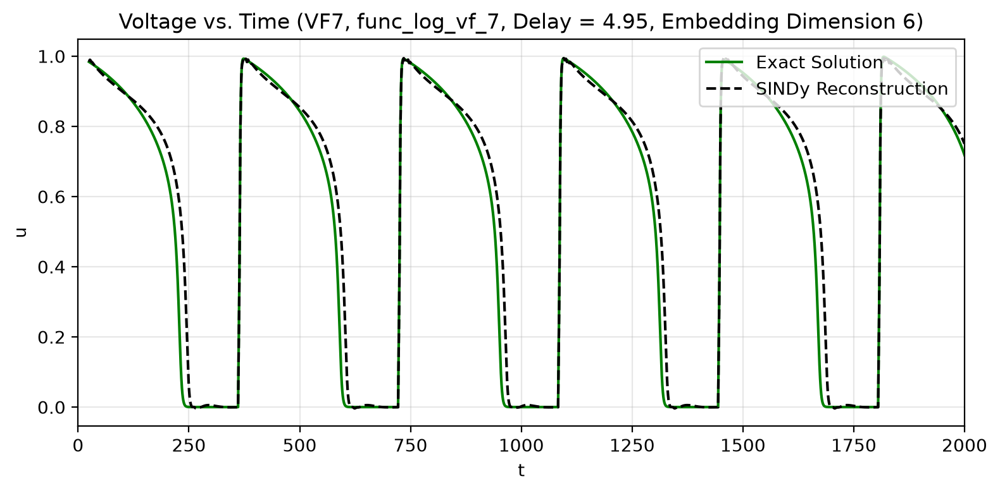


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 7
(u(t-0))' = -0.075 u(t-0) +  0.884 u(t-0)^2 + -0.800 u(t-0)^3 +  0.028 u(t-99) + -0.384 u(t-99)^2 +  0.349 u(t-99)^3 + -0.149 u(t-198) +  0.101 u(t-198)^2 +  0.231 u(t-297) + -0.352 u(t-297)^2 +  0.338 u(t-297)^3 + -0.238 u(t-396) +  0.147 u(t-396)^2 +  0.086 u(t-495) +  0.045 u(t-495)^2 + -0.018 u(t-594) +  0.048 u(t-0)*u(t-99) + -0.166 u(t-0)*u(t-297) +  0.051 u(t-0)*u(t-396) + -0.150 u(t-0)*u(t-495) +  0.013 u(t-0)*u(t-594) +  0.917 f_td(t)
(u(t-99))' =  0.409 u(t-0) + -1.211 u(t-0)^2 +  1.065 u(t-0)^3 + -0.660 u(t-99) +  1.270 u(t-99)^2 + -1.140 u(t-99)^3 + -0.060 u(t-198) +  0.607 u(t-198)^2 + -0.577 u(t-198)^3 +  0.496 u(t-297) + -0.918 u(t-297)^2 +  0.577 u(t-297)^3 + -0.321 u(t-396) +  0.074 u(t-396)^2 +  0.148 u(t-495) + -0.010 u(t-495)^2 + -0.033 u(t-594) + -0.013 u(t-594)^2 +  0.232 u(t-0)*u(t-99) + -0.040 u(t-0)*u(t-198) +  0.203 u(t-0)*u(t-396) + -0.

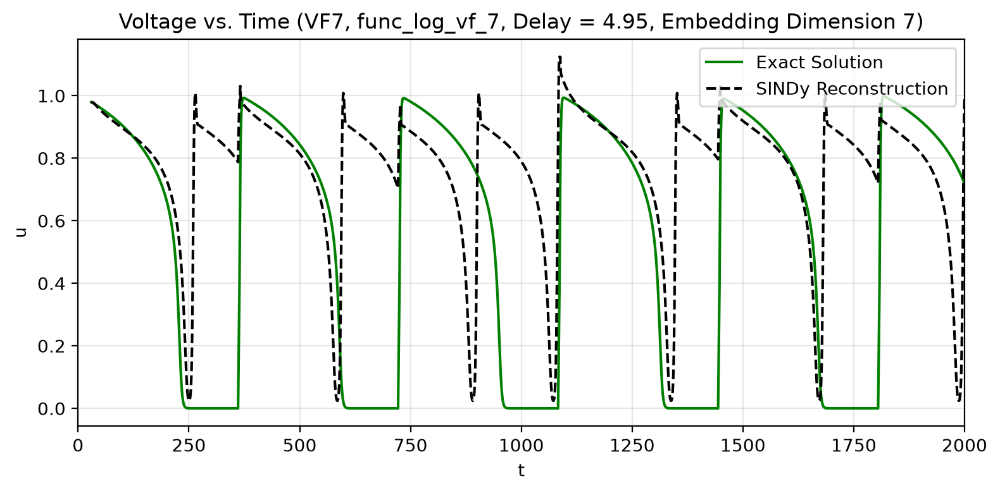


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 8
(u(t-0))' = -0.075 u(t-0) +  0.890 u(t-0)^2 + -0.808 u(t-0)^3 +  0.021 u(t-99) + -0.358 u(t-99)^2 +  0.322 u(t-99)^3 + -0.131 u(t-198) +  0.085 u(t-198)^2 +  0.236 u(t-297) + -0.383 u(t-297)^2 +  0.357 u(t-297)^3 + -0.270 u(t-396) +  0.154 u(t-396)^2 +  0.105 u(t-495) +  0.063 u(t-495)^2 + -0.052 u(t-594) +  0.024 u(t-594)^2 +  0.013 u(t-693) +  0.052 u(t-0)*u(t-99) + -0.154 u(t-0)*u(t-297) +  0.077 u(t-0)*u(t-396) + -0.184 u(t-0)*u(t-495) +  0.020 u(t-0)*u(t-594) + -0.017 u(t-0)*u(t-693) +  0.914 f_td(t)
(u(t-99))' =  0.441 u(t-0) + -1.319 u(t-0)^2 +  1.161 u(t-0)^3 + -0.823 u(t-99) +  1.474 u(t-99)^2 + -1.286 u(t-99)^3 +  0.165 u(t-198) +  0.575 u(t-198)^2 + -0.601 u(t-198)^3 +  0.353 u(t-297) + -1.070 u(t-297)^2 +  0.674 u(t-297)^3 + -0.219 u(t-396) +  0.098 u(t-396)^2 +  0.102 u(t-495) + -0.005 u(t-495)^2 + -0.019 u(t-594) + -0.024 u(t-594)^2 +  0.005 u(t-693

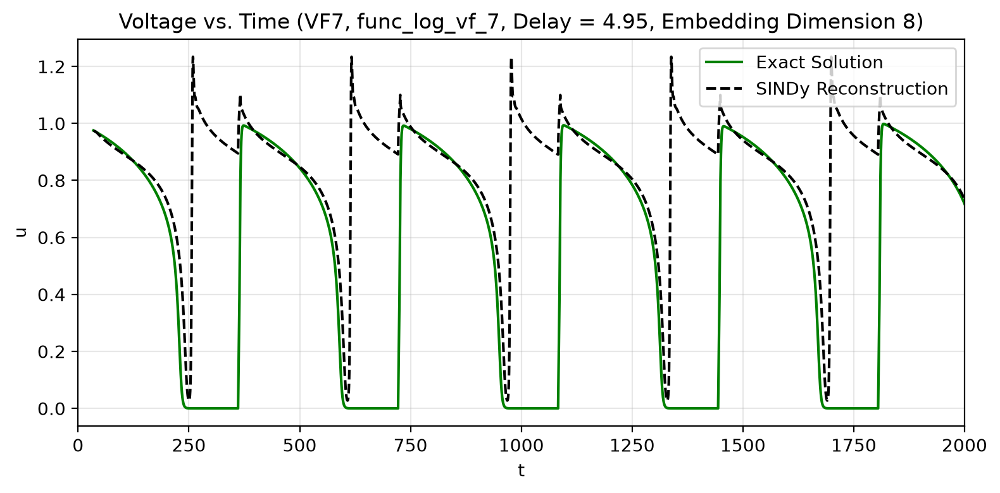


----------- SINDy with Takens Embedding -----------
Optimal time delay Ï„ = 4.9500 (delay_idx = 99)
Embedding dimension = 9
(u(t-0))' = -0.074 u(t-0) +  0.892 u(t-0)^2 + -0.811 u(t-0)^3 +  0.017 u(t-99) + -0.344 u(t-99)^2 +  0.308 u(t-99)^3 + -0.124 u(t-198) +  0.079 u(t-198)^2 +  0.236 u(t-297) + -0.388 u(t-297)^2 +  0.358 u(t-297)^3 + -0.280 u(t-396) +  0.152 u(t-396)^2 +  0.118 u(t-495) +  0.065 u(t-495)^2 + -0.087 u(t-594) +  0.035 u(t-594)^2 +  0.032 u(t-693) +  0.016 u(t-693)^2 + -0.007 u(t-792) +  0.054 u(t-0)*u(t-99) + -0.149 u(t-0)*u(t-297) +  0.090 u(t-0)*u(t-396) + -0.199 u(t-0)*u(t-495) +  0.048 u(t-0)*u(t-594) + -0.054 u(t-0)*u(t-693) +  0.004 u(t-0)*u(t-792) +  0.912 f_td(t)
(u(t-99))' =  0.442 u(t-0) + -1.327 u(t-0)^2 +  1.171 u(t-0)^3 + -0.830 u(t-99) +  1.478 u(t-99)^2 + -1.283 u(t-99)^3 +  0.158 u(t-198) +  0.591 u(t-198)^2 + -0.609 u(t-198)^3 +  0.362 u(t-297) + -1.068 u(t-297)^2 +  0.675 u(t-297)^3 + -0.234 u(t-396) +  0.101 u(t-396)^2 +  0.126 u(t-495) + -0.004 u(

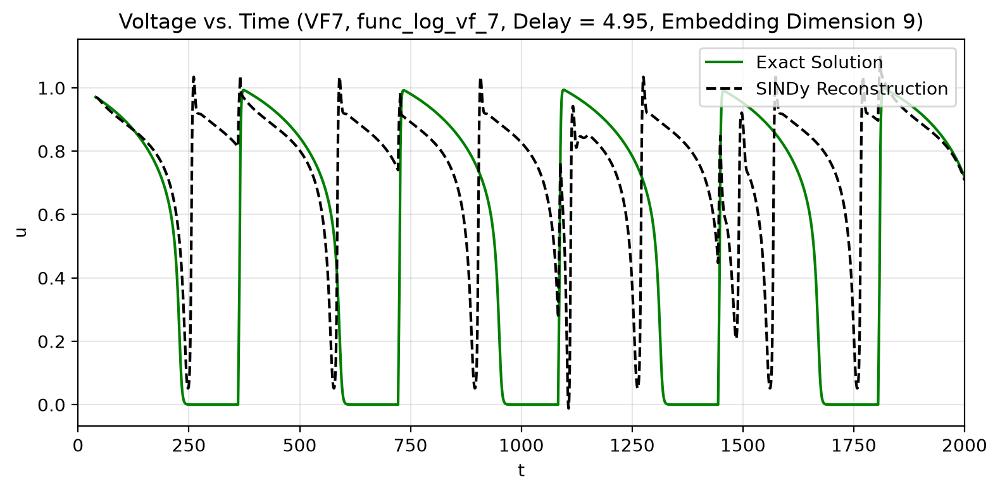

In [ ]:
takens_td_models_vf7 = []
n_embed_range = range(2,10)

# Test fit with fit_takens() method, which uses delay embeddings to reconstruct the dynamics, specifying the number of embedding
# dimensions with n_embed.
print(f'----------Fitting with function: {func_log_vf_7.__name__}----------')
for i in n_embed_range:
    cur_gen_library_tk_vf7 = GenLibraryFit(
                func_log_vf_7,
                func_log_vf_7,
                model_variant='vf7',
                t_range=np.arange(0, 2000, 0.05),
                ics=x_0_vf_7,
                color='green'
            )
    cur_gen_library_tk_vf7.fit_takens(is_cubic=True, n_embed=i)
    cur_gen_library_tk_vf7.reconstruct_and_plot_takens(end_time=2000)
    
    takens_td_models_vf7.append(cur_gen_library_tk_vf7)

### b.) Latent ODE Fit
Transform the system of 2 ODEs described by the VF-FHN variants to a single 2nd-order ODE in order to remove the need to fit the latent variable $v$.

----------Fitting with function: func_log----------
Differentiation method parameters:  {'save_smooth': True, 'smoother': <function savgol_filter at 0x000001D6BD160670>, 'smoother_kws': {'window_length': 5, 'polyorder': 3, 'axis': 0}}
Number of SINDy terms for u', v': (6, 8)
Number of exact terms for u', v': (1, 7)
Mean Absolute Error of coefficients: 1.01300e-01

SINDy coefficients:
(u)' = -0.00002 u +  0.00002 u^2 +  0.99993 u_dot + -0.00041 u*u_dot +  0.00064 u^2*u_dot +  0.00027 f_td(t)
(u_dot)' = -0.03270 u + -0.00615 u^2 +  0.04716 u^3 + -0.14744 u_dot +  1.46132 u*u_dot + -2.68642 u^2*u_dot + -0.00345 1 +  0.43521 f_td(t)
(t)' =  1.00000 1

Exact coefficients:
u' = 1.00000 u_dot
v' = -0.00600 u + 0.01100 u^2 + -0.01000 u^3 + -0.11000 u_dot + 2.20000 u*u_dot + -3.00000 u^2*u_dot + 0.01000 f_td


Mean Absolute Error between reconstruction and true values: 1.91533e-01





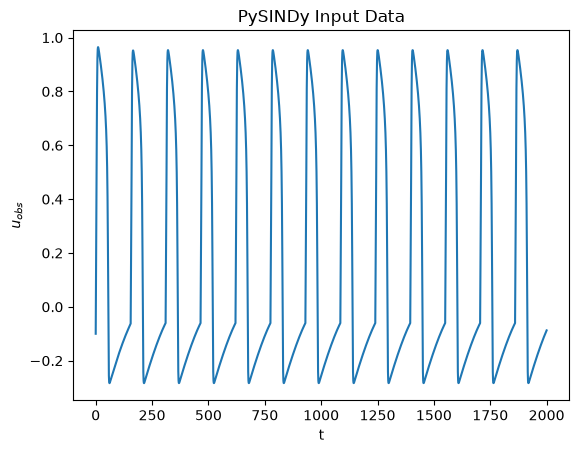

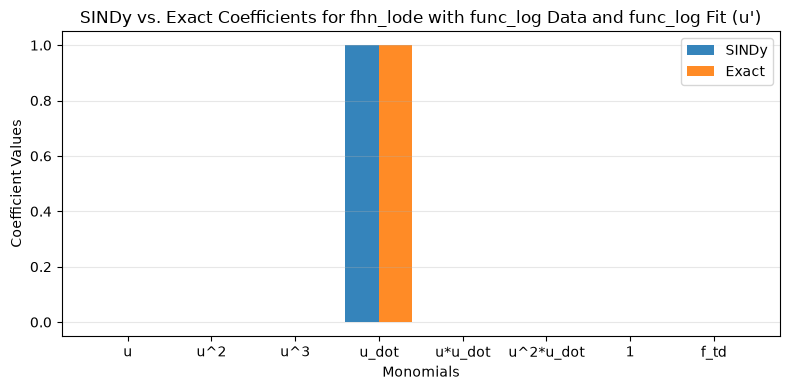

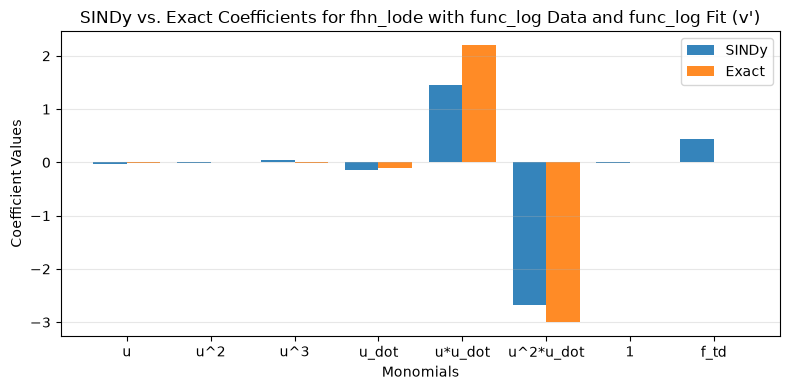

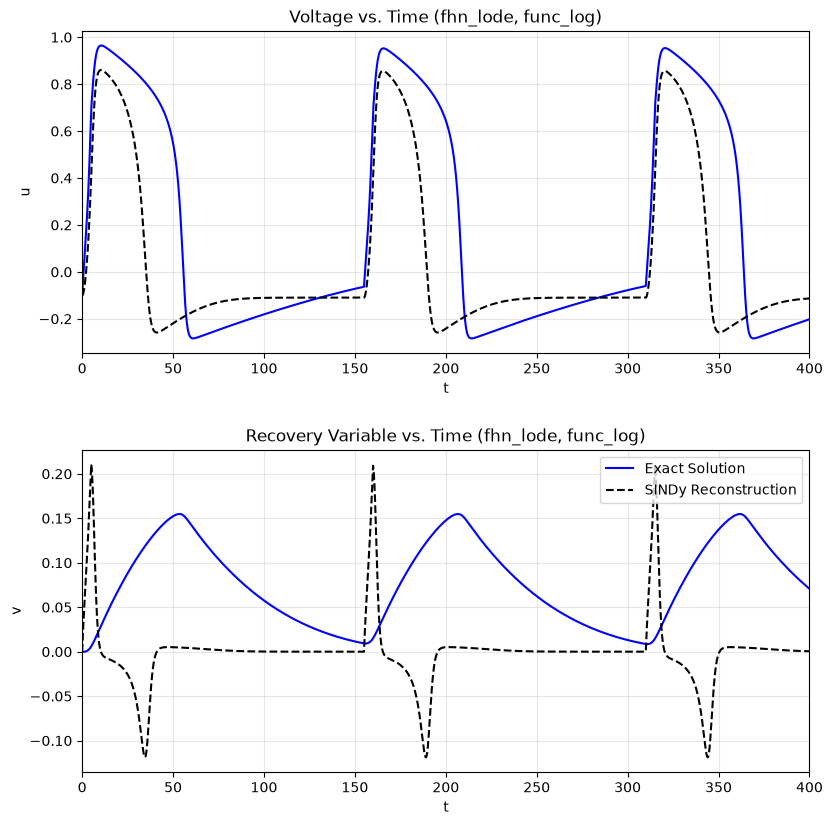

In [ ]:
latent_ODE_models = []

# TODO Modify math to convert L-ODE formulation for "cardiac" + "VF4" + "VF7" variants
# Test fit with same data and fitting non-autonomous terms.
print(f'----------Fitting with function: {func_log.__name__}----------')
cur_gen_library_lode = GenLibraryFit(func_log, func_log, model_variant='fhn_lode', ics=np.array([-0.1,0]), t_range=np.arange(0,2000,0.01), color='blue')
latent_ODE_models.append(cur_gen_library_lode.fit_latent_ode(is_weak=False))
print('\n\n')

----------Fitting with function: func_log----------
Differentiation method parameters:  {'save_smooth': True, 'smoother': <function savgol_filter at 0x000001D6BD160670>, 'smoother_kws': {'window_length': 5, 'polyorder': 3, 'axis': 0}}


c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\optimizers\stlsq.py:234: UserWarning: Sparsity parameter is too big (0.1) and eliminated all coefficients
  warnings.warn(


Number of SINDy terms for u', v': (1, 0)
Number of exact terms for u', v': (1, 6)
Mean Absolute Error of coefficients: 3.81214e-01

SINDy coefficients:
(u)' =  1.00000 u_dot
(u_dot)' =  0.00000
(t)' =  1.00000 1

Exact coefficients:
u' = 1.00000 u_dot
v' = -0.00600 u + 0.01100 u^2 + -0.01000 u^3 + -0.11000 u_dot + 2.20000 u*u_dot + -3.00000 u^2*u_dot


Mean Absolute Error between reconstruction and true values: 9.99443e-02





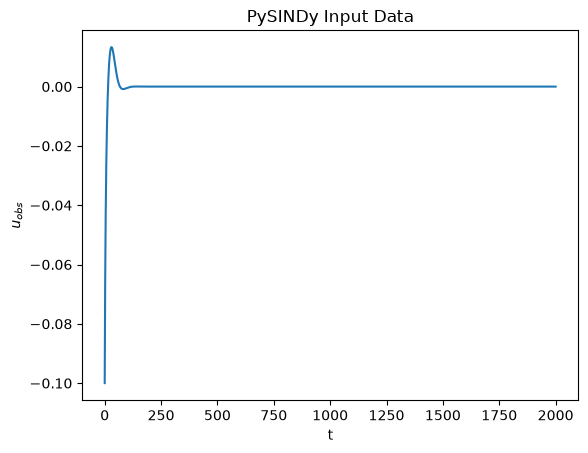

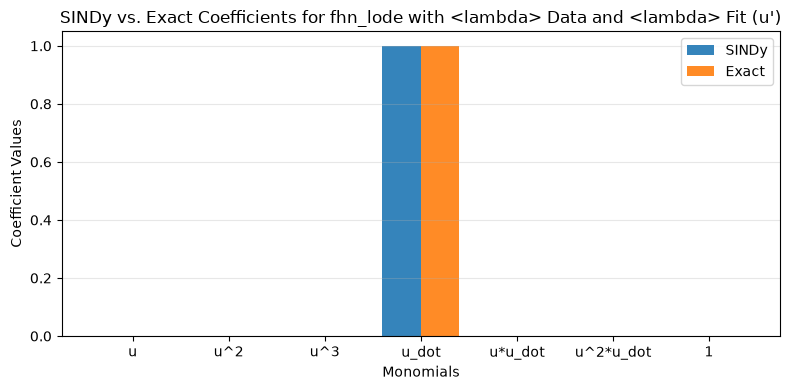

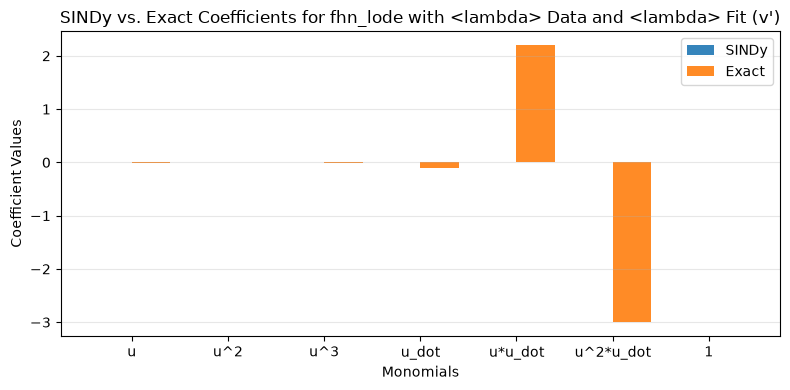

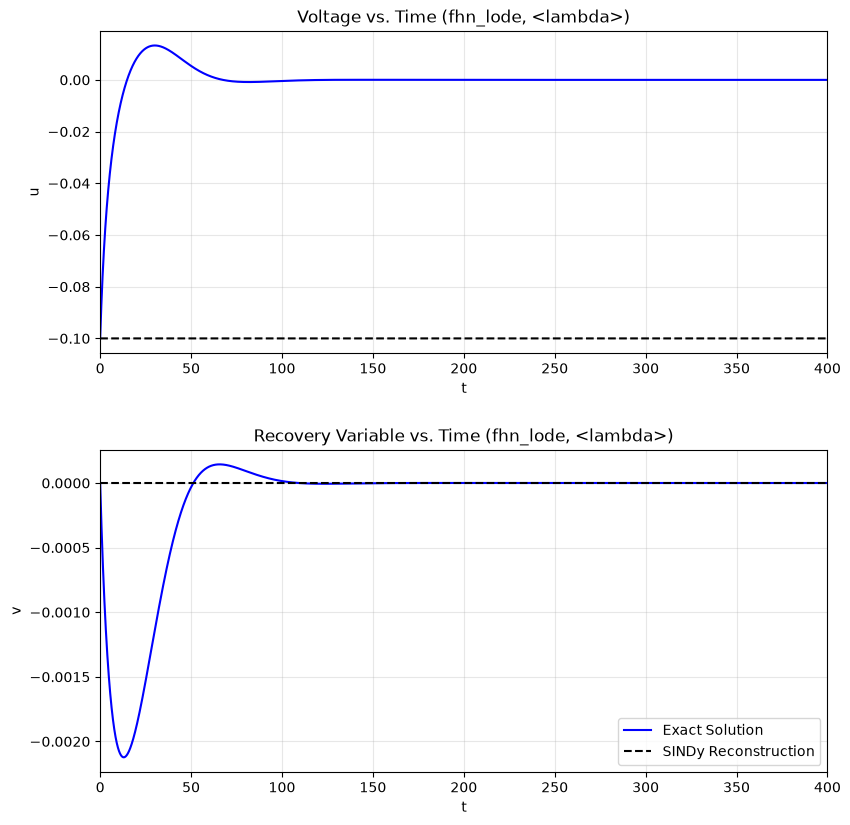

In [ ]:
latent_ODE_models_no_osc = []

# TODO Uninteresting behavior where system decays to 0 and stops there; need to find better parameters for this test.
# L-ODE fit w/out non-autonomous term to eliminate potential impact of I'(t)
print(f'----------Fitting with function: {func_log.__name__}----------')
cur_gen_library_lode_no_osc = GenLibraryFit(lambda t: 0, lambda t: 0, model_variant='fhn_lode', ics=np.array([-0.1,0]), t_range=np.arange(0,2000,0.01), color='blue')
latent_ODE_models_no_osc.append(cur_gen_library_lode_no_osc.fit_latent_ode(is_weak=False))
print('\n\n')

### c.) Weak Form of Latent ODE Fit
Since a lot of noise is introduced by taking 2nd-order derivatives, let's apply Weak SINDy to the L-ODE method above and compare the results.

----------Fitting with function: func_log----------
Differentiation method parameters:  {'save_smooth': True, 'smoother': <function savgol_filter at 0x000001D6BD160670>, 'smoother_kws': {'window_length': 5, 'polyorder': 3, 'axis': 0}}
Number of SINDy terms for u', v': (1, 2)
Number of exact terms for u', v': (1, 7)
Mean Absolute Error of coefficients: 3.34100e-01

SINDy coefficients:
(u)' =  1.00000 u_dot
(u_dot)' = -0.00164 u +  0.00023 1
(t)' =  1.00000 1

Exact coefficients:
u' = 1.00000 u_dot
v' = -0.00600 u + 0.01100 u^2 + -0.01000 u^3 + -0.11000 u_dot + 2.20000 u*u_dot + -3.00000 u^2*u_dot + 0.01000 f_td


c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\pysindy\utils\_axes.py:126: AxesWarning: 2 axes labeled for array with 1 axes
  warnings.warn(


IndexError: index 6790 is out of bounds for axis 0 with size 1

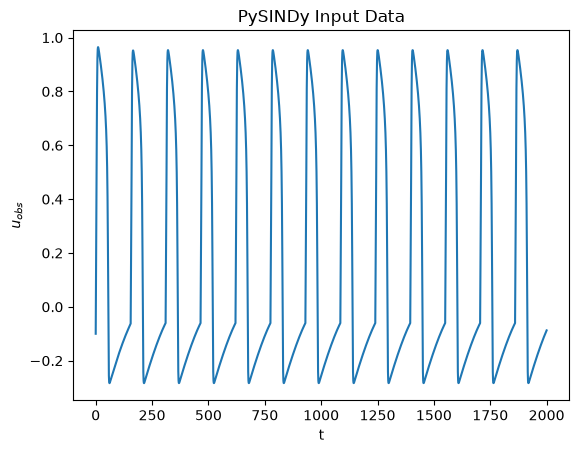

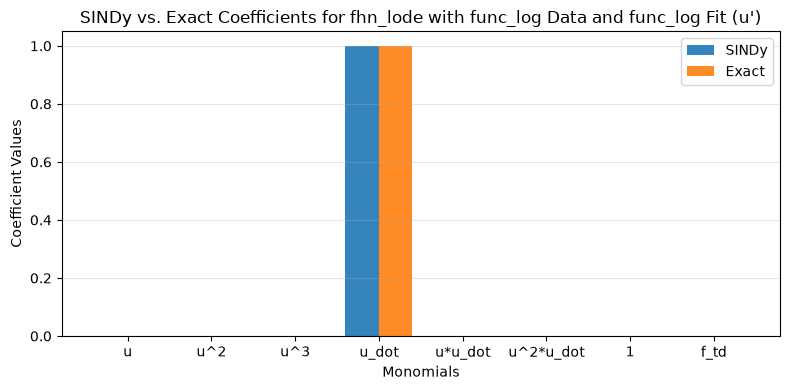

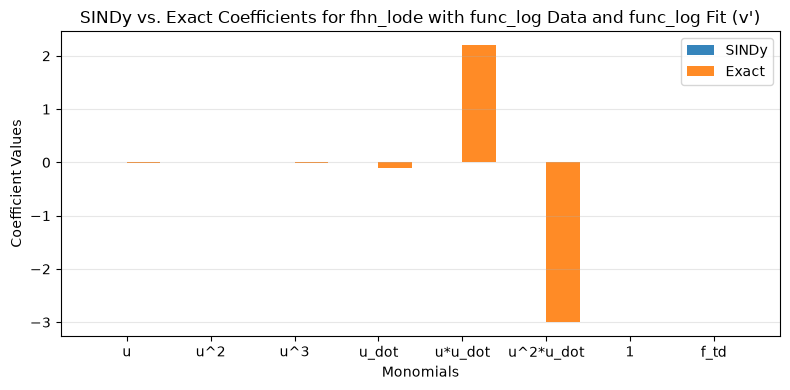

In [ ]:
latent_ODE_models_weak = []

# Test fit with same data and fitting non-autonomous terms.
# dt = 0.01
print(f'----------Fitting with function: {func_log.__name__}----------')
cur_gen_library_lode = GenLibraryFit(func_log, func_log, model_variant='fhn_lode', ics=np.array([-0.1,0]), t_range=np.arange(0,2000,0.01), color='blue')
latent_ODE_models_weak.append(cur_gen_library_lode.fit_latent_ode(is_weak=True))
print('\n\n')

# TODO Incorporate comparison from L-ODE paperâ€”can't generally use direct coefficient comparison, so try SMAPE instead.

# TODO Loop over ICs, dts, smoothing k to get best fit

In [ ]:
# dt = 0.0001
# latent_ODE_models_weak = []

# print(f"----------Fitting with function: {func_log.__name__}----------")
# cur_gen_library_lode = GenLibraryFit(func_log, func_log, model_variant="fhn_lode", ics=np.array([-0.1,0]), t_range=np.arange(0,2000,0.0001), color="blue")
# latent_ODE_models_weak.append(cur_gen_library_lode.fit_latent_ODE(is_weak=True))
# print('\n\n')

----------Fitting with function: func_log----------
Differentiation method parameters:  {'save_smooth': True, 'smoother': <function savgol_filter at 0x0000018C5138C460>, 'smoother_kws': {'window_length': 5, 'polyorder': 3, 'axis': 0}}
Number of SINDy terms for u', v': (1, 8)
Number of exact terms for u', v': (1, 7)
Mean Absolute Error of coefficients: 1.01509e-01

SINDy coefficients:
(u)' =  1.00000 u_dot +  0.00001 u^2*u_dot
(u_dot)' = -0.03288 u + -0.00594 u^2 +  0.04720 u^3 + -0.14813 u_dot +  1.45977 u*u_dot + -2.68696 u^2*u_dot + -0.00349 1 +  0.43822 f_td(t)
(t)' =  1.00000 1

Exact coefficients:
u' = 1.00000 u_dot
v' = -0.00600 u + 0.01100 u^2 + -0.01000 u^3 + -0.11000 u_dot + 2.20000 u*u_dot + -3.00000 u^2*u_dot + 0.01000 f_td


Mean Absolute Error between reconstruction and true values: 1.91364e-01





c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\IPython\core\events.py:100: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


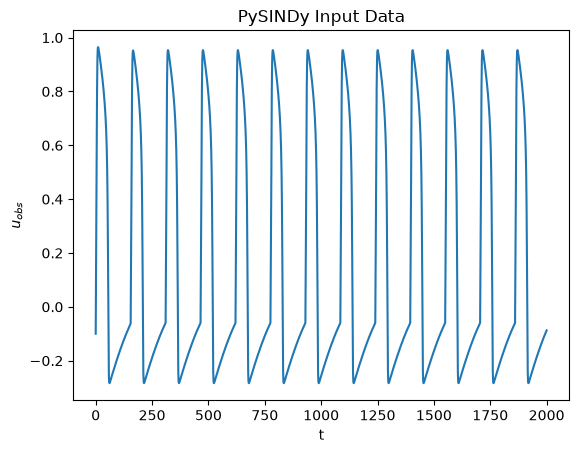

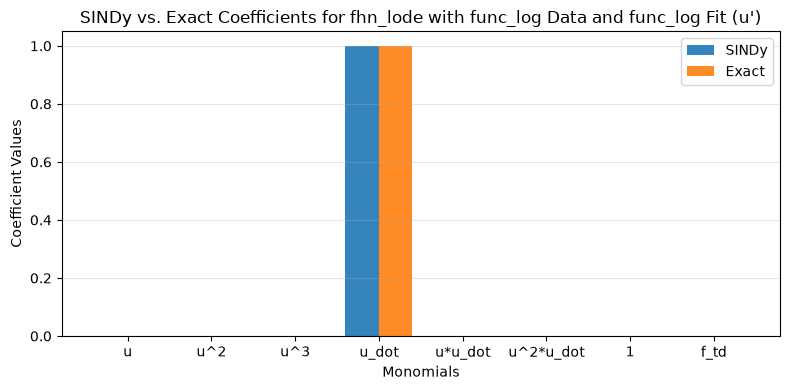

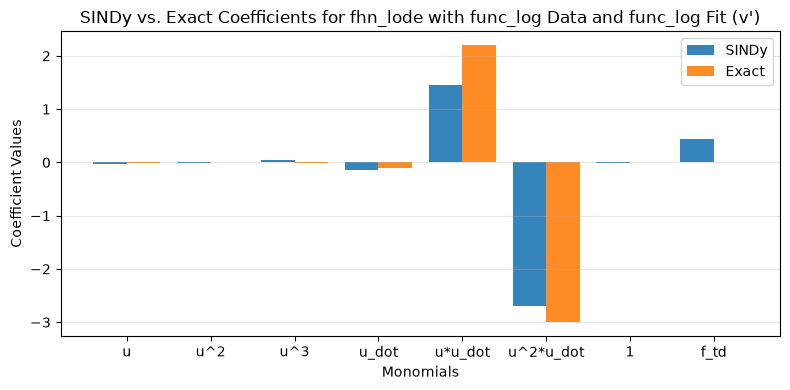

c:\Users\Cole\OneDrive\Documents\_Repos\SINDy-for-Cardiac-Electrophysiology\pysindy_new\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


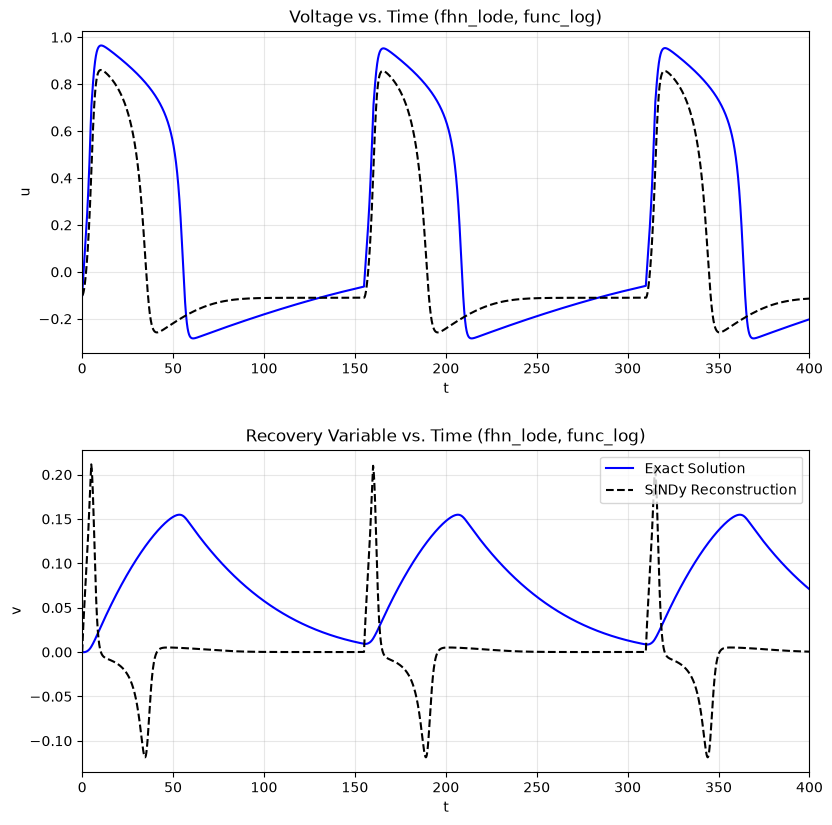

In [ ]:
# dt = 0.0001 (normal)
latent_ODE_models_weak = []

print(f'----------Fitting with function: {func_log.__name__}----------')
cur_gen_library_lode = GenLibraryFit(func_log, func_log, model_variant='fhn_lode', ics=np.array([-0.1,0]), t_range=np.arange(0,2000,0.0001), color='blue')
latent_ODE_models_weak.append(cur_gen_library_lode.fit_latent_ode(is_weak=False))
print('\n\n')